Replication 1/3
Replication 2/3
Replication 3/3


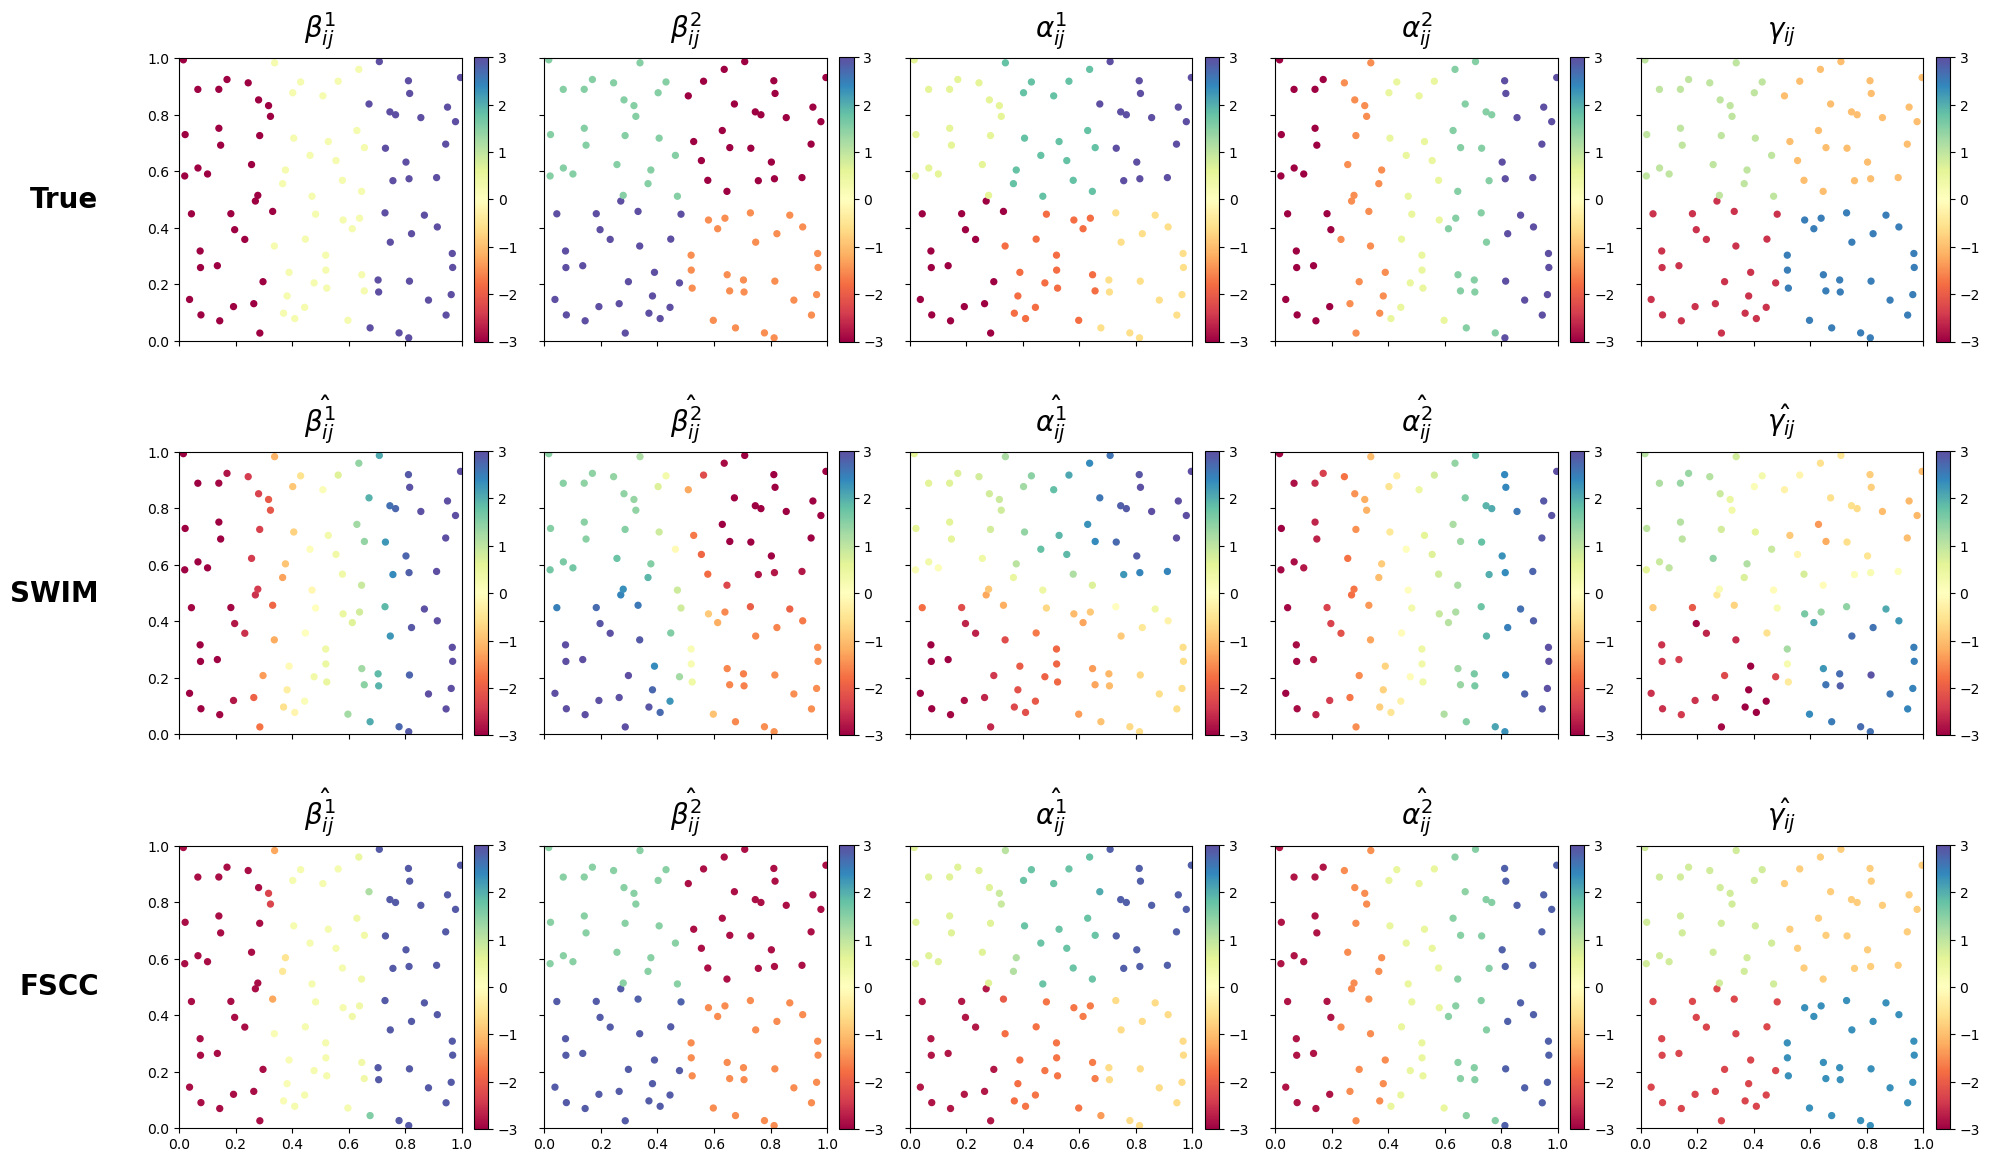


1. MODEL FIT: R2 AND MSE
Method                   R2                   MSE
   WLS -0.526959 ± 0.788097 32.351987 ± 16.979462
  SWIM  0.950135 ± 0.000229   1.053660 ± 0.012922
  FSCC  0.995837 ± 0.000110   0.087956 ± 0.001515

2. SPATIAL PARTITION RECOVERY: RAND INDEX
Method            RI_BETA1            RI_BETA2           RI_ALPHA1           RI_ALPHA2            RI_GAMMA
   WLS 0.327071 ± 0.000000 0.242424 ± 0.000000 0.158586 ± 0.000000 0.191919 ± 0.000000 0.242424 ± 0.000000
  SWIM 0.936835 ± 0.023337 0.887811 ± 0.012279 0.880000 ± 0.004056 0.944916 ± 0.007581 0.858316 ± 0.010759
  FSCC 0.964579 ± 0.015168 1.000000 ± 0.000000 0.961818 ± 0.000000 1.000000 ± 0.000000 1.000000 ± 0.000000

3. COEFFICIENT ESTIMATION ERROR: RMSE
Method          RMSE_BETA1          RMSE_BETA2         RMSE_ALPHA1         RMSE_ALPHA2          RMSE_GAMMA
   WLS 2.444371 ± 0.020862 2.403984 ± 0.034022 2.054943 ± 0.019361 2.140012 ± 0.011290 5.611881 ± 4.508102
  SWIM 0.667638 ± 0.007905 0.660975 ± 0.009497 0.5

In [7]:
import warnings
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree
import warnings
warnings.filterwarnings("ignore")
n, p, q = (100, 2, 2)
noise_std = 0.1
intercept_true = 1.0
GRID_NEIGHBORHOOD = 'rook'
sigma = 0.05
max_dist = 0.2
B = 3
lambda_grid = [0.075, 0.1, 0.125]
max_outer = 60
max_inner = 1000
outer_tol = 0.002
admm_abs_tol = 1e-05
admm_rel_tol = 0.0005
cg_rtol = 1e-08
cg_maxiter = 1500
admm_adapt_interval = 10
admm_balance_mu = 10.0
admm_rho_factor = 2.0
admm_rho_min = 1e-05
admm_rho_max = 100000.0
admm_over_relax = 1.5
df_rel_tol = 0.001
GAMMA_CLASS_RATIOS = (40.0, 4.0, 4.0 / 3.6)
GAMMA_BASE_SCALE = 1.0
K_SWIM = 100
SWIM_BW_FIXED = 0.105
grid_side = math.isqrt(n)
if grid_side * grid_side != n:
    raise ValueError(f'n={n} must be a perfect square for the 10x10 Rook grid design.')
grid_rows = np.repeat(np.arange(grid_side, dtype=np.int32), grid_side)
grid_cols = np.tile(np.arange(grid_side, dtype=np.int32), grid_side)
coord_rng = np.random.default_rng(42)
coords = np.column_stack([(grid_cols + coord_rng.random(n)) / grid_side, (grid_rows + coord_rng.random(n)) / grid_side]).astype(np.float64)
D_full = cdist(coords, coords).astype(np.float64)
D_PREDICTOR_SCALE = float(np.std(D_full))
if D_PREDICTOR_SCALE <= 1e-12:
    raise ValueError('Distance predictor has zero variance.')
D_model = D_full / D_PREDICTOR_SCALE
beta_piece_sets = [[-3, 0.25, 3], [3, -1.5, 1.5, -3]]
alpha_piece_sets = [[-3, -1.8, -0.6, 0.6, 1.8, 3], [-3, -1.5, 0.5, 1.5, 3]]
gamma_piece_set = [-2.5, 2.5, 1.0, -1.0]

def grid_shape_for_count(count):
    return {3: (1, 3), 4: (2, 2), 5: (1, 5), 6: (2, 3)}[count]

def fill_piecewise_origin(arr3d, coords_, values, feat_idx):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr3d[mask, :, feat_idx] = value

def fill_piecewise_2d(arr2d, coords_, values):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr2d[mask, :] = value
beta0 = np.zeros((n, n, p), dtype=np.float64)
alpha0 = np.zeros((n, n, q), dtype=np.float64)
gamma0 = np.zeros((n, n), dtype=np.float64)
for k in range(p):
    fill_piecewise_origin(beta0, coords, beta_piece_sets[k], k)
for m in range(q):
    fill_piecewise_origin(alpha0, coords, alpha_piece_sets[m], m)
fill_piecewise_2d(gamma0, coords, gamma_piece_set)
edge_u_list = []
edge_v_list = []
for r in range(grid_side):
    for c in range(grid_side):
        u = r * grid_side + c
        if c + 1 < grid_side:
            edge_u_list.append(u)
            edge_v_list.append(u + 1)
        if r + 1 < grid_side:
            edge_u_list.append(u)
            edge_v_list.append(u + grid_side)
edge_u = np.asarray(edge_u_list, dtype=np.int32)
edge_v = np.asarray(edge_v_list, dtype=np.int32)
edge_w = np.ones(len(edge_u), dtype=np.float64)
E = len(edge_u)
N = n * n
if E == 0:
    raise RuntimeError('No grid-neighbor edges were constructed.')
A_grid = sp.coo_matrix((np.ones(2 * E, dtype=np.float64), (np.concatenate([edge_u, edge_v]), np.concatenate([edge_v, edge_u]))), shape=(n, n)).tocsr()
A_grid.setdiag(0.0)
A_grid.eliminate_zeros()
if A_grid.nnz and (not np.all(A_grid.data == 1.0)):
    raise RuntimeError('Grid adjacency must be binary: every nonzero entry must equal 1.')
try:
    OUTPUT_DIR = Path(__file__).resolve().parent
except NameError:
    OUTPUT_DIR = Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
W_wls = np.exp(-0.5 * (D_full / sigma) ** 2)
np.fill_diagonal(W_wls, 0.0)
W_wls[D_full > max_dist] = 0.0
W_wls = W_wls / (W_wls.sum() / n + 1e-12)
fixed_origin = np.tile(np.arange(n, dtype=np.int32), E)
u1 = fixed_origin * n + np.repeat(edge_u, n)
v1 = fixed_origin * n + np.repeat(edge_v, n)
w1 = np.repeat(edge_w, n)
fixed_dest = np.tile(np.arange(n, dtype=np.int32), E)
u2 = np.repeat(edge_u, n) * n + fixed_dest
v2 = np.repeat(edge_v, n) * n + fixed_dest
w2 = np.repeat(edge_w, n)
M3 = 2 * E * E
u3 = np.empty(M3, dtype=np.int32)
v3 = np.empty(M3, dtype=np.int32)
mean_region_w = float(np.mean(edge_w))
w3_legacy = np.empty(M3, dtype=np.float64)
write = 0
for e in range(E):
    i1, i2 = (int(edge_u[e]), int(edge_v[e]))
    joint_w = edge_w[e] * edge_w / max(mean_region_w, 1e-12)
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_u
    v3[sl] = i2 * n + edge_v
    w3_legacy[sl] = joint_w
    write += E
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_v
    v3[sl] = i2 * n + edge_u
    w3_legacy[sl] = joint_w
    write += E
assert write == M3
assert np.all(u3 != v3)
class3_balance = float(np.sum(w1) / max(np.sum(w3_legacy), 1e-12))
SCENARIOS = {'three_classes_binary_unit_weight': {'u': np.concatenate([u1, u2, u3]), 'v': np.concatenate([v1, v2, v3]), 'w': np.concatenate([w1, w2, w3_legacy]), 'include_class3': True, 'class3_scale': 1.0, 'class_edge_counts': (len(u1), len(u2), len(u3))}}
row_q = np.concatenate([edge_u, edge_v])
col_q = np.concatenate([edge_v, edge_u])
data_q = np.concatenate([edge_w ** 2, edge_w ** 2])
Q_region = sp.coo_matrix((data_q, (row_q, col_q)), shape=(n, n)).tocsr()
region_degree = np.asarray(Q_region.sum(axis=1)).ravel()
L_region = (sp.diags(region_degree, format='csr') - Q_region).tocsr()
_CLASS3_OPERATOR_CACHE = {}

def make_class3_operator(class3_scale):
    key = float(class3_scale)
    if key not in _CLASS3_OPERATOR_CACHE:
        joint_operator_scale = key / max(mean_region_w, 1e-12)
        q_joint = (joint_operator_scale * Q_region).tocsr()
        joint_degree = np.asarray(q_joint.sum(axis=1)).ravel()
        _CLASS3_OPERATOR_CACHE[key] = (q_joint, joint_degree)
    return _CLASS3_OPERATOR_CACHE[key]
def graph_degree_vector(include_class3, class3_scale):
    deg = region_degree[:, None] + region_degree[None, :]
    if include_class3:
        _, joint_degree = make_class3_operator(class3_scale)
        deg = deg + joint_degree[:, None] * joint_degree[None, :]
    return deg.ravel()

def graph_laplacian_matvec(x_vec, include_class3, class3_scale):
    Bmat = np.asarray(x_vec, dtype=np.float64).reshape(n, n)
    lap = L_region.dot(Bmat) + L_region.dot(Bmat.T).T
    if include_class3:
        q_joint, joint_degree = make_class3_operator(class3_scale)
        QB = q_joint.dot(Bmat)
        QBQ = q_joint.dot(QB.T).T
        lap += joint_degree[:, None] * joint_degree[None, :] * Bmat - QBQ
    return lap.ravel()

def admm_fuse(v_vec, X2_vec, rho, edges_u, edges_v, edges_w, penalty_per_edge, include_class3, class3_scale, x_init=None, dual_init=None, maxiter=max_inner):
    if len(edges_u) == 0:
        return (np.asarray(v_vec, dtype=np.float64).copy(), {'iterations': 0, 'primal': 0.0, 'dual': 0.0, 'eps_primal': 0.0, 'eps_dual': 0.0, 'primal_ratio': 0.0, 'dual_ratio': 0.0, 'converged': True, 'cg_nonconverged': 0, 'rho_final': float(rho)})
    v64 = np.asarray(v_vec, dtype=np.float64)
    X2 = np.maximum(np.asarray(X2_vec, dtype=np.float64), 1e-12)
    ew = np.asarray(edges_w, dtype=np.float64)
    pen = np.asarray(penalty_per_edge, dtype=np.float64)
    n_edges = len(edges_u)
    rho = float(rho)
    x = np.asarray(x_init, dtype=np.float64).copy() if x_init is not None else v64.copy()
    dx0 = ew * (x[edges_u] - x[edges_v])
    z = dx0.copy()
    if dual_init is None:
        dual_scaled = np.zeros(n_edges, dtype=np.float64)
    else:
        dual_scaled = np.asarray(dual_init, dtype=np.float64).copy() / max(rho, 1e-15)
    cg_nonconverged = 0
    primal_norm = dual_norm = np.inf
    eps_primal = eps_dual = np.inf
    converged = False
    alpha_relax = float(admm_over_relax)

    def make_linear_operators(rho_now):

        def matvec_A(x_vec):
            return X2 * x_vec + rho_now * graph_laplacian_matvec(x_vec, include_class3, class3_scale)
        A_op = spla.LinearOperator((N, N), matvec=matvec_A, dtype=np.float64)
        degree = graph_degree_vector(include_class3, class3_scale)
        precond_diag = np.maximum(X2 + rho_now * degree, 1e-10)
        M_op = spla.LinearOperator((N, N), matvec=lambda r: r / precond_diag, dtype=np.float64)
        return (A_op, M_op)
    A_op, M_op = make_linear_operators(rho)
    rho_updates = 0
    for it in range(1, maxiter + 1):
        diff_zu = (z - dual_scaled) * ew
        Kt_zu = np.bincount(edges_u, weights=diff_zu, minlength=N) - np.bincount(edges_v, weights=diff_zu, minlength=N)
        rhs = X2 * v64 + rho * Kt_zu
        x_new, cg_info = spla.cg(A_op, rhs, x0=x, M=M_op, rtol=cg_rtol, atol=0.0, maxiter=cg_maxiter)
        if cg_info != 0:
            cg_nonconverged += 1
            if cg_info < 0:
                raise RuntimeError(f'CG breakdown (info={cg_info}).')
        Kx = ew * (x_new[edges_u] - x_new[edges_v])
        z_old = z
        Kx_hat = alpha_relax * Kx + (1.0 - alpha_relax) * z_old
        threshold = pen / max(rho, 1e-15)
        z = np.sign(Kx_hat + dual_scaled) * np.maximum(np.abs(Kx_hat + dual_scaled) - threshold, 0.0)
        dual_scaled += Kx_hat - z
        primal_vec = Kx - z
        primal_norm = float(np.linalg.norm(primal_vec))
        z_change = z - z_old
        Kt_dz = np.bincount(edges_u, weights=ew * z_change, minlength=N) - np.bincount(edges_v, weights=ew * z_change, minlength=N)
        dual_vec = rho * Kt_dz
        dual_norm = float(np.linalg.norm(dual_vec))
        eps_primal = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx), np.linalg.norm(z)))
        Kt_u = np.bincount(edges_u, weights=ew * dual_scaled, minlength=N) - np.bincount(edges_v, weights=ew * dual_scaled, minlength=N)
        eps_dual = float(np.sqrt(N) * admm_abs_tol + admm_rel_tol * rho * np.linalg.norm(Kt_u))
        x = x_new
        if primal_norm <= eps_primal and dual_norm <= eps_dual:
            converged = True
            break
        if it % admm_adapt_interval == 0:
            primal_ratio_now = primal_norm / max(eps_primal, 1e-12)
            dual_ratio_now = dual_norm / max(eps_dual, 1e-12)
            rho_new = rho
            if primal_ratio_now > admm_balance_mu * dual_ratio_now:
                rho_new = min(rho * admm_rho_factor, admm_rho_max)
            elif dual_ratio_now > admm_balance_mu * primal_ratio_now:
                rho_new = max(rho / admm_rho_factor, admm_rho_min)
            if not np.isclose(rho_new, rho):
                dual_scaled *= rho / rho_new
                rho = rho_new
                A_op, M_op = make_linear_operators(rho)
                rho_updates += 1
    Kx_final = ew * (x[edges_u] - x[edges_v])
    final_primal_norm = float(np.linalg.norm(Kx_final - z))
    final_primal_eps = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx_final), np.linalg.norm(z)))
    final_primal_ratio = final_primal_norm / max(final_primal_eps, 1e-12)
    final_dual_ratio = dual_norm / max(eps_dual, 1e-12)
    converged = bool(converged and final_primal_ratio <= 1.0 and (final_dual_ratio <= 1.0))
    info = {'iterations': it, 'primal': final_primal_norm, 'dual': dual_norm, 'eps_primal': final_primal_eps, 'eps_dual': eps_dual, 'primal_ratio': final_primal_ratio, 'dual_ratio': final_dual_ratio, 'converged': converged, 'cg_nonconverged': cg_nonconverged, 'rho_final': rho, 'rho_updates': rho_updates, 'dual_unscaled': rho * dual_scaled}
    return (x.astype(np.float64), info)

def weighted_ls_baseline(X, Z, D, Y, W_flow):
    X_flat = X.reshape(N, p)
    Z_flat = Z.reshape(N, q)
    D_flat = D.ravel()
    Y_flat = Y.ravel()
    design = np.column_stack([X_flat, Z_flat, D_flat[:, None], np.ones((N, 1))])
    w_flat = W_flow.ravel()
    sw = np.sqrt(w_flat + 1e-12)
    Xw = design * sw[:, None]
    yw = Y_flat * sw
    ridge = 1e-06 * np.eye(p + q + 2)
    ridge[-1, -1] = 0.0
    coef = np.linalg.solve(Xw.T @ Xw + ridge, Xw.T @ yw)
    prediction = design @ coef
    raw_rss = float(np.sum((Y_flat - prediction) ** 2))
    weighted_rss = float(np.sum(w_flat * (Y_flat - prediction) ** 2))
    return (coef, prediction, raw_rss, weighted_rss)

def swim_fit_fixed_bw(bw, design, y_flat, idx, dist, ridge=1e-08):
    weights = np.exp(-0.5 * (dist / max(bw, 1e-12)) ** 2)
    sw = np.sqrt(weights)
    Xg = design[idx] * sw[:, :, None]
    yg = y_flat[idx] * sw
    XtX = np.einsum('tki,tkj->tij', Xg, Xg)
    XtX += (ridge * np.eye(design.shape[1]))[None, :, :]
    XtY = np.einsum('tki,tk->ti', Xg, yg)
    coefs = np.linalg.solve(XtX, XtY[..., None])[..., 0]
    pred = np.sum(design * coefs, axis=1)
    rss = float(np.sum((y_flat - pred) ** 2))
    return (coefs, pred, rss)

def fscc_fit(lam, beta_init, alpha_init, gamma_init, intercept_init, rho_beta, rho_alpha, rho_gamma, X, Z, D, Y, TSS, scenario):
    beta = beta_init.copy()
    alpha = alpha_init.copy()
    gamma = gamma_init.copy()
    intercept = float(intercept_init)
    eu = scenario['u']
    ev = scenario['v']
    ew = scenario['w']
    include_class3 = scenario['include_class3']
    class3_scale = scenario['class3_scale']
    pen_ba = np.full(len(eu), lam, dtype=np.float64)
    n_e1, n_e2, n_e3 = scenario['class_edge_counts']
    g1, g2, g3 = GAMMA_CLASS_RATIOS
    gamma_scale = GAMMA_BASE_SCALE
    pen_g = np.concatenate([np.full(n_e1, lam * gamma_scale * g1, dtype=np.float64), np.full(n_e2, lam * gamma_scale * g2, dtype=np.float64), np.full(n_e3, lam * gamma_scale * g3, dtype=np.float64)])
    max_primal_ratio = 0.0
    max_dual_ratio = 0.0
    max_admm_iterations = 0
    total_admm_not_converged = 0
    total_cg_nonconverged = 0
    max_rho_updates = 0
    min_rho_final = np.inf
    max_rho_final = 0.0
    outer_iterations = 0
    outer_converged = False
    final_outer_change = np.inf
    dual_states = {}
    for outer in range(1, max_outer + 1):
        beta_prev = beta.copy()
        alpha_prev = alpha.copy()
        gamma_prev = gamma.copy()
        intercept_prev = intercept
        for k in range(p):
            Xk = X[:, :, k]
            pred = np.full((n, n), intercept, dtype=np.float64)
            for kk in range(p):
                if kk != k:
                    pred += X[:, :, kk] * beta[:, :, kk]
            for m in range(q):
                pred += Z[:, :, m] * alpha[:, :, m]
            pred += D * gamma
            residual_without_k = Y - pred
            xk = Xk.ravel()
            x2 = xk ** 2
            v = xk * residual_without_k.ravel() / (x2 + 1e-12)
            new_flat, diag = admm_fuse(v, x2, rho_beta, eu, ev, ew, pen_ba, include_class3, class3_scale, x_init=beta[:, :, k].ravel(), dual_init=dual_states.get(('beta', k)))
            dual_states['beta', k] = diag['dual_unscaled']
            beta[:, :, k] = new_flat.reshape(n, n)
            max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
            max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
            max_admm_iterations = max(max_admm_iterations, diag['iterations'])
            total_admm_not_converged += int(not diag['converged'])
            total_cg_nonconverged += diag['cg_nonconverged']
            max_rho_updates = max(max_rho_updates, diag['rho_updates'])
            min_rho_final = min(min_rho_final, diag['rho_final'])
            max_rho_final = max(max_rho_final, diag['rho_final'])
        for m in range(q):
            Zm = Z[:, :, m]
            pred = np.full((n, n), intercept, dtype=np.float64)
            for k in range(p):
                pred += X[:, :, k] * beta[:, :, k]
            for mm in range(q):
                if mm != m:
                    pred += Z[:, :, mm] * alpha[:, :, mm]
            pred += D * gamma
            residual_without_m = Y - pred
            zm = Zm.ravel()
            z2 = zm ** 2
            v = zm * residual_without_m.ravel() / (z2 + 1e-12)
            new_flat, diag = admm_fuse(v, z2, rho_alpha, eu, ev, ew, pen_ba, include_class3, class3_scale, x_init=alpha[:, :, m].ravel(), dual_init=dual_states.get(('alpha', m)))
            dual_states['alpha', m] = diag['dual_unscaled']
            alpha[:, :, m] = new_flat.reshape(n, n)
            max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
            max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
            max_admm_iterations = max(max_admm_iterations, diag['iterations'])
            total_admm_not_converged += int(not diag['converged'])
            total_cg_nonconverged += diag['cg_nonconverged']
            max_rho_updates = max(max_rho_updates, diag['rho_updates'])
            min_rho_final = min(min_rho_final, diag['rho_final'])
            max_rho_final = max(max_rho_final, diag['rho_final'])
        pred = np.full((n, n), intercept, dtype=np.float64)
        for k in range(p):
            pred += X[:, :, k] * beta[:, :, k]
        for m in range(q):
            pred += Z[:, :, m] * alpha[:, :, m]
        residual_without_gamma = Y - pred
        D2 = D ** 2 + 1e-12
        v_gamma = (residual_without_gamma * D / D2).ravel()
        new_gamma_flat, diag = admm_fuse(v_gamma, D2.ravel(), rho_gamma, eu, ev, ew, pen_g, include_class3, class3_scale, x_init=gamma.ravel(), dual_init=dual_states.get(('gamma', 0)))
        dual_states['gamma', 0] = diag['dual_unscaled']
        gamma = new_gamma_flat.reshape(n, n)
        max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
        max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
        max_admm_iterations = max(max_admm_iterations, diag['iterations'])
        total_admm_not_converged += int(not diag['converged'])
        total_cg_nonconverged += diag['cg_nonconverged']
        max_rho_updates = max(max_rho_updates, diag['rho_updates'])
        min_rho_final = min(min_rho_final, diag['rho_final'])
        max_rho_final = max(max_rho_final, diag['rho_final'])
        pred_no_intercept = np.zeros((n, n), dtype=np.float64)
        for k in range(p):
            pred_no_intercept += X[:, :, k] * beta[:, :, k]
        for m in range(q):
            pred_no_intercept += Z[:, :, m] * alpha[:, :, m]
        pred_no_intercept += D * gamma
        intercept = float(np.mean(Y - pred_no_intercept))
        db = np.linalg.norm(beta - beta_prev) / (max(np.linalg.norm(beta_prev), 1.0))
        da = np.linalg.norm(alpha - alpha_prev) / (max(np.linalg.norm(alpha_prev), 1.0))
        dg = np.linalg.norm(gamma - gamma_prev) / (max(np.linalg.norm(gamma_prev), 1.0))
        di = abs(intercept - intercept_prev) / max(abs(intercept_prev), 1.0)
        outer_iterations = outer
        final_outer_change = float(max(db, da, dg, di))
        if final_outer_change < outer_tol:
            outer_converged = True
            break
    prediction = np.full((n, n), intercept, dtype=np.float64)
    for k in range(p):
        prediction += X[:, :, k] * beta[:, :, k]
    for m in range(q):
        prediction += Z[:, :, m] * alpha[:, :, m]
    prediction += D * gamma
    residual = Y - prediction
    rss = float(np.sum(residual ** 2))
    r2 = float(1.0 - rss / max(TSS, 1e-12))
    diag_all = {'outer_iterations': outer_iterations, 'outer_converged': outer_converged, 'final_outer_change': final_outer_change, 'max_admm_iterations': max_admm_iterations, 'max_primal_ratio': max_primal_ratio, 'max_dual_ratio': max_dual_ratio, 'admm_subproblems_not_converged': total_admm_not_converged, 'cg_nonconverged_total': total_cg_nonconverged, 'max_rho_updates_per_subproblem': max_rho_updates, 'min_rho_final': 0.0 if not np.isfinite(min_rho_final) else min_rho_final, 'max_rho_final': max_rho_final}
    return (beta, alpha, gamma, intercept, prediction, rss, r2, diag_all)

def fused_component_count(values, eu, ev, tol):
    vals = np.asarray(values, dtype=np.float64).ravel()
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    if not np.any(fused):
        return len(vals)
    rows = np.concatenate([eu[fused], ev[fused]])
    cols = np.concatenate([ev[fused], eu[fused]])
    data = np.ones(len(rows), dtype=np.int8)
    graph = sp.coo_matrix((data, (rows, cols)), shape=(len(vals), len(vals))).tocsr()
    n_comp = connected_components(graph, directed=False, return_labels=False)
    return int(n_comp)

def compute_effective_df(beta, alpha, gamma, intercept, eu, ev):
    dfs = {}
    for k in range(p):
        tol = max(1e-05, df_rel_tol * float(np.std(beta[:, :, k])))
        dfs[f'df_beta{k + 1}'] = fused_component_count(beta[:, :, k], eu, ev, tol)
    for m in range(q):
        tol = max(1e-05, df_rel_tol * float(np.std(alpha[:, :, m])))
        dfs[f'df_alpha{m + 1}'] = fused_component_count(alpha[:, :, m], eu, ev, tol)
    tol_g = max(1e-05, df_rel_tol * float(np.std(gamma)))
    dfs['df_gamma'] = fused_component_count(gamma, eu, ev, tol_g)
    dfs['df_intercept'] = 1
    dfs['df_total'] = int(sum(dfs.values()))
    return dfs

def rand_index(labels_true, labels_pred):
    labels_true = np.asarray(labels_true)
    labels_pred = np.asarray(labels_pred)
    n_pts = len(labels_true)
    iu = np.triu_indices(n_pts, k=1)
    same_true = labels_true[:, None] == labels_true[None, :]
    same_pred = labels_pred[:, None] == labels_pred[None, :]
    return float(np.mean(same_true[iu] == same_pred[iu]))

def get_true_labels(coords_, values_list):
    rows, cols = grid_shape_for_count(len(values_list))
    xe = np.linspace(0.0, 1.0, cols + 1)
    ye = np.linspace(0.0, 1.0, rows + 1)
    x_idx = np.clip(np.digitize(coords_[:, 0], xe, right=False) - 1, 0, cols - 1)
    y_idx = np.clip(np.digitize(coords_[:, 1], ye, right=False) - 1, 0, rows - 1)
    return y_idx * cols + x_idx

def cluster_rand(values, labels_true, k, seed=123):
    try:
        from sklearn.cluster import KMeans
        pred = KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(np.asarray(values).reshape(-1, 1))
        return rand_index(labels_true, pred)
    except Exception as exc:
        warnings.warn(f'Skipping k-means Rand index ({exc}).')
        return np.nan

def coefficient_metrics(beta, alpha, gamma):
    surfaces = {'beta1': (beta[:, :, 0], beta_piece_sets[0]), 'beta2': (beta[:, :, 1], beta_piece_sets[1]), 'alpha1': (alpha[:, :, 0], alpha_piece_sets[0]), 'alpha2': (alpha[:, :, 1], alpha_piece_sets[1]), 'gamma': (gamma, gamma_piece_set)}
    out = {}
    for name, (estimate, groups) in surfaces.items():
        true_surface = beta0[:, :, 0] if name == 'beta1' else beta0[:, :, 1] if name == 'beta2' else alpha0[:, :, 0] if name == 'alpha1' else alpha0[:, :, 1] if name == 'alpha2' else gamma0
        out[f'rmse_{name}'] = float(np.sqrt(np.mean((estimate - true_surface) ** 2)))
        if name == 'gamma':
            out['gamma_origin_average_rmse'] = float(np.sqrt(np.mean((estimate.mean(axis=1) - true_surface.mean(axis=1)) ** 2)))
            out['gamma_within_origin_sd'] = float(np.mean(np.std(estimate, axis=1)))
        labels_true = get_true_labels(coords, groups)
        origin_values = np.asarray(estimate).mean(axis=1)
        out[f'ri_{name}'] = cluster_rand(origin_values, labels_true, len(groups), seed=123)
    return out
method_metric_rows = []
for rep in range(B):
    seed = 1000 + rep
    np.random.seed(seed)
    X = np.random.randn(n, n, p)
    Z = np.random.randn(n, n, q)
    Y = np.full((n, n), intercept_true, dtype=np.float64)
    for k in range(p):
        Y += X[:, :, k] * beta0[:, :, k]
    for m in range(q):
        Y += Z[:, :, m] * alpha0[:, :, m]
    Y += D_full * gamma0 + noise_std * np.random.randn(n, n)
    Y_mean = float(np.mean(Y))
    TSS = float(np.sum((Y - Y_mean) ** 2))
    wls_coef, wls_pred, wls_raw_rss, wls_weighted_rss = weighted_ls_baseline(X, Z, D_model, Y, W_wls)
    wls_beta = np.tile(wls_coef[:p], (n, n, 1))
    wls_alpha = np.tile(wls_coef[p:p + q], (n, n, 1))
    wls_gamma_std = np.full((n, n), wls_coef[p + q], dtype=np.float64)
    wls_gamma = wls_gamma_std.copy()
    wls_intercept = float(wls_coef[p + q + 1])
    print(f'Replication {rep + 1}/{B}')
    wls_mse = wls_raw_rss / N
    wls_r2 = 1.0 - wls_raw_rss / max(TSS, 1e-12)
    flow_i, flow_j = np.meshgrid(np.arange(n), np.arange(n), indexing='ij')
    flow_features = np.column_stack([coords[flow_i.ravel()], coords[flow_j.ravel()]])
    tree = cKDTree(flow_features)
    dist_swim, idx_swim = tree.query(flow_features, k=min(K_SWIM, N), workers=-1)
    design = np.column_stack([X.reshape(N, p), Z.reshape(N, q), D_model.ravel(), np.ones(N)])
    swim_coef_map, swim_pred, swim_rss = swim_fit_fixed_bw(SWIM_BW_FIXED, design, Y.ravel(), idx_swim, dist_swim)
    swim_map = swim_coef_map.reshape(n, n, p + q + 2)
    swim_beta = swim_map[:, :, :p]
    swim_alpha = swim_map[:, :, p:p + q]
    swim_gamma = swim_map[:, :, p + q]
    wls_gamma_raw = wls_gamma / D_PREDICTOR_SCALE
    swim_gamma_raw = swim_gamma / D_PREDICTOR_SCALE
    wls_metrics = coefficient_metrics(wls_beta, wls_alpha, wls_gamma_raw)
    swim_metrics = coefficient_metrics(swim_beta, swim_alpha, swim_gamma_raw)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'WLS', 'mse': wls_mse, 'r2': wls_r2, 'intercept_estimate': wls_intercept, **wls_metrics})
    swim_mse = swim_rss / N
    swim_r2 = 1.0 - swim_rss / max(TSS, 1e-12)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'SWIM', 'mse': swim_mse, 'r2': swim_r2, 'intercept_estimate': float(np.mean(swim_map[:, :, p + q + 1])), **swim_metrics})
    # FSCC initialization is independent of WLS/SWIM and of the true coefficients.
    fscc_beta_init = np.zeros((n, n, p), dtype=np.float64)
    fscc_alpha_init = np.zeros((n, n, q), dtype=np.float64)
    fscc_gamma_init = np.zeros((n, n), dtype=np.float64)
    fscc_intercept_init = 0.0
    rho_beta = 1.0
    rho_alpha = 1.0
    rho_gamma = 1.0
    for scenario_name, scenario in SCENARIOS.items():
        scenario_results = []
        eu = scenario['u']
        ev = scenario['v']
        edge_count_scenario = len(eu)
        for lam in lambda_grid:
            # Direct ordinary FSCC: start from zeros, independently for every lambda.
            # WLS remains a comparison benchmark and is never used to initialize FSCC.
            fit = fscc_fit(lam, fscc_beta_init, fscc_alpha_init, fscc_gamma_init,
                           fscc_intercept_init, rho_beta, rho_alpha, rho_gamma,
                           X, Z, D_model, Y, TSS, scenario)
            beta_hat, alpha_hat, gamma_hat, intercept_hat, pred_hat, rss, r2, admm_diag = fit
            df_info = compute_effective_df(beta_hat, alpha_hat, gamma_hat, intercept_hat, eu, ev)
            df = df_info['df_total']
            bic = N * np.log(rss / N + 1e-12) + np.log(N) * df
            if admm_diag['admm_subproblems_not_converged'] == 0 and admm_diag['cg_nonconverged_total'] == 0 and admm_diag['outer_converged']:
                scenario_results.append((bic, lam, fit, df_info, admm_diag))
        if not scenario_results:
            raise RuntimeError(f'No fully converged lambda candidate for scenario {scenario_name}. Do not select BIC from unconverged fits. Increase iteration limits or inspect the primal/dual, CG, and outer-change diagnostics.')
        best = min(scenario_results, key=lambda item: item[0])
        best_bic, best_lam, best_fit, best_df, best_admm = best
        b, a, g, intercept, pred, rss, r2, _ = best_fit
        g_raw = g / D_PREDICTOR_SCALE
        fscc_metrics = coefficient_metrics(b, a, g_raw)
        method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'FSCC', 'mse': rss / N, 'r2': r2, 'intercept_estimate': intercept, 'selected_lambda': best_lam, 'bic': best_bic, **fscc_metrics})
        if rep == B - 1:
            last_swim_beta = swim_beta.copy()
            last_swim_alpha = swim_alpha.copy()
            last_swim_gamma = swim_gamma_raw.copy()
            last_fscc_beta = b.copy()
            last_fscc_alpha = a.copy()
            last_fscc_gamma = g_raw.copy()
method_metrics_df = pd.DataFrame(method_metric_rows)
r2_mse_metrics = ['r2', 'mse']
rand_metrics = ['ri_beta1', 'ri_beta2', 'ri_alpha1', 'ri_alpha2', 'ri_gamma']
rmse_metrics = ['rmse_beta1', 'rmse_beta2', 'rmse_alpha1', 'rmse_alpha2', 'rmse_gamma']
all_metric_names = r2_mse_metrics + rand_metrics + rmse_metrics
summary_records = []
for method_name in ['WLS', 'SWIM', 'FSCC']:
    sub = method_metrics_df[method_metrics_df['method'] == method_name]
    rec = {'method': method_name, 'n_replications': int(len(sub))}
    for metric_name in all_metric_names:
        vals = pd.to_numeric(sub[metric_name], errors='coerce').dropna()
        rec[f'{metric_name}_mean'] = float(vals.mean()) if len(vals) else np.nan
        rec[f'{metric_name}_sd'] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
    summary_records.append(rec)
method_summary_df = pd.DataFrame(summary_records)
ordered_columns = ['method', 'n_replications']
for metric_name in all_metric_names:
    ordered_columns.extend([f'{metric_name}_mean', f'{metric_name}_sd'])
method_summary_df = method_summary_df[ordered_columns]
summary_path = OUTPUT_DIR / 'FSCC_performance_100.csv'
method_summary_df.to_csv(summary_path, index=False, encoding='utf-8-sig')
true_vals = [beta0[:, :, k].mean(axis=1) for k in range(p)] + [alpha0[:, :, m].mean(axis=1) for m in range(q)] + [gamma0.mean(axis=1)]
swim_vals = [last_swim_beta[:, :, k].mean(axis=1) for k in range(p)] + [last_swim_alpha[:, :, m].mean(axis=1) for m in range(q)] + [last_swim_gamma.mean(axis=1)]
fscc_vals = [last_fscc_beta[:, :, k].mean(axis=1) for k in range(p)] + [last_fscc_alpha[:, :, m].mean(axis=1) for m in range(q)] + [last_fscc_gamma.mean(axis=1)]
col_titles = ['$\\beta_{ij}^1$', '$\\beta_{ij}^2$', '$\\alpha_{ij}^1$', '$\\alpha_{ij}^2$', '$\\gamma_{ij}$']
est_titles = ['$\\hat{\\beta_{ij}^1}$', '$\\hat{\\beta_{ij}^2}$', '$\\hat{\\alpha_{ij}^1}$', '$\\hat{\\alpha_{ij}^2}$', '$\\hat{\\gamma_{ij}}$']
row_labels = ['True', 'SWIM', 'FSCC']
vals_list = [true_vals, swim_vals, fscc_vals]
ncols = p + q + 1
fig, axes = plt.subplots(3, ncols, figsize=(4 * ncols, 12), sharex=True, sharey=True)
vmin, vmax = (-3, 3)
for ci, title in enumerate(col_titles):
    for ri, vals in enumerate(vals_list):
        ax = axes[ri, ci]
        sc = ax.scatter(coords[:, 0], coords[:, 1], c=vals[ci], s=18, cmap='Spectral', vmin=vmin, vmax=vmax)
        ax.set_title(title if ri == 0 else est_titles[ci], fontsize=20, pad=15)
        if ri == 0:
            ax.set_title(title, fontsize=20, pad=15)
        if ci == 0:
            ax.set_ylabel(row_labels[ri], fontsize=20, rotation=0, labelpad=35, fontweight='bold', va='center', ha='right')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
final_plot_path = OUTPUT_DIR / 'FSCC_100_sim.png'
plt.savefig(final_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

def print_metric_section(title, metrics):
    print('\n' + '=' * 76)
    print(title)
    print('=' * 76)
    rows = []
    for _, rec in method_summary_df.iterrows():
        row = {'Method': rec['method']}
        for metric in metrics:
            mean_val = rec[f'{metric}_mean']
            sd_val = rec[f'{metric}_sd']
            row[metric.upper()] = f'{mean_val:.6f} ± {sd_val:.6f}' if pd.notna(sd_val) else f'{mean_val:.6f}'
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))
print_metric_section('1. MODEL FIT: R2 AND MSE', r2_mse_metrics)
print_metric_section('2. SPATIAL PARTITION RECOVERY: RAND INDEX', rand_metrics)
print_metric_section('3. COEFFICIENT ESTIMATION ERROR: RMSE', rmse_metrics)
print('Saved:', summary_path, final_plot_path)

D:\work\sqlite\anaconda\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Region Rook grid: 15 x 20 = 300 regions
Replication 1/30
Replication 2/30
Replication 4/30
Replication 5/30
Replication 6/30
Replication 7/30
Replication 9/30
Replication 10/30
Replication 11/30
Replication 12/30
Replication 13/30
Replication 14/30
Replication 15/30
Replication 16/30
Replication 17/30
Replication 18/30
Replication 19/30
Replication 20/30
Replication 21/30
Replication 22/30
Replication 23/30
Replication 24/30
Replication 25/30
Replication 26/30
Replication 27/30
Replication 28/30
Replication 29/30
Replication 30/30


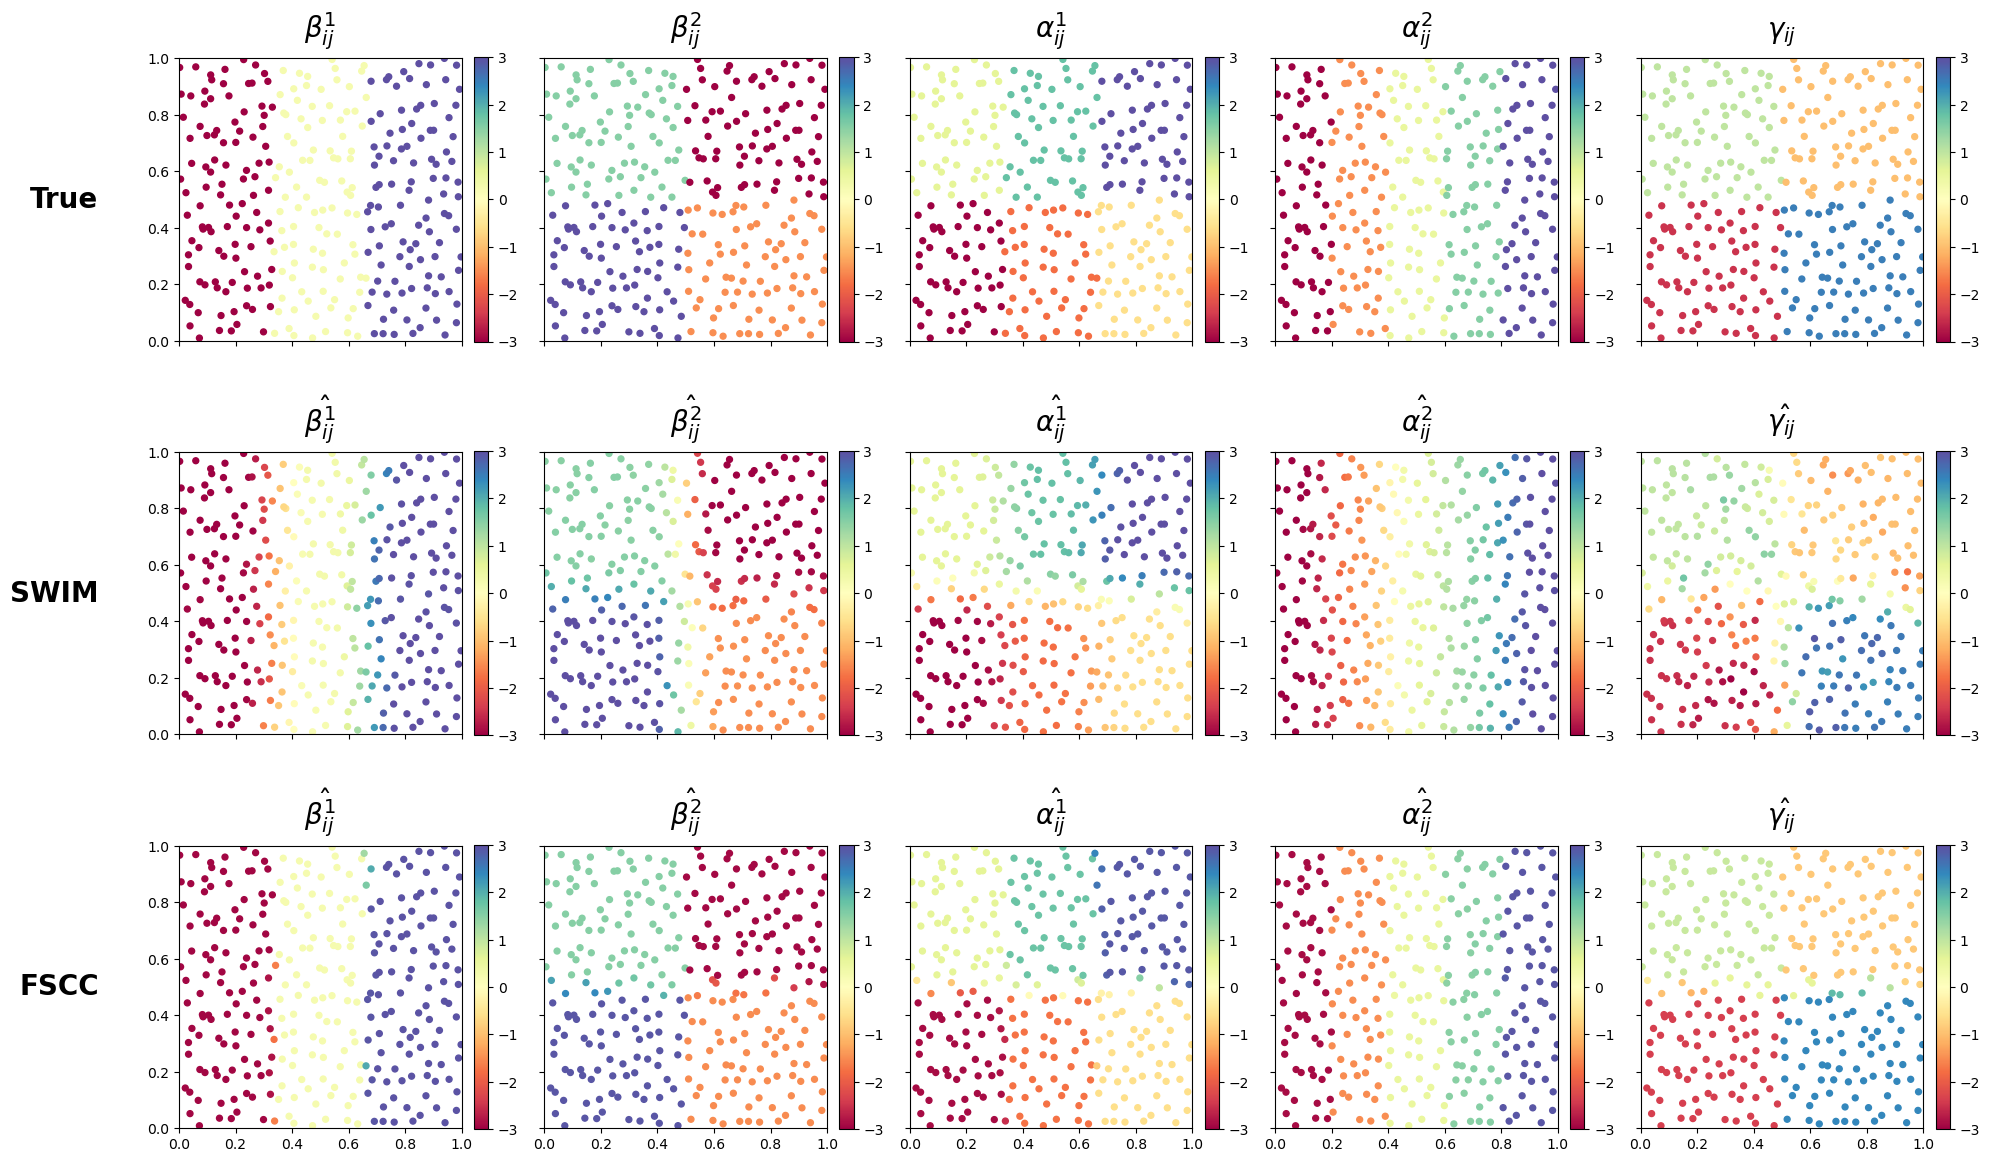


1. MODEL FIT: R2 AND MSE
Method                   R2                  MSE
   WLS -0.071416 ± 0.078380 23.200232 ± 1.710261
  SWIM  0.961740 ± 0.000317  0.828443 ± 0.007838
  FSCC  0.997195 ± 0.000027  0.060741 ± 0.000384

2. SPATIAL PARTITION RECOVERY: RAND INDEX
Method            RI_BETA1            RI_BETA2           RI_ALPHA1           RI_ALPHA2            RI_GAMMA
   WLS 0.331371 ± 0.000000 0.247514 ± 0.000000 0.164080 ± 0.000000 0.197324 ± 0.000000 0.247514 ± 0.000000
  SWIM 0.995611 ± 0.002301 0.931242 ± 0.002284 0.935576 ± 0.002834 0.964351 ± 0.003479 0.888010 ± 0.007547
  FSCC 0.980625 ± 0.002686 0.985446 ± 0.003960 0.960105 ± 0.000133 1.000000 ± 0.000000 0.964541 ± 0.001200

3. COEFFICIENT ESTIMATION ERROR: RMSE
Method          RMSE_BETA1          RMSE_BETA2         RMSE_ALPHA1         RMSE_ALPHA2          RMSE_GAMMA
   WLS 2.479844 ± 0.004511 2.371885 ± 0.006762 2.042469 ± 0.005552 2.133013 ± 0.002823 2.946942 ± 1.028487
  SWIM 0.504801 ± 0.001553 0.535389 ± 0.001963 0.44121

In [1]:
import warnings
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree
import warnings
warnings.filterwarnings("ignore")
n, p, q = (300, 2, 2)
noise_std = 0.1
intercept_true = 1.0
GRID_NEIGHBORHOOD = 'rook'
sigma = 0.05
max_dist = 0.2
B = 30
lambda_grid = [0.075, 0.1, 0.125]
max_outer = 60
max_inner = 1000
outer_tol = 0.002
admm_abs_tol = 1e-05
admm_rel_tol = 0.0005
cg_rtol = 1e-08
cg_maxiter = 1500
admm_adapt_interval = 10
admm_balance_mu = 10.0
admm_rho_factor = 2.0
admm_rho_min = 1e-05
admm_rho_max = 100000.0
admm_over_relax = 1.5
df_rel_tol = 0.001
GAMMA_CLASS_RATIOS = (40.0, 4.0, 4.0 / 3.6)
GAMMA_BASE_SCALE = 1.0
K_SWIM = 100
SWIM_BW_FIXED = 0.105
SWIM_BATCH_SIZE = 1024  # Bound SWIM temporary memory for large n
# A near-square rectangular Rook grid supports n=200 (10x20) and n=300 (15x20).
def choose_grid_shape(num_regions):
    factors = [(r, num_regions // r) for r in range(1, math.isqrt(num_regions) + 1)
               if num_regions % r == 0]
    if not factors:
        raise ValueError('n must be positive')
    return min(factors, key=lambda rc: rc[1] - rc[0])

grid_nrows, grid_ncols = choose_grid_shape(n)
grid_rows = np.repeat(np.arange(grid_nrows, dtype=np.int32), grid_ncols)
grid_cols = np.tile(np.arange(grid_ncols, dtype=np.int32), grid_nrows)
print(f'Region Rook grid: {grid_nrows} x {grid_ncols} = {n} regions')
coord_rng = np.random.default_rng(42)
coords = np.column_stack([(grid_cols + coord_rng.random(n)) / grid_ncols, (grid_rows + coord_rng.random(n)) / grid_nrows]).astype(np.float64)
D_full = cdist(coords, coords).astype(np.float64)
D_PREDICTOR_SCALE = float(np.std(D_full))
if D_PREDICTOR_SCALE <= 1e-12:
    raise ValueError('Distance predictor has zero variance.')
D_model = D_full / D_PREDICTOR_SCALE
beta_piece_sets = [[-3, 0.25, 3], [3, -1.5, 1.5, -3]]
alpha_piece_sets = [[-3, -1.8, -0.6, 0.6, 1.8, 3], [-3, -1.5, 0.5, 1.5, 3]]
gamma_piece_set = [-2.5, 2.5, 1.0, -1.0]

def grid_shape_for_count(count):
    return {3: (1, 3), 4: (2, 2), 5: (1, 5), 6: (2, 3)}[count]

def fill_piecewise_origin(arr3d, coords_, values, feat_idx):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr3d[mask, :, feat_idx] = value

def fill_piecewise_2d(arr2d, coords_, values):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr2d[mask, :] = value
beta0 = np.zeros((n, n, p), dtype=np.float64)
alpha0 = np.zeros((n, n, q), dtype=np.float64)
gamma0 = np.zeros((n, n), dtype=np.float64)
for k in range(p):
    fill_piecewise_origin(beta0, coords, beta_piece_sets[k], k)
for m in range(q):
    fill_piecewise_origin(alpha0, coords, alpha_piece_sets[m], m)
fill_piecewise_2d(gamma0, coords, gamma_piece_set)
edge_u_list = []
edge_v_list = []
for r in range(grid_nrows):
    for c in range(grid_ncols):
        u = r * grid_ncols + c
        if c + 1 < grid_ncols:
            edge_u_list.append(u)
            edge_v_list.append(u + 1)
        if r + 1 < grid_nrows:
            edge_u_list.append(u)
            edge_v_list.append(u + grid_ncols)
edge_u = np.asarray(edge_u_list, dtype=np.int32)
edge_v = np.asarray(edge_v_list, dtype=np.int32)
edge_w = np.ones(len(edge_u), dtype=np.float64)
E = len(edge_u)
N = n * n
if E == 0:
    raise RuntimeError('No grid-neighbor edges were constructed.')
A_grid = sp.coo_matrix((np.ones(2 * E, dtype=np.float64), (np.concatenate([edge_u, edge_v]), np.concatenate([edge_v, edge_u]))), shape=(n, n)).tocsr()
A_grid.setdiag(0.0)
A_grid.eliminate_zeros()
if A_grid.nnz and (not np.all(A_grid.data == 1.0)):
    raise RuntimeError('Grid adjacency must be binary: every nonzero entry must equal 1.')
try:
    OUTPUT_DIR = Path(__file__).resolve().parent
except NameError:
    OUTPUT_DIR = Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
W_wls = np.exp(-0.5 * (D_full / sigma) ** 2)
np.fill_diagonal(W_wls, 0.0)
W_wls[D_full > max_dist] = 0.0
W_wls = W_wls / (W_wls.sum() / n + 1e-12)
fixed_origin = np.tile(np.arange(n, dtype=np.int32), E)
u1 = fixed_origin * n + np.repeat(edge_u, n)
v1 = fixed_origin * n + np.repeat(edge_v, n)
w1 = np.repeat(edge_w, n)
fixed_dest = np.tile(np.arange(n, dtype=np.int32), E)
u2 = np.repeat(edge_u, n) * n + fixed_dest
v2 = np.repeat(edge_v, n) * n + fixed_dest
w2 = np.repeat(edge_w, n)
M3 = 2 * E * E
u3 = np.empty(M3, dtype=np.int32)
v3 = np.empty(M3, dtype=np.int32)
mean_region_w = float(np.mean(edge_w))
w3_legacy = np.empty(M3, dtype=np.float64)
write = 0
for e in range(E):
    i1, i2 = (int(edge_u[e]), int(edge_v[e]))
    joint_w = edge_w[e] * edge_w / max(mean_region_w, 1e-12)
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_u
    v3[sl] = i2 * n + edge_v
    w3_legacy[sl] = joint_w
    write += E
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_v
    v3[sl] = i2 * n + edge_u
    w3_legacy[sl] = joint_w
    write += E
assert write == M3
assert np.all(u3 != v3)
class3_balance = float(np.sum(w1) / max(np.sum(w3_legacy), 1e-12))
SCENARIOS = {'three_classes_binary_unit_weight': {'u': np.concatenate([u1, u2, u3]), 'v': np.concatenate([v1, v2, v3]), 'w': np.concatenate([w1, w2, w3_legacy]), 'include_class3': True, 'class3_scale': 1.0, 'class_edge_counts': (len(u1), len(u2), len(u3))}}
row_q = np.concatenate([edge_u, edge_v])
col_q = np.concatenate([edge_v, edge_u])
data_q = np.concatenate([edge_w ** 2, edge_w ** 2])
Q_region = sp.coo_matrix((data_q, (row_q, col_q)), shape=(n, n)).tocsr()
region_degree = np.asarray(Q_region.sum(axis=1)).ravel()
L_region = (sp.diags(region_degree, format='csr') - Q_region).tocsr()
_CLASS3_OPERATOR_CACHE = {}

def make_class3_operator(class3_scale):
    key = float(class3_scale)
    if key not in _CLASS3_OPERATOR_CACHE:
        joint_operator_scale = key / max(mean_region_w, 1e-12)
        q_joint = (joint_operator_scale * Q_region).tocsr()
        joint_degree = np.asarray(q_joint.sum(axis=1)).ravel()
        _CLASS3_OPERATOR_CACHE[key] = (q_joint, joint_degree)
    return _CLASS3_OPERATOR_CACHE[key]
def graph_degree_vector(include_class3, class3_scale):
    deg = region_degree[:, None] + region_degree[None, :]
    if include_class3:
        _, joint_degree = make_class3_operator(class3_scale)
        deg = deg + joint_degree[:, None] * joint_degree[None, :]
    return deg.ravel()

def graph_laplacian_matvec(x_vec, include_class3, class3_scale):
    Bmat = np.asarray(x_vec, dtype=np.float64).reshape(n, n)
    lap = L_region.dot(Bmat) + L_region.dot(Bmat.T).T
    if include_class3:
        q_joint, joint_degree = make_class3_operator(class3_scale)
        QB = q_joint.dot(Bmat)
        QBQ = q_joint.dot(QB.T).T
        lap += joint_degree[:, None] * joint_degree[None, :] * Bmat - QBQ
    return lap.ravel()

def admm_fuse(v_vec, X2_vec, rho, edges_u, edges_v, edges_w, penalty_per_edge, include_class3, class3_scale, x_init=None, dual_init=None, maxiter=max_inner):
    if len(edges_u) == 0:
        return (np.asarray(v_vec, dtype=np.float64).copy(), {'iterations': 0, 'primal': 0.0, 'dual': 0.0, 'eps_primal': 0.0, 'eps_dual': 0.0, 'primal_ratio': 0.0, 'dual_ratio': 0.0, 'converged': True, 'cg_nonconverged': 0, 'rho_final': float(rho)})
    v64 = np.asarray(v_vec, dtype=np.float64)
    X2 = np.maximum(np.asarray(X2_vec, dtype=np.float64), 1e-12)
    ew = np.asarray(edges_w, dtype=np.float64)
    pen = np.asarray(penalty_per_edge, dtype=np.float64)
    n_edges = len(edges_u)
    rho = float(rho)
    x = np.asarray(x_init, dtype=np.float64).copy() if x_init is not None else v64.copy()
    dx0 = ew * (x[edges_u] - x[edges_v])
    z = dx0.copy()
    if dual_init is None:
        dual_scaled = np.zeros(n_edges, dtype=np.float64)
    else:
        dual_scaled = np.asarray(dual_init, dtype=np.float64).copy() / max(rho, 1e-15)
    cg_nonconverged = 0
    primal_norm = dual_norm = np.inf
    eps_primal = eps_dual = np.inf
    converged = False
    alpha_relax = float(admm_over_relax)

    cached_degree = graph_degree_vector(include_class3, class3_scale)

    def make_linear_operators(rho_now):

        def matvec_A(x_vec):
            return X2 * x_vec + rho_now * graph_laplacian_matvec(x_vec, include_class3, class3_scale)
        A_op = spla.LinearOperator((N, N), matvec=matvec_A, dtype=np.float64)
        precond_diag = np.maximum(X2 + rho_now * cached_degree, 1e-10)
        M_op = spla.LinearOperator((N, N), matvec=lambda r: r / precond_diag, dtype=np.float64)
        return (A_op, M_op)
    A_op, M_op = make_linear_operators(rho)
    rho_updates = 0
    for it in range(1, maxiter + 1):
        diff_zu = (z - dual_scaled) * ew
        Kt_zu = np.bincount(edges_u, weights=diff_zu, minlength=N) - np.bincount(edges_v, weights=diff_zu, minlength=N)
        rhs = X2 * v64 + rho * Kt_zu
        x_new, cg_info = spla.cg(A_op, rhs, x0=x, M=M_op, rtol=cg_rtol, atol=0.0, maxiter=cg_maxiter)
        if cg_info != 0:
            cg_nonconverged += 1
            if cg_info < 0:
                raise RuntimeError(f'CG breakdown (info={cg_info}).')
        Kx = ew * (x_new[edges_u] - x_new[edges_v])
        z_old = z
        Kx_hat = alpha_relax * Kx + (1.0 - alpha_relax) * z_old
        threshold = pen / max(rho, 1e-15)
        z = np.sign(Kx_hat + dual_scaled) * np.maximum(np.abs(Kx_hat + dual_scaled) - threshold, 0.0)
        dual_scaled += Kx_hat - z
        primal_vec = Kx - z
        primal_norm = float(np.linalg.norm(primal_vec))
        z_change = z - z_old
        Kt_dz = np.bincount(edges_u, weights=ew * z_change, minlength=N) - np.bincount(edges_v, weights=ew * z_change, minlength=N)
        dual_vec = rho * Kt_dz
        dual_norm = float(np.linalg.norm(dual_vec))
        eps_primal = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx), np.linalg.norm(z)))
        Kt_u = np.bincount(edges_u, weights=ew * dual_scaled, minlength=N) - np.bincount(edges_v, weights=ew * dual_scaled, minlength=N)
        eps_dual = float(np.sqrt(N) * admm_abs_tol + admm_rel_tol * rho * np.linalg.norm(Kt_u))
        x = x_new
        if primal_norm <= eps_primal and dual_norm <= eps_dual:
            converged = True
            break
        if it % admm_adapt_interval == 0:
            primal_ratio_now = primal_norm / max(eps_primal, 1e-12)
            dual_ratio_now = dual_norm / max(eps_dual, 1e-12)
            rho_new = rho
            if primal_ratio_now > admm_balance_mu * dual_ratio_now:
                rho_new = min(rho * admm_rho_factor, admm_rho_max)
            elif dual_ratio_now > admm_balance_mu * primal_ratio_now:
                rho_new = max(rho / admm_rho_factor, admm_rho_min)
            if not np.isclose(rho_new, rho):
                dual_scaled *= rho / rho_new
                rho = rho_new
                A_op, M_op = make_linear_operators(rho)
                rho_updates += 1
    Kx_final = ew * (x[edges_u] - x[edges_v])
    final_primal_norm = float(np.linalg.norm(Kx_final - z))
    final_primal_eps = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx_final), np.linalg.norm(z)))
    final_primal_ratio = final_primal_norm / max(final_primal_eps, 1e-12)
    final_dual_ratio = dual_norm / max(eps_dual, 1e-12)
    converged = bool(converged and final_primal_ratio <= 1.0 and (final_dual_ratio <= 1.0))
    info = {'iterations': it, 'primal': final_primal_norm, 'dual': dual_norm, 'eps_primal': final_primal_eps, 'eps_dual': eps_dual, 'primal_ratio': final_primal_ratio, 'dual_ratio': final_dual_ratio, 'converged': converged, 'cg_nonconverged': cg_nonconverged, 'rho_final': rho, 'rho_updates': rho_updates, 'dual_unscaled': rho * dual_scaled}
    return (x.astype(np.float64), info)

def weighted_ls_baseline(X, Z, D, Y, W_flow):
    X_flat = X.reshape(N, p)
    Z_flat = Z.reshape(N, q)
    D_flat = D.ravel()
    Y_flat = Y.ravel()
    design = np.column_stack([X_flat, Z_flat, D_flat[:, None], np.ones((N, 1))])
    w_flat = W_flow.ravel()
    sw = np.sqrt(w_flat + 1e-12)
    Xw = design * sw[:, None]
    yw = Y_flat * sw
    ridge = 1e-06 * np.eye(p + q + 2)
    ridge[-1, -1] = 0.0
    coef = np.linalg.solve(Xw.T @ Xw + ridge, Xw.T @ yw)
    prediction = design @ coef
    raw_rss = float(np.sum((Y_flat - prediction) ** 2))
    weighted_rss = float(np.sum(w_flat * (Y_flat - prediction) ** 2))
    return (coef, prediction, raw_rss, weighted_rss)

def swim_fit_fixed_bw(bw, design, y_flat, idx, dist, ridge=1e-08, batch_size=SWIM_BATCH_SIZE):
    """Batched SWIM WLS solves, avoiding a full (n*n, K, features) tensor."""
    n_flows, n_features = design.shape
    coefs = np.empty((n_flows, n_features), dtype=np.float64)
    eye = np.eye(n_features, dtype=np.float64)
    for start in range(0, n_flows, batch_size):
        stop = min(start + batch_size, n_flows)
        neighbors = idx[start:stop]
        weights = np.exp(-0.5 * (dist[start:stop] / max(bw, 1e-12)) ** 2)
        xlocal = design[neighbors]
        ylocal = y_flat[neighbors]
        xtx = np.einsum('bki,bkj,bk->bij', xlocal, xlocal, weights, optimize=True)
        xtx += ridge * eye[None, :, :]
        xty = np.einsum('bki,bk,bk->bi', xlocal, ylocal, weights, optimize=True)
        coefs[start:stop] = np.linalg.solve(xtx, xty[..., None])[..., 0]
    pred = np.einsum('bi,bi->b', design, coefs)
    rss = float(np.sum((y_flat - pred) ** 2))
    return (coefs, pred, rss)

def fscc_fit(lam, beta_init, alpha_init, gamma_init, intercept_init, rho_beta, rho_alpha, rho_gamma, X, Z, D, Y, TSS, scenario):
    beta = beta_init.copy()
    alpha = alpha_init.copy()
    gamma = gamma_init.copy()
    intercept = float(intercept_init)
    eu = scenario['u']
    ev = scenario['v']
    ew = scenario['w']
    include_class3 = scenario['include_class3']
    class3_scale = scenario['class3_scale']
    pen_ba = np.full(len(eu), lam, dtype=np.float64)
    n_e1, n_e2, n_e3 = scenario['class_edge_counts']
    g1, g2, g3 = GAMMA_CLASS_RATIOS
    gamma_scale = GAMMA_BASE_SCALE
    pen_g = np.concatenate([np.full(n_e1, lam * gamma_scale * g1, dtype=np.float64), np.full(n_e2, lam * gamma_scale * g2, dtype=np.float64), np.full(n_e3, lam * gamma_scale * g3, dtype=np.float64)])
    max_primal_ratio = 0.0
    max_dual_ratio = 0.0
    max_admm_iterations = 0
    total_admm_not_converged = 0
    total_cg_nonconverged = 0
    max_rho_updates = 0
    min_rho_final = np.inf
    max_rho_final = 0.0
    outer_iterations = 0
    outer_converged = False
    final_outer_change = np.inf
    dual_states = {}
    # Maintain Y - fitted values incrementally rather than rebuilding predictions
    # for every coordinate update. This is algebraically identical to the old loop.
    residual = Y - intercept - np.sum(X * beta, axis=2) - np.sum(Z * alpha, axis=2) - D * gamma
    X2_cache = [X[:, :, k].ravel() ** 2 for k in range(p)]
    Z2_cache = [Z[:, :, m].ravel() ** 2 for m in range(q)]
    D2 = D.ravel() ** 2 + 1e-12

    def record_diag(diag):
        nonlocal max_primal_ratio, max_dual_ratio, max_admm_iterations
        nonlocal total_admm_not_converged, total_cg_nonconverged
        nonlocal max_rho_updates, min_rho_final, max_rho_final
        max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
        max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
        max_admm_iterations = max(max_admm_iterations, diag['iterations'])
        total_admm_not_converged += int(not diag['converged'])
        total_cg_nonconverged += diag['cg_nonconverged']
        max_rho_updates = max(max_rho_updates, diag['rho_updates'])
        min_rho_final = min(min_rho_final, diag['rho_final'])
        max_rho_final = max(max_rho_final, diag['rho_final'])

    for outer in range(1, max_outer + 1):
        beta_prev = beta.copy()
        alpha_prev = alpha.copy()
        gamma_prev = gamma.copy()
        intercept_prev = intercept
        for k in range(p):
            xk = X[:, :, k]
            old = beta[:, :, k].copy()
            partial_residual = residual + xk * old
            x2 = X2_cache[k]
            v = (xk * partial_residual).ravel() / (x2 + 1e-12)
            new_flat, diag = admm_fuse(v, x2, rho_beta, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('beta', k)))
            dual_states['beta', k] = diag['dual_unscaled']
            beta[:, :, k] = new_flat.reshape(n, n)
            residual += xk * (old - beta[:, :, k])
            record_diag(diag)
        for m in range(q):
            zm = Z[:, :, m]
            old = alpha[:, :, m].copy()
            partial_residual = residual + zm * old
            z2 = Z2_cache[m]
            v = (zm * partial_residual).ravel() / (z2 + 1e-12)
            new_flat, diag = admm_fuse(v, z2, rho_alpha, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('alpha', m)))
            dual_states['alpha', m] = diag['dual_unscaled']
            alpha[:, :, m] = new_flat.reshape(n, n)
            residual += zm * (old - alpha[:, :, m])
            record_diag(diag)
        old = gamma.copy()
        partial_residual = residual + D * old
        v_gamma = (D * partial_residual).ravel() / D2
        new_gamma_flat, diag = admm_fuse(v_gamma, D2, rho_gamma, eu, ev, ew, pen_g,
                                         include_class3, class3_scale,
                                         x_init=old.ravel(), dual_init=dual_states.get(('gamma', 0)))
        dual_states['gamma', 0] = diag['dual_unscaled']
        gamma = new_gamma_flat.reshape(n, n)
        residual += D * (old - gamma)
        record_diag(diag)
        # Residual is Y - (intercept + all local contributions).
        delta_intercept = float(np.mean(residual))
        intercept += delta_intercept
        residual -= delta_intercept
        db = np.linalg.norm(beta - beta_prev) / max(np.linalg.norm(beta_prev), 1.0)
        da = np.linalg.norm(alpha - alpha_prev) / max(np.linalg.norm(alpha_prev), 1.0)
        dg = np.linalg.norm(gamma - gamma_prev) / max(np.linalg.norm(gamma_prev), 1.0)
        di = abs(intercept - intercept_prev) / max(abs(intercept_prev), 1.0)
        outer_iterations = outer
        final_outer_change = float(max(db, da, dg, di))
        if final_outer_change < outer_tol:
            outer_converged = True
            break
    prediction = np.full((n, n), intercept, dtype=np.float64)
    for k in range(p):
        prediction += X[:, :, k] * beta[:, :, k]
    for m in range(q):
        prediction += Z[:, :, m] * alpha[:, :, m]
    prediction += D * gamma
    residual = Y - prediction
    rss = float(np.sum(residual ** 2))
    r2 = float(1.0 - rss / max(TSS, 1e-12))
    diag_all = {'outer_iterations': outer_iterations, 'outer_converged': outer_converged, 'final_outer_change': final_outer_change, 'max_admm_iterations': max_admm_iterations, 'max_primal_ratio': max_primal_ratio, 'max_dual_ratio': max_dual_ratio, 'admm_subproblems_not_converged': total_admm_not_converged, 'cg_nonconverged_total': total_cg_nonconverged, 'max_rho_updates_per_subproblem': max_rho_updates, 'min_rho_final': 0.0 if not np.isfinite(min_rho_final) else min_rho_final, 'max_rho_final': max_rho_final}
    return (beta, alpha, gamma, intercept, prediction, rss, r2, diag_all)

def fused_component_count(values, eu, ev, tol):
    vals = np.asarray(values, dtype=np.float64).ravel()
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    if not np.any(fused):
        return len(vals)
    rows = np.concatenate([eu[fused], ev[fused]])
    cols = np.concatenate([ev[fused], eu[fused]])
    data = np.ones(len(rows), dtype=np.int8)
    graph = sp.coo_matrix((data, (rows, cols)), shape=(len(vals), len(vals))).tocsr()
    n_comp = connected_components(graph, directed=False, return_labels=False)
    return int(n_comp)

def compute_effective_df(beta, alpha, gamma, intercept, eu, ev):
    dfs = {}
    for k in range(p):
        tol = max(1e-05, df_rel_tol * float(np.std(beta[:, :, k])))
        dfs[f'df_beta{k + 1}'] = fused_component_count(beta[:, :, k], eu, ev, tol)
    for m in range(q):
        tol = max(1e-05, df_rel_tol * float(np.std(alpha[:, :, m])))
        dfs[f'df_alpha{m + 1}'] = fused_component_count(alpha[:, :, m], eu, ev, tol)
    tol_g = max(1e-05, df_rel_tol * float(np.std(gamma)))
    dfs['df_gamma'] = fused_component_count(gamma, eu, ev, tol_g)
    dfs['df_intercept'] = 1
    dfs['df_total'] = int(sum(dfs.values()))
    return dfs

def rand_index(labels_true, labels_pred):
    labels_true = np.asarray(labels_true)
    labels_pred = np.asarray(labels_pred)
    n_pts = len(labels_true)
    iu = np.triu_indices(n_pts, k=1)
    same_true = labels_true[:, None] == labels_true[None, :]
    same_pred = labels_pred[:, None] == labels_pred[None, :]
    return float(np.mean(same_true[iu] == same_pred[iu]))

def get_true_labels(coords_, values_list):
    rows, cols = grid_shape_for_count(len(values_list))
    xe = np.linspace(0.0, 1.0, cols + 1)
    ye = np.linspace(0.0, 1.0, rows + 1)
    x_idx = np.clip(np.digitize(coords_[:, 0], xe, right=False) - 1, 0, cols - 1)
    y_idx = np.clip(np.digitize(coords_[:, 1], ye, right=False) - 1, 0, rows - 1)
    return y_idx * cols + x_idx

def cluster_rand(values, labels_true, k, seed=123):
    try:
        from sklearn.cluster import KMeans
        pred = KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(np.asarray(values).reshape(-1, 1))
        return rand_index(labels_true, pred)
    except Exception as exc:
        warnings.warn(f'Skipping k-means Rand index ({exc}).')
        return np.nan

def coefficient_metrics(beta, alpha, gamma):
    surfaces = {'beta1': (beta[:, :, 0], beta_piece_sets[0]), 'beta2': (beta[:, :, 1], beta_piece_sets[1]), 'alpha1': (alpha[:, :, 0], alpha_piece_sets[0]), 'alpha2': (alpha[:, :, 1], alpha_piece_sets[1]), 'gamma': (gamma, gamma_piece_set)}
    out = {}
    for name, (estimate, groups) in surfaces.items():
        true_surface = beta0[:, :, 0] if name == 'beta1' else beta0[:, :, 1] if name == 'beta2' else alpha0[:, :, 0] if name == 'alpha1' else alpha0[:, :, 1] if name == 'alpha2' else gamma0
        out[f'rmse_{name}'] = float(np.sqrt(np.mean((estimate - true_surface) ** 2)))
        if name == 'gamma':
            out['gamma_origin_average_rmse'] = float(np.sqrt(np.mean((estimate.mean(axis=1) - true_surface.mean(axis=1)) ** 2)))
            out['gamma_within_origin_sd'] = float(np.mean(np.std(estimate, axis=1)))
        labels_true = get_true_labels(coords, groups)
        origin_values = np.asarray(estimate).mean(axis=1)
        out[f'ri_{name}'] = cluster_rand(origin_values, labels_true, len(groups), seed=123)
    return out
method_metric_rows = []
for rep in range(B):
    seed = 1000 + rep
    np.random.seed(seed)
    X = np.random.randn(n, n, p)
    Z = np.random.randn(n, n, q)
    Y = np.full((n, n), intercept_true, dtype=np.float64)
    for k in range(p):
        Y += X[:, :, k] * beta0[:, :, k]
    for m in range(q):
        Y += Z[:, :, m] * alpha0[:, :, m]
    Y += D_full * gamma0 + noise_std * np.random.randn(n, n)
    Y_mean = float(np.mean(Y))
    TSS = float(np.sum((Y - Y_mean) ** 2))
    wls_coef, wls_pred, wls_raw_rss, wls_weighted_rss = weighted_ls_baseline(X, Z, D_model, Y, W_wls)
    wls_beta = np.tile(wls_coef[:p], (n, n, 1))
    wls_alpha = np.tile(wls_coef[p:p + q], (n, n, 1))
    wls_gamma_std = np.full((n, n), wls_coef[p + q], dtype=np.float64)
    wls_gamma = wls_gamma_std.copy()
    wls_intercept = float(wls_coef[p + q + 1])
    print(f'Replication {rep + 1}/{B}')
    wls_mse = wls_raw_rss / N
    wls_r2 = 1.0 - wls_raw_rss / max(TSS, 1e-12)
    flow_features = np.column_stack([np.repeat(coords, n, axis=0), np.tile(coords, (n, 1))])
    tree = cKDTree(flow_features)
    # Query in batches to avoid large peak memory and improve robustness.
    idx_swim = np.empty((N, min(K_SWIM, N)), dtype=np.int32)
    dist_swim = np.empty((N, min(K_SWIM, N)), dtype=np.float64)
    for start in range(0, N, SWIM_BATCH_SIZE):
        stop = min(start + SWIM_BATCH_SIZE, N)
        dd, ii = tree.query(flow_features[start:stop], k=min(K_SWIM, N), workers=-1)
        dist_swim[start:stop] = dd
        idx_swim[start:stop] = ii
    design = np.column_stack([X.reshape(N, p), Z.reshape(N, q), D_model.ravel(), np.ones(N)])
    swim_coef_map, swim_pred, swim_rss = swim_fit_fixed_bw(SWIM_BW_FIXED, design, Y.ravel(), idx_swim, dist_swim)
    swim_map = swim_coef_map.reshape(n, n, p + q + 2)
    swim_beta = swim_map[:, :, :p]
    swim_alpha = swim_map[:, :, p:p + q]
    swim_gamma = swim_map[:, :, p + q]
    wls_gamma_raw = wls_gamma / D_PREDICTOR_SCALE
    swim_gamma_raw = swim_gamma / D_PREDICTOR_SCALE
    wls_metrics = coefficient_metrics(wls_beta, wls_alpha, wls_gamma_raw)
    swim_metrics = coefficient_metrics(swim_beta, swim_alpha, swim_gamma_raw)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'WLS', 'mse': wls_mse, 'r2': wls_r2, 'intercept_estimate': wls_intercept, **wls_metrics})
    swim_mse = swim_rss / N
    swim_r2 = 1.0 - swim_rss / max(TSS, 1e-12)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'SWIM', 'mse': swim_mse, 'r2': swim_r2, 'intercept_estimate': float(np.mean(swim_map[:, :, p + q + 1])), **swim_metrics})
    # Global unweighted OLS initialization for ordinary FSCC (no WLS/SWIM pilot).
    # The design uses D_model, matching the scale used by fscc_fit.
    ols_coef, *_ = np.linalg.lstsq(design, Y.ravel(), rcond=None)
    fscc_beta_init = np.broadcast_to(ols_coef[:p], (n, n, p)).copy()
    fscc_alpha_init = np.broadcast_to(ols_coef[p:p + q], (n, n, q)).copy()
    fscc_gamma_init = np.full((n, n), ols_coef[p + q], dtype=np.float64)
    fscc_intercept_init = float(ols_coef[p + q + 1])
    rho_beta = 1.0
    rho_alpha = 1.0
    rho_gamma = 1.0
    for scenario_name, scenario in SCENARIOS.items():
        scenario_results = []
        eu = scenario['u']
        ev = scenario['v']
        edge_count_scenario = len(eu)
        # Increasing-lambda continuation: first fit starts at OLS; later fits
        # start at the previous solution. Each candidate is still optimized
        # for its own lambda and checked for convergence independently.
        warm_beta, warm_alpha, warm_gamma = fscc_beta_init, fscc_alpha_init, fscc_gamma_init
        warm_intercept = fscc_intercept_init
        for lam in sorted(lambda_grid):
            fit = fscc_fit(lam, warm_beta, warm_alpha, warm_gamma,
                           warm_intercept, rho_beta, rho_alpha, rho_gamma,
                           X, Z, D_model, Y, TSS, scenario)
            beta_hat, alpha_hat, gamma_hat, intercept_hat, pred_hat, rss, r2, admm_diag = fit
            warm_beta, warm_alpha, warm_gamma = beta_hat, alpha_hat, gamma_hat
            warm_intercept = intercept_hat
            df_info = compute_effective_df(beta_hat, alpha_hat, gamma_hat, intercept_hat, eu, ev)
            df = df_info['df_total']
            bic = N * np.log(rss / N + 1e-12) + np.log(N) * df
            if admm_diag['admm_subproblems_not_converged'] == 0 and admm_diag['cg_nonconverged_total'] == 0 and admm_diag['outer_converged']:
                scenario_results.append((bic, lam, fit, df_info, admm_diag))
        if not scenario_results:
            raise RuntimeError(f'No fully converged lambda candidate for scenario {scenario_name}. Do not select BIC from unconverged fits. Increase iteration limits or inspect the primal/dual, CG, and outer-change diagnostics.')
        best = min(scenario_results, key=lambda item: item[0])
        best_bic, best_lam, best_fit, best_df, best_admm = best
        b, a, g, intercept, pred, rss, r2, _ = best_fit
        g_raw = g / D_PREDICTOR_SCALE
        fscc_metrics = coefficient_metrics(b, a, g_raw)
        method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'FSCC', 'mse': rss / N, 'r2': r2, 'intercept_estimate': intercept, 'selected_lambda': best_lam, 'bic': best_bic, **fscc_metrics})
        if rep == B - 1:
            last_swim_beta = swim_beta.copy()
            last_swim_alpha = swim_alpha.copy()
            last_swim_gamma = swim_gamma_raw.copy()
            last_fscc_beta = b.copy()
            last_fscc_alpha = a.copy()
            last_fscc_gamma = g_raw.copy()
method_metrics_df = pd.DataFrame(method_metric_rows)
r2_mse_metrics = ['r2', 'mse']
rand_metrics = ['ri_beta1', 'ri_beta2', 'ri_alpha1', 'ri_alpha2', 'ri_gamma']
rmse_metrics = ['rmse_beta1', 'rmse_beta2', 'rmse_alpha1', 'rmse_alpha2', 'rmse_gamma']
all_metric_names = r2_mse_metrics + rand_metrics + rmse_metrics
summary_records = []
for method_name in ['WLS', 'SWIM', 'FSCC']:
    sub = method_metrics_df[method_metrics_df['method'] == method_name]
    rec = {'method': method_name, 'n_replications': int(len(sub))}
    for metric_name in all_metric_names:
        vals = pd.to_numeric(sub[metric_name], errors='coerce').dropna()
        rec[f'{metric_name}_mean'] = float(vals.mean()) if len(vals) else np.nan
        rec[f'{metric_name}_sd'] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
    summary_records.append(rec)
method_summary_df = pd.DataFrame(summary_records)
ordered_columns = ['method', 'n_replications']
for metric_name in all_metric_names:
    ordered_columns.extend([f'{metric_name}_mean', f'{metric_name}_sd'])
method_summary_df = method_summary_df[ordered_columns]
summary_path = OUTPUT_DIR / f'FSCC_performance_{n}.csv'
method_summary_df.to_csv(summary_path, index=False, encoding='utf-8-sig')
true_vals = [beta0[:, :, k].mean(axis=1) for k in range(p)] + [alpha0[:, :, m].mean(axis=1) for m in range(q)] + [gamma0.mean(axis=1)]
swim_vals = [last_swim_beta[:, :, k].mean(axis=1) for k in range(p)] + [last_swim_alpha[:, :, m].mean(axis=1) for m in range(q)] + [last_swim_gamma.mean(axis=1)]
fscc_vals = [last_fscc_beta[:, :, k].mean(axis=1) for k in range(p)] + [last_fscc_alpha[:, :, m].mean(axis=1) for m in range(q)] + [last_fscc_gamma.mean(axis=1)]
col_titles = ['$\\beta_{ij}^1$', '$\\beta_{ij}^2$', '$\\alpha_{ij}^1$', '$\\alpha_{ij}^2$', '$\\gamma_{ij}$']
est_titles = ['$\\hat{\\beta_{ij}^1}$', '$\\hat{\\beta_{ij}^2}$', '$\\hat{\\alpha_{ij}^1}$', '$\\hat{\\alpha_{ij}^2}$', '$\\hat{\\gamma_{ij}}$']
row_labels = ['True', 'SWIM', 'FSCC']
vals_list = [true_vals, swim_vals, fscc_vals]
ncols = p + q + 1
fig, axes = plt.subplots(3, ncols, figsize=(4 * ncols, 12), sharex=True, sharey=True)
vmin, vmax = (-3, 3)
for ci, title in enumerate(col_titles):
    for ri, vals in enumerate(vals_list):
        ax = axes[ri, ci]
        sc = ax.scatter(coords[:, 0], coords[:, 1], c=vals[ci], s=18, cmap='Spectral', vmin=vmin, vmax=vmax)
        ax.set_title(title if ri == 0 else est_titles[ci], fontsize=20, pad=15)
        if ri == 0:
            ax.set_title(title, fontsize=20, pad=15)
        if ci == 0:
            ax.set_ylabel(row_labels[ri], fontsize=20, rotation=0, labelpad=35, fontweight='bold', va='center', ha='right')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
final_plot_path = OUTPUT_DIR / f'FSCC_{n}_sim.png'
plt.savefig(final_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

def print_metric_section(title, metrics):
    print('\n' + '=' * 76)
    print(title)
    print('=' * 76)
    rows = []
    for _, rec in method_summary_df.iterrows():
        row = {'Method': rec['method']}
        for metric in metrics:
            mean_val = rec[f'{metric}_mean']
            sd_val = rec[f'{metric}_sd']
            row[metric.upper()] = f'{mean_val:.6f} ± {sd_val:.6f}' if pd.notna(sd_val) else f'{mean_val:.6f}'
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))
print_metric_section('1. MODEL FIT: R2 AND MSE', r2_mse_metrics)
print_metric_section('2. SPATIAL PARTITION RECOVERY: RAND INDEX', rand_metrics)
print_metric_section('3. COEFFICIENT ESTIMATION ERROR: RMSE', rmse_metrics)
print('Saved:', summary_path, final_plot_path)

Region Rook grid: 10 x 20 = 200 regions
Replication 1/30
Replication 2/30
Replication 3/30
Replication 4/30
Replication 5/30
Replication 6/30
Replication 7/30
Replication 8/30
Replication 9/30
Replication 10/30
Replication 11/30
Replication 12/30
Replication 13/30
Replication 14/30
Replication 15/30
Replication 16/30
Replication 17/30
Replication 18/30
Replication 19/30
Replication 20/30
Replication 21/30
Replication 22/30
Replication 23/30
Replication 24/30
Replication 25/30
Replication 26/30
Replication 27/30
Replication 28/30
Replication 29/30
Replication 30/30


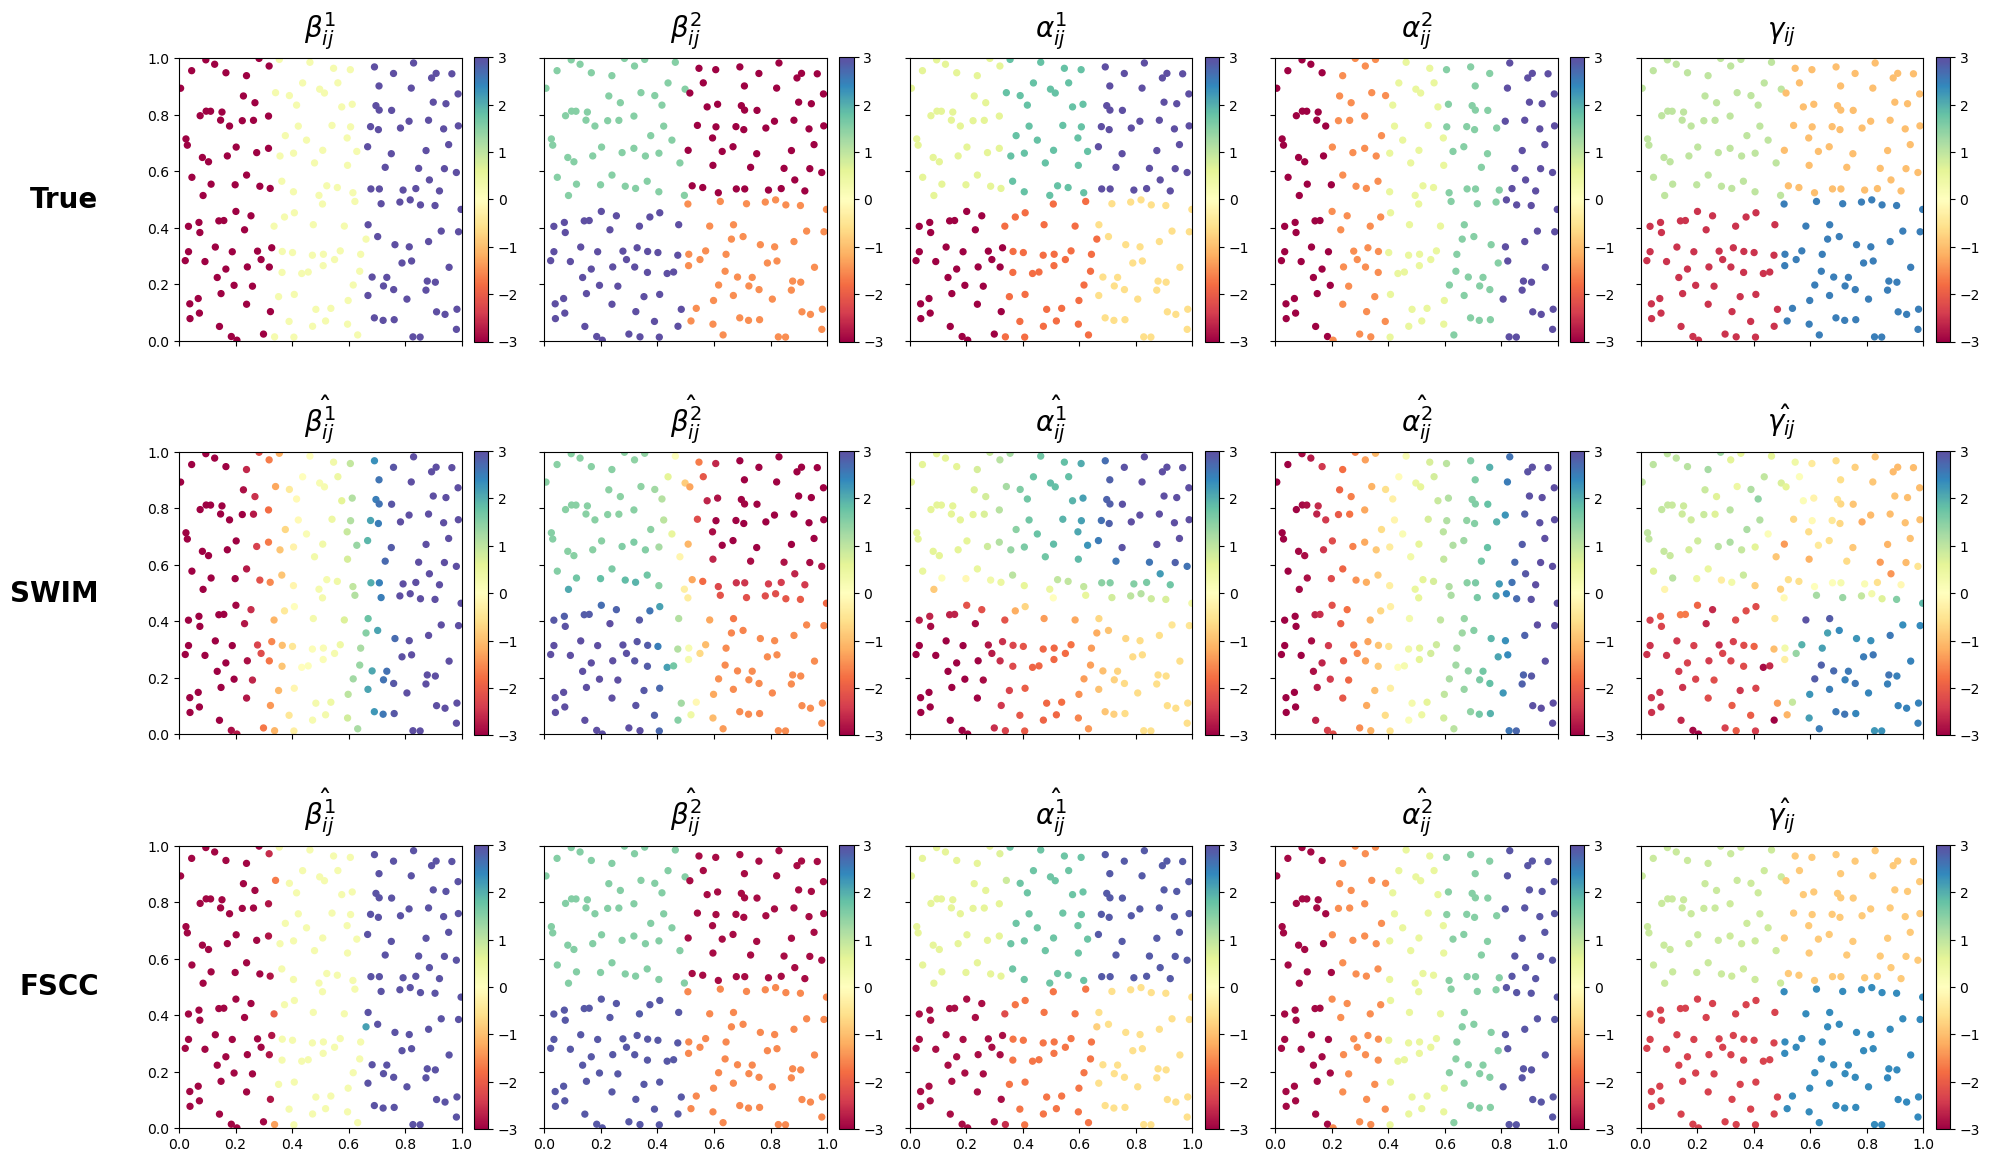


1. MODEL FIT: R2 AND MSE
Method                   R2                  MSE
   WLS -0.236399 ± 0.255263 26.915025 ± 5.502040
  SWIM  0.951856 ± 0.000690  1.048330 ± 0.013741
  FSCC  0.997884 ± 0.000026  0.046084 ± 0.000348

2. SPATIAL PARTITION RECOVERY: RAND INDEX
Method            RI_BETA1            RI_BETA2           RI_ALPHA1           RI_ALPHA2            RI_GAMMA
   WLS 0.330302 ± 0.000000 0.246231 ± 0.000000 0.162714 ± 0.000000 0.195980 ± 0.000000 0.246231 ± 0.000000
  SWIM 0.995193 ± 0.004186 0.897575 ± 0.007025 0.916796 ± 0.004489 0.941370 ± 0.009656 0.878276 ± 0.014174
  FSCC 0.976734 ± 0.003130 1.000000 ± 0.000000 0.990251 ± 0.000000 1.000000 ± 0.000000 1.000000 ± 0.000000

3. COEFFICIENT ESTIMATION ERROR: RMSE
Method          RMSE_BETA1          RMSE_BETA2         RMSE_ALPHA1         RMSE_ALPHA2          RMSE_GAMMA
   WLS 2.480425 ± 0.005942 2.377847 ± 0.008213 2.062337 ± 0.010379 2.136896 ± 0.008978 4.474919 ± 1.943671
  SWIM 0.577913 ± 0.002571 0.608716 ± 0.003102 0.54744

In [2]:
import warnings
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree
import warnings
warnings.filterwarnings("ignore")
n, p, q = (200, 2, 2)
noise_std = 0.1
intercept_true = 1.0
GRID_NEIGHBORHOOD = 'rook'
sigma = 0.05
max_dist = 0.2
B = 30
lambda_grid = [0.075, 0.1, 0.125]
max_outer = 60
max_inner = 1000
outer_tol = 0.002
admm_abs_tol = 1e-05
admm_rel_tol = 0.0005
cg_rtol = 1e-08
cg_maxiter = 1500
admm_adapt_interval = 10
admm_balance_mu = 10.0
admm_rho_factor = 2.0
admm_rho_min = 1e-05
admm_rho_max = 100000.0
admm_over_relax = 1.5
df_rel_tol = 0.001
GAMMA_CLASS_RATIOS = (40.0, 4.0, 4.0 / 3.6)
GAMMA_BASE_SCALE = 1.0
K_SWIM = 100
SWIM_BW_FIXED = 0.105
SWIM_BATCH_SIZE = 1024  # Bound SWIM temporary memory for large n
# A near-square rectangular Rook grid supports n=200 (10x20) and n=300 (15x20).
def choose_grid_shape(num_regions):
    factors = [(r, num_regions // r) for r in range(1, math.isqrt(num_regions) + 1)
               if num_regions % r == 0]
    if not factors:
        raise ValueError('n must be positive')
    return min(factors, key=lambda rc: rc[1] - rc[0])

grid_nrows, grid_ncols = choose_grid_shape(n)
grid_rows = np.repeat(np.arange(grid_nrows, dtype=np.int32), grid_ncols)
grid_cols = np.tile(np.arange(grid_ncols, dtype=np.int32), grid_nrows)
print(f'Region Rook grid: {grid_nrows} x {grid_ncols} = {n} regions')
coord_rng = np.random.default_rng(42)
coords = np.column_stack([(grid_cols + coord_rng.random(n)) / grid_ncols, (grid_rows + coord_rng.random(n)) / grid_nrows]).astype(np.float64)
D_full = cdist(coords, coords).astype(np.float64)
D_PREDICTOR_SCALE = float(np.std(D_full))
if D_PREDICTOR_SCALE <= 1e-12:
    raise ValueError('Distance predictor has zero variance.')
D_model = D_full / D_PREDICTOR_SCALE
beta_piece_sets = [[-3, 0.25, 3], [3, -1.5, 1.5, -3]]
alpha_piece_sets = [[-3, -1.8, -0.6, 0.6, 1.8, 3], [-3, -1.5, 0.5, 1.5, 3]]
gamma_piece_set = [-2.5, 2.5, 1.0, -1.0]

def grid_shape_for_count(count):
    return {3: (1, 3), 4: (2, 2), 5: (1, 5), 6: (2, 3)}[count]

def fill_piecewise_origin(arr3d, coords_, values, feat_idx):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr3d[mask, :, feat_idx] = value

def fill_piecewise_2d(arr2d, coords_, values):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr2d[mask, :] = value
beta0 = np.zeros((n, n, p), dtype=np.float64)
alpha0 = np.zeros((n, n, q), dtype=np.float64)
gamma0 = np.zeros((n, n), dtype=np.float64)
for k in range(p):
    fill_piecewise_origin(beta0, coords, beta_piece_sets[k], k)
for m in range(q):
    fill_piecewise_origin(alpha0, coords, alpha_piece_sets[m], m)
fill_piecewise_2d(gamma0, coords, gamma_piece_set)
edge_u_list = []
edge_v_list = []
for r in range(grid_nrows):
    for c in range(grid_ncols):
        u = r * grid_ncols + c
        if c + 1 < grid_ncols:
            edge_u_list.append(u)
            edge_v_list.append(u + 1)
        if r + 1 < grid_nrows:
            edge_u_list.append(u)
            edge_v_list.append(u + grid_ncols)
edge_u = np.asarray(edge_u_list, dtype=np.int32)
edge_v = np.asarray(edge_v_list, dtype=np.int32)
edge_w = np.ones(len(edge_u), dtype=np.float64)
E = len(edge_u)
N = n * n
if E == 0:
    raise RuntimeError('No grid-neighbor edges were constructed.')
A_grid = sp.coo_matrix((np.ones(2 * E, dtype=np.float64), (np.concatenate([edge_u, edge_v]), np.concatenate([edge_v, edge_u]))), shape=(n, n)).tocsr()
A_grid.setdiag(0.0)
A_grid.eliminate_zeros()
if A_grid.nnz and (not np.all(A_grid.data == 1.0)):
    raise RuntimeError('Grid adjacency must be binary: every nonzero entry must equal 1.')
try:
    OUTPUT_DIR = Path(__file__).resolve().parent
except NameError:
    OUTPUT_DIR = Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
W_wls = np.exp(-0.5 * (D_full / sigma) ** 2)
np.fill_diagonal(W_wls, 0.0)
W_wls[D_full > max_dist] = 0.0
W_wls = W_wls / (W_wls.sum() / n + 1e-12)
fixed_origin = np.tile(np.arange(n, dtype=np.int32), E)
u1 = fixed_origin * n + np.repeat(edge_u, n)
v1 = fixed_origin * n + np.repeat(edge_v, n)
w1 = np.repeat(edge_w, n)
fixed_dest = np.tile(np.arange(n, dtype=np.int32), E)
u2 = np.repeat(edge_u, n) * n + fixed_dest
v2 = np.repeat(edge_v, n) * n + fixed_dest
w2 = np.repeat(edge_w, n)
M3 = 2 * E * E
u3 = np.empty(M3, dtype=np.int32)
v3 = np.empty(M3, dtype=np.int32)
mean_region_w = float(np.mean(edge_w))
w3_legacy = np.empty(M3, dtype=np.float64)
write = 0
for e in range(E):
    i1, i2 = (int(edge_u[e]), int(edge_v[e]))
    joint_w = edge_w[e] * edge_w / max(mean_region_w, 1e-12)
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_u
    v3[sl] = i2 * n + edge_v
    w3_legacy[sl] = joint_w
    write += E
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_v
    v3[sl] = i2 * n + edge_u
    w3_legacy[sl] = joint_w
    write += E
assert write == M3
assert np.all(u3 != v3)
class3_balance = float(np.sum(w1) / max(np.sum(w3_legacy), 1e-12))
SCENARIOS = {'three_classes_binary_unit_weight': {'u': np.concatenate([u1, u2, u3]), 'v': np.concatenate([v1, v2, v3]), 'w': np.concatenate([w1, w2, w3_legacy]), 'include_class3': True, 'class3_scale': 1.0, 'class_edge_counts': (len(u1), len(u2), len(u3))}}
row_q = np.concatenate([edge_u, edge_v])
col_q = np.concatenate([edge_v, edge_u])
data_q = np.concatenate([edge_w ** 2, edge_w ** 2])
Q_region = sp.coo_matrix((data_q, (row_q, col_q)), shape=(n, n)).tocsr()
region_degree = np.asarray(Q_region.sum(axis=1)).ravel()
L_region = (sp.diags(region_degree, format='csr') - Q_region).tocsr()
_CLASS3_OPERATOR_CACHE = {}

def make_class3_operator(class3_scale):
    key = float(class3_scale)
    if key not in _CLASS3_OPERATOR_CACHE:
        joint_operator_scale = key / max(mean_region_w, 1e-12)
        q_joint = (joint_operator_scale * Q_region).tocsr()
        joint_degree = np.asarray(q_joint.sum(axis=1)).ravel()
        _CLASS3_OPERATOR_CACHE[key] = (q_joint, joint_degree)
    return _CLASS3_OPERATOR_CACHE[key]
def graph_degree_vector(include_class3, class3_scale):
    deg = region_degree[:, None] + region_degree[None, :]
    if include_class3:
        _, joint_degree = make_class3_operator(class3_scale)
        deg = deg + joint_degree[:, None] * joint_degree[None, :]
    return deg.ravel()

def graph_laplacian_matvec(x_vec, include_class3, class3_scale):
    Bmat = np.asarray(x_vec, dtype=np.float64).reshape(n, n)
    lap = L_region.dot(Bmat) + L_region.dot(Bmat.T).T
    if include_class3:
        q_joint, joint_degree = make_class3_operator(class3_scale)
        QB = q_joint.dot(Bmat)
        QBQ = q_joint.dot(QB.T).T
        lap += joint_degree[:, None] * joint_degree[None, :] * Bmat - QBQ
    return lap.ravel()

def admm_fuse(v_vec, X2_vec, rho, edges_u, edges_v, edges_w, penalty_per_edge, include_class3, class3_scale, x_init=None, dual_init=None, maxiter=max_inner):
    if len(edges_u) == 0:
        return (np.asarray(v_vec, dtype=np.float64).copy(), {'iterations': 0, 'primal': 0.0, 'dual': 0.0, 'eps_primal': 0.0, 'eps_dual': 0.0, 'primal_ratio': 0.0, 'dual_ratio': 0.0, 'converged': True, 'cg_nonconverged': 0, 'rho_final': float(rho)})
    v64 = np.asarray(v_vec, dtype=np.float64)
    X2 = np.maximum(np.asarray(X2_vec, dtype=np.float64), 1e-12)
    ew = np.asarray(edges_w, dtype=np.float64)
    pen = np.asarray(penalty_per_edge, dtype=np.float64)
    n_edges = len(edges_u)
    rho = float(rho)
    x = np.asarray(x_init, dtype=np.float64).copy() if x_init is not None else v64.copy()
    dx0 = ew * (x[edges_u] - x[edges_v])
    z = dx0.copy()
    if dual_init is None:
        dual_scaled = np.zeros(n_edges, dtype=np.float64)
    else:
        dual_scaled = np.asarray(dual_init, dtype=np.float64).copy() / max(rho, 1e-15)
    cg_nonconverged = 0
    primal_norm = dual_norm = np.inf
    eps_primal = eps_dual = np.inf
    converged = False
    alpha_relax = float(admm_over_relax)

    cached_degree = graph_degree_vector(include_class3, class3_scale)

    def make_linear_operators(rho_now):

        def matvec_A(x_vec):
            return X2 * x_vec + rho_now * graph_laplacian_matvec(x_vec, include_class3, class3_scale)
        A_op = spla.LinearOperator((N, N), matvec=matvec_A, dtype=np.float64)
        precond_diag = np.maximum(X2 + rho_now * cached_degree, 1e-10)
        M_op = spla.LinearOperator((N, N), matvec=lambda r: r / precond_diag, dtype=np.float64)
        return (A_op, M_op)
    A_op, M_op = make_linear_operators(rho)
    rho_updates = 0
    for it in range(1, maxiter + 1):
        diff_zu = (z - dual_scaled) * ew
        Kt_zu = np.bincount(edges_u, weights=diff_zu, minlength=N) - np.bincount(edges_v, weights=diff_zu, minlength=N)
        rhs = X2 * v64 + rho * Kt_zu
        x_new, cg_info = spla.cg(A_op, rhs, x0=x, M=M_op, rtol=cg_rtol, atol=0.0, maxiter=cg_maxiter)
        if cg_info != 0:
            cg_nonconverged += 1
            if cg_info < 0:
                raise RuntimeError(f'CG breakdown (info={cg_info}).')
        Kx = ew * (x_new[edges_u] - x_new[edges_v])
        z_old = z
        Kx_hat = alpha_relax * Kx + (1.0 - alpha_relax) * z_old
        threshold = pen / max(rho, 1e-15)
        z = np.sign(Kx_hat + dual_scaled) * np.maximum(np.abs(Kx_hat + dual_scaled) - threshold, 0.0)
        dual_scaled += Kx_hat - z
        primal_vec = Kx - z
        primal_norm = float(np.linalg.norm(primal_vec))
        z_change = z - z_old
        Kt_dz = np.bincount(edges_u, weights=ew * z_change, minlength=N) - np.bincount(edges_v, weights=ew * z_change, minlength=N)
        dual_vec = rho * Kt_dz
        dual_norm = float(np.linalg.norm(dual_vec))
        eps_primal = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx), np.linalg.norm(z)))
        Kt_u = np.bincount(edges_u, weights=ew * dual_scaled, minlength=N) - np.bincount(edges_v, weights=ew * dual_scaled, minlength=N)
        eps_dual = float(np.sqrt(N) * admm_abs_tol + admm_rel_tol * rho * np.linalg.norm(Kt_u))
        x = x_new
        if primal_norm <= eps_primal and dual_norm <= eps_dual:
            converged = True
            break
        if it % admm_adapt_interval == 0:
            primal_ratio_now = primal_norm / max(eps_primal, 1e-12)
            dual_ratio_now = dual_norm / max(eps_dual, 1e-12)
            rho_new = rho
            if primal_ratio_now > admm_balance_mu * dual_ratio_now:
                rho_new = min(rho * admm_rho_factor, admm_rho_max)
            elif dual_ratio_now > admm_balance_mu * primal_ratio_now:
                rho_new = max(rho / admm_rho_factor, admm_rho_min)
            if not np.isclose(rho_new, rho):
                dual_scaled *= rho / rho_new
                rho = rho_new
                A_op, M_op = make_linear_operators(rho)
                rho_updates += 1
    Kx_final = ew * (x[edges_u] - x[edges_v])
    final_primal_norm = float(np.linalg.norm(Kx_final - z))
    final_primal_eps = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx_final), np.linalg.norm(z)))
    final_primal_ratio = final_primal_norm / max(final_primal_eps, 1e-12)
    final_dual_ratio = dual_norm / max(eps_dual, 1e-12)
    converged = bool(converged and final_primal_ratio <= 1.0 and (final_dual_ratio <= 1.0))
    info = {'iterations': it, 'primal': final_primal_norm, 'dual': dual_norm, 'eps_primal': final_primal_eps, 'eps_dual': eps_dual, 'primal_ratio': final_primal_ratio, 'dual_ratio': final_dual_ratio, 'converged': converged, 'cg_nonconverged': cg_nonconverged, 'rho_final': rho, 'rho_updates': rho_updates, 'dual_unscaled': rho * dual_scaled}
    return (x.astype(np.float64), info)

def weighted_ls_baseline(X, Z, D, Y, W_flow):
    X_flat = X.reshape(N, p)
    Z_flat = Z.reshape(N, q)
    D_flat = D.ravel()
    Y_flat = Y.ravel()
    design = np.column_stack([X_flat, Z_flat, D_flat[:, None], np.ones((N, 1))])
    w_flat = W_flow.ravel()
    sw = np.sqrt(w_flat + 1e-12)
    Xw = design * sw[:, None]
    yw = Y_flat * sw
    ridge = 1e-06 * np.eye(p + q + 2)
    ridge[-1, -1] = 0.0
    coef = np.linalg.solve(Xw.T @ Xw + ridge, Xw.T @ yw)
    prediction = design @ coef
    raw_rss = float(np.sum((Y_flat - prediction) ** 2))
    weighted_rss = float(np.sum(w_flat * (Y_flat - prediction) ** 2))
    return (coef, prediction, raw_rss, weighted_rss)

def swim_fit_fixed_bw(bw, design, y_flat, idx, dist, ridge=1e-08, batch_size=SWIM_BATCH_SIZE):
    """Batched SWIM WLS solves, avoiding a full (n*n, K, features) tensor."""
    n_flows, n_features = design.shape
    coefs = np.empty((n_flows, n_features), dtype=np.float64)
    eye = np.eye(n_features, dtype=np.float64)
    for start in range(0, n_flows, batch_size):
        stop = min(start + batch_size, n_flows)
        neighbors = idx[start:stop]
        weights = np.exp(-0.5 * (dist[start:stop] / max(bw, 1e-12)) ** 2)
        xlocal = design[neighbors]
        ylocal = y_flat[neighbors]
        xtx = np.einsum('bki,bkj,bk->bij', xlocal, xlocal, weights, optimize=True)
        xtx += ridge * eye[None, :, :]
        xty = np.einsum('bki,bk,bk->bi', xlocal, ylocal, weights, optimize=True)
        coefs[start:stop] = np.linalg.solve(xtx, xty[..., None])[..., 0]
    pred = np.einsum('bi,bi->b', design, coefs)
    rss = float(np.sum((y_flat - pred) ** 2))
    return (coefs, pred, rss)

def fscc_fit(lam, beta_init, alpha_init, gamma_init, intercept_init, rho_beta, rho_alpha, rho_gamma, X, Z, D, Y, TSS, scenario):
    beta = beta_init.copy()
    alpha = alpha_init.copy()
    gamma = gamma_init.copy()
    intercept = float(intercept_init)
    eu = scenario['u']
    ev = scenario['v']
    ew = scenario['w']
    include_class3 = scenario['include_class3']
    class3_scale = scenario['class3_scale']
    pen_ba = np.full(len(eu), lam, dtype=np.float64)
    n_e1, n_e2, n_e3 = scenario['class_edge_counts']
    g1, g2, g3 = GAMMA_CLASS_RATIOS
    gamma_scale = GAMMA_BASE_SCALE
    pen_g = np.concatenate([np.full(n_e1, lam * gamma_scale * g1, dtype=np.float64), np.full(n_e2, lam * gamma_scale * g2, dtype=np.float64), np.full(n_e3, lam * gamma_scale * g3, dtype=np.float64)])
    max_primal_ratio = 0.0
    max_dual_ratio = 0.0
    max_admm_iterations = 0
    total_admm_not_converged = 0
    total_cg_nonconverged = 0
    max_rho_updates = 0
    min_rho_final = np.inf
    max_rho_final = 0.0
    outer_iterations = 0
    outer_converged = False
    final_outer_change = np.inf
    dual_states = {}
    # Maintain Y - fitted values incrementally rather than rebuilding predictions
    # for every coordinate update. This is algebraically identical to the old loop.
    residual = Y - intercept - np.sum(X * beta, axis=2) - np.sum(Z * alpha, axis=2) - D * gamma
    X2_cache = [X[:, :, k].ravel() ** 2 for k in range(p)]
    Z2_cache = [Z[:, :, m].ravel() ** 2 for m in range(q)]
    D2 = D.ravel() ** 2 + 1e-12

    def record_diag(diag):
        nonlocal max_primal_ratio, max_dual_ratio, max_admm_iterations
        nonlocal total_admm_not_converged, total_cg_nonconverged
        nonlocal max_rho_updates, min_rho_final, max_rho_final
        max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
        max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
        max_admm_iterations = max(max_admm_iterations, diag['iterations'])
        total_admm_not_converged += int(not diag['converged'])
        total_cg_nonconverged += diag['cg_nonconverged']
        max_rho_updates = max(max_rho_updates, diag['rho_updates'])
        min_rho_final = min(min_rho_final, diag['rho_final'])
        max_rho_final = max(max_rho_final, diag['rho_final'])

    for outer in range(1, max_outer + 1):
        beta_prev = beta.copy()
        alpha_prev = alpha.copy()
        gamma_prev = gamma.copy()
        intercept_prev = intercept
        for k in range(p):
            xk = X[:, :, k]
            old = beta[:, :, k].copy()
            partial_residual = residual + xk * old
            x2 = X2_cache[k]
            v = (xk * partial_residual).ravel() / (x2 + 1e-12)
            new_flat, diag = admm_fuse(v, x2, rho_beta, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('beta', k)))
            dual_states['beta', k] = diag['dual_unscaled']
            beta[:, :, k] = new_flat.reshape(n, n)
            residual += xk * (old - beta[:, :, k])
            record_diag(diag)
        for m in range(q):
            zm = Z[:, :, m]
            old = alpha[:, :, m].copy()
            partial_residual = residual + zm * old
            z2 = Z2_cache[m]
            v = (zm * partial_residual).ravel() / (z2 + 1e-12)
            new_flat, diag = admm_fuse(v, z2, rho_alpha, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('alpha', m)))
            dual_states['alpha', m] = diag['dual_unscaled']
            alpha[:, :, m] = new_flat.reshape(n, n)
            residual += zm * (old - alpha[:, :, m])
            record_diag(diag)
        old = gamma.copy()
        partial_residual = residual + D * old
        v_gamma = (D * partial_residual).ravel() / D2
        new_gamma_flat, diag = admm_fuse(v_gamma, D2, rho_gamma, eu, ev, ew, pen_g,
                                         include_class3, class3_scale,
                                         x_init=old.ravel(), dual_init=dual_states.get(('gamma', 0)))
        dual_states['gamma', 0] = diag['dual_unscaled']
        gamma = new_gamma_flat.reshape(n, n)
        residual += D * (old - gamma)
        record_diag(diag)
        # Residual is Y - (intercept + all local contributions).
        delta_intercept = float(np.mean(residual))
        intercept += delta_intercept
        residual -= delta_intercept
        db = np.linalg.norm(beta - beta_prev) / max(np.linalg.norm(beta_prev), 1.0)
        da = np.linalg.norm(alpha - alpha_prev) / max(np.linalg.norm(alpha_prev), 1.0)
        dg = np.linalg.norm(gamma - gamma_prev) / max(np.linalg.norm(gamma_prev), 1.0)
        di = abs(intercept - intercept_prev) / max(abs(intercept_prev), 1.0)
        outer_iterations = outer
        final_outer_change = float(max(db, da, dg, di))
        if final_outer_change < outer_tol:
            outer_converged = True
            break
    prediction = np.full((n, n), intercept, dtype=np.float64)
    for k in range(p):
        prediction += X[:, :, k] * beta[:, :, k]
    for m in range(q):
        prediction += Z[:, :, m] * alpha[:, :, m]
    prediction += D * gamma
    residual = Y - prediction
    rss = float(np.sum(residual ** 2))
    r2 = float(1.0 - rss / max(TSS, 1e-12))
    diag_all = {'outer_iterations': outer_iterations, 'outer_converged': outer_converged, 'final_outer_change': final_outer_change, 'max_admm_iterations': max_admm_iterations, 'max_primal_ratio': max_primal_ratio, 'max_dual_ratio': max_dual_ratio, 'admm_subproblems_not_converged': total_admm_not_converged, 'cg_nonconverged_total': total_cg_nonconverged, 'max_rho_updates_per_subproblem': max_rho_updates, 'min_rho_final': 0.0 if not np.isfinite(min_rho_final) else min_rho_final, 'max_rho_final': max_rho_final}
    return (beta, alpha, gamma, intercept, prediction, rss, r2, diag_all)

def fused_component_count(values, eu, ev, tol):
    vals = np.asarray(values, dtype=np.float64).ravel()
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    if not np.any(fused):
        return len(vals)
    rows = np.concatenate([eu[fused], ev[fused]])
    cols = np.concatenate([ev[fused], eu[fused]])
    data = np.ones(len(rows), dtype=np.int8)
    graph = sp.coo_matrix((data, (rows, cols)), shape=(len(vals), len(vals))).tocsr()
    n_comp = connected_components(graph, directed=False, return_labels=False)
    return int(n_comp)

def compute_effective_df(beta, alpha, gamma, intercept, eu, ev):
    dfs = {}
    for k in range(p):
        tol = max(1e-05, df_rel_tol * float(np.std(beta[:, :, k])))
        dfs[f'df_beta{k + 1}'] = fused_component_count(beta[:, :, k], eu, ev, tol)
    for m in range(q):
        tol = max(1e-05, df_rel_tol * float(np.std(alpha[:, :, m])))
        dfs[f'df_alpha{m + 1}'] = fused_component_count(alpha[:, :, m], eu, ev, tol)
    tol_g = max(1e-05, df_rel_tol * float(np.std(gamma)))
    dfs['df_gamma'] = fused_component_count(gamma, eu, ev, tol_g)
    dfs['df_intercept'] = 1
    dfs['df_total'] = int(sum(dfs.values()))
    return dfs

def rand_index(labels_true, labels_pred):
    labels_true = np.asarray(labels_true)
    labels_pred = np.asarray(labels_pred)
    n_pts = len(labels_true)
    iu = np.triu_indices(n_pts, k=1)
    same_true = labels_true[:, None] == labels_true[None, :]
    same_pred = labels_pred[:, None] == labels_pred[None, :]
    return float(np.mean(same_true[iu] == same_pred[iu]))

def get_true_labels(coords_, values_list):
    rows, cols = grid_shape_for_count(len(values_list))
    xe = np.linspace(0.0, 1.0, cols + 1)
    ye = np.linspace(0.0, 1.0, rows + 1)
    x_idx = np.clip(np.digitize(coords_[:, 0], xe, right=False) - 1, 0, cols - 1)
    y_idx = np.clip(np.digitize(coords_[:, 1], ye, right=False) - 1, 0, rows - 1)
    return y_idx * cols + x_idx

def cluster_rand(values, labels_true, k, seed=123):
    try:
        from sklearn.cluster import KMeans
        pred = KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(np.asarray(values).reshape(-1, 1))
        return rand_index(labels_true, pred)
    except Exception as exc:
        warnings.warn(f'Skipping k-means Rand index ({exc}).')
        return np.nan

def coefficient_metrics(beta, alpha, gamma):
    surfaces = {'beta1': (beta[:, :, 0], beta_piece_sets[0]), 'beta2': (beta[:, :, 1], beta_piece_sets[1]), 'alpha1': (alpha[:, :, 0], alpha_piece_sets[0]), 'alpha2': (alpha[:, :, 1], alpha_piece_sets[1]), 'gamma': (gamma, gamma_piece_set)}
    out = {}
    for name, (estimate, groups) in surfaces.items():
        true_surface = beta0[:, :, 0] if name == 'beta1' else beta0[:, :, 1] if name == 'beta2' else alpha0[:, :, 0] if name == 'alpha1' else alpha0[:, :, 1] if name == 'alpha2' else gamma0
        out[f'rmse_{name}'] = float(np.sqrt(np.mean((estimate - true_surface) ** 2)))
        if name == 'gamma':
            out['gamma_origin_average_rmse'] = float(np.sqrt(np.mean((estimate.mean(axis=1) - true_surface.mean(axis=1)) ** 2)))
            out['gamma_within_origin_sd'] = float(np.mean(np.std(estimate, axis=1)))
        labels_true = get_true_labels(coords, groups)
        origin_values = np.asarray(estimate).mean(axis=1)
        out[f'ri_{name}'] = cluster_rand(origin_values, labels_true, len(groups), seed=123)
    return out
method_metric_rows = []
for rep in range(B):
    seed = 1000 + rep
    np.random.seed(seed)
    X = np.random.randn(n, n, p)
    Z = np.random.randn(n, n, q)
    Y = np.full((n, n), intercept_true, dtype=np.float64)
    for k in range(p):
        Y += X[:, :, k] * beta0[:, :, k]
    for m in range(q):
        Y += Z[:, :, m] * alpha0[:, :, m]
    Y += D_full * gamma0 + noise_std * np.random.randn(n, n)
    Y_mean = float(np.mean(Y))
    TSS = float(np.sum((Y - Y_mean) ** 2))
    wls_coef, wls_pred, wls_raw_rss, wls_weighted_rss = weighted_ls_baseline(X, Z, D_model, Y, W_wls)
    wls_beta = np.tile(wls_coef[:p], (n, n, 1))
    wls_alpha = np.tile(wls_coef[p:p + q], (n, n, 1))
    wls_gamma_std = np.full((n, n), wls_coef[p + q], dtype=np.float64)
    wls_gamma = wls_gamma_std.copy()
    wls_intercept = float(wls_coef[p + q + 1])
    print(f'Replication {rep + 1}/{B}')
    wls_mse = wls_raw_rss / N
    wls_r2 = 1.0 - wls_raw_rss / max(TSS, 1e-12)
    flow_features = np.column_stack([np.repeat(coords, n, axis=0), np.tile(coords, (n, 1))])
    tree = cKDTree(flow_features)
    # Query in batches to avoid large peak memory and improve robustness.
    idx_swim = np.empty((N, min(K_SWIM, N)), dtype=np.int32)
    dist_swim = np.empty((N, min(K_SWIM, N)), dtype=np.float64)
    for start in range(0, N, SWIM_BATCH_SIZE):
        stop = min(start + SWIM_BATCH_SIZE, N)
        dd, ii = tree.query(flow_features[start:stop], k=min(K_SWIM, N), workers=-1)
        dist_swim[start:stop] = dd
        idx_swim[start:stop] = ii
    design = np.column_stack([X.reshape(N, p), Z.reshape(N, q), D_model.ravel(), np.ones(N)])
    swim_coef_map, swim_pred, swim_rss = swim_fit_fixed_bw(SWIM_BW_FIXED, design, Y.ravel(), idx_swim, dist_swim)
    swim_map = swim_coef_map.reshape(n, n, p + q + 2)
    swim_beta = swim_map[:, :, :p]
    swim_alpha = swim_map[:, :, p:p + q]
    swim_gamma = swim_map[:, :, p + q]
    wls_gamma_raw = wls_gamma / D_PREDICTOR_SCALE
    swim_gamma_raw = swim_gamma / D_PREDICTOR_SCALE
    wls_metrics = coefficient_metrics(wls_beta, wls_alpha, wls_gamma_raw)
    swim_metrics = coefficient_metrics(swim_beta, swim_alpha, swim_gamma_raw)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'WLS', 'mse': wls_mse, 'r2': wls_r2, 'intercept_estimate': wls_intercept, **wls_metrics})
    swim_mse = swim_rss / N
    swim_r2 = 1.0 - swim_rss / max(TSS, 1e-12)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'SWIM', 'mse': swim_mse, 'r2': swim_r2, 'intercept_estimate': float(np.mean(swim_map[:, :, p + q + 1])), **swim_metrics})
    # Global unweighted OLS initialization for ordinary FSCC (no WLS/SWIM pilot).
    # The design uses D_model, matching the scale used by fscc_fit.
    ols_coef, *_ = np.linalg.lstsq(design, Y.ravel(), rcond=None)
    fscc_beta_init = np.broadcast_to(ols_coef[:p], (n, n, p)).copy()
    fscc_alpha_init = np.broadcast_to(ols_coef[p:p + q], (n, n, q)).copy()
    fscc_gamma_init = np.full((n, n), ols_coef[p + q], dtype=np.float64)
    fscc_intercept_init = float(ols_coef[p + q + 1])
    rho_beta = 1.0
    rho_alpha = 1.0
    rho_gamma = 1.0
    for scenario_name, scenario in SCENARIOS.items():
        scenario_results = []
        eu = scenario['u']
        ev = scenario['v']
        edge_count_scenario = len(eu)
        # Increasing-lambda continuation: first fit starts at OLS; later fits
        # start at the previous solution. Each candidate is still optimized
        # for its own lambda and checked for convergence independently.
        warm_beta, warm_alpha, warm_gamma = fscc_beta_init, fscc_alpha_init, fscc_gamma_init
        warm_intercept = fscc_intercept_init
        for lam in sorted(lambda_grid):
            fit = fscc_fit(lam, warm_beta, warm_alpha, warm_gamma,
                           warm_intercept, rho_beta, rho_alpha, rho_gamma,
                           X, Z, D_model, Y, TSS, scenario)
            beta_hat, alpha_hat, gamma_hat, intercept_hat, pred_hat, rss, r2, admm_diag = fit
            warm_beta, warm_alpha, warm_gamma = beta_hat, alpha_hat, gamma_hat
            warm_intercept = intercept_hat
            df_info = compute_effective_df(beta_hat, alpha_hat, gamma_hat, intercept_hat, eu, ev)
            df = df_info['df_total']
            bic = N * np.log(rss / N + 1e-12) + np.log(N) * df
            if admm_diag['admm_subproblems_not_converged'] == 0 and admm_diag['cg_nonconverged_total'] == 0 and admm_diag['outer_converged']:
                scenario_results.append((bic, lam, fit, df_info, admm_diag))
        if not scenario_results:
            raise RuntimeError(f'No fully converged lambda candidate for scenario {scenario_name}. Do not select BIC from unconverged fits. Increase iteration limits or inspect the primal/dual, CG, and outer-change diagnostics.')
        best = min(scenario_results, key=lambda item: item[0])
        best_bic, best_lam, best_fit, best_df, best_admm = best
        b, a, g, intercept, pred, rss, r2, _ = best_fit
        g_raw = g / D_PREDICTOR_SCALE
        fscc_metrics = coefficient_metrics(b, a, g_raw)
        method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'FSCC', 'mse': rss / N, 'r2': r2, 'intercept_estimate': intercept, 'selected_lambda': best_lam, 'bic': best_bic, **fscc_metrics})
        if rep == B - 1:
            last_swim_beta = swim_beta.copy()
            last_swim_alpha = swim_alpha.copy()
            last_swim_gamma = swim_gamma_raw.copy()
            last_fscc_beta = b.copy()
            last_fscc_alpha = a.copy()
            last_fscc_gamma = g_raw.copy()
method_metrics_df = pd.DataFrame(method_metric_rows)
r2_mse_metrics = ['r2', 'mse']
rand_metrics = ['ri_beta1', 'ri_beta2', 'ri_alpha1', 'ri_alpha2', 'ri_gamma']
rmse_metrics = ['rmse_beta1', 'rmse_beta2', 'rmse_alpha1', 'rmse_alpha2', 'rmse_gamma']
all_metric_names = r2_mse_metrics + rand_metrics + rmse_metrics
summary_records = []
for method_name in ['WLS', 'SWIM', 'FSCC']:
    sub = method_metrics_df[method_metrics_df['method'] == method_name]
    rec = {'method': method_name, 'n_replications': int(len(sub))}
    for metric_name in all_metric_names:
        vals = pd.to_numeric(sub[metric_name], errors='coerce').dropna()
        rec[f'{metric_name}_mean'] = float(vals.mean()) if len(vals) else np.nan
        rec[f'{metric_name}_sd'] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
    summary_records.append(rec)
method_summary_df = pd.DataFrame(summary_records)
ordered_columns = ['method', 'n_replications']
for metric_name in all_metric_names:
    ordered_columns.extend([f'{metric_name}_mean', f'{metric_name}_sd'])
method_summary_df = method_summary_df[ordered_columns]
summary_path = OUTPUT_DIR / f'FSCC_performance_{n}.csv'
method_summary_df.to_csv(summary_path, index=False, encoding='utf-8-sig')
true_vals = [beta0[:, :, k].mean(axis=1) for k in range(p)] + [alpha0[:, :, m].mean(axis=1) for m in range(q)] + [gamma0.mean(axis=1)]
swim_vals = [last_swim_beta[:, :, k].mean(axis=1) for k in range(p)] + [last_swim_alpha[:, :, m].mean(axis=1) for m in range(q)] + [last_swim_gamma.mean(axis=1)]
fscc_vals = [last_fscc_beta[:, :, k].mean(axis=1) for k in range(p)] + [last_fscc_alpha[:, :, m].mean(axis=1) for m in range(q)] + [last_fscc_gamma.mean(axis=1)]
col_titles = ['$\\beta_{ij}^1$', '$\\beta_{ij}^2$', '$\\alpha_{ij}^1$', '$\\alpha_{ij}^2$', '$\\gamma_{ij}$']
est_titles = ['$\\hat{\\beta_{ij}^1}$', '$\\hat{\\beta_{ij}^2}$', '$\\hat{\\alpha_{ij}^1}$', '$\\hat{\\alpha_{ij}^2}$', '$\\hat{\\gamma_{ij}}$']
row_labels = ['True', 'SWIM', 'FSCC']
vals_list = [true_vals, swim_vals, fscc_vals]
ncols = p + q + 1
fig, axes = plt.subplots(3, ncols, figsize=(4 * ncols, 12), sharex=True, sharey=True)
vmin, vmax = (-3, 3)
for ci, title in enumerate(col_titles):
    for ri, vals in enumerate(vals_list):
        ax = axes[ri, ci]
        sc = ax.scatter(coords[:, 0], coords[:, 1], c=vals[ci], s=18, cmap='Spectral', vmin=vmin, vmax=vmax)
        ax.set_title(title if ri == 0 else est_titles[ci], fontsize=20, pad=15)
        if ri == 0:
            ax.set_title(title, fontsize=20, pad=15)
        if ci == 0:
            ax.set_ylabel(row_labels[ri], fontsize=20, rotation=0, labelpad=35, fontweight='bold', va='center', ha='right')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
final_plot_path = OUTPUT_DIR / f'FSCC_{n}_sim.png'
plt.savefig(final_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

def print_metric_section(title, metrics):
    print('\n' + '=' * 76)
    print(title)
    print('=' * 76)
    rows = []
    for _, rec in method_summary_df.iterrows():
        row = {'Method': rec['method']}
        for metric in metrics:
            mean_val = rec[f'{metric}_mean']
            sd_val = rec[f'{metric}_sd']
            row[metric.upper()] = f'{mean_val:.6f} ± {sd_val:.6f}' if pd.notna(sd_val) else f'{mean_val:.6f}'
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))
print_metric_section('1. MODEL FIT: R2 AND MSE', r2_mse_metrics)
print_metric_section('2. SPATIAL PARTITION RECOVERY: RAND INDEX', rand_metrics)
print_metric_section('3. COEFFICIENT ESTIMATION ERROR: RMSE', rmse_metrics)
print('Saved:', summary_path, final_plot_path)

In [ ]:
import warnings
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree
import warnings
warnings.filterwarnings("ignore")
n, p, q = (200, 2, 2)
noise_std = 0.1
intercept_true = 1.0
GRID_NEIGHBORHOOD = 'rook'
B = 2
lambda_grid = [0.075, 0.1, 0.125]
max_outer = 60
max_inner = 1000
outer_tol = 0.002
admm_abs_tol = 1e-05
admm_rel_tol = 0.0005
cg_rtol = 1e-08
cg_maxiter = 1500
admm_adapt_interval = 10
admm_balance_mu = 10.0
admm_rho_factor = 2.0
admm_rho_min = 1e-05
admm_rho_max = 100000.0
admm_over_relax = 1.5
df_rel_tol = 0.001
GAMMA_CLASS_RATIOS = (40.0, 4.0, 4.0 / 3.6)
GAMMA_BASE_SCALE = 1.0
K_SWIM = 100
SWIM_BW_FIXED = 0.105
SWIM_BATCH_SIZE = 1024  # Bound SWIM temporary memory for large n
# A near-square rectangular Rook grid supports n=200 (10x20) and n=300 (15x20).
def choose_grid_shape(num_regions):
    factors = [(r, num_regions // r) for r in range(1, math.isqrt(num_regions) + 1)
               if num_regions % r == 0]
    if not factors:
        raise ValueError('n must be positive')
    return min(factors, key=lambda rc: rc[1] - rc[0])

grid_nrows, grid_ncols = choose_grid_shape(n)
grid_rows = np.repeat(np.arange(grid_nrows, dtype=np.int32), grid_ncols)
grid_cols = np.tile(np.arange(grid_ncols, dtype=np.int32), grid_nrows)
print(f'Region Rook grid: {grid_nrows} x {grid_ncols} = {n} regions')
coord_rng = np.random.default_rng(42)
coords = np.column_stack([(grid_cols + coord_rng.random(n)) / grid_ncols, (grid_rows + coord_rng.random(n)) / grid_nrows]).astype(np.float64)
D_full = cdist(coords, coords).astype(np.float64)
D_PREDICTOR_SCALE = float(np.std(D_full))
if D_PREDICTOR_SCALE <= 1e-12:
    raise ValueError('Distance predictor has zero variance.')
D_model = D_full / D_PREDICTOR_SCALE
beta_piece_sets = [[-3, 0.25, 3], [3, -1.5, 1.5, -3]]
alpha_piece_sets = [[-3, -1.8, -0.6, 0.6, 1.8, 3], [-3, -1.5, 0.5, 1.5, 3]]
gamma_piece_set = [-2.5, 2.5, 1.0, -1.0]

def grid_shape_for_count(count):
    return {3: (1, 3), 4: (2, 2), 5: (1, 5), 6: (2, 3)}[count]

def fill_piecewise_origin(arr3d, coords_, values, feat_idx):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr3d[mask, :, feat_idx] = value

def fill_piecewise_2d(arr2d, coords_, values):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr2d[mask, :] = value
beta0 = np.zeros((n, n, p), dtype=np.float64)
alpha0 = np.zeros((n, n, q), dtype=np.float64)
gamma0 = np.zeros((n, n), dtype=np.float64)
for k in range(p):
    fill_piecewise_origin(beta0, coords, beta_piece_sets[k], k)
for m in range(q):
    fill_piecewise_origin(alpha0, coords, alpha_piece_sets[m], m)
fill_piecewise_2d(gamma0, coords, gamma_piece_set)
edge_u_list = []
edge_v_list = []
for r in range(grid_nrows):
    for c in range(grid_ncols):
        u = r * grid_ncols + c
        if c + 1 < grid_ncols:
            edge_u_list.append(u)
            edge_v_list.append(u + 1)
        if r + 1 < grid_nrows:
            edge_u_list.append(u)
            edge_v_list.append(u + grid_ncols)
edge_u = np.asarray(edge_u_list, dtype=np.int32)
edge_v = np.asarray(edge_v_list, dtype=np.int32)
edge_w = np.ones(len(edge_u), dtype=np.float64)
E = len(edge_u)
N = n * n
if E == 0:
    raise RuntimeError('No grid-neighbor edges were constructed.')
A_grid = sp.coo_matrix((np.ones(2 * E, dtype=np.float64), (np.concatenate([edge_u, edge_v]), np.concatenate([edge_v, edge_u]))), shape=(n, n)).tocsr()
A_grid.setdiag(0.0)
A_grid.eliminate_zeros()
if A_grid.nnz and (not np.all(A_grid.data == 1.0)):
    raise RuntimeError('Grid adjacency must be binary: every nonzero entry must equal 1.')
try:
    OUTPUT_DIR = Path(__file__).resolve().parent
except NameError:
    OUTPUT_DIR = Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fixed_origin = np.tile(np.arange(n, dtype=np.int32), E)
u1 = fixed_origin * n + np.repeat(edge_u, n)
v1 = fixed_origin * n + np.repeat(edge_v, n)
w1 = np.repeat(edge_w, n)
fixed_dest = np.tile(np.arange(n, dtype=np.int32), E)
u2 = np.repeat(edge_u, n) * n + fixed_dest
v2 = np.repeat(edge_v, n) * n + fixed_dest
w2 = np.repeat(edge_w, n)
M3 = 2 * E * E
u3 = np.empty(M3, dtype=np.int32)
v3 = np.empty(M3, dtype=np.int32)
mean_region_w = float(np.mean(edge_w))
w3_legacy = np.empty(M3, dtype=np.float64)
write = 0
for e in range(E):
    i1, i2 = (int(edge_u[e]), int(edge_v[e]))
    joint_w = edge_w[e] * edge_w / max(mean_region_w, 1e-12)
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_u
    v3[sl] = i2 * n + edge_v
    w3_legacy[sl] = joint_w
    write += E
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_v
    v3[sl] = i2 * n + edge_u
    w3_legacy[sl] = joint_w
    write += E
assert write == M3
assert np.all(u3 != v3)
class3_balance = float(np.sum(w1) / max(np.sum(w3_legacy), 1e-12))
SCENARIOS = {'three_classes_binary_unit_weight': {'u': np.concatenate([u1, u2, u3]), 'v': np.concatenate([v1, v2, v3]), 'w': np.concatenate([w1, w2, w3_legacy]), 'include_class3': True, 'class3_scale': 1.0, 'class_edge_counts': (len(u1), len(u2), len(u3))}}
row_q = np.concatenate([edge_u, edge_v])
col_q = np.concatenate([edge_v, edge_u])
data_q = np.concatenate([edge_w ** 2, edge_w ** 2])
Q_region = sp.coo_matrix((data_q, (row_q, col_q)), shape=(n, n)).tocsr()
region_degree = np.asarray(Q_region.sum(axis=1)).ravel()
L_region = (sp.diags(region_degree, format='csr') - Q_region).tocsr()
_CLASS3_OPERATOR_CACHE = {}

def make_class3_operator(class3_scale):
    key = float(class3_scale)
    if key not in _CLASS3_OPERATOR_CACHE:
        joint_operator_scale = key / max(mean_region_w, 1e-12)
        q_joint = (joint_operator_scale * Q_region).tocsr()
        joint_degree = np.asarray(q_joint.sum(axis=1)).ravel()
        _CLASS3_OPERATOR_CACHE[key] = (q_joint, joint_degree)
    return _CLASS3_OPERATOR_CACHE[key]
def graph_degree_vector(include_class3, class3_scale):
    deg = region_degree[:, None] + region_degree[None, :]
    if include_class3:
        _, joint_degree = make_class3_operator(class3_scale)
        deg = deg + joint_degree[:, None] * joint_degree[None, :]
    return deg.ravel()

def graph_laplacian_matvec(x_vec, include_class3, class3_scale):
    Bmat = np.asarray(x_vec, dtype=np.float64).reshape(n, n)
    lap = L_region.dot(Bmat) + L_region.dot(Bmat.T).T
    if include_class3:
        q_joint, joint_degree = make_class3_operator(class3_scale)
        QB = q_joint.dot(Bmat)
        QBQ = q_joint.dot(QB.T).T
        lap += joint_degree[:, None] * joint_degree[None, :] * Bmat - QBQ
    return lap.ravel()

def admm_fuse(v_vec, X2_vec, rho, edges_u, edges_v, edges_w, penalty_per_edge, include_class3, class3_scale, x_init=None, dual_init=None, maxiter=max_inner):
    if len(edges_u) == 0:
        return (np.asarray(v_vec, dtype=np.float64).copy(), {'iterations': 0, 'primal': 0.0, 'dual': 0.0, 'eps_primal': 0.0, 'eps_dual': 0.0, 'primal_ratio': 0.0, 'dual_ratio': 0.0, 'converged': True, 'cg_nonconverged': 0, 'rho_final': float(rho)})
    v64 = np.asarray(v_vec, dtype=np.float64)
    X2 = np.maximum(np.asarray(X2_vec, dtype=np.float64), 1e-12)
    ew = np.asarray(edges_w, dtype=np.float64)
    pen = np.asarray(penalty_per_edge, dtype=np.float64)
    n_edges = len(edges_u)
    rho = float(rho)
    x = np.asarray(x_init, dtype=np.float64).copy() if x_init is not None else v64.copy()
    dx0 = ew * (x[edges_u] - x[edges_v])
    z = dx0.copy()
    if dual_init is None:
        dual_scaled = np.zeros(n_edges, dtype=np.float64)
    else:
        dual_scaled = np.asarray(dual_init, dtype=np.float64).copy() / max(rho, 1e-15)
    cg_nonconverged = 0
    primal_norm = dual_norm = np.inf
    eps_primal = eps_dual = np.inf
    converged = False
    alpha_relax = float(admm_over_relax)

    cached_degree = graph_degree_vector(include_class3, class3_scale)

    def make_linear_operators(rho_now):

        def matvec_A(x_vec):
            return X2 * x_vec + rho_now * graph_laplacian_matvec(x_vec, include_class3, class3_scale)
        A_op = spla.LinearOperator((N, N), matvec=matvec_A, dtype=np.float64)
        precond_diag = np.maximum(X2 + rho_now * cached_degree, 1e-10)
        M_op = spla.LinearOperator((N, N), matvec=lambda r: r / precond_diag, dtype=np.float64)
        return (A_op, M_op)
    A_op, M_op = make_linear_operators(rho)
    rho_updates = 0
    for it in range(1, maxiter + 1):
        diff_zu = (z - dual_scaled) * ew
        Kt_zu = np.bincount(edges_u, weights=diff_zu, minlength=N) - np.bincount(edges_v, weights=diff_zu, minlength=N)
        rhs = X2 * v64 + rho * Kt_zu
        x_new, cg_info = spla.cg(A_op, rhs, x0=x, M=M_op, rtol=cg_rtol, atol=0.0, maxiter=cg_maxiter)
        if cg_info != 0:
            cg_nonconverged += 1
            if cg_info < 0:
                raise RuntimeError(f'CG breakdown (info={cg_info}).')
        Kx = ew * (x_new[edges_u] - x_new[edges_v])
        z_old = z
        Kx_hat = alpha_relax * Kx + (1.0 - alpha_relax) * z_old
        threshold = pen / max(rho, 1e-15)
        z = np.sign(Kx_hat + dual_scaled) * np.maximum(np.abs(Kx_hat + dual_scaled) - threshold, 0.0)
        dual_scaled += Kx_hat - z
        primal_vec = Kx - z
        primal_norm = float(np.linalg.norm(primal_vec))
        z_change = z - z_old
        Kt_dz = np.bincount(edges_u, weights=ew * z_change, minlength=N) - np.bincount(edges_v, weights=ew * z_change, minlength=N)
        dual_vec = rho * Kt_dz
        dual_norm = float(np.linalg.norm(dual_vec))
        eps_primal = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx), np.linalg.norm(z)))
        Kt_u = np.bincount(edges_u, weights=ew * dual_scaled, minlength=N) - np.bincount(edges_v, weights=ew * dual_scaled, minlength=N)
        eps_dual = float(np.sqrt(N) * admm_abs_tol + admm_rel_tol * rho * np.linalg.norm(Kt_u))
        x = x_new
        if primal_norm <= eps_primal and dual_norm <= eps_dual:
            converged = True
            break
        if it % admm_adapt_interval == 0:
            primal_ratio_now = primal_norm / max(eps_primal, 1e-12)
            dual_ratio_now = dual_norm / max(eps_dual, 1e-12)
            rho_new = rho
            if primal_ratio_now > admm_balance_mu * dual_ratio_now:
                rho_new = min(rho * admm_rho_factor, admm_rho_max)
            elif dual_ratio_now > admm_balance_mu * primal_ratio_now:
                rho_new = max(rho / admm_rho_factor, admm_rho_min)
            if not np.isclose(rho_new, rho):
                dual_scaled *= rho / rho_new
                rho = rho_new
                A_op, M_op = make_linear_operators(rho)
                rho_updates += 1
    Kx_final = ew * (x[edges_u] - x[edges_v])
    final_primal_norm = float(np.linalg.norm(Kx_final - z))
    final_primal_eps = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx_final), np.linalg.norm(z)))
    final_primal_ratio = final_primal_norm / max(final_primal_eps, 1e-12)
    final_dual_ratio = dual_norm / max(eps_dual, 1e-12)
    converged = bool(converged and final_primal_ratio <= 1.0 and (final_dual_ratio <= 1.0))
    info = {'iterations': it, 'primal': final_primal_norm, 'dual': dual_norm, 'eps_primal': final_primal_eps, 'eps_dual': eps_dual, 'primal_ratio': final_primal_ratio, 'dual_ratio': final_dual_ratio, 'converged': converged, 'cg_nonconverged': cg_nonconverged, 'rho_final': rho, 'rho_updates': rho_updates, 'dual_unscaled': rho * dual_scaled}
    return (x.astype(np.float64), info)

def swim_fit_fixed_bw(bw, design, y_flat, idx, dist, ridge=1e-08, batch_size=SWIM_BATCH_SIZE):
    """Batched SWIM local weighted least-squares solves, avoiding a full (n*n, K, features) tensor."""
    n_flows, n_features = design.shape
    coefs = np.empty((n_flows, n_features), dtype=np.float64)
    eye = np.eye(n_features, dtype=np.float64)
    for start in range(0, n_flows, batch_size):
        stop = min(start + batch_size, n_flows)
        neighbors = idx[start:stop]
        weights = np.exp(-0.5 * (dist[start:stop] / max(bw, 1e-12)) ** 2)
        xlocal = design[neighbors]
        ylocal = y_flat[neighbors]
        xtx = np.einsum('bki,bkj,bk->bij', xlocal, xlocal, weights, optimize=True)
        xtx += ridge * eye[None, :, :]
        xty = np.einsum('bki,bk,bk->bi', xlocal, ylocal, weights, optimize=True)
        coefs[start:stop] = np.linalg.solve(xtx, xty[..., None])[..., 0]
    pred = np.einsum('bi,bi->b', design, coefs)
    rss = float(np.sum((y_flat - pred) ** 2))
    return (coefs, pred, rss)

def fscc_fit(lam, beta_init, alpha_init, gamma_init, intercept_init, rho_beta, rho_alpha, rho_gamma, X, Z, D, Y, TSS, scenario):
    beta = beta_init.copy()
    alpha = alpha_init.copy()
    gamma = gamma_init.copy()
    intercept = float(intercept_init)
    eu = scenario['u']
    ev = scenario['v']
    ew = scenario['w']
    include_class3 = scenario['include_class3']
    class3_scale = scenario['class3_scale']
    pen_ba = np.full(len(eu), lam, dtype=np.float64)
    n_e1, n_e2, n_e3 = scenario['class_edge_counts']
    g1, g2, g3 = GAMMA_CLASS_RATIOS
    gamma_scale = GAMMA_BASE_SCALE
    pen_g = np.concatenate([np.full(n_e1, lam * gamma_scale * g1, dtype=np.float64), np.full(n_e2, lam * gamma_scale * g2, dtype=np.float64), np.full(n_e3, lam * gamma_scale * g3, dtype=np.float64)])
    max_primal_ratio = 0.0
    max_dual_ratio = 0.0
    max_admm_iterations = 0
    total_admm_not_converged = 0
    total_cg_nonconverged = 0
    max_rho_updates = 0
    min_rho_final = np.inf
    max_rho_final = 0.0
    outer_iterations = 0
    outer_converged = False
    final_outer_change = np.inf
    dual_states = {}
    # Maintain Y - fitted values incrementally rather than rebuilding predictions
    # for every coordinate update. This is algebraically identical to the old loop.
    residual = Y - intercept - np.sum(X * beta, axis=2) - np.sum(Z * alpha, axis=2) - D * gamma
    X2_cache = [X[:, :, k].ravel() ** 2 for k in range(p)]
    Z2_cache = [Z[:, :, m].ravel() ** 2 for m in range(q)]
    D2 = D.ravel() ** 2 + 1e-12

    def record_diag(diag):
        nonlocal max_primal_ratio, max_dual_ratio, max_admm_iterations
        nonlocal total_admm_not_converged, total_cg_nonconverged
        nonlocal max_rho_updates, min_rho_final, max_rho_final
        max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
        max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
        max_admm_iterations = max(max_admm_iterations, diag['iterations'])
        total_admm_not_converged += int(not diag['converged'])
        total_cg_nonconverged += diag['cg_nonconverged']
        max_rho_updates = max(max_rho_updates, diag['rho_updates'])
        min_rho_final = min(min_rho_final, diag['rho_final'])
        max_rho_final = max(max_rho_final, diag['rho_final'])

    for outer in range(1, max_outer + 1):
        beta_prev = beta.copy()
        alpha_prev = alpha.copy()
        gamma_prev = gamma.copy()
        intercept_prev = intercept
        for k in range(p):
            xk = X[:, :, k]
            old = beta[:, :, k].copy()
            partial_residual = residual + xk * old
            x2 = X2_cache[k]
            v = (xk * partial_residual).ravel() / (x2 + 1e-12)
            new_flat, diag = admm_fuse(v, x2, rho_beta, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('beta', k)))
            dual_states['beta', k] = diag['dual_unscaled']
            beta[:, :, k] = new_flat.reshape(n, n)
            residual += xk * (old - beta[:, :, k])
            record_diag(diag)
        for m in range(q):
            zm = Z[:, :, m]
            old = alpha[:, :, m].copy()
            partial_residual = residual + zm * old
            z2 = Z2_cache[m]
            v = (zm * partial_residual).ravel() / (z2 + 1e-12)
            new_flat, diag = admm_fuse(v, z2, rho_alpha, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('alpha', m)))
            dual_states['alpha', m] = diag['dual_unscaled']
            alpha[:, :, m] = new_flat.reshape(n, n)
            residual += zm * (old - alpha[:, :, m])
            record_diag(diag)
        old = gamma.copy()
        partial_residual = residual + D * old
        v_gamma = (D * partial_residual).ravel() / D2
        new_gamma_flat, diag = admm_fuse(v_gamma, D2, rho_gamma, eu, ev, ew, pen_g,
                                         include_class3, class3_scale,
                                         x_init=old.ravel(), dual_init=dual_states.get(('gamma', 0)))
        dual_states['gamma', 0] = diag['dual_unscaled']
        gamma = new_gamma_flat.reshape(n, n)
        residual += D * (old - gamma)
        record_diag(diag)
        # Residual is Y - (intercept + all local contributions).
        delta_intercept = float(np.mean(residual))
        intercept += delta_intercept
        residual -= delta_intercept
        db = np.linalg.norm(beta - beta_prev) / max(np.linalg.norm(beta_prev), 1.0)
        da = np.linalg.norm(alpha - alpha_prev) / max(np.linalg.norm(alpha_prev), 1.0)
        dg = np.linalg.norm(gamma - gamma_prev) / max(np.linalg.norm(gamma_prev), 1.0)
        di = abs(intercept - intercept_prev) / max(abs(intercept_prev), 1.0)
        outer_iterations = outer
        final_outer_change = float(max(db, da, dg, di))
        if final_outer_change < outer_tol:
            outer_converged = True
            break
    prediction = np.full((n, n), intercept, dtype=np.float64)
    for k in range(p):
        prediction += X[:, :, k] * beta[:, :, k]
    for m in range(q):
        prediction += Z[:, :, m] * alpha[:, :, m]
    prediction += D * gamma
    residual = Y - prediction
    rss = float(np.sum(residual ** 2))
    r2 = float(1.0 - rss / max(TSS, 1e-12))
    diag_all = {'outer_iterations': outer_iterations, 'outer_converged': outer_converged, 'final_outer_change': final_outer_change, 'max_admm_iterations': max_admm_iterations, 'max_primal_ratio': max_primal_ratio, 'max_dual_ratio': max_dual_ratio, 'admm_subproblems_not_converged': total_admm_not_converged, 'cg_nonconverged_total': total_cg_nonconverged, 'max_rho_updates_per_subproblem': max_rho_updates, 'min_rho_final': 0.0 if not np.isfinite(min_rho_final) else min_rho_final, 'max_rho_final': max_rho_final}
    return (beta, alpha, gamma, intercept, prediction, rss, r2, diag_all)

def fused_component_count(values, eu, ev, tol):
    vals = np.asarray(values, dtype=np.float64).ravel()
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    if not np.any(fused):
        return len(vals)
    rows = np.concatenate([eu[fused], ev[fused]])
    cols = np.concatenate([ev[fused], eu[fused]])
    data = np.ones(len(rows), dtype=np.int8)
    graph = sp.coo_matrix((data, (rows, cols)), shape=(len(vals), len(vals))).tocsr()
    n_comp = connected_components(graph, directed=False, return_labels=False)
    return int(n_comp)

def compute_effective_df(beta, alpha, gamma, intercept, eu, ev):
    dfs = {}
    for k in range(p):
        tol = max(1e-05, df_rel_tol * float(np.std(beta[:, :, k])))
        dfs[f'df_beta{k + 1}'] = fused_component_count(beta[:, :, k], eu, ev, tol)
    for m in range(q):
        tol = max(1e-05, df_rel_tol * float(np.std(alpha[:, :, m])))
        dfs[f'df_alpha{m + 1}'] = fused_component_count(alpha[:, :, m], eu, ev, tol)
    tol_g = max(1e-05, df_rel_tol * float(np.std(gamma)))
    dfs['df_gamma'] = fused_component_count(gamma, eu, ev, tol_g)
    dfs['df_intercept'] = 1
    dfs['df_total'] = int(sum(dfs.values()))
    return dfs

def fscc_fusion_labels(estimate, eu, ev):
    """Connected components of adjacent OD coefficients fused to numerical tolerance.

    No KMeans and no true group count is used to construct estimated groups.
    """
    vals = np.asarray(estimate, dtype=np.float64).ravel()
    tol = max(1e-5, df_rel_tol * float(np.std(vals)))
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    uu, vv = eu[fused], ev[fused]
    graph = sp.coo_matrix(
        (np.ones(2 * len(uu), dtype=np.int8),
         (np.concatenate([uu, vv]), np.concatenate([vv, uu]))),
        shape=(N, N),
    ).tocsr()
    n_groups, labels = connected_components(graph, directed=False, return_labels=True)
    return labels, int(n_groups)


def coefficient_metrics(beta, alpha, gamma, fusion_edges=None):
    """Evaluate coefficients; FSCC groups come solely from its fusion graph.

    SWIM has no fused-coefficient partition, so its RI/ARI are NA.
    """
    from sklearn.metrics import rand_score, adjusted_rand_score
    surfaces = {
        'beta1': (beta[:, :, 0], beta0[:, :, 0]),
        'beta2': (beta[:, :, 1], beta0[:, :, 1]),
        'alpha1': (alpha[:, :, 0], alpha0[:, :, 0]),
        'alpha2': (alpha[:, :, 1], alpha0[:, :, 1]),
        'gamma': (gamma, gamma0),
    }
    out = {}
    for name, (estimate, true_surface) in surfaces.items():
        out[f'rmse_{name}'] = float(np.sqrt(np.mean((estimate - true_surface) ** 2)))
        if name == 'gamma':
            out['gamma_origin_average_rmse'] = float(np.sqrt(np.mean((estimate.mean(axis=1) - true_surface.mean(axis=1)) ** 2)))
            out['gamma_within_origin_sd'] = float(np.mean(np.std(estimate, axis=1)))
        true_values, true_labels = np.unique(true_surface.ravel(), return_inverse=True)
        out[f'true_groups_{name}'] = len(true_values)
        if fusion_edges is None:
            out[f'ri_{name}'] = np.nan
            out[f'ari_{name}'] = np.nan
            out[f'est_groups_{name}'] = np.nan
        else:
            eu, ev = fusion_edges
            estimated_labels, estimated_groups = fscc_fusion_labels(estimate, eu, ev)
            out[f'ri_{name}'] = float(rand_score(true_labels, estimated_labels))
            out[f'ari_{name}'] = float(adjusted_rand_score(true_labels, estimated_labels))
            out[f'est_groups_{name}'] = estimated_groups
    return out
method_metric_rows = []
for rep in range(B):
    seed = 1000 + rep
    np.random.seed(seed)
    X = np.random.randn(n, n, p)
    Z = np.random.randn(n, n, q)
    Y = np.full((n, n), intercept_true, dtype=np.float64)
    for k in range(p):
        Y += X[:, :, k] * beta0[:, :, k]
    for m in range(q):
        Y += Z[:, :, m] * alpha0[:, :, m]
    Y += D_full * gamma0 + noise_std * np.random.randn(n, n)
    Y_mean = float(np.mean(Y))
    TSS = float(np.sum((Y - Y_mean) ** 2))
    print(f'Replication {rep + 1}/{B}')
    flow_features = np.column_stack([np.repeat(coords, n, axis=0), np.tile(coords, (n, 1))])
    tree = cKDTree(flow_features)
    # Query in batches to avoid large peak memory and improve robustness.
    idx_swim = np.empty((N, min(K_SWIM, N)), dtype=np.int32)
    dist_swim = np.empty((N, min(K_SWIM, N)), dtype=np.float64)
    for start in range(0, N, SWIM_BATCH_SIZE):
        stop = min(start + SWIM_BATCH_SIZE, N)
        dd, ii = tree.query(flow_features[start:stop], k=min(K_SWIM, N), workers=-1)
        dist_swim[start:stop] = dd
        idx_swim[start:stop] = ii
    design = np.column_stack([X.reshape(N, p), Z.reshape(N, q), D_model.ravel(), np.ones(N)])
    swim_coef_map, swim_pred, swim_rss = swim_fit_fixed_bw(SWIM_BW_FIXED, design, Y.ravel(), idx_swim, dist_swim)
    swim_map = swim_coef_map.reshape(n, n, p + q + 2)
    swim_beta = swim_map[:, :, :p]
    swim_alpha = swim_map[:, :, p:p + q]
    swim_gamma = swim_map[:, :, p + q]
    swim_gamma_raw = swim_gamma / D_PREDICTOR_SCALE
    swim_metrics = coefficient_metrics(swim_beta, swim_alpha, swim_gamma_raw)
    swim_mse = swim_rss / N
    swim_r2 = 1.0 - swim_rss / max(TSS, 1e-12)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'SWIM', 'mse': swim_mse, 'r2': swim_r2, 'intercept_estimate': float(np.mean(swim_map[:, :, p + q + 1])), **swim_metrics})
    # Global unweighted OLS initialization for ordinary FSCC (no SWIM pilot).
    # The design uses D_model, matching the scale used by fscc_fit.
    ols_coef, *_ = np.linalg.lstsq(design, Y.ravel(), rcond=None)
    fscc_beta_init = np.broadcast_to(ols_coef[:p], (n, n, p)).copy()
    fscc_alpha_init = np.broadcast_to(ols_coef[p:p + q], (n, n, q)).copy()
    fscc_gamma_init = np.full((n, n), ols_coef[p + q], dtype=np.float64)
    fscc_intercept_init = float(ols_coef[p + q + 1])
    rho_beta = 1.0
    rho_alpha = 1.0
    rho_gamma = 1.0
    for scenario_name, scenario in SCENARIOS.items():
        scenario_results = []
        eu = scenario['u']
        ev = scenario['v']
        edge_count_scenario = len(eu)
        # Increasing-lambda continuation: first fit starts at OLS; later fits
        # start at the previous solution. Each candidate is still optimized
        # for its own lambda and checked for convergence independently.
        warm_beta, warm_alpha, warm_gamma = fscc_beta_init, fscc_alpha_init, fscc_gamma_init
        warm_intercept = fscc_intercept_init
        for lam in sorted(lambda_grid):
            fit = fscc_fit(lam, warm_beta, warm_alpha, warm_gamma,
                           warm_intercept, rho_beta, rho_alpha, rho_gamma,
                           X, Z, D_model, Y, TSS, scenario)
            beta_hat, alpha_hat, gamma_hat, intercept_hat, pred_hat, rss, r2, admm_diag = fit
            warm_beta, warm_alpha, warm_gamma = beta_hat, alpha_hat, gamma_hat
            warm_intercept = intercept_hat
            df_info = compute_effective_df(beta_hat, alpha_hat, gamma_hat, intercept_hat, eu, ev)
            df = df_info['df_total']
            bic = N * np.log(rss / N + 1e-12) + np.log(N) * df
            if admm_diag['admm_subproblems_not_converged'] == 0 and admm_diag['cg_nonconverged_total'] == 0 and admm_diag['outer_converged']:
                scenario_results.append((bic, lam, fit, df_info, admm_diag))
        if not scenario_results:
            raise RuntimeError(f'No fully converged lambda candidate for scenario {scenario_name}. Do not select BIC from unconverged fits. Increase iteration limits or inspect the primal/dual, CG, and outer-change diagnostics.')
        best = min(scenario_results, key=lambda item: item[0])
        best_bic, best_lam, best_fit, best_df, best_admm = best
        b, a, g, intercept, pred, rss, r2, _ = best_fit
        g_raw = g / D_PREDICTOR_SCALE
        fscc_metrics = coefficient_metrics(b, a, g_raw, fusion_edges=(eu, ev))
        method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'FSCC', 'mse': rss / N, 'r2': r2, 'intercept_estimate': intercept, 'selected_lambda': best_lam, 'bic': best_bic, **fscc_metrics})
        if rep == B - 1:
            last_swim_beta = swim_beta.copy()
            last_swim_alpha = swim_alpha.copy()
            last_swim_gamma = swim_gamma_raw.copy()
            last_fscc_beta = b.copy()
            last_fscc_alpha = a.copy()
            last_fscc_gamma = g_raw.copy()
method_metrics_df = pd.DataFrame(method_metric_rows)
r2_mse_metrics = ['r2', 'mse']
rand_metrics = ['ri_beta1', 'ri_beta2', 'ri_alpha1', 'ri_alpha2', 'ri_gamma']
ari_metrics = ['ari_beta1', 'ari_beta2', 'ari_alpha1', 'ari_alpha2', 'ari_gamma']
group_metrics = [f'{prefix}_{name}' for prefix in ('true_groups', 'est_groups') for name in ('beta1', 'beta2', 'alpha1', 'alpha2', 'gamma')]
rmse_metrics = ['rmse_beta1', 'rmse_beta2', 'rmse_alpha1', 'rmse_alpha2', 'rmse_gamma']
all_metric_names = r2_mse_metrics + rand_metrics + ari_metrics + group_metrics + rmse_metrics
summary_records = []
for method_name in ['SWIM', 'FSCC']:
    sub = method_metrics_df[method_metrics_df['method'] == method_name]
    rec = {'method': method_name, 'n_replications': int(len(sub))}
    for metric_name in all_metric_names:
        vals = pd.to_numeric(sub[metric_name], errors='coerce').dropna()
        rec[f'{metric_name}_mean'] = float(vals.mean()) if len(vals) else np.nan
        rec[f'{metric_name}_sd'] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
    summary_records.append(rec)
method_summary_df = pd.DataFrame(summary_records)
ordered_columns = ['method', 'n_replications']
for metric_name in all_metric_names:
    ordered_columns.extend([f'{metric_name}_mean', f'{metric_name}_sd'])
method_summary_df = method_summary_df[ordered_columns]
summary_path = OUTPUT_DIR / f'FSCC_performance_{n}.csv'
method_summary_df.to_csv(summary_path, index=False, encoding='utf-8-sig')
true_vals = [beta0[:, :, k].mean(axis=1) for k in range(p)] + [alpha0[:, :, m].mean(axis=1) for m in range(q)] + [gamma0.mean(axis=1)]
swim_vals = [last_swim_beta[:, :, k].mean(axis=1) for k in range(p)] + [last_swim_alpha[:, :, m].mean(axis=1) for m in range(q)] + [last_swim_gamma.mean(axis=1)]
fscc_vals = [last_fscc_beta[:, :, k].mean(axis=1) for k in range(p)] + [last_fscc_alpha[:, :, m].mean(axis=1) for m in range(q)] + [last_fscc_gamma.mean(axis=1)]
col_titles = ['$\\beta_{ij}^1$', '$\\beta_{ij}^2$', '$\\alpha_{ij}^1$', '$\\alpha_{ij}^2$', '$\\gamma_{ij}$']
est_titles = ['$\\hat{\\beta_{ij}^1}$', '$\\hat{\\beta_{ij}^2}$', '$\\hat{\\alpha_{ij}^1}$', '$\\hat{\\alpha_{ij}^2}$', '$\\hat{\\gamma_{ij}}$']
row_labels = ['True', 'SWIM', 'FSCC']
vals_list = [true_vals, swim_vals, fscc_vals]
ncols = p + q + 1
fig, axes = plt.subplots(3, ncols, figsize=(4 * ncols, 12), sharex=True, sharey=True)
vmin, vmax = (-3, 3)
for ci, title in enumerate(col_titles):
    for ri, vals in enumerate(vals_list):
        ax = axes[ri, ci]
        sc = ax.scatter(coords[:, 0], coords[:, 1], c=vals[ci], s=18, cmap='Spectral', vmin=vmin, vmax=vmax)
        ax.set_title(title if ri == 0 else est_titles[ci], fontsize=20, pad=15)
        if ri == 0:
            ax.set_title(title, fontsize=20, pad=15)
        if ci == 0:
            ax.set_ylabel(row_labels[ri], fontsize=20, rotation=0, labelpad=35, fontweight='bold', va='center', ha='right')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
final_plot_path = OUTPUT_DIR / f'FSCC_{n}_sim.png'
plt.savefig(final_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

def print_metric_section(title, metrics):
    print('\n' + '=' * 76)
    print(title)
    print('=' * 76)
    rows = []
    for _, rec in method_summary_df.iterrows():
        row = {'Method': rec['method']}
        for metric in metrics:
            mean_val = rec[f'{metric}_mean']
            sd_val = rec[f'{metric}_sd']
            row[metric.upper()] = f'{mean_val:.6f} ± {sd_val:.6f}' if pd.notna(sd_val) else f'{mean_val:.6f}'
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))
print_metric_section('1. MODEL FIT: R2 AND MSE', r2_mse_metrics)
print_metric_section('2. SPATIAL PARTITION RECOVERY: FSCC FUSION RAND INDEX (SWIM N/A)', rand_metrics)
print_metric_section('3. ADJUSTED RAND INDEX: FSCC FUSION GROUPS', ari_metrics)
print_metric_section('4. TRUE VS ESTIMATED GROUP COUNTS', group_metrics)
print_metric_section('5. COEFFICIENT ESTIMATION ERROR: RMSE', rmse_metrics)
print('Saved:', summary_path, final_plot_path)

Region Rook grid: 10 x 20 = 200 regions
Replication 1/3: 39800 inter-region OD flows (diagonal excluded)
Replication 2/3: 39800 inter-region OD flows (diagonal excluded)
Replication 3/3: 39800 inter-region OD flows (diagonal excluded)


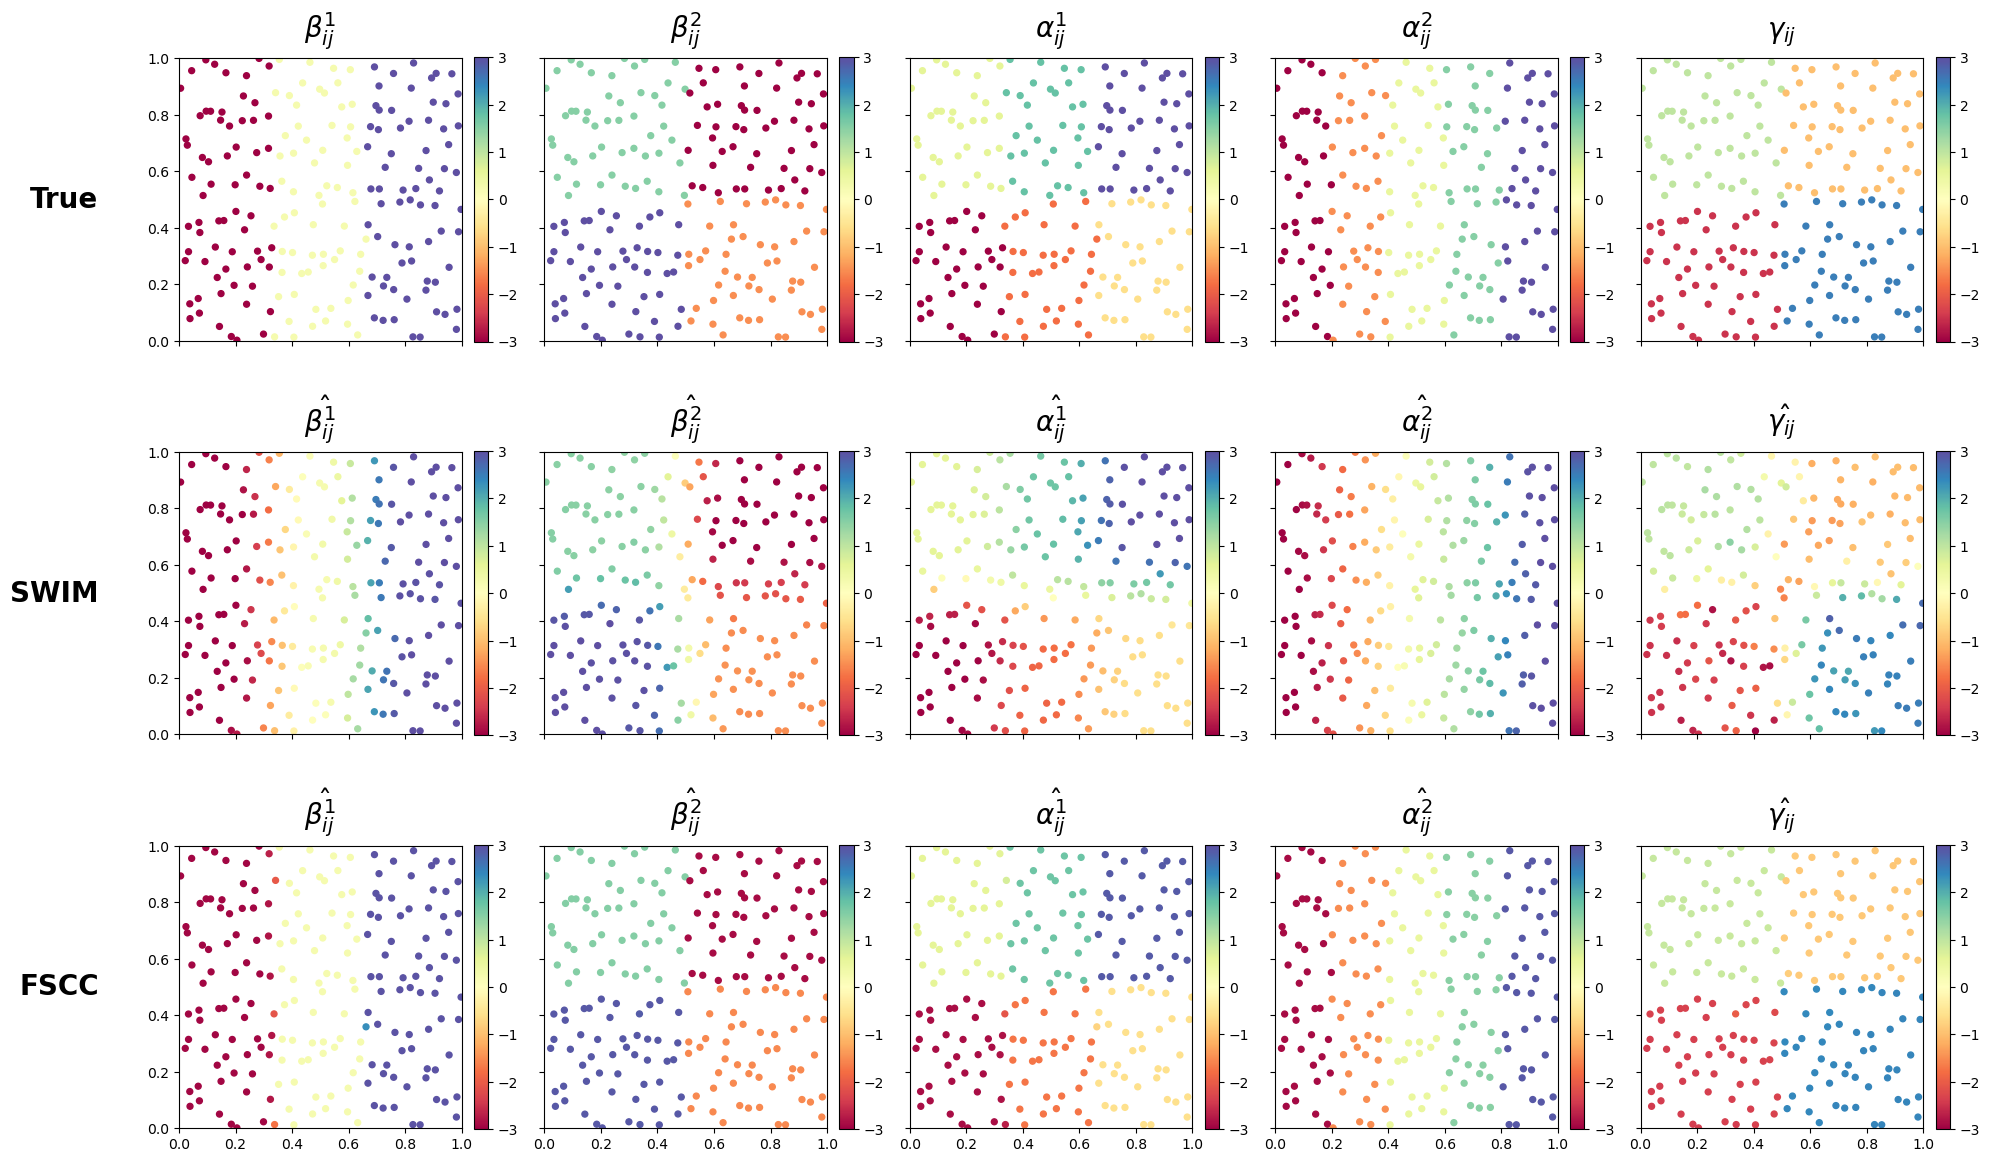


1. MODEL FIT: R2 AND MSE
Method                  R2                 MSE
  SWIM 0.952173 ± 0.000209 1.037661 ± 0.007836
  FSCC 0.998220 ± 0.000009 0.038619 ± 0.000109

2. SPATIAL PARTITION RECOVERY: FSCC FUSION RAND INDEX (SWIM N/A)
Method            RI_BETA1            RI_BETA2           RI_ALPHA1           RI_ALPHA2            RI_GAMMA
  SWIM                 nan                 nan                 nan                 nan                 nan
  FSCC 0.963865 ± 0.000058 0.999201 ± 0.000147 0.978153 ± 0.003003 0.962135 ± 0.007556 0.801707 ± 0.003855

3. ADJUSTED RAND INDEX: FSCC FUSION GROUPS
Method           ARI_BETA1           ARI_BETA2          ARI_ALPHA1          ARI_ALPHA2           ARI_GAMMA
  SWIM                 nan                 nan                 nan                 nan                 nan
  FSCC 0.916837 ± 0.000143 0.997867 ± 0.000393 0.918352 ± 0.011986 0.872340 ± 0.027399 0.281176 ± 0.019041

4. TRUE VS ESTIMATED GROUP COUNTS
Method   TRUE_GROUPS_BETA1   TRUE_GROUPS_BETA2

In [3]:
import warnings
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree
import warnings
warnings.filterwarnings("ignore")
n, p, q = (200, 2, 2)
noise_std = 0.1
intercept_true = 1.0
GRID_NEIGHBORHOOD = 'rook'
B = 3
lambda_grid = [0.075, 0.1, 0.125]
max_outer = 60
max_inner = 1000
outer_tol = 0.002
admm_abs_tol = 1e-05
admm_rel_tol = 0.0005
cg_rtol = 1e-08
cg_maxiter = 1500
admm_adapt_interval = 10
admm_balance_mu = 10.0
admm_rho_factor = 2.0
admm_rho_min = 1e-05
admm_rho_max = 100000.0
admm_over_relax = 1.5
df_rel_tol = 0.001
K_SWIM = 100
SWIM_BW_FIXED = 0.105
SWIM_BATCH_SIZE = 1024  # Bound SWIM temporary memory for large n
# A near-square rectangular Rook grid supports n=200 (10x20) and n=300 (15x20).
def choose_grid_shape(num_regions):
    factors = [(r, num_regions // r) for r in range(1, math.isqrt(num_regions) + 1)
               if num_regions % r == 0]
    if not factors:
        raise ValueError('n must be positive')
    return min(factors, key=lambda rc: rc[1] - rc[0])

grid_nrows, grid_ncols = choose_grid_shape(n)
grid_rows = np.repeat(np.arange(grid_nrows, dtype=np.int32), grid_ncols)
grid_cols = np.tile(np.arange(grid_ncols, dtype=np.int32), grid_nrows)
print(f'Region Rook grid: {grid_nrows} x {grid_ncols} = {n} regions')
coord_rng = np.random.default_rng(42)
coords = np.column_stack([(grid_cols + coord_rng.random(n)) / grid_ncols, (grid_rows + coord_rng.random(n)) / grid_nrows]).astype(np.float64)
D_full = cdist(coords, coords).astype(np.float64)
D_PREDICTOR_SCALE = float(np.std(D_full))
if D_PREDICTOR_SCALE <= 1e-12:
    raise ValueError('Distance predictor has zero variance.')
D_model = D_full / D_PREDICTOR_SCALE
beta_piece_sets = [[-3, 0.25, 3], [3, -1.5, 1.5, -3]]
alpha_piece_sets = [[-3, -1.8, -0.6, 0.6, 1.8, 3], [-3, -1.5, 0.5, 1.5, 3]]
gamma_piece_set = [-2.5, 2.5, 1.0, -1.0]

def grid_shape_for_count(count):
    return {3: (1, 3), 4: (2, 2), 5: (1, 5), 6: (2, 3)}[count]

def fill_piecewise_origin(arr3d, coords_, values, feat_idx):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr3d[mask, :, feat_idx] = value

def fill_piecewise_2d(arr2d, coords_, values):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr2d[mask, :] = value
beta0 = np.zeros((n, n, p), dtype=np.float64)
alpha0 = np.zeros((n, n, q), dtype=np.float64)
gamma0 = np.zeros((n, n), dtype=np.float64)
for k in range(p):
    fill_piecewise_origin(beta0, coords, beta_piece_sets[k], k)
for m in range(q):
    fill_piecewise_origin(alpha0, coords, alpha_piece_sets[m], m)
fill_piecewise_2d(gamma0, coords, gamma_piece_set)
edge_u_list = []
edge_v_list = []
for r in range(grid_nrows):
    for c in range(grid_ncols):
        u = r * grid_ncols + c
        if c + 1 < grid_ncols:
            edge_u_list.append(u)
            edge_v_list.append(u + 1)
        if r + 1 < grid_nrows:
            edge_u_list.append(u)
            edge_v_list.append(u + grid_ncols)
edge_u = np.asarray(edge_u_list, dtype=np.int32)
edge_v = np.asarray(edge_v_list, dtype=np.int32)
edge_w = np.ones(len(edge_u), dtype=np.float64)
E = len(edge_u)
N = n * n  # Full-grid indexing for efficient matrix-free ADMM
OD_MASK = ~np.eye(n, dtype=bool)
OD_VALID = OD_MASK.ravel()
N_OBS = int(OD_VALID.sum())  # n*(n-1); exclude i == j everywhere
DIAG_IDX = np.arange(n) * (n + 1)
if E == 0:
    raise RuntimeError('No grid-neighbor edges were constructed.')
A_grid = sp.coo_matrix((np.ones(2 * E, dtype=np.float64), (np.concatenate([edge_u, edge_v]), np.concatenate([edge_v, edge_u]))), shape=(n, n)).tocsr()
A_grid.setdiag(0.0)
A_grid.eliminate_zeros()
if A_grid.nnz and (not np.all(A_grid.data == 1.0)):
    raise RuntimeError('Grid adjacency must be binary: every nonzero entry must equal 1.')
try:
    OUTPUT_DIR = Path(__file__).resolve().parent
except NameError:
    OUTPUT_DIR = Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fixed_origin = np.tile(np.arange(n, dtype=np.int32), E)
u1 = fixed_origin * n + np.repeat(edge_u, n)
v1 = fixed_origin * n + np.repeat(edge_v, n)
w1 = np.repeat(edge_w, n)
fixed_dest = np.tile(np.arange(n, dtype=np.int32), E)
u2 = np.repeat(edge_u, n) * n + fixed_dest
v2 = np.repeat(edge_v, n) * n + fixed_dest
w2 = np.repeat(edge_w, n)
M3 = 2 * E * E
u3 = np.empty(M3, dtype=np.int32)
v3 = np.empty(M3, dtype=np.int32)
mean_region_w = float(np.mean(edge_w))
w3_legacy = np.empty(M3, dtype=np.float64)
write = 0
for e in range(E):
    i1, i2 = (int(edge_u[e]), int(edge_v[e]))
    joint_w = edge_w[e] * edge_w / max(mean_region_w, 1e-12)
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_u
    v3[sl] = i2 * n + edge_v
    w3_legacy[sl] = joint_w
    write += E
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_v
    v3[sl] = i2 * n + edge_u
    w3_legacy[sl] = joint_w
    write += E
assert write == M3
assert np.all(u3 != v3)
# Remove all edges touching any within-region (i == j) OD node.
# Retain full-grid node indexing internally, but diagonal nodes are isolated
# and carry zero data weight, so they cannot influence fitted off-diagonal OD flows.
def remove_diagonal_edges(u, v, w):
    keep = OD_VALID[u] & OD_VALID[v]
    return u[keep], v[keep], w[keep]

u1, v1, w1 = remove_diagonal_edges(u1, v1, w1)
u2, v2, w2 = remove_diagonal_edges(u2, v2, w2)
u3, v3, w3_legacy = remove_diagonal_edges(u3, v3, w3_legacy)
assert all(np.all(OD_VALID[u] & OD_VALID[v]) for u, v in ((u1, v1), (u2, v2), (u3, v3)))
class3_balance = float(np.sum(w1) / max(np.sum(w3_legacy), 1e-12))
SCENARIOS = {'three_classes_binary_unit_weight': {'u': np.concatenate([u1, u2, u3]), 'v': np.concatenate([v1, v2, v3]), 'w': np.concatenate([w1, w2, w3_legacy]), 'include_class3': True, 'class3_scale': 1.0, 'class_edge_counts': (len(u1), len(u2), len(u3))}}
# Exact masked OD Laplacian: the former Kronecker shortcut assumes a complete
# n*n OD grid and would silently reintroduce diagonal-node connections.
ALL_U = SCENARIOS['three_classes_binary_unit_weight']['u']
ALL_V = SCENARIOS['three_classes_binary_unit_weight']['v']
ALL_W2 = SCENARIOS['three_classes_binary_unit_weight']['w'] ** 2
MASKED_DEGREE = (np.bincount(ALL_U, weights=ALL_W2, minlength=N) +
                 np.bincount(ALL_V, weights=ALL_W2, minlength=N))

def graph_degree_vector(include_class3, class3_scale):
    if not include_class3 or class3_scale != 1.0:
        raise ValueError('Only the configured three-class unit-scale graph is supported.')
    return MASKED_DEGREE

def graph_laplacian_matvec(x_vec, include_class3, class3_scale):
    if not include_class3 or class3_scale != 1.0:
        raise ValueError('Only the configured three-class unit-scale graph is supported.')
    differences = ALL_W2 * (x_vec[ALL_U] - x_vec[ALL_V])
    return (np.bincount(ALL_U, weights=differences, minlength=N) -
            np.bincount(ALL_V, weights=differences, minlength=N))

def admm_fuse(v_vec, X2_vec, rho, edges_u, edges_v, edges_w, penalty_per_edge, include_class3, class3_scale, x_init=None, dual_init=None, maxiter=max_inner):
    if len(edges_u) == 0:
        return (np.asarray(v_vec, dtype=np.float64).copy(), {'iterations': 0, 'primal': 0.0, 'dual': 0.0, 'eps_primal': 0.0, 'eps_dual': 0.0, 'primal_ratio': 0.0, 'dual_ratio': 0.0, 'converged': True, 'cg_nonconverged': 0, 'rho_final': float(rho)})
    v64 = np.asarray(v_vec, dtype=np.float64)
    X2 = np.maximum(np.asarray(X2_vec, dtype=np.float64), 1e-12)
    ew = np.asarray(edges_w, dtype=np.float64)
    pen = np.asarray(penalty_per_edge, dtype=np.float64)
    n_edges = len(edges_u)
    rho = float(rho)
    x = np.asarray(x_init, dtype=np.float64).copy() if x_init is not None else v64.copy()
    dx0 = ew * (x[edges_u] - x[edges_v])
    z = dx0.copy()
    if dual_init is None:
        dual_scaled = np.zeros(n_edges, dtype=np.float64)
    else:
        dual_scaled = np.asarray(dual_init, dtype=np.float64).copy() / max(rho, 1e-15)
    cg_nonconverged = 0
    primal_norm = dual_norm = np.inf
    eps_primal = eps_dual = np.inf
    converged = False
    alpha_relax = float(admm_over_relax)

    cached_degree = graph_degree_vector(include_class3, class3_scale)

    def make_linear_operators(rho_now):

        def matvec_A(x_vec):
            return X2 * x_vec + rho_now * graph_laplacian_matvec(x_vec, include_class3, class3_scale)
        A_op = spla.LinearOperator((N, N), matvec=matvec_A, dtype=np.float64)
        precond_diag = np.maximum(X2 + rho_now * cached_degree, 1e-10)
        M_op = spla.LinearOperator((N, N), matvec=lambda r: r / precond_diag, dtype=np.float64)
        return (A_op, M_op)
    A_op, M_op = make_linear_operators(rho)
    rho_updates = 0
    for it in range(1, maxiter + 1):
        diff_zu = (z - dual_scaled) * ew
        Kt_zu = np.bincount(edges_u, weights=diff_zu, minlength=N) - np.bincount(edges_v, weights=diff_zu, minlength=N)
        rhs = X2 * v64 + rho * Kt_zu
        x_new, cg_info = spla.cg(A_op, rhs, x0=x, M=M_op, rtol=cg_rtol, atol=0.0, maxiter=cg_maxiter)
        if cg_info != 0:
            cg_nonconverged += 1
            if cg_info < 0:
                raise RuntimeError(f'CG breakdown (info={cg_info}).')
        Kx = ew * (x_new[edges_u] - x_new[edges_v])
        z_old = z
        Kx_hat = alpha_relax * Kx + (1.0 - alpha_relax) * z_old
        threshold = pen / max(rho, 1e-15)
        z = np.sign(Kx_hat + dual_scaled) * np.maximum(np.abs(Kx_hat + dual_scaled) - threshold, 0.0)
        dual_scaled += Kx_hat - z
        primal_vec = Kx - z
        primal_norm = float(np.linalg.norm(primal_vec))
        z_change = z - z_old
        Kt_dz = np.bincount(edges_u, weights=ew * z_change, minlength=N) - np.bincount(edges_v, weights=ew * z_change, minlength=N)
        dual_vec = rho * Kt_dz
        dual_norm = float(np.linalg.norm(dual_vec))
        eps_primal = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx), np.linalg.norm(z)))
        Kt_u = np.bincount(edges_u, weights=ew * dual_scaled, minlength=N) - np.bincount(edges_v, weights=ew * dual_scaled, minlength=N)
        eps_dual = float(np.sqrt(N) * admm_abs_tol + admm_rel_tol * rho * np.linalg.norm(Kt_u))
        x = x_new
        if primal_norm <= eps_primal and dual_norm <= eps_dual:
            converged = True
            break
        if it % admm_adapt_interval == 0:
            primal_ratio_now = primal_norm / max(eps_primal, 1e-12)
            dual_ratio_now = dual_norm / max(eps_dual, 1e-12)
            rho_new = rho
            if primal_ratio_now > admm_balance_mu * dual_ratio_now:
                rho_new = min(rho * admm_rho_factor, admm_rho_max)
            elif dual_ratio_now > admm_balance_mu * primal_ratio_now:
                rho_new = max(rho / admm_rho_factor, admm_rho_min)
            if not np.isclose(rho_new, rho):
                dual_scaled *= rho / rho_new
                rho = rho_new
                A_op, M_op = make_linear_operators(rho)
                rho_updates += 1
    Kx_final = ew * (x[edges_u] - x[edges_v])
    final_primal_norm = float(np.linalg.norm(Kx_final - z))
    final_primal_eps = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx_final), np.linalg.norm(z)))
    final_primal_ratio = final_primal_norm / max(final_primal_eps, 1e-12)
    final_dual_ratio = dual_norm / max(eps_dual, 1e-12)
    converged = bool(converged and final_primal_ratio <= 1.0 and (final_dual_ratio <= 1.0))
    info = {'iterations': it, 'primal': final_primal_norm, 'dual': dual_norm, 'eps_primal': final_primal_eps, 'eps_dual': eps_dual, 'primal_ratio': final_primal_ratio, 'dual_ratio': final_dual_ratio, 'converged': converged, 'cg_nonconverged': cg_nonconverged, 'rho_final': rho, 'rho_updates': rho_updates, 'dual_unscaled': rho * dual_scaled}
    return (x.astype(np.float64), info)

def swim_fit_fixed_bw(bw, design, y_flat, idx, dist, ridge=1e-08, batch_size=SWIM_BATCH_SIZE):
    """Batched SWIM local weighted least-squares solves, avoiding a full (n*n, K, features) tensor."""
    n_flows, n_features = design.shape
    coefs = np.empty((n_flows, n_features), dtype=np.float64)
    eye = np.eye(n_features, dtype=np.float64)
    for start in range(0, n_flows, batch_size):
        stop = min(start + batch_size, n_flows)
        neighbors = idx[start:stop]
        weights = np.exp(-0.5 * (dist[start:stop] / max(bw, 1e-12)) ** 2)
        xlocal = design[neighbors]
        ylocal = y_flat[neighbors]
        xtx = np.einsum('bki,bkj,bk->bij', xlocal, xlocal, weights, optimize=True)
        xtx += ridge * eye[None, :, :]
        xty = np.einsum('bki,bk,bk->bi', xlocal, ylocal, weights, optimize=True)
        coefs[start:stop] = np.linalg.solve(xtx, xty[..., None])[..., 0]
    pred = np.einsum('bi,bi->b', design, coefs)
    rss = float(np.sum((y_flat - pred) ** 2))
    return (coefs, pred, rss)

def fscc_fit(lam, beta_init, alpha_init, gamma_init, intercept_init, rho_beta, rho_alpha, rho_gamma, X, Z, D, Y, TSS, scenario):
    beta = beta_init.copy()
    alpha = alpha_init.copy()
    gamma = gamma_init.copy()
    intercept = float(intercept_init)
    eu = scenario['u']
    ev = scenario['v']
    ew = scenario['w']
    include_class3 = scenario['include_class3']
    class3_scale = scenario['class3_scale']
    pen_ba = np.full(len(eu), lam, dtype=np.float64)
    # Gamma uses the same ordinary fusion penalty as beta and alpha.
    pen_g = pen_ba
    max_primal_ratio = 0.0
    max_dual_ratio = 0.0
    max_admm_iterations = 0
    total_admm_not_converged = 0
    total_cg_nonconverged = 0
    max_rho_updates = 0
    min_rho_final = np.inf
    max_rho_final = 0.0
    outer_iterations = 0
    outer_converged = False
    final_outer_change = np.inf
    dual_states = {}
    # Maintain Y - fitted values incrementally rather than rebuilding predictions
    # for every coordinate update. This is algebraically identical to the old loop.
    residual = Y - intercept - np.sum(X * beta, axis=2) - np.sum(Z * alpha, axis=2) - D * gamma
    X2_cache = [np.where(OD_VALID, X[:, :, k].ravel() ** 2, 1.0) for k in range(p)]
    Z2_cache = [np.where(OD_VALID, Z[:, :, m].ravel() ** 2, 1.0) for m in range(q)]
    D2 = np.where(OD_VALID, D.ravel() ** 2 + 1e-12, 1.0)

    def record_diag(diag):
        nonlocal max_primal_ratio, max_dual_ratio, max_admm_iterations
        nonlocal total_admm_not_converged, total_cg_nonconverged
        nonlocal max_rho_updates, min_rho_final, max_rho_final
        max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
        max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
        max_admm_iterations = max(max_admm_iterations, diag['iterations'])
        total_admm_not_converged += int(not diag['converged'])
        total_cg_nonconverged += diag['cg_nonconverged']
        max_rho_updates = max(max_rho_updates, diag['rho_updates'])
        min_rho_final = min(min_rho_final, diag['rho_final'])
        max_rho_final = max(max_rho_final, diag['rho_final'])

    for outer in range(1, max_outer + 1):
        beta_prev = beta.copy()
        alpha_prev = alpha.copy()
        gamma_prev = gamma.copy()
        intercept_prev = intercept
        for k in range(p):
            xk = X[:, :, k]
            old = beta[:, :, k].copy()
            partial_residual = residual + xk * old
            x2 = X2_cache[k]
            v = (xk * partial_residual).ravel() / (x2 + 1e-12)
            new_flat, diag = admm_fuse(v, x2, rho_beta, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('beta', k)))
            dual_states['beta', k] = diag['dual_unscaled']
            beta[:, :, k] = new_flat.reshape(n, n)
            residual += xk * (old - beta[:, :, k])
            record_diag(diag)
        for m in range(q):
            zm = Z[:, :, m]
            old = alpha[:, :, m].copy()
            partial_residual = residual + zm * old
            z2 = Z2_cache[m]
            v = (zm * partial_residual).ravel() / (z2 + 1e-12)
            new_flat, diag = admm_fuse(v, z2, rho_alpha, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('alpha', m)))
            dual_states['alpha', m] = diag['dual_unscaled']
            alpha[:, :, m] = new_flat.reshape(n, n)
            residual += zm * (old - alpha[:, :, m])
            record_diag(diag)
        old = gamma.copy()
        partial_residual = residual + D * old
        v_gamma = (D * partial_residual).ravel() / D2
        new_gamma_flat, diag = admm_fuse(v_gamma, D2, rho_gamma, eu, ev, ew, pen_g,
                                         include_class3, class3_scale,
                                         x_init=old.ravel(), dual_init=dual_states.get(('gamma', 0)))
        dual_states['gamma', 0] = diag['dual_unscaled']
        gamma = new_gamma_flat.reshape(n, n)
        residual += D * (old - gamma)
        record_diag(diag)
        # Residual is Y - (intercept + all local contributions).
        delta_intercept = float(np.mean(residual[OD_MASK]))
        intercept += delta_intercept
        residual -= delta_intercept
        db = np.linalg.norm(beta - beta_prev) / max(np.linalg.norm(beta_prev), 1.0)
        da = np.linalg.norm(alpha - alpha_prev) / max(np.linalg.norm(alpha_prev), 1.0)
        dg = np.linalg.norm(gamma - gamma_prev) / max(np.linalg.norm(gamma_prev), 1.0)
        di = abs(intercept - intercept_prev) / max(abs(intercept_prev), 1.0)
        outer_iterations = outer
        final_outer_change = float(max(db, da, dg, di))
        if final_outer_change < outer_tol:
            outer_converged = True
            break
    prediction = np.full((n, n), intercept, dtype=np.float64)
    for k in range(p):
        prediction += X[:, :, k] * beta[:, :, k]
    for m in range(q):
        prediction += Z[:, :, m] * alpha[:, :, m]
    prediction += D * gamma
    residual = Y - prediction
    rss = float(np.sum(residual[OD_MASK] ** 2))
    r2 = float(1.0 - rss / max(TSS, 1e-12))
    diag_all = {'outer_iterations': outer_iterations, 'outer_converged': outer_converged, 'final_outer_change': final_outer_change, 'max_admm_iterations': max_admm_iterations, 'max_primal_ratio': max_primal_ratio, 'max_dual_ratio': max_dual_ratio, 'admm_subproblems_not_converged': total_admm_not_converged, 'cg_nonconverged_total': total_cg_nonconverged, 'max_rho_updates_per_subproblem': max_rho_updates, 'min_rho_final': 0.0 if not np.isfinite(min_rho_final) else min_rho_final, 'max_rho_final': max_rho_final}
    return (beta, alpha, gamma, intercept, prediction, rss, r2, diag_all)

def fused_component_count(values, eu, ev, tol):
    vals = np.asarray(values, dtype=np.float64).ravel()
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    if not np.any(fused):
        return N_OBS
    rows = np.concatenate([eu[fused], ev[fused]])
    cols = np.concatenate([ev[fused], eu[fused]])
    data = np.ones(len(rows), dtype=np.int8)
    graph = sp.coo_matrix((data, (rows, cols)), shape=(len(vals), len(vals))).tocsr()
    n_comp = connected_components(graph, directed=False, return_labels=False)
    return int(n_comp - n)  # isolated diagonal placeholders are not groups

def compute_effective_df(beta, alpha, gamma, intercept, eu, ev):
    dfs = {}
    for k in range(p):
        tol = max(1e-05, df_rel_tol * float(np.std(beta[:, :, k])))
        dfs[f'df_beta{k + 1}'] = fused_component_count(beta[:, :, k], eu, ev, tol)
    for m in range(q):
        tol = max(1e-05, df_rel_tol * float(np.std(alpha[:, :, m])))
        dfs[f'df_alpha{m + 1}'] = fused_component_count(alpha[:, :, m], eu, ev, tol)
    tol_g = max(1e-05, df_rel_tol * float(np.std(gamma)))
    dfs['df_gamma'] = fused_component_count(gamma, eu, ev, tol_g)
    dfs['df_intercept'] = 1
    dfs['df_total'] = int(sum(dfs.values()))
    return dfs

def fscc_fusion_labels(estimate, eu, ev):
    """Connected components of adjacent OD coefficients fused to numerical tolerance.

    No KMeans and no true group count is used to construct estimated groups.
    """
    vals = np.asarray(estimate, dtype=np.float64).ravel()
    tol = max(1e-5, df_rel_tol * float(np.std(vals)))
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    uu, vv = eu[fused], ev[fused]
    graph = sp.coo_matrix(
        (np.ones(2 * len(uu), dtype=np.int8),
         (np.concatenate([uu, vv]), np.concatenate([vv, uu]))),
        shape=(N, N),
    ).tocsr()
    n_groups, labels = connected_components(graph, directed=False, return_labels=True)
    return labels[OD_VALID], int(n_groups - n)


def coefficient_metrics(beta, alpha, gamma, fusion_edges=None):
    """Evaluate coefficients; FSCC groups come solely from its fusion graph.

    SWIM has no fused-coefficient partition, so its RI/ARI are NA.
    """
    from sklearn.metrics import rand_score, adjusted_rand_score
    surfaces = {
        'beta1': (beta[:, :, 0], beta0[:, :, 0]),
        'beta2': (beta[:, :, 1], beta0[:, :, 1]),
        'alpha1': (alpha[:, :, 0], alpha0[:, :, 0]),
        'alpha2': (alpha[:, :, 1], alpha0[:, :, 1]),
        'gamma': (gamma, gamma0),
    }
    out = {}
    for name, (estimate, true_surface) in surfaces.items():
        out[f'rmse_{name}'] = float(np.sqrt(np.mean((estimate[OD_MASK] - true_surface[OD_MASK]) ** 2)))
        if name == 'gamma':
            out['gamma_origin_average_rmse'] = float(np.sqrt(np.mean((np.nanmean(np.where(OD_MASK, estimate, np.nan), axis=1) - np.nanmean(np.where(OD_MASK, true_surface, np.nan), axis=1)) ** 2)))
            out['gamma_within_origin_sd'] = float(np.mean(np.nanstd(np.where(OD_MASK, estimate, np.nan), axis=1)))
        true_values, true_labels = np.unique(true_surface[OD_MASK], return_inverse=True)
        out[f'true_groups_{name}'] = len(true_values)
        if fusion_edges is None:
            out[f'ri_{name}'] = np.nan
            out[f'ari_{name}'] = np.nan
            out[f'est_groups_{name}'] = np.nan
        else:
            eu, ev = fusion_edges
            estimated_labels, estimated_groups = fscc_fusion_labels(estimate, eu, ev)
            out[f'ri_{name}'] = float(rand_score(true_labels, estimated_labels))
            out[f'ari_{name}'] = float(adjusted_rand_score(true_labels, estimated_labels))
            out[f'est_groups_{name}'] = estimated_groups
    return out
method_metric_rows = []
for rep in range(B):
    seed = 1000 + rep
    np.random.seed(seed)
    X = np.random.randn(n, n, p)
    Z = np.random.randn(n, n, q)
    Y = np.full((n, n), intercept_true, dtype=np.float64)
    for k in range(p):
        Y += X[:, :, k] * beta0[:, :, k]
    for m in range(q):
        Y += Z[:, :, m] * alpha0[:, :, m]
    Y += D_full * gamma0 + noise_std * np.random.randn(n, n)
    X[np.arange(n), np.arange(n), :] = 0.0
    Z[np.arange(n), np.arange(n), :] = 0.0
    Y_mean = float(np.mean(Y[OD_MASK]))
    TSS = float(np.sum((Y[OD_MASK] - Y_mean) ** 2))
    print(f'Replication {rep + 1}/{B}: {N_OBS} inter-region OD flows (diagonal excluded)')
    flow_features = np.column_stack([np.repeat(coords, n, axis=0), np.tile(coords, (n, 1))])[OD_VALID]
    tree = cKDTree(flow_features)
    # Query in batches to avoid large peak memory and improve robustness.
    idx_swim = np.empty((N_OBS, min(K_SWIM, N_OBS)), dtype=np.int32)
    dist_swim = np.empty((N_OBS, min(K_SWIM, N_OBS)), dtype=np.float64)
    for start in range(0, N_OBS, SWIM_BATCH_SIZE):
        stop = min(start + SWIM_BATCH_SIZE, N_OBS)
        dd, ii = tree.query(flow_features[start:stop], k=min(K_SWIM, N_OBS), workers=-1)
        dist_swim[start:stop] = dd
        idx_swim[start:stop] = ii
    design = np.column_stack([X.reshape(N, p), Z.reshape(N, q), D_model.ravel(), np.ones(N)])[OD_VALID]
    y_obs = Y[OD_MASK]
    swim_coef_map, swim_pred, swim_rss = swim_fit_fixed_bw(SWIM_BW_FIXED, design, y_obs, idx_swim, dist_swim)
    swim_map = np.full((n, n, p + q + 2), np.nan, dtype=np.float64)
    swim_map[OD_MASK] = swim_coef_map
    swim_beta = swim_map[:, :, :p]
    swim_alpha = swim_map[:, :, p:p + q]
    swim_gamma = swim_map[:, :, p + q]
    swim_gamma_raw = swim_gamma / D_PREDICTOR_SCALE
    swim_metrics = coefficient_metrics(swim_beta, swim_alpha, swim_gamma_raw)
    swim_mse = swim_rss / N_OBS
    swim_r2 = 1.0 - swim_rss / max(TSS, 1e-12)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'SWIM', 'mse': swim_mse, 'r2': swim_r2, 'intercept_estimate': float(np.nanmean(swim_map[:, :, p + q + 1])), **swim_metrics})
    # Global unweighted OLS initialization for ordinary FSCC (no SWIM pilot).
    # The design uses D_model, matching the scale used by fscc_fit.
    ols_coef, *_ = np.linalg.lstsq(design, y_obs, rcond=None)
    fscc_beta_init = np.broadcast_to(ols_coef[:p], (n, n, p)).copy()
    fscc_alpha_init = np.broadcast_to(ols_coef[p:p + q], (n, n, q)).copy()
    fscc_gamma_init = np.full((n, n), ols_coef[p + q], dtype=np.float64)
    fscc_intercept_init = float(ols_coef[p + q + 1])
    fscc_beta_init[np.arange(n), np.arange(n), :] = 0.0
    fscc_alpha_init[np.arange(n), np.arange(n), :] = 0.0
    fscc_gamma_init[np.arange(n), np.arange(n)] = 0.0
    rho_beta = 1.0
    rho_alpha = 1.0
    rho_gamma = 1.0
    for scenario_name, scenario in SCENARIOS.items():
        scenario_results = []
        eu = scenario['u']
        ev = scenario['v']
        edge_count_scenario = len(eu)
        # Increasing-lambda continuation: first fit starts at OLS; later fits
        # start at the previous solution. Each candidate is still optimized
        # for its own lambda and checked for convergence independently.
        warm_beta, warm_alpha, warm_gamma = fscc_beta_init, fscc_alpha_init, fscc_gamma_init
        warm_intercept = fscc_intercept_init
        for lam in sorted(lambda_grid):
            fit = fscc_fit(lam, warm_beta, warm_alpha, warm_gamma,
                           warm_intercept, rho_beta, rho_alpha, rho_gamma,
                           X, Z, D_model, Y, TSS, scenario)
            beta_hat, alpha_hat, gamma_hat, intercept_hat, pred_hat, rss, r2, admm_diag = fit
            warm_beta, warm_alpha, warm_gamma = beta_hat, alpha_hat, gamma_hat
            warm_intercept = intercept_hat
            df_info = compute_effective_df(beta_hat, alpha_hat, gamma_hat, intercept_hat, eu, ev)
            df = df_info['df_total']
            bic = N_OBS * np.log(rss / N_OBS + 1e-12) + np.log(N_OBS) * df
            if admm_diag['admm_subproblems_not_converged'] == 0 and admm_diag['cg_nonconverged_total'] == 0 and admm_diag['outer_converged']:
                scenario_results.append((bic, lam, fit, df_info, admm_diag))
        if not scenario_results:
            raise RuntimeError(f'No fully converged lambda candidate for scenario {scenario_name}. Do not select BIC from unconverged fits. Increase iteration limits or inspect the primal/dual, CG, and outer-change diagnostics.')
        best = min(scenario_results, key=lambda item: item[0])
        best_bic, best_lam, best_fit, best_df, best_admm = best
        b, a, g, intercept, pred, rss, r2, _ = best_fit
        g_raw = g / D_PREDICTOR_SCALE
        fscc_metrics = coefficient_metrics(b, a, g_raw, fusion_edges=(eu, ev))
        method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'FSCC', 'mse': rss / N_OBS, 'r2': r2, 'intercept_estimate': intercept, 'selected_lambda': best_lam, 'bic': best_bic, **fscc_metrics})
        if rep == B - 1:
            last_swim_beta = swim_beta.copy()
            last_swim_alpha = swim_alpha.copy()
            last_swim_gamma = swim_gamma_raw.copy()
            last_fscc_beta = b.copy()
            last_fscc_alpha = a.copy()
            last_fscc_gamma = g_raw.copy()
method_metrics_df = pd.DataFrame(method_metric_rows)
r2_mse_metrics = ['r2', 'mse']
rand_metrics = ['ri_beta1', 'ri_beta2', 'ri_alpha1', 'ri_alpha2', 'ri_gamma']
ari_metrics = ['ari_beta1', 'ari_beta2', 'ari_alpha1', 'ari_alpha2', 'ari_gamma']
group_metrics = [f'{prefix}_{name}' for prefix in ('true_groups', 'est_groups') for name in ('beta1', 'beta2', 'alpha1', 'alpha2', 'gamma')]
rmse_metrics = ['rmse_beta1', 'rmse_beta2', 'rmse_alpha1', 'rmse_alpha2', 'rmse_gamma']
all_metric_names = r2_mse_metrics + rand_metrics + ari_metrics + group_metrics + rmse_metrics
summary_records = []
for method_name in ['SWIM', 'FSCC']:
    sub = method_metrics_df[method_metrics_df['method'] == method_name]
    rec = {'method': method_name, 'n_replications': int(len(sub))}
    for metric_name in all_metric_names:
        vals = pd.to_numeric(sub[metric_name], errors='coerce').dropna()
        rec[f'{metric_name}_mean'] = float(vals.mean()) if len(vals) else np.nan
        rec[f'{metric_name}_sd'] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
    summary_records.append(rec)
method_summary_df = pd.DataFrame(summary_records)
ordered_columns = ['method', 'n_replications']
for metric_name in all_metric_names:
    ordered_columns.extend([f'{metric_name}_mean', f'{metric_name}_sd'])
method_summary_df = method_summary_df[ordered_columns]
summary_path = OUTPUT_DIR / f'FSCC_performance_{n}.csv'
method_summary_df.to_csv(summary_path, index=False, encoding='utf-8-sig')
def origin_mean_offdiag(arr):
    return np.nanmean(np.where(OD_MASK, arr, np.nan), axis=1)

true_vals = [origin_mean_offdiag(beta0[:, :, k]) for k in range(p)] + [origin_mean_offdiag(alpha0[:, :, m]) for m in range(q)] + [origin_mean_offdiag(gamma0)]
swim_vals = [origin_mean_offdiag(last_swim_beta[:, :, k]) for k in range(p)] + [origin_mean_offdiag(last_swim_alpha[:, :, m]) for m in range(q)] + [origin_mean_offdiag(last_swim_gamma)]
fscc_vals = [origin_mean_offdiag(last_fscc_beta[:, :, k]) for k in range(p)] + [origin_mean_offdiag(last_fscc_alpha[:, :, m]) for m in range(q)] + [origin_mean_offdiag(last_fscc_gamma)]
col_titles = ['$\\beta_{ij}^1$', '$\\beta_{ij}^2$', '$\\alpha_{ij}^1$', '$\\alpha_{ij}^2$', '$\\gamma_{ij}$']
est_titles = ['$\\hat{\\beta_{ij}^1}$', '$\\hat{\\beta_{ij}^2}$', '$\\hat{\\alpha_{ij}^1}$', '$\\hat{\\alpha_{ij}^2}$', '$\\hat{\\gamma_{ij}}$']
row_labels = ['True', 'SWIM', 'FSCC']
vals_list = [true_vals, swim_vals, fscc_vals]
ncols = p + q + 1
fig, axes = plt.subplots(3, ncols, figsize=(4 * ncols, 12), sharex=True, sharey=True)
vmin, vmax = (-3, 3)
for ci, title in enumerate(col_titles):
    for ri, vals in enumerate(vals_list):
        ax = axes[ri, ci]
        sc = ax.scatter(coords[:, 0], coords[:, 1], c=vals[ci], s=18, cmap='Spectral', vmin=vmin, vmax=vmax)
        ax.set_title(title if ri == 0 else est_titles[ci], fontsize=20, pad=15)
        if ri == 0:
            ax.set_title(title, fontsize=20, pad=15)
        if ci == 0:
            ax.set_ylabel(row_labels[ri], fontsize=20, rotation=0, labelpad=35, fontweight='bold', va='center', ha='right')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
final_plot_path = OUTPUT_DIR / f'FSCC_{n}_sim.png'
plt.savefig(final_plot_path, dpi=300, bbox_inches='tight')
plt.show()


def print_metric_section(title, metrics):
    print('\n' + '=' * 76)
    print(title)
    print('=' * 76)
    rows = []
    for _, rec in method_summary_df.iterrows():
        row = {'Method': rec['method']}
        for metric in metrics:
            mean_val = rec[f'{metric}_mean']
            sd_val = rec[f'{metric}_sd']
            row[metric.upper()] = f'{mean_val:.6f} ± {sd_val:.6f}' if pd.notna(sd_val) else f'{mean_val:.6f}'
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))
print_metric_section('1. MODEL FIT: R2 AND MSE', r2_mse_metrics)
print_metric_section('2. SPATIAL PARTITION RECOVERY: FSCC FUSION RAND INDEX (SWIM N/A)', rand_metrics)
print_metric_section('3. ADJUSTED RAND INDEX: FSCC FUSION GROUPS', ari_metrics)
print_metric_section('4. TRUE VS ESTIMATED GROUP COUNTS', group_metrics)
print_metric_section('5. COEFFICIENT ESTIMATION ERROR: RMSE', rmse_metrics)
print('Saved:', summary_path, final_plot_path)

Region Rook grid: 10 x 10 = 100 regions
Replication 1/3: 9900 inter-region OD flows (diagonal excluded)
Replication 2/3: 9900 inter-region OD flows (diagonal excluded)
Replication 3/3: 9900 inter-region OD flows (diagonal excluded)


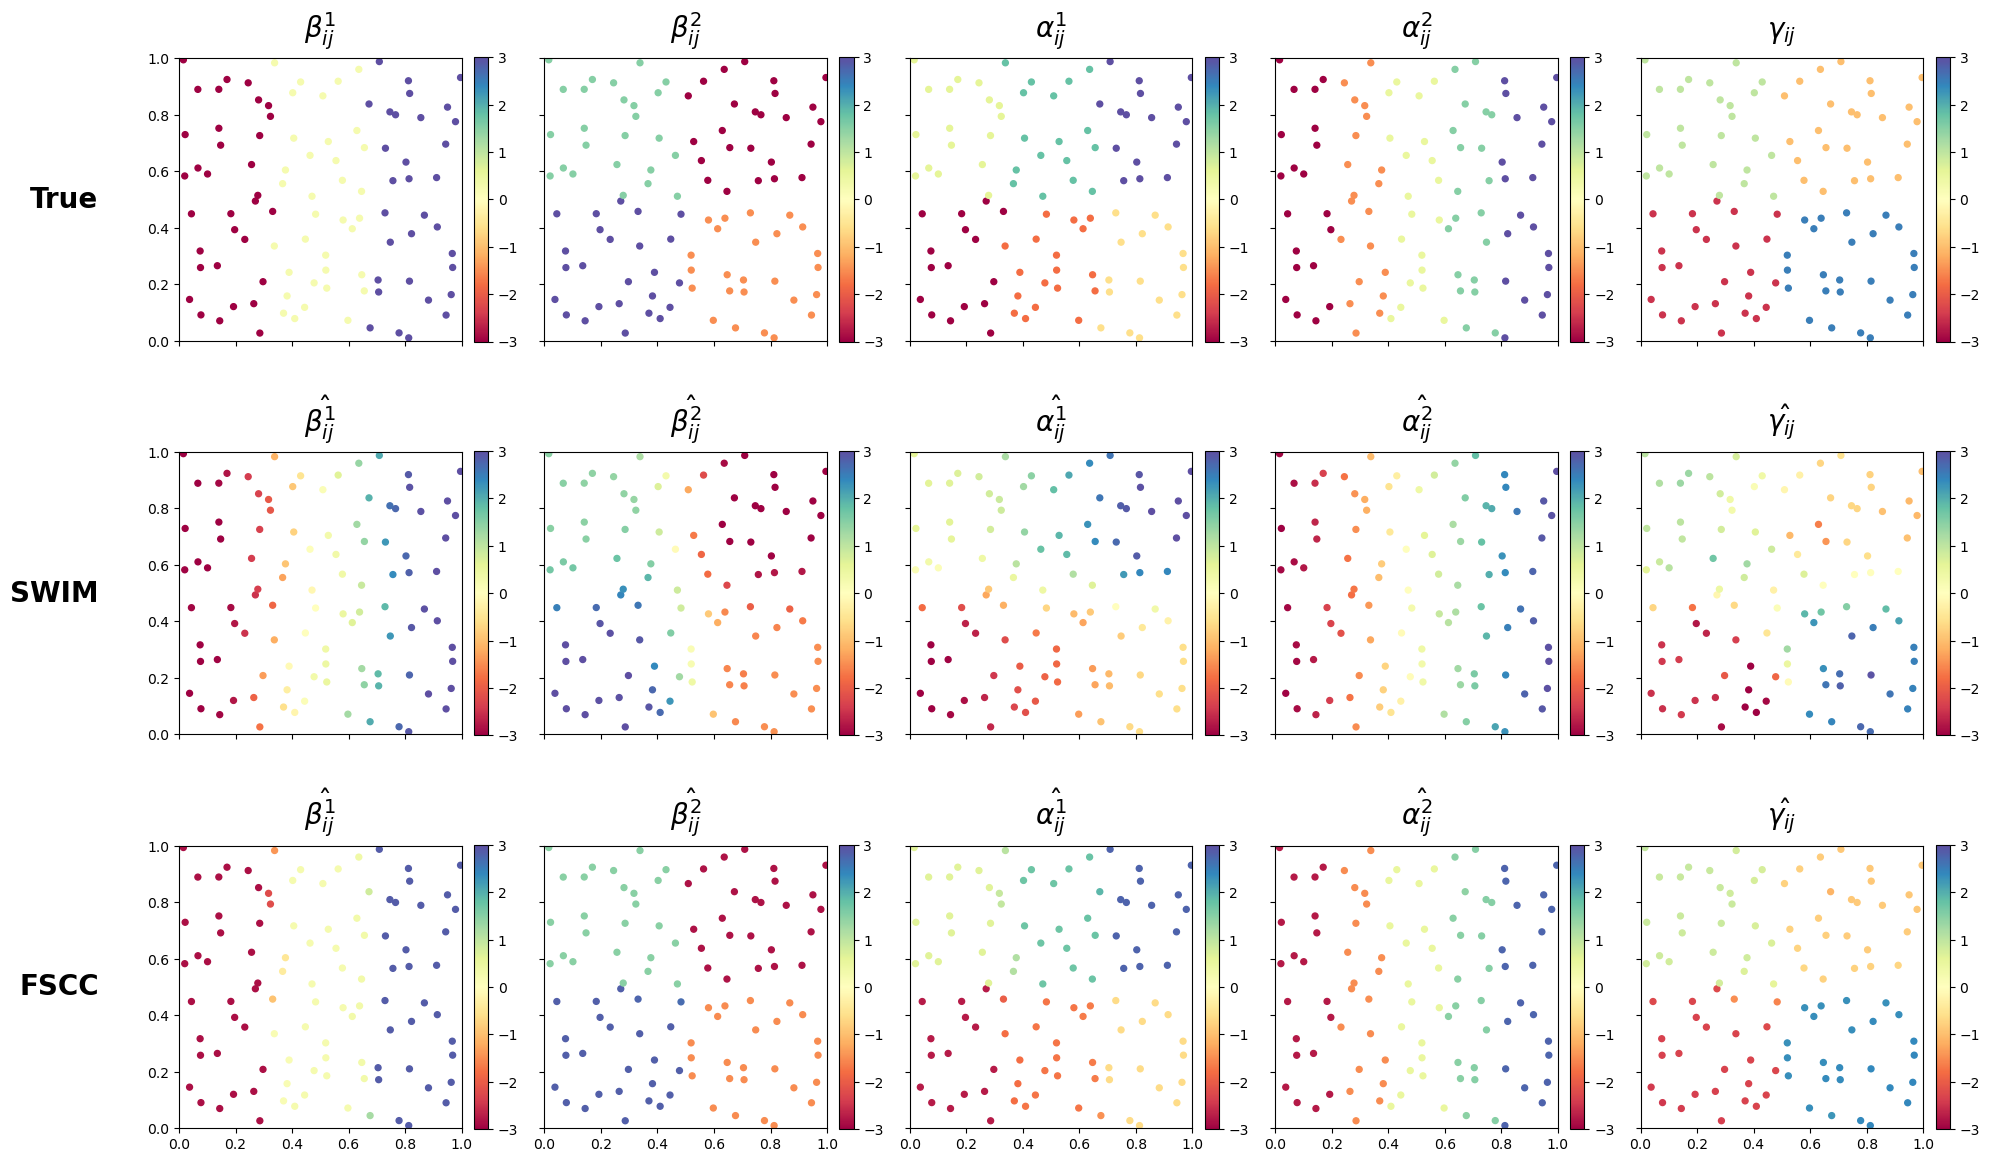


1. MODEL FIT: R2 AND MSE
Method                  R2                 MSE
  SWIM 0.950049 ± 0.000324 1.055519 ± 0.016669
  FSCC 0.996372 ± 0.000083 0.076656 ± 0.000909

2. SPATIAL PARTITION RECOVERY: RI (SWIM POST-HOC / FSCC FUSION)
Method            RI_BETA1            RI_BETA2           RI_ALPHA1           RI_ALPHA2            RI_GAMMA
  SWIM 0.751415 ± 0.000560 0.772812 ± 0.036940 0.707193 ± 0.003893 0.267095 ± 0.006047 0.774662 ± 0.000231
  FSCC 0.877990 ± 0.011110 0.992369 ± 0.002255 0.942715 ± 0.001367 0.949465 ± 0.012171 0.781269 ± 0.001073

3. TRUE VS ESTIMATED GROUP COUNTS
Method   TRUE_GROUPS_BETA1   TRUE_GROUPS_BETA2  TRUE_GROUPS_ALPHA1  TRUE_GROUPS_ALPHA2   TRUE_GROUPS_GAMMA       EST_GROUPS_BETA1       EST_GROUPS_BETA2      EST_GROUPS_ALPHA1      EST_GROUPS_ALPHA2        EST_GROUPS_GAMMA
  SWIM 3.000000 ± 0.000000 4.000000 ± 0.000000 6.000000 ± 0.000000 5.000000 ± 0.000000 4.000000 ± 0.000000 476.333333 ± 64.531646 492.333333 ± 47.289886 495.666667 ± 22.188586 305.333333 ± 

In [4]:
import warnings
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree
import warnings
warnings.filterwarnings("ignore")
n, p, q = (100, 2, 2)
noise_std = 0.1
intercept_true = 1.0
GRID_NEIGHBORHOOD = 'rook'
B = 3
lambda_grid = [0.075, 0.1, 0.125]
max_outer = 60
max_inner = 1000
outer_tol = 0.002
admm_abs_tol = 1e-05
admm_rel_tol = 0.0005
cg_rtol = 1e-08
cg_maxiter = 1500
admm_adapt_interval = 10
admm_balance_mu = 10.0
admm_rho_factor = 2.0
admm_rho_min = 1e-05
admm_rho_max = 100000.0
admm_over_relax = 1.5
df_rel_tol = 0.001
K_SWIM = 100
SWIM_BW_FIXED = 0.105
SWIM_BATCH_SIZE = 1024  # Bound SWIM temporary memory for large n
SWIM_GROUP_REL_TOL = 0.05  # Post-hoc SWIM grouping: 5% of each coefficient surface SD
# A near-square rectangular Rook grid supports n=200 (10x20) and n=300 (15x20).
def choose_grid_shape(num_regions):
    factors = [(r, num_regions // r) for r in range(1, math.isqrt(num_regions) + 1)
               if num_regions % r == 0]
    if not factors:
        raise ValueError('n must be positive')
    return min(factors, key=lambda rc: rc[1] - rc[0])

grid_nrows, grid_ncols = choose_grid_shape(n)
grid_rows = np.repeat(np.arange(grid_nrows, dtype=np.int32), grid_ncols)
grid_cols = np.tile(np.arange(grid_ncols, dtype=np.int32), grid_nrows)
print(f'Region Rook grid: {grid_nrows} x {grid_ncols} = {n} regions')
coord_rng = np.random.default_rng(42)
coords = np.column_stack([(grid_cols + coord_rng.random(n)) / grid_ncols, (grid_rows + coord_rng.random(n)) / grid_nrows]).astype(np.float64)
D_full = cdist(coords, coords).astype(np.float64)
D_PREDICTOR_SCALE = float(np.std(D_full))
if D_PREDICTOR_SCALE <= 1e-12:
    raise ValueError('Distance predictor has zero variance.')
D_model = D_full / D_PREDICTOR_SCALE
beta_piece_sets = [[-3, 0.25, 3], [3, -1.5, 1.5, -3]]
alpha_piece_sets = [[-3, -1.8, -0.6, 0.6, 1.8, 3], [-3, -1.5, 0.5, 1.5, 3]]
gamma_piece_set = [-2.5, 2.5, 1.0, -1.0]

def grid_shape_for_count(count):
    return {3: (1, 3), 4: (2, 2), 5: (1, 5), 6: (2, 3)}[count]

def fill_piecewise_origin(arr3d, coords_, values, feat_idx):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr3d[mask, :, feat_idx] = value

def fill_piecewise_2d(arr2d, coords_, values):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr2d[mask, :] = value
beta0 = np.zeros((n, n, p), dtype=np.float64)
alpha0 = np.zeros((n, n, q), dtype=np.float64)
gamma0 = np.zeros((n, n), dtype=np.float64)
for k in range(p):
    fill_piecewise_origin(beta0, coords, beta_piece_sets[k], k)
for m in range(q):
    fill_piecewise_origin(alpha0, coords, alpha_piece_sets[m], m)
fill_piecewise_2d(gamma0, coords, gamma_piece_set)
edge_u_list = []
edge_v_list = []
for r in range(grid_nrows):
    for c in range(grid_ncols):
        u = r * grid_ncols + c
        if c + 1 < grid_ncols:
            edge_u_list.append(u)
            edge_v_list.append(u + 1)
        if r + 1 < grid_nrows:
            edge_u_list.append(u)
            edge_v_list.append(u + grid_ncols)
edge_u = np.asarray(edge_u_list, dtype=np.int32)
edge_v = np.asarray(edge_v_list, dtype=np.int32)
edge_w = np.ones(len(edge_u), dtype=np.float64)
E = len(edge_u)
N = n * n  # Full-grid indexing for efficient matrix-free ADMM
OD_MASK = ~np.eye(n, dtype=bool)
OD_VALID = OD_MASK.ravel()
N_OBS = int(OD_VALID.sum())  # n*(n-1); exclude i == j everywhere
DIAG_IDX = np.arange(n) * (n + 1)
if E == 0:
    raise RuntimeError('No grid-neighbor edges were constructed.')
A_grid = sp.coo_matrix((np.ones(2 * E, dtype=np.float64), (np.concatenate([edge_u, edge_v]), np.concatenate([edge_v, edge_u]))), shape=(n, n)).tocsr()
A_grid.setdiag(0.0)
A_grid.eliminate_zeros()
if A_grid.nnz and (not np.all(A_grid.data == 1.0)):
    raise RuntimeError('Grid adjacency must be binary: every nonzero entry must equal 1.')
try:
    OUTPUT_DIR = Path(__file__).resolve().parent
except NameError:
    OUTPUT_DIR = Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fixed_origin = np.tile(np.arange(n, dtype=np.int32), E)
u1 = fixed_origin * n + np.repeat(edge_u, n)
v1 = fixed_origin * n + np.repeat(edge_v, n)
w1 = np.repeat(edge_w, n)
fixed_dest = np.tile(np.arange(n, dtype=np.int32), E)
u2 = np.repeat(edge_u, n) * n + fixed_dest
v2 = np.repeat(edge_v, n) * n + fixed_dest
w2 = np.repeat(edge_w, n)
M3 = 2 * E * E
u3 = np.empty(M3, dtype=np.int32)
v3 = np.empty(M3, dtype=np.int32)
mean_region_w = float(np.mean(edge_w))
w3_legacy = np.empty(M3, dtype=np.float64)
write = 0
for e in range(E):
    i1, i2 = (int(edge_u[e]), int(edge_v[e]))
    joint_w = edge_w[e] * edge_w / max(mean_region_w, 1e-12)
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_u
    v3[sl] = i2 * n + edge_v
    w3_legacy[sl] = joint_w
    write += E
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_v
    v3[sl] = i2 * n + edge_u
    w3_legacy[sl] = joint_w
    write += E
assert write == M3
assert np.all(u3 != v3)
# Remove all edges touching any within-region (i == j) OD node.
# Retain full-grid node indexing internally, but diagonal nodes are isolated
# and carry zero data weight, so they cannot influence fitted off-diagonal OD flows.
def remove_diagonal_edges(u, v, w):
    keep = OD_VALID[u] & OD_VALID[v]
    return u[keep], v[keep], w[keep]

u1, v1, w1 = remove_diagonal_edges(u1, v1, w1)
u2, v2, w2 = remove_diagonal_edges(u2, v2, w2)
u3, v3, w3_legacy = remove_diagonal_edges(u3, v3, w3_legacy)
assert all(np.all(OD_VALID[u] & OD_VALID[v]) for u, v in ((u1, v1), (u2, v2), (u3, v3)))
class3_balance = float(np.sum(w1) / max(np.sum(w3_legacy), 1e-12))
SCENARIOS = {'three_classes_binary_unit_weight': {'u': np.concatenate([u1, u2, u3]), 'v': np.concatenate([v1, v2, v3]), 'w': np.concatenate([w1, w2, w3_legacy]), 'include_class3': True, 'class3_scale': 1.0, 'class_edge_counts': (len(u1), len(u2), len(u3))}}
# Exact masked OD Laplacian: the former Kronecker shortcut assumes a complete
# n*n OD grid and would silently reintroduce diagonal-node connections.
ALL_U = SCENARIOS['three_classes_binary_unit_weight']['u']
ALL_V = SCENARIOS['three_classes_binary_unit_weight']['v']
ALL_W2 = SCENARIOS['three_classes_binary_unit_weight']['w'] ** 2
MASKED_DEGREE = (np.bincount(ALL_U, weights=ALL_W2, minlength=N) +
                 np.bincount(ALL_V, weights=ALL_W2, minlength=N))

def graph_degree_vector(include_class3, class3_scale):
    if not include_class3 or class3_scale != 1.0:
        raise ValueError('Only the configured three-class unit-scale graph is supported.')
    return MASKED_DEGREE

def graph_laplacian_matvec(x_vec, include_class3, class3_scale):
    if not include_class3 or class3_scale != 1.0:
        raise ValueError('Only the configured three-class unit-scale graph is supported.')
    differences = ALL_W2 * (x_vec[ALL_U] - x_vec[ALL_V])
    return (np.bincount(ALL_U, weights=differences, minlength=N) -
            np.bincount(ALL_V, weights=differences, minlength=N))

def admm_fuse(v_vec, X2_vec, rho, edges_u, edges_v, edges_w, penalty_per_edge, include_class3, class3_scale, x_init=None, dual_init=None, maxiter=max_inner):
    if len(edges_u) == 0:
        return (np.asarray(v_vec, dtype=np.float64).copy(), {'iterations': 0, 'primal': 0.0, 'dual': 0.0, 'eps_primal': 0.0, 'eps_dual': 0.0, 'primal_ratio': 0.0, 'dual_ratio': 0.0, 'converged': True, 'cg_nonconverged': 0, 'rho_final': float(rho)})
    v64 = np.asarray(v_vec, dtype=np.float64)
    X2 = np.maximum(np.asarray(X2_vec, dtype=np.float64), 1e-12)
    ew = np.asarray(edges_w, dtype=np.float64)
    pen = np.asarray(penalty_per_edge, dtype=np.float64)
    n_edges = len(edges_u)
    rho = float(rho)
    x = np.asarray(x_init, dtype=np.float64).copy() if x_init is not None else v64.copy()
    dx0 = ew * (x[edges_u] - x[edges_v])
    z = dx0.copy()
    if dual_init is None:
        dual_scaled = np.zeros(n_edges, dtype=np.float64)
    else:
        dual_scaled = np.asarray(dual_init, dtype=np.float64).copy() / max(rho, 1e-15)
    cg_nonconverged = 0
    primal_norm = dual_norm = np.inf
    eps_primal = eps_dual = np.inf
    converged = False
    alpha_relax = float(admm_over_relax)

    cached_degree = graph_degree_vector(include_class3, class3_scale)

    def make_linear_operators(rho_now):

        def matvec_A(x_vec):
            return X2 * x_vec + rho_now * graph_laplacian_matvec(x_vec, include_class3, class3_scale)
        A_op = spla.LinearOperator((N, N), matvec=matvec_A, dtype=np.float64)
        precond_diag = np.maximum(X2 + rho_now * cached_degree, 1e-10)
        M_op = spla.LinearOperator((N, N), matvec=lambda r: r / precond_diag, dtype=np.float64)
        return (A_op, M_op)
    A_op, M_op = make_linear_operators(rho)
    rho_updates = 0
    for it in range(1, maxiter + 1):
        diff_zu = (z - dual_scaled) * ew
        Kt_zu = np.bincount(edges_u, weights=diff_zu, minlength=N) - np.bincount(edges_v, weights=diff_zu, minlength=N)
        rhs = X2 * v64 + rho * Kt_zu
        x_new, cg_info = spla.cg(A_op, rhs, x0=x, M=M_op, rtol=cg_rtol, atol=0.0, maxiter=cg_maxiter)
        if cg_info != 0:
            cg_nonconverged += 1
            if cg_info < 0:
                raise RuntimeError(f'CG breakdown (info={cg_info}).')
        Kx = ew * (x_new[edges_u] - x_new[edges_v])
        z_old = z
        Kx_hat = alpha_relax * Kx + (1.0 - alpha_relax) * z_old
        threshold = pen / max(rho, 1e-15)
        z = np.sign(Kx_hat + dual_scaled) * np.maximum(np.abs(Kx_hat + dual_scaled) - threshold, 0.0)
        dual_scaled += Kx_hat - z
        primal_vec = Kx - z
        primal_norm = float(np.linalg.norm(primal_vec))
        z_change = z - z_old
        Kt_dz = np.bincount(edges_u, weights=ew * z_change, minlength=N) - np.bincount(edges_v, weights=ew * z_change, minlength=N)
        dual_vec = rho * Kt_dz
        dual_norm = float(np.linalg.norm(dual_vec))
        eps_primal = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx), np.linalg.norm(z)))
        Kt_u = np.bincount(edges_u, weights=ew * dual_scaled, minlength=N) - np.bincount(edges_v, weights=ew * dual_scaled, minlength=N)
        eps_dual = float(np.sqrt(N) * admm_abs_tol + admm_rel_tol * rho * np.linalg.norm(Kt_u))
        x = x_new
        if primal_norm <= eps_primal and dual_norm <= eps_dual:
            converged = True
            break
        if it % admm_adapt_interval == 0:
            primal_ratio_now = primal_norm / max(eps_primal, 1e-12)
            dual_ratio_now = dual_norm / max(eps_dual, 1e-12)
            rho_new = rho
            if primal_ratio_now > admm_balance_mu * dual_ratio_now:
                rho_new = min(rho * admm_rho_factor, admm_rho_max)
            elif dual_ratio_now > admm_balance_mu * primal_ratio_now:
                rho_new = max(rho / admm_rho_factor, admm_rho_min)
            if not np.isclose(rho_new, rho):
                dual_scaled *= rho / rho_new
                rho = rho_new
                A_op, M_op = make_linear_operators(rho)
                rho_updates += 1
    Kx_final = ew * (x[edges_u] - x[edges_v])
    final_primal_norm = float(np.linalg.norm(Kx_final - z))
    final_primal_eps = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx_final), np.linalg.norm(z)))
    final_primal_ratio = final_primal_norm / max(final_primal_eps, 1e-12)
    final_dual_ratio = dual_norm / max(eps_dual, 1e-12)
    converged = bool(converged and final_primal_ratio <= 1.0 and (final_dual_ratio <= 1.0))
    info = {'iterations': it, 'primal': final_primal_norm, 'dual': dual_norm, 'eps_primal': final_primal_eps, 'eps_dual': eps_dual, 'primal_ratio': final_primal_ratio, 'dual_ratio': final_dual_ratio, 'converged': converged, 'cg_nonconverged': cg_nonconverged, 'rho_final': rho, 'rho_updates': rho_updates, 'dual_unscaled': rho * dual_scaled}
    return (x.astype(np.float64), info)

def swim_fit_fixed_bw(bw, design, y_flat, idx, dist, ridge=1e-08, batch_size=SWIM_BATCH_SIZE):
    """Batched SWIM local weighted least-squares solves, avoiding a full (n*n, K, features) tensor."""
    n_flows, n_features = design.shape
    coefs = np.empty((n_flows, n_features), dtype=np.float64)
    eye = np.eye(n_features, dtype=np.float64)
    for start in range(0, n_flows, batch_size):
        stop = min(start + batch_size, n_flows)
        neighbors = idx[start:stop]
        weights = np.exp(-0.5 * (dist[start:stop] / max(bw, 1e-12)) ** 2)
        xlocal = design[neighbors]
        ylocal = y_flat[neighbors]
        xtx = np.einsum('bki,bkj,bk->bij', xlocal, xlocal, weights, optimize=True)
        xtx += ridge * eye[None, :, :]
        xty = np.einsum('bki,bk,bk->bi', xlocal, ylocal, weights, optimize=True)
        coefs[start:stop] = np.linalg.solve(xtx, xty[..., None])[..., 0]
    pred = np.einsum('bi,bi->b', design, coefs)
    rss = float(np.sum((y_flat - pred) ** 2))
    return (coefs, pred, rss)

def fscc_fit(lam, beta_init, alpha_init, gamma_init, intercept_init, rho_beta, rho_alpha, rho_gamma, X, Z, D, Y, TSS, scenario):
    beta = beta_init.copy()
    alpha = alpha_init.copy()
    gamma = gamma_init.copy()
    intercept = float(intercept_init)
    eu = scenario['u']
    ev = scenario['v']
    ew = scenario['w']
    include_class3 = scenario['include_class3']
    class3_scale = scenario['class3_scale']
    pen_ba = np.full(len(eu), lam, dtype=np.float64)
    # Gamma uses the same ordinary fusion penalty as beta and alpha.
    pen_g = pen_ba
    max_primal_ratio = 0.0
    max_dual_ratio = 0.0
    max_admm_iterations = 0
    total_admm_not_converged = 0
    total_cg_nonconverged = 0
    max_rho_updates = 0
    min_rho_final = np.inf
    max_rho_final = 0.0
    outer_iterations = 0
    outer_converged = False
    final_outer_change = np.inf
    dual_states = {}
    # Maintain Y - fitted values incrementally rather than rebuilding predictions
    # for every coordinate update. This is algebraically identical to the old loop.
    residual = Y - intercept - np.sum(X * beta, axis=2) - np.sum(Z * alpha, axis=2) - D * gamma
    X2_cache = [np.where(OD_VALID, X[:, :, k].ravel() ** 2, 1.0) for k in range(p)]
    Z2_cache = [np.where(OD_VALID, Z[:, :, m].ravel() ** 2, 1.0) for m in range(q)]
    D2 = np.where(OD_VALID, D.ravel() ** 2 + 1e-12, 1.0)

    def record_diag(diag):
        nonlocal max_primal_ratio, max_dual_ratio, max_admm_iterations
        nonlocal total_admm_not_converged, total_cg_nonconverged
        nonlocal max_rho_updates, min_rho_final, max_rho_final
        max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
        max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
        max_admm_iterations = max(max_admm_iterations, diag['iterations'])
        total_admm_not_converged += int(not diag['converged'])
        total_cg_nonconverged += diag['cg_nonconverged']
        max_rho_updates = max(max_rho_updates, diag['rho_updates'])
        min_rho_final = min(min_rho_final, diag['rho_final'])
        max_rho_final = max(max_rho_final, diag['rho_final'])

    for outer in range(1, max_outer + 1):
        beta_prev = beta.copy()
        alpha_prev = alpha.copy()
        gamma_prev = gamma.copy()
        intercept_prev = intercept
        for k in range(p):
            xk = X[:, :, k]
            old = beta[:, :, k].copy()
            partial_residual = residual + xk * old
            x2 = X2_cache[k]
            v = (xk * partial_residual).ravel() / (x2 + 1e-12)
            new_flat, diag = admm_fuse(v, x2, rho_beta, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('beta', k)))
            dual_states['beta', k] = diag['dual_unscaled']
            beta[:, :, k] = new_flat.reshape(n, n)
            residual += xk * (old - beta[:, :, k])
            record_diag(diag)
        for m in range(q):
            zm = Z[:, :, m]
            old = alpha[:, :, m].copy()
            partial_residual = residual + zm * old
            z2 = Z2_cache[m]
            v = (zm * partial_residual).ravel() / (z2 + 1e-12)
            new_flat, diag = admm_fuse(v, z2, rho_alpha, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('alpha', m)))
            dual_states['alpha', m] = diag['dual_unscaled']
            alpha[:, :, m] = new_flat.reshape(n, n)
            residual += zm * (old - alpha[:, :, m])
            record_diag(diag)
        old = gamma.copy()
        partial_residual = residual + D * old
        v_gamma = (D * partial_residual).ravel() / D2
        new_gamma_flat, diag = admm_fuse(v_gamma, D2, rho_gamma, eu, ev, ew, pen_g,
                                         include_class3, class3_scale,
                                         x_init=old.ravel(), dual_init=dual_states.get(('gamma', 0)))
        dual_states['gamma', 0] = diag['dual_unscaled']
        gamma = new_gamma_flat.reshape(n, n)
        residual += D * (old - gamma)
        record_diag(diag)
        # Residual is Y - (intercept + all local contributions).
        delta_intercept = float(np.mean(residual[OD_MASK]))
        intercept += delta_intercept
        residual -= delta_intercept
        db = np.linalg.norm(beta - beta_prev) / max(np.linalg.norm(beta_prev), 1.0)
        da = np.linalg.norm(alpha - alpha_prev) / max(np.linalg.norm(alpha_prev), 1.0)
        dg = np.linalg.norm(gamma - gamma_prev) / max(np.linalg.norm(gamma_prev), 1.0)
        di = abs(intercept - intercept_prev) / max(abs(intercept_prev), 1.0)
        outer_iterations = outer
        final_outer_change = float(max(db, da, dg, di))
        if final_outer_change < outer_tol:
            outer_converged = True
            break
    prediction = np.full((n, n), intercept, dtype=np.float64)
    for k in range(p):
        prediction += X[:, :, k] * beta[:, :, k]
    for m in range(q):
        prediction += Z[:, :, m] * alpha[:, :, m]
    prediction += D * gamma
    residual = Y - prediction
    rss = float(np.sum(residual[OD_MASK] ** 2))
    r2 = float(1.0 - rss / max(TSS, 1e-12))
    diag_all = {'outer_iterations': outer_iterations, 'outer_converged': outer_converged, 'final_outer_change': final_outer_change, 'max_admm_iterations': max_admm_iterations, 'max_primal_ratio': max_primal_ratio, 'max_dual_ratio': max_dual_ratio, 'admm_subproblems_not_converged': total_admm_not_converged, 'cg_nonconverged_total': total_cg_nonconverged, 'max_rho_updates_per_subproblem': max_rho_updates, 'min_rho_final': 0.0 if not np.isfinite(min_rho_final) else min_rho_final, 'max_rho_final': max_rho_final}
    return (beta, alpha, gamma, intercept, prediction, rss, r2, diag_all)

def fused_component_count(values, eu, ev, tol):
    vals = np.asarray(values, dtype=np.float64).ravel()
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    if not np.any(fused):
        return N_OBS
    rows = np.concatenate([eu[fused], ev[fused]])
    cols = np.concatenate([ev[fused], eu[fused]])
    data = np.ones(len(rows), dtype=np.int8)
    graph = sp.coo_matrix((data, (rows, cols)), shape=(len(vals), len(vals))).tocsr()
    n_comp = connected_components(graph, directed=False, return_labels=False)
    return int(n_comp - n)  # isolated diagonal placeholders are not groups

def compute_effective_df(beta, alpha, gamma, intercept, eu, ev):
    dfs = {}
    for k in range(p):
        tol = max(1e-05, df_rel_tol * float(np.std(beta[:, :, k])))
        dfs[f'df_beta{k + 1}'] = fused_component_count(beta[:, :, k], eu, ev, tol)
    for m in range(q):
        tol = max(1e-05, df_rel_tol * float(np.std(alpha[:, :, m])))
        dfs[f'df_alpha{m + 1}'] = fused_component_count(alpha[:, :, m], eu, ev, tol)
    tol_g = max(1e-05, df_rel_tol * float(np.std(gamma)))
    dfs['df_gamma'] = fused_component_count(gamma, eu, ev, tol_g)
    dfs['df_intercept'] = 1
    dfs['df_total'] = int(sum(dfs.values()))
    return dfs

def fscc_fusion_labels(estimate, eu, ev):
    """Connected components of adjacent OD coefficients fused to numerical tolerance.

    No KMeans and no true group count is used to construct estimated groups.
    """
    vals = np.asarray(estimate, dtype=np.float64).ravel()
    tol = max(1e-5, df_rel_tol * float(np.std(vals)))
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    uu, vv = eu[fused], ev[fused]
    graph = sp.coo_matrix(
        (np.ones(2 * len(uu), dtype=np.int8),
         (np.concatenate([uu, vv]), np.concatenate([vv, uu]))),
        shape=(N, N),
    ).tocsr()
    n_groups, labels = connected_components(graph, directed=False, return_labels=True)
    return labels[OD_VALID], int(n_groups - n)



def swim_spatial_group_labels(estimate, eu, ev):
    """Post-hoc SWIM grouping on the same OD graph, without KMeans or true K.

    Adjacent OD flows join when their estimated coefficients differ by at most
    SWIM_GROUP_REL_TOL times the coefficient SD; connected components form groups.
    This is an evaluation-only partition, not a SWIM-native fusion result.
    """
    vals = np.asarray(estimate, dtype=np.float64).ravel()
    valid_vals = vals[OD_VALID]
    if not np.all(np.isfinite(valid_vals)):
        raise ValueError('SWIM contains nonfinite coefficients on valid OD flows.')
    tol = max(1e-5, SWIM_GROUP_REL_TOL * float(np.std(valid_vals)))
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    uu, vv = eu[fused], ev[fused]
    graph = sp.coo_matrix((np.ones(2 * len(uu), dtype=np.int8),
        (np.concatenate([uu, vv]), np.concatenate([vv, uu]))), shape=(N, N)).tocsr()
    n_groups, labels = connected_components(graph, directed=False, return_labels=True)
    return labels[OD_VALID], int(n_groups - n)

def coefficient_metrics(beta, alpha, gamma, fusion_edges=None, swim_edges=None):
    """Evaluate coefficients; FSCC groups come solely from its fusion graph.

    SWIM RI uses post-hoc graph threshold grouping; FSCC is unchanged.
    """
    from sklearn.metrics import rand_score
    surfaces = {
        'beta1': (beta[:, :, 0], beta0[:, :, 0]),
        'beta2': (beta[:, :, 1], beta0[:, :, 1]),
        'alpha1': (alpha[:, :, 0], alpha0[:, :, 0]),
        'alpha2': (alpha[:, :, 1], alpha0[:, :, 1]),
        'gamma': (gamma, gamma0),
    }
    out = {}
    for name, (estimate, true_surface) in surfaces.items():
        out[f'rmse_{name}'] = float(np.sqrt(np.mean((estimate[OD_MASK] - true_surface[OD_MASK]) ** 2)))
        if name == 'gamma':
            out['gamma_origin_average_rmse'] = float(np.sqrt(np.mean((np.nanmean(np.where(OD_MASK, estimate, np.nan), axis=1) - np.nanmean(np.where(OD_MASK, true_surface, np.nan), axis=1)) ** 2)))
            out['gamma_within_origin_sd'] = float(np.mean(np.nanstd(np.where(OD_MASK, estimate, np.nan), axis=1)))
        true_values, true_labels = np.unique(true_surface[OD_MASK], return_inverse=True)
        out[f'true_groups_{name}'] = len(true_values)
        if fusion_edges is not None:
            eu, ev = fusion_edges
            estimated_labels, estimated_groups = fscc_fusion_labels(estimate, eu, ev)
        elif swim_edges is not None:
            eu, ev = swim_edges
            estimated_labels, estimated_groups = swim_spatial_group_labels(estimate, eu, ev)
        else:
            raise ValueError('Provide fusion_edges for FSCC or swim_edges for SWIM.')
        out[f'ri_{name}'] = float(rand_score(true_labels, estimated_labels))
        out[f'est_groups_{name}'] = estimated_groups
    return out
method_metric_rows = []
for rep in range(B):
    seed = 1000 + rep
    np.random.seed(seed)
    X = np.random.randn(n, n, p)
    Z = np.random.randn(n, n, q)
    Y = np.full((n, n), intercept_true, dtype=np.float64)
    for k in range(p):
        Y += X[:, :, k] * beta0[:, :, k]
    for m in range(q):
        Y += Z[:, :, m] * alpha0[:, :, m]
    Y += D_full * gamma0 + noise_std * np.random.randn(n, n)
    X[np.arange(n), np.arange(n), :] = 0.0
    Z[np.arange(n), np.arange(n), :] = 0.0
    Y_mean = float(np.mean(Y[OD_MASK]))
    TSS = float(np.sum((Y[OD_MASK] - Y_mean) ** 2))
    print(f'Replication {rep + 1}/{B}: {N_OBS} inter-region OD flows (diagonal excluded)')
    flow_features = np.column_stack([np.repeat(coords, n, axis=0), np.tile(coords, (n, 1))])[OD_VALID]
    tree = cKDTree(flow_features)
    # Query in batches to avoid large peak memory and improve robustness.
    idx_swim = np.empty((N_OBS, min(K_SWIM, N_OBS)), dtype=np.int32)
    dist_swim = np.empty((N_OBS, min(K_SWIM, N_OBS)), dtype=np.float64)
    for start in range(0, N_OBS, SWIM_BATCH_SIZE):
        stop = min(start + SWIM_BATCH_SIZE, N_OBS)
        dd, ii = tree.query(flow_features[start:stop], k=min(K_SWIM, N_OBS), workers=-1)
        dist_swim[start:stop] = dd
        idx_swim[start:stop] = ii
    design = np.column_stack([X.reshape(N, p), Z.reshape(N, q), D_model.ravel(), np.ones(N)])[OD_VALID]
    y_obs = Y[OD_MASK]
    swim_coef_map, swim_pred, swim_rss = swim_fit_fixed_bw(SWIM_BW_FIXED, design, y_obs, idx_swim, dist_swim)
    swim_map = np.full((n, n, p + q + 2), np.nan, dtype=np.float64)
    swim_map[OD_MASK] = swim_coef_map
    swim_beta = swim_map[:, :, :p]
    swim_alpha = swim_map[:, :, p:p + q]
    swim_gamma = swim_map[:, :, p + q]
    swim_gamma_raw = swim_gamma / D_PREDICTOR_SCALE
    swim_metrics = coefficient_metrics(swim_beta, swim_alpha, swim_gamma_raw, swim_edges=(SCENARIOS['three_classes_binary_unit_weight']['u'], SCENARIOS['three_classes_binary_unit_weight']['v']))
    swim_mse = swim_rss / N_OBS
    swim_r2 = 1.0 - swim_rss / max(TSS, 1e-12)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'SWIM', 'mse': swim_mse, 'r2': swim_r2, 'intercept_estimate': float(np.nanmean(swim_map[:, :, p + q + 1])), **swim_metrics})
    # Global unweighted OLS initialization for ordinary FSCC (no SWIM pilot).
    # The design uses D_model, matching the scale used by fscc_fit.
    ols_coef, *_ = np.linalg.lstsq(design, y_obs, rcond=None)
    fscc_beta_init = np.broadcast_to(ols_coef[:p], (n, n, p)).copy()
    fscc_alpha_init = np.broadcast_to(ols_coef[p:p + q], (n, n, q)).copy()
    fscc_gamma_init = np.full((n, n), ols_coef[p + q], dtype=np.float64)
    fscc_intercept_init = float(ols_coef[p + q + 1])
    fscc_beta_init[np.arange(n), np.arange(n), :] = 0.0
    fscc_alpha_init[np.arange(n), np.arange(n), :] = 0.0
    fscc_gamma_init[np.arange(n), np.arange(n)] = 0.0
    rho_beta = 1.0
    rho_alpha = 1.0
    rho_gamma = 1.0
    for scenario_name, scenario in SCENARIOS.items():
        scenario_results = []
        eu = scenario['u']
        ev = scenario['v']
        edge_count_scenario = len(eu)
        # Increasing-lambda continuation: first fit starts at OLS; later fits
        # start at the previous solution. Each candidate is still optimized
        # for its own lambda and checked for convergence independently.
        warm_beta, warm_alpha, warm_gamma = fscc_beta_init, fscc_alpha_init, fscc_gamma_init
        warm_intercept = fscc_intercept_init
        for lam in sorted(lambda_grid):
            fit = fscc_fit(lam, warm_beta, warm_alpha, warm_gamma,
                           warm_intercept, rho_beta, rho_alpha, rho_gamma,
                           X, Z, D_model, Y, TSS, scenario)
            beta_hat, alpha_hat, gamma_hat, intercept_hat, pred_hat, rss, r2, admm_diag = fit
            warm_beta, warm_alpha, warm_gamma = beta_hat, alpha_hat, gamma_hat
            warm_intercept = intercept_hat
            df_info = compute_effective_df(beta_hat, alpha_hat, gamma_hat, intercept_hat, eu, ev)
            df = df_info['df_total']
            bic = N_OBS * np.log(rss / N_OBS + 1e-12) + np.log(N_OBS) * df
            if admm_diag['admm_subproblems_not_converged'] == 0 and admm_diag['cg_nonconverged_total'] == 0 and admm_diag['outer_converged']:
                scenario_results.append((bic, lam, fit, df_info, admm_diag))
        if not scenario_results:
            raise RuntimeError(f'No fully converged lambda candidate for scenario {scenario_name}. Do not select BIC from unconverged fits. Increase iteration limits or inspect the primal/dual, CG, and outer-change diagnostics.')
        best = min(scenario_results, key=lambda item: item[0])
        best_bic, best_lam, best_fit, best_df, best_admm = best
        b, a, g, intercept, pred, rss, r2, _ = best_fit
        g_raw = g / D_PREDICTOR_SCALE
        fscc_metrics = coefficient_metrics(b, a, g_raw, fusion_edges=(eu, ev))
        method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'FSCC', 'mse': rss / N_OBS, 'r2': r2, 'intercept_estimate': intercept, 'selected_lambda': best_lam, 'bic': best_bic, **fscc_metrics})
        if rep == B - 1:
            last_swim_beta = swim_beta.copy()
            last_swim_alpha = swim_alpha.copy()
            last_swim_gamma = swim_gamma_raw.copy()
            last_fscc_beta = b.copy()
            last_fscc_alpha = a.copy()
            last_fscc_gamma = g_raw.copy()
method_metrics_df = pd.DataFrame(method_metric_rows)
r2_mse_metrics = ['r2', 'mse']
rand_metrics = ['ri_beta1', 'ri_beta2', 'ri_alpha1', 'ri_alpha2', 'ri_gamma']
group_metrics = [f'{prefix}_{name}' for prefix in ('true_groups', 'est_groups') for name in ('beta1', 'beta2', 'alpha1', 'alpha2', 'gamma')]
rmse_metrics = ['rmse_beta1', 'rmse_beta2', 'rmse_alpha1', 'rmse_alpha2', 'rmse_gamma']
all_metric_names = r2_mse_metrics + rand_metrics + group_metrics + rmse_metrics
summary_records = []
for method_name in ['SWIM', 'FSCC']:
    sub = method_metrics_df[method_metrics_df['method'] == method_name]
    rec = {'method': method_name, 'n_replications': int(len(sub))}
    for metric_name in all_metric_names:
        vals = pd.to_numeric(sub[metric_name], errors='coerce').dropna()
        rec[f'{metric_name}_mean'] = float(vals.mean()) if len(vals) else np.nan
        rec[f'{metric_name}_sd'] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
    summary_records.append(rec)
method_summary_df = pd.DataFrame(summary_records)
ordered_columns = ['method', 'n_replications']
for metric_name in all_metric_names:
    ordered_columns.extend([f'{metric_name}_mean', f'{metric_name}_sd'])
method_summary_df = method_summary_df[ordered_columns]
summary_path = OUTPUT_DIR / f'FSCC_performance_{n}.csv'
method_summary_df.to_csv(summary_path, index=False, encoding='utf-8-sig')
def origin_mean_offdiag(arr):
    return np.nanmean(np.where(OD_MASK, arr, np.nan), axis=1)

true_vals = [origin_mean_offdiag(beta0[:, :, k]) for k in range(p)] + [origin_mean_offdiag(alpha0[:, :, m]) for m in range(q)] + [origin_mean_offdiag(gamma0)]
swim_vals = [origin_mean_offdiag(last_swim_beta[:, :, k]) for k in range(p)] + [origin_mean_offdiag(last_swim_alpha[:, :, m]) for m in range(q)] + [origin_mean_offdiag(last_swim_gamma)]
fscc_vals = [origin_mean_offdiag(last_fscc_beta[:, :, k]) for k in range(p)] + [origin_mean_offdiag(last_fscc_alpha[:, :, m]) for m in range(q)] + [origin_mean_offdiag(last_fscc_gamma)]
col_titles = ['$\\beta_{ij}^1$', '$\\beta_{ij}^2$', '$\\alpha_{ij}^1$', '$\\alpha_{ij}^2$', '$\\gamma_{ij}$']
est_titles = ['$\\hat{\\beta_{ij}^1}$', '$\\hat{\\beta_{ij}^2}$', '$\\hat{\\alpha_{ij}^1}$', '$\\hat{\\alpha_{ij}^2}$', '$\\hat{\\gamma_{ij}}$']
row_labels = ['True', 'SWIM', 'FSCC']
vals_list = [true_vals, swim_vals, fscc_vals]
ncols = p + q + 1
fig, axes = plt.subplots(3, ncols, figsize=(4 * ncols, 12), sharex=True, sharey=True)
vmin, vmax = (-3, 3)
for ci, title in enumerate(col_titles):
    for ri, vals in enumerate(vals_list):
        ax = axes[ri, ci]
        sc = ax.scatter(coords[:, 0], coords[:, 1], c=vals[ci], s=18, cmap='Spectral', vmin=vmin, vmax=vmax)
        ax.set_title(title if ri == 0 else est_titles[ci], fontsize=20, pad=15)
        if ri == 0:
            ax.set_title(title, fontsize=20, pad=15)
        if ci == 0:
            ax.set_ylabel(row_labels[ri], fontsize=20, rotation=0, labelpad=35, fontweight='bold', va='center', ha='right')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
final_plot_path = OUTPUT_DIR / f'FSCC_{n}_sim.png'
plt.savefig(final_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

def print_metric_section(title, metrics):
    print('\n' + '=' * 76)
    print(title)
    print('=' * 76)
    rows = []
    for _, rec in method_summary_df.iterrows():
        row = {'Method': rec['method']}
        for metric in metrics:
            mean_val = rec[f'{metric}_mean']
            sd_val = rec[f'{metric}_sd']
            row[metric.upper()] = f'{mean_val:.6f} ± {sd_val:.6f}' if pd.notna(sd_val) else f'{mean_val:.6f}'
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))
print_metric_section('1. MODEL FIT: R2 AND MSE', r2_mse_metrics)
print_metric_section('2. SPATIAL PARTITION RECOVERY: RI (SWIM POST-HOC / FSCC FUSION)', rand_metrics)
print_metric_section('3. TRUE VS ESTIMATED GROUP COUNTS', group_metrics)
print_metric_section('4. COEFFICIENT ESTIMATION ERROR: RMSE', rmse_metrics)
print('Saved:', summary_path, final_plot_path)

Region Rook grid: 10 x 10 = 100 regions
Replication 1/30: 9900 inter-region OD flows (diagonal excluded)
Replication 2/30: 9900 inter-region OD flows (diagonal excluded)
Replication 3/30: 9900 inter-region OD flows (diagonal excluded)
Replication 4/30: 9900 inter-region OD flows (diagonal excluded)
Replication 5/30: 9900 inter-region OD flows (diagonal excluded)
Replication 6/30: 9900 inter-region OD flows (diagonal excluded)
Replication 7/30: 9900 inter-region OD flows (diagonal excluded)
Replication 8/30: 9900 inter-region OD flows (diagonal excluded)
Replication 9/30: 9900 inter-region OD flows (diagonal excluded)
Replication 10/30: 9900 inter-region OD flows (diagonal excluded)
Replication 11/30: 9900 inter-region OD flows (diagonal excluded)
Replication 12/30: 9900 inter-region OD flows (diagonal excluded)
Replication 13/30: 9900 inter-region OD flows (diagonal excluded)
Replication 14/30: 9900 inter-region OD flows (diagonal excluded)
Replication 15/30: 9900 inter-region OD flows

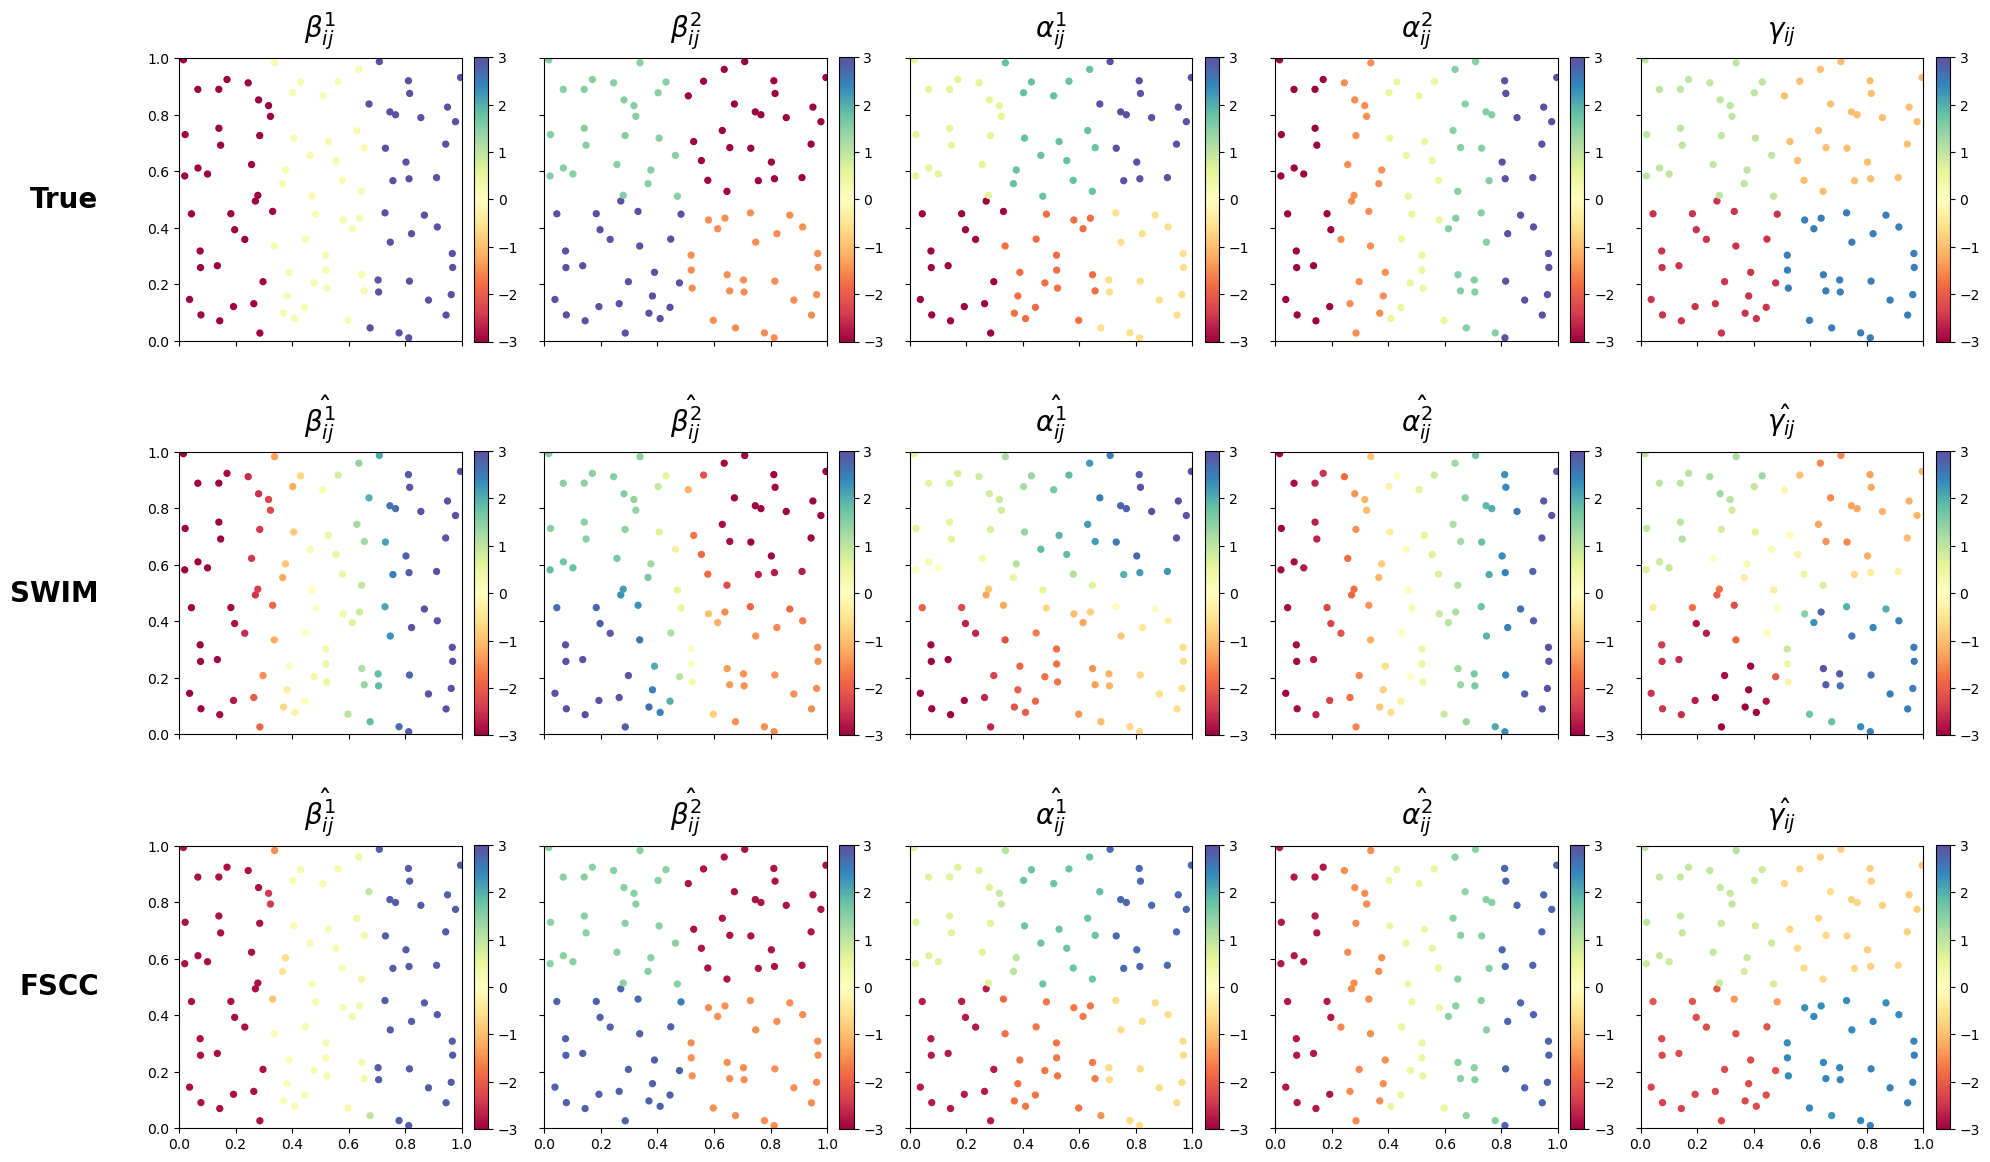


1. MODEL FIT: R2 AND MSE
Method                  R2                 MSE
  SWIM 0.950165 ± 0.001356 1.063483 ± 0.024067
  FSCC 0.996395 ± 0.000107 0.076922 ± 0.001190

2. SPATIAL PARTITION RECOVERY: RI (SWIM POST-HOC / FSCC FUSION)
Method            RI_BETA1            RI_BETA2           RI_ALPHA1           RI_ALPHA2            RI_GAMMA
  SWIM 0.764412 ± 0.042699 0.763623 ± 0.026798 0.705499 ± 0.004214 0.275911 ± 0.012282 0.774141 ± 0.003625
  FSCC 0.883337 ± 0.009951 0.992041 ± 0.000993 0.940473 ± 0.003864 0.958967 ± 0.016698 0.787495 ± 0.006160

3. TRUE VS ESTIMATED GROUP COUNTS
Method   TRUE_GROUPS_BETA1   TRUE_GROUPS_BETA2  TRUE_GROUPS_ALPHA1  TRUE_GROUPS_ALPHA2   TRUE_GROUPS_GAMMA       EST_GROUPS_BETA1       EST_GROUPS_BETA2      EST_GROUPS_ALPHA1      EST_GROUPS_ALPHA2        EST_GROUPS_GAMMA
  SWIM 3.000000 ± 0.000000 4.000000 ± 0.000000 6.000000 ± 0.000000 5.000000 ± 0.000000 4.000000 ± 0.000000 444.966667 ± 36.933756 507.833333 ± 28.242891 515.400000 ± 29.401619 314.733333 ± 

In [6]:
import warnings
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree
import warnings
warnings.filterwarnings("ignore")
n, p, q = (100, 2, 2)
noise_std = 0.1
intercept_true = 1.0
GRID_NEIGHBORHOOD = 'rook'
B = 30
lambda_grid = [0.075, 0.1, 0.125]
max_outer = 60
max_inner = 1000
outer_tol = 0.002
admm_abs_tol = 1e-05
admm_rel_tol = 0.0005
cg_rtol = 1e-08
cg_maxiter = 1500
admm_adapt_interval = 10
admm_balance_mu = 10.0
admm_rho_factor = 2.0
admm_rho_min = 1e-05
admm_rho_max = 100000.0
admm_over_relax = 1.5
df_rel_tol = 0.001
K_SWIM = 100
SWIM_BW_FIXED = 0.105
SWIM_BATCH_SIZE = 1024  # Bound SWIM temporary memory for large n
SWIM_GROUP_REL_TOL = 0.05  # Post-hoc SWIM grouping: 5% of each coefficient surface SD
# A near-square rectangular Rook grid supports n=200 (10x20) and n=300 (15x20).
def choose_grid_shape(num_regions):
    factors = [(r, num_regions // r) for r in range(1, math.isqrt(num_regions) + 1)
               if num_regions % r == 0]
    if not factors:
        raise ValueError('n must be positive')
    return min(factors, key=lambda rc: rc[1] - rc[0])

grid_nrows, grid_ncols = choose_grid_shape(n)
grid_rows = np.repeat(np.arange(grid_nrows, dtype=np.int32), grid_ncols)
grid_cols = np.tile(np.arange(grid_ncols, dtype=np.int32), grid_nrows)
print(f'Region Rook grid: {grid_nrows} x {grid_ncols} = {n} regions')
coord_rng = np.random.default_rng(42)
coords = np.column_stack([(grid_cols + coord_rng.random(n)) / grid_ncols, (grid_rows + coord_rng.random(n)) / grid_nrows]).astype(np.float64)
D_full = cdist(coords, coords).astype(np.float64)
D_PREDICTOR_SCALE = float(np.std(D_full))
if D_PREDICTOR_SCALE <= 1e-12:
    raise ValueError('Distance predictor has zero variance.')
D_model = D_full / D_PREDICTOR_SCALE
beta_piece_sets = [[-3, 0.25, 3], [3, -1.5, 1.5, -3]]
alpha_piece_sets = [[-3, -1.8, -0.6, 0.6, 1.8, 3], [-3, -1.5, 0.5, 1.5, 3]]
gamma_piece_set = [-2.5, 2.5, 1.0, -1.0]

def grid_shape_for_count(count):
    return {3: (1, 3), 4: (2, 2), 5: (1, 5), 6: (2, 3)}[count]

def fill_piecewise_origin(arr3d, coords_, values, feat_idx):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr3d[mask, :, feat_idx] = value

def fill_piecewise_2d(arr2d, coords_, values):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr2d[mask, :] = value
beta0 = np.zeros((n, n, p), dtype=np.float64)
alpha0 = np.zeros((n, n, q), dtype=np.float64)
gamma0 = np.zeros((n, n), dtype=np.float64)
for k in range(p):
    fill_piecewise_origin(beta0, coords, beta_piece_sets[k], k)
for m in range(q):
    fill_piecewise_origin(alpha0, coords, alpha_piece_sets[m], m)
fill_piecewise_2d(gamma0, coords, gamma_piece_set)
edge_u_list = []
edge_v_list = []
for r in range(grid_nrows):
    for c in range(grid_ncols):
        u = r * grid_ncols + c
        if c + 1 < grid_ncols:
            edge_u_list.append(u)
            edge_v_list.append(u + 1)
        if r + 1 < grid_nrows:
            edge_u_list.append(u)
            edge_v_list.append(u + grid_ncols)
edge_u = np.asarray(edge_u_list, dtype=np.int32)
edge_v = np.asarray(edge_v_list, dtype=np.int32)
edge_w = np.ones(len(edge_u), dtype=np.float64)
E = len(edge_u)
N = n * n  # Full-grid indexing for efficient matrix-free ADMM
OD_MASK = ~np.eye(n, dtype=bool)
OD_VALID = OD_MASK.ravel()
N_OBS = int(OD_VALID.sum())  # n*(n-1); exclude i == j everywhere
DIAG_IDX = np.arange(n) * (n + 1)
if E == 0:
    raise RuntimeError('No grid-neighbor edges were constructed.')
A_grid = sp.coo_matrix((np.ones(2 * E, dtype=np.float64), (np.concatenate([edge_u, edge_v]), np.concatenate([edge_v, edge_u]))), shape=(n, n)).tocsr()
A_grid.setdiag(0.0)
A_grid.eliminate_zeros()
if A_grid.nnz and (not np.all(A_grid.data == 1.0)):
    raise RuntimeError('Grid adjacency must be binary: every nonzero entry must equal 1.')
try:
    OUTPUT_DIR = Path(__file__).resolve().parent
except NameError:
    OUTPUT_DIR = Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fixed_origin = np.tile(np.arange(n, dtype=np.int32), E)
u1 = fixed_origin * n + np.repeat(edge_u, n)
v1 = fixed_origin * n + np.repeat(edge_v, n)
w1 = np.repeat(edge_w, n)
fixed_dest = np.tile(np.arange(n, dtype=np.int32), E)
u2 = np.repeat(edge_u, n) * n + fixed_dest
v2 = np.repeat(edge_v, n) * n + fixed_dest
w2 = np.repeat(edge_w, n)
M3 = 2 * E * E
u3 = np.empty(M3, dtype=np.int32)
v3 = np.empty(M3, dtype=np.int32)
mean_region_w = float(np.mean(edge_w))
w3_legacy = np.empty(M3, dtype=np.float64)
write = 0
for e in range(E):
    i1, i2 = (int(edge_u[e]), int(edge_v[e]))
    joint_w = edge_w[e] * edge_w / max(mean_region_w, 1e-12)
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_u
    v3[sl] = i2 * n + edge_v
    w3_legacy[sl] = joint_w
    write += E
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_v
    v3[sl] = i2 * n + edge_u
    w3_legacy[sl] = joint_w
    write += E
assert write == M3
assert np.all(u3 != v3)
# Remove all edges touching any within-region (i == j) OD node.
# Retain full-grid node indexing internally, but diagonal nodes are isolated
# and carry zero data weight, so they cannot influence fitted off-diagonal OD flows.
def remove_diagonal_edges(u, v, w):
    keep = OD_VALID[u] & OD_VALID[v]
    return u[keep], v[keep], w[keep]

u1, v1, w1 = remove_diagonal_edges(u1, v1, w1)
u2, v2, w2 = remove_diagonal_edges(u2, v2, w2)
u3, v3, w3_legacy = remove_diagonal_edges(u3, v3, w3_legacy)
assert all(np.all(OD_VALID[u] & OD_VALID[v]) for u, v in ((u1, v1), (u2, v2), (u3, v3)))
class3_balance = float(np.sum(w1) / max(np.sum(w3_legacy), 1e-12))
SCENARIOS = {'three_classes_binary_unit_weight': {'u': np.concatenate([u1, u2, u3]), 'v': np.concatenate([v1, v2, v3]), 'w': np.concatenate([w1, w2, w3_legacy]), 'include_class3': True, 'class3_scale': 1.0, 'class_edge_counts': (len(u1), len(u2), len(u3))}}
# Exact masked OD Laplacian: the former Kronecker shortcut assumes a complete
# n*n OD grid and would silently reintroduce diagonal-node connections.
ALL_U = SCENARIOS['three_classes_binary_unit_weight']['u']
ALL_V = SCENARIOS['three_classes_binary_unit_weight']['v']
ALL_W2 = SCENARIOS['three_classes_binary_unit_weight']['w'] ** 2
MASKED_DEGREE = (np.bincount(ALL_U, weights=ALL_W2, minlength=N) +
                 np.bincount(ALL_V, weights=ALL_W2, minlength=N))

def graph_degree_vector(include_class3, class3_scale):
    if not include_class3 or class3_scale != 1.0:
        raise ValueError('Only the configured three-class unit-scale graph is supported.')
    return MASKED_DEGREE

def graph_laplacian_matvec(x_vec, include_class3, class3_scale):
    if not include_class3 or class3_scale != 1.0:
        raise ValueError('Only the configured three-class unit-scale graph is supported.')
    differences = ALL_W2 * (x_vec[ALL_U] - x_vec[ALL_V])
    return (np.bincount(ALL_U, weights=differences, minlength=N) -
            np.bincount(ALL_V, weights=differences, minlength=N))

def admm_fuse(v_vec, X2_vec, rho, edges_u, edges_v, edges_w, penalty_per_edge, include_class3, class3_scale, x_init=None, dual_init=None, maxiter=max_inner):
    if len(edges_u) == 0:
        return (np.asarray(v_vec, dtype=np.float64).copy(), {'iterations': 0, 'primal': 0.0, 'dual': 0.0, 'eps_primal': 0.0, 'eps_dual': 0.0, 'primal_ratio': 0.0, 'dual_ratio': 0.0, 'converged': True, 'cg_nonconverged': 0, 'rho_final': float(rho)})
    v64 = np.asarray(v_vec, dtype=np.float64)
    X2 = np.maximum(np.asarray(X2_vec, dtype=np.float64), 1e-12)
    ew = np.asarray(edges_w, dtype=np.float64)
    pen = np.asarray(penalty_per_edge, dtype=np.float64)
    n_edges = len(edges_u)
    rho = float(rho)
    x = np.asarray(x_init, dtype=np.float64).copy() if x_init is not None else v64.copy()
    dx0 = ew * (x[edges_u] - x[edges_v])
    z = dx0.copy()
    if dual_init is None:
        dual_scaled = np.zeros(n_edges, dtype=np.float64)
    else:
        dual_scaled = np.asarray(dual_init, dtype=np.float64).copy() / max(rho, 1e-15)
    cg_nonconverged = 0
    primal_norm = dual_norm = np.inf
    eps_primal = eps_dual = np.inf
    converged = False
    alpha_relax = float(admm_over_relax)

    cached_degree = graph_degree_vector(include_class3, class3_scale)

    def make_linear_operators(rho_now):

        def matvec_A(x_vec):
            return X2 * x_vec + rho_now * graph_laplacian_matvec(x_vec, include_class3, class3_scale)
        A_op = spla.LinearOperator((N, N), matvec=matvec_A, dtype=np.float64)
        precond_diag = np.maximum(X2 + rho_now * cached_degree, 1e-10)
        M_op = spla.LinearOperator((N, N), matvec=lambda r: r / precond_diag, dtype=np.float64)
        return (A_op, M_op)
    A_op, M_op = make_linear_operators(rho)
    rho_updates = 0
    for it in range(1, maxiter + 1):
        diff_zu = (z - dual_scaled) * ew
        Kt_zu = np.bincount(edges_u, weights=diff_zu, minlength=N) - np.bincount(edges_v, weights=diff_zu, minlength=N)
        rhs = X2 * v64 + rho * Kt_zu
        x_new, cg_info = spla.cg(A_op, rhs, x0=x, M=M_op, rtol=cg_rtol, atol=0.0, maxiter=cg_maxiter)
        if cg_info != 0:
            cg_nonconverged += 1
            if cg_info < 0:
                raise RuntimeError(f'CG breakdown (info={cg_info}).')
        Kx = ew * (x_new[edges_u] - x_new[edges_v])
        z_old = z
        Kx_hat = alpha_relax * Kx + (1.0 - alpha_relax) * z_old
        threshold = pen / max(rho, 1e-15)
        z = np.sign(Kx_hat + dual_scaled) * np.maximum(np.abs(Kx_hat + dual_scaled) - threshold, 0.0)
        dual_scaled += Kx_hat - z
        primal_vec = Kx - z
        primal_norm = float(np.linalg.norm(primal_vec))
        z_change = z - z_old
        Kt_dz = np.bincount(edges_u, weights=ew * z_change, minlength=N) - np.bincount(edges_v, weights=ew * z_change, minlength=N)
        dual_vec = rho * Kt_dz
        dual_norm = float(np.linalg.norm(dual_vec))
        eps_primal = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx), np.linalg.norm(z)))
        Kt_u = np.bincount(edges_u, weights=ew * dual_scaled, minlength=N) - np.bincount(edges_v, weights=ew * dual_scaled, minlength=N)
        eps_dual = float(np.sqrt(N) * admm_abs_tol + admm_rel_tol * rho * np.linalg.norm(Kt_u))
        x = x_new
        if primal_norm <= eps_primal and dual_norm <= eps_dual:
            converged = True
            break
        if it % admm_adapt_interval == 0:
            primal_ratio_now = primal_norm / max(eps_primal, 1e-12)
            dual_ratio_now = dual_norm / max(eps_dual, 1e-12)
            rho_new = rho
            if primal_ratio_now > admm_balance_mu * dual_ratio_now:
                rho_new = min(rho * admm_rho_factor, admm_rho_max)
            elif dual_ratio_now > admm_balance_mu * primal_ratio_now:
                rho_new = max(rho / admm_rho_factor, admm_rho_min)
            if not np.isclose(rho_new, rho):
                dual_scaled *= rho / rho_new
                rho = rho_new
                A_op, M_op = make_linear_operators(rho)
                rho_updates += 1
    Kx_final = ew * (x[edges_u] - x[edges_v])
    final_primal_norm = float(np.linalg.norm(Kx_final - z))
    final_primal_eps = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx_final), np.linalg.norm(z)))
    final_primal_ratio = final_primal_norm / max(final_primal_eps, 1e-12)
    final_dual_ratio = dual_norm / max(eps_dual, 1e-12)
    converged = bool(converged and final_primal_ratio <= 1.0 and (final_dual_ratio <= 1.0))
    info = {'iterations': it, 'primal': final_primal_norm, 'dual': dual_norm, 'eps_primal': final_primal_eps, 'eps_dual': eps_dual, 'primal_ratio': final_primal_ratio, 'dual_ratio': final_dual_ratio, 'converged': converged, 'cg_nonconverged': cg_nonconverged, 'rho_final': rho, 'rho_updates': rho_updates, 'dual_unscaled': rho * dual_scaled}
    return (x.astype(np.float64), info)

def swim_fit_fixed_bw(bw, design, y_flat, idx, dist, ridge=1e-08, batch_size=SWIM_BATCH_SIZE):
    """Batched SWIM local weighted least-squares solves, avoiding a full (n*n, K, features) tensor."""
    n_flows, n_features = design.shape
    coefs = np.empty((n_flows, n_features), dtype=np.float64)
    eye = np.eye(n_features, dtype=np.float64)
    for start in range(0, n_flows, batch_size):
        stop = min(start + batch_size, n_flows)
        neighbors = idx[start:stop]
        weights = np.exp(-0.5 * (dist[start:stop] / max(bw, 1e-12)) ** 2)
        xlocal = design[neighbors]
        ylocal = y_flat[neighbors]
        xtx = np.einsum('bki,bkj,bk->bij', xlocal, xlocal, weights, optimize=True)
        xtx += ridge * eye[None, :, :]
        xty = np.einsum('bki,bk,bk->bi', xlocal, ylocal, weights, optimize=True)
        coefs[start:stop] = np.linalg.solve(xtx, xty[..., None])[..., 0]
    pred = np.einsum('bi,bi->b', design, coefs)
    rss = float(np.sum((y_flat - pred) ** 2))
    return (coefs, pred, rss)

def fscc_fit(lam, beta_init, alpha_init, gamma_init, intercept_init, rho_beta, rho_alpha, rho_gamma, X, Z, D, Y, TSS, scenario):
    beta = beta_init.copy()
    alpha = alpha_init.copy()
    gamma = gamma_init.copy()
    intercept = float(intercept_init)
    eu = scenario['u']
    ev = scenario['v']
    ew = scenario['w']
    include_class3 = scenario['include_class3']
    class3_scale = scenario['class3_scale']
    pen_ba = np.full(len(eu), lam, dtype=np.float64)
    # Gamma uses the same ordinary fusion penalty as beta and alpha.
    pen_g = pen_ba
    max_primal_ratio = 0.0
    max_dual_ratio = 0.0
    max_admm_iterations = 0
    total_admm_not_converged = 0
    total_cg_nonconverged = 0
    max_rho_updates = 0
    min_rho_final = np.inf
    max_rho_final = 0.0
    outer_iterations = 0
    outer_converged = False
    final_outer_change = np.inf
    dual_states = {}
    # Maintain Y - fitted values incrementally rather than rebuilding predictions
    # for every coordinate update. This is algebraically identical to the old loop.
    residual = Y - intercept - np.sum(X * beta, axis=2) - np.sum(Z * alpha, axis=2) - D * gamma
    X2_cache = [np.where(OD_VALID, X[:, :, k].ravel() ** 2, 1.0) for k in range(p)]
    Z2_cache = [np.where(OD_VALID, Z[:, :, m].ravel() ** 2, 1.0) for m in range(q)]
    D2 = np.where(OD_VALID, D.ravel() ** 2 + 1e-12, 1.0)

    def record_diag(diag):
        nonlocal max_primal_ratio, max_dual_ratio, max_admm_iterations
        nonlocal total_admm_not_converged, total_cg_nonconverged
        nonlocal max_rho_updates, min_rho_final, max_rho_final
        max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
        max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
        max_admm_iterations = max(max_admm_iterations, diag['iterations'])
        total_admm_not_converged += int(not diag['converged'])
        total_cg_nonconverged += diag['cg_nonconverged']
        max_rho_updates = max(max_rho_updates, diag['rho_updates'])
        min_rho_final = min(min_rho_final, diag['rho_final'])
        max_rho_final = max(max_rho_final, diag['rho_final'])

    for outer in range(1, max_outer + 1):
        beta_prev = beta.copy()
        alpha_prev = alpha.copy()
        gamma_prev = gamma.copy()
        intercept_prev = intercept
        for k in range(p):
            xk = X[:, :, k]
            old = beta[:, :, k].copy()
            partial_residual = residual + xk * old
            x2 = X2_cache[k]
            v = (xk * partial_residual).ravel() / (x2 + 1e-12)
            new_flat, diag = admm_fuse(v, x2, rho_beta, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('beta', k)))
            dual_states['beta', k] = diag['dual_unscaled']
            beta[:, :, k] = new_flat.reshape(n, n)
            residual += xk * (old - beta[:, :, k])
            record_diag(diag)
        for m in range(q):
            zm = Z[:, :, m]
            old = alpha[:, :, m].copy()
            partial_residual = residual + zm * old
            z2 = Z2_cache[m]
            v = (zm * partial_residual).ravel() / (z2 + 1e-12)
            new_flat, diag = admm_fuse(v, z2, rho_alpha, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('alpha', m)))
            dual_states['alpha', m] = diag['dual_unscaled']
            alpha[:, :, m] = new_flat.reshape(n, n)
            residual += zm * (old - alpha[:, :, m])
            record_diag(diag)
        old = gamma.copy()
        partial_residual = residual + D * old
        v_gamma = (D * partial_residual).ravel() / D2
        new_gamma_flat, diag = admm_fuse(v_gamma, D2, rho_gamma, eu, ev, ew, pen_g,
                                         include_class3, class3_scale,
                                         x_init=old.ravel(), dual_init=dual_states.get(('gamma', 0)))
        dual_states['gamma', 0] = diag['dual_unscaled']
        gamma = new_gamma_flat.reshape(n, n)
        residual += D * (old - gamma)
        record_diag(diag)
        # Residual is Y - (intercept + all local contributions).
        delta_intercept = float(np.mean(residual[OD_MASK]))
        intercept += delta_intercept
        residual -= delta_intercept
        db = np.linalg.norm(beta - beta_prev) / max(np.linalg.norm(beta_prev), 1.0)
        da = np.linalg.norm(alpha - alpha_prev) / max(np.linalg.norm(alpha_prev), 1.0)
        dg = np.linalg.norm(gamma - gamma_prev) / max(np.linalg.norm(gamma_prev), 1.0)
        di = abs(intercept - intercept_prev) / max(abs(intercept_prev), 1.0)
        outer_iterations = outer
        final_outer_change = float(max(db, da, dg, di))
        if final_outer_change < outer_tol:
            outer_converged = True
            break
    prediction = np.full((n, n), intercept, dtype=np.float64)
    for k in range(p):
        prediction += X[:, :, k] * beta[:, :, k]
    for m in range(q):
        prediction += Z[:, :, m] * alpha[:, :, m]
    prediction += D * gamma
    residual = Y - prediction
    rss = float(np.sum(residual[OD_MASK] ** 2))
    r2 = float(1.0 - rss / max(TSS, 1e-12))
    diag_all = {'outer_iterations': outer_iterations, 'outer_converged': outer_converged, 'final_outer_change': final_outer_change, 'max_admm_iterations': max_admm_iterations, 'max_primal_ratio': max_primal_ratio, 'max_dual_ratio': max_dual_ratio, 'admm_subproblems_not_converged': total_admm_not_converged, 'cg_nonconverged_total': total_cg_nonconverged, 'max_rho_updates_per_subproblem': max_rho_updates, 'min_rho_final': 0.0 if not np.isfinite(min_rho_final) else min_rho_final, 'max_rho_final': max_rho_final}
    return (beta, alpha, gamma, intercept, prediction, rss, r2, diag_all)

def fused_component_count(values, eu, ev, tol):
    vals = np.asarray(values, dtype=np.float64).ravel()
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    if not np.any(fused):
        return N_OBS
    rows = np.concatenate([eu[fused], ev[fused]])
    cols = np.concatenate([ev[fused], eu[fused]])
    data = np.ones(len(rows), dtype=np.int8)
    graph = sp.coo_matrix((data, (rows, cols)), shape=(len(vals), len(vals))).tocsr()
    n_comp = connected_components(graph, directed=False, return_labels=False)
    return int(n_comp - n)  # isolated diagonal placeholders are not groups

def compute_effective_df(beta, alpha, gamma, intercept, eu, ev):
    dfs = {}
    for k in range(p):
        tol = max(1e-05, df_rel_tol * float(np.std(beta[:, :, k])))
        dfs[f'df_beta{k + 1}'] = fused_component_count(beta[:, :, k], eu, ev, tol)
    for m in range(q):
        tol = max(1e-05, df_rel_tol * float(np.std(alpha[:, :, m])))
        dfs[f'df_alpha{m + 1}'] = fused_component_count(alpha[:, :, m], eu, ev, tol)
    tol_g = max(1e-05, df_rel_tol * float(np.std(gamma)))
    dfs['df_gamma'] = fused_component_count(gamma, eu, ev, tol_g)
    dfs['df_intercept'] = 1
    dfs['df_total'] = int(sum(dfs.values()))
    return dfs

def fscc_fusion_labels(estimate, eu, ev):
    """Connected components of adjacent OD coefficients fused to numerical tolerance.

    No KMeans and no true group count is used to construct estimated groups.
    """
    vals = np.asarray(estimate, dtype=np.float64).ravel()
    tol = max(1e-5, df_rel_tol * float(np.std(vals)))
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    uu, vv = eu[fused], ev[fused]
    graph = sp.coo_matrix(
        (np.ones(2 * len(uu), dtype=np.int8),
         (np.concatenate([uu, vv]), np.concatenate([vv, uu]))),
        shape=(N, N),
    ).tocsr()
    n_groups, labels = connected_components(graph, directed=False, return_labels=True)
    return labels[OD_VALID], int(n_groups - n)



def swim_spatial_group_labels(estimate, eu, ev):
    """Post-hoc SWIM grouping on the same OD graph, without KMeans or true K.

    Adjacent OD flows join when their estimated coefficients differ by at most
    SWIM_GROUP_REL_TOL times the coefficient SD; connected components form groups.
    This is an evaluation-only partition, not a SWIM-native fusion result.
    """
    vals = np.asarray(estimate, dtype=np.float64).ravel()
    valid_vals = vals[OD_VALID]
    if not np.all(np.isfinite(valid_vals)):
        raise ValueError('SWIM contains nonfinite coefficients on valid OD flows.')
    tol = max(1e-5, SWIM_GROUP_REL_TOL * float(np.std(valid_vals)))
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    uu, vv = eu[fused], ev[fused]
    graph = sp.coo_matrix((np.ones(2 * len(uu), dtype=np.int8),
        (np.concatenate([uu, vv]), np.concatenate([vv, uu]))), shape=(N, N)).tocsr()
    n_groups, labels = connected_components(graph, directed=False, return_labels=True)
    return labels[OD_VALID], int(n_groups - n)

def coefficient_metrics(beta, alpha, gamma, fusion_edges=None, swim_edges=None):
    """Evaluate coefficients; FSCC groups come solely from its fusion graph.

    SWIM RI uses post-hoc graph threshold grouping; FSCC is unchanged.
    """
    from sklearn.metrics import rand_score
    surfaces = {
        'beta1': (beta[:, :, 0], beta0[:, :, 0]),
        'beta2': (beta[:, :, 1], beta0[:, :, 1]),
        'alpha1': (alpha[:, :, 0], alpha0[:, :, 0]),
        'alpha2': (alpha[:, :, 1], alpha0[:, :, 1]),
        'gamma': (gamma, gamma0),
    }
    out = {}
    for name, (estimate, true_surface) in surfaces.items():
        out[f'rmse_{name}'] = float(np.sqrt(np.mean((estimate[OD_MASK] - true_surface[OD_MASK]) ** 2)))
        if name == 'gamma':
            out['gamma_origin_average_rmse'] = float(np.sqrt(np.mean((np.nanmean(np.where(OD_MASK, estimate, np.nan), axis=1) - np.nanmean(np.where(OD_MASK, true_surface, np.nan), axis=1)) ** 2)))
            out['gamma_within_origin_sd'] = float(np.mean(np.nanstd(np.where(OD_MASK, estimate, np.nan), axis=1)))
        true_values, true_labels = np.unique(true_surface[OD_MASK], return_inverse=True)
        out[f'true_groups_{name}'] = len(true_values)
        if fusion_edges is not None:
            eu, ev = fusion_edges
            estimated_labels, estimated_groups = fscc_fusion_labels(estimate, eu, ev)
        elif swim_edges is not None:
            eu, ev = swim_edges
            estimated_labels, estimated_groups = swim_spatial_group_labels(estimate, eu, ev)
        else:
            raise ValueError('Provide fusion_edges for FSCC or swim_edges for SWIM.')
        out[f'ri_{name}'] = float(rand_score(true_labels, estimated_labels))
        out[f'est_groups_{name}'] = estimated_groups
    return out
method_metric_rows = []
for rep in range(B):
    seed = 1000 + rep
    np.random.seed(seed)
    X = np.random.randn(n, n, p)
    Z = np.random.randn(n, n, q)
    Y = np.full((n, n), intercept_true, dtype=np.float64)
    for k in range(p):
        Y += X[:, :, k] * beta0[:, :, k]
    for m in range(q):
        Y += Z[:, :, m] * alpha0[:, :, m]
    Y += D_full * gamma0 + noise_std * np.random.randn(n, n)
    X[np.arange(n), np.arange(n), :] = 0.0
    Z[np.arange(n), np.arange(n), :] = 0.0
    Y_mean = float(np.mean(Y[OD_MASK]))
    TSS = float(np.sum((Y[OD_MASK] - Y_mean) ** 2))
    print(f'Replication {rep + 1}/{B}: {N_OBS} inter-region OD flows (diagonal excluded)')
    flow_features = np.column_stack([np.repeat(coords, n, axis=0), np.tile(coords, (n, 1))])[OD_VALID]
    tree = cKDTree(flow_features)
    # Query in batches to avoid large peak memory and improve robustness.
    idx_swim = np.empty((N_OBS, min(K_SWIM, N_OBS)), dtype=np.int32)
    dist_swim = np.empty((N_OBS, min(K_SWIM, N_OBS)), dtype=np.float64)
    for start in range(0, N_OBS, SWIM_BATCH_SIZE):
        stop = min(start + SWIM_BATCH_SIZE, N_OBS)
        dd, ii = tree.query(flow_features[start:stop], k=min(K_SWIM, N_OBS), workers=-1)
        dist_swim[start:stop] = dd
        idx_swim[start:stop] = ii
    design = np.column_stack([X.reshape(N, p), Z.reshape(N, q), D_model.ravel(), np.ones(N)])[OD_VALID]
    y_obs = Y[OD_MASK]
    swim_coef_map, swim_pred, swim_rss = swim_fit_fixed_bw(SWIM_BW_FIXED, design, y_obs, idx_swim, dist_swim)
    swim_map = np.full((n, n, p + q + 2), np.nan, dtype=np.float64)
    swim_map[OD_MASK] = swim_coef_map
    swim_beta = swim_map[:, :, :p]
    swim_alpha = swim_map[:, :, p:p + q]
    swim_gamma = swim_map[:, :, p + q]
    swim_gamma_raw = swim_gamma / D_PREDICTOR_SCALE
    swim_metrics = coefficient_metrics(swim_beta, swim_alpha, swim_gamma_raw, swim_edges=(SCENARIOS['three_classes_binary_unit_weight']['u'], SCENARIOS['three_classes_binary_unit_weight']['v']))
    swim_mse = swim_rss / N_OBS
    swim_r2 = 1.0 - swim_rss / max(TSS, 1e-12)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'SWIM', 'mse': swim_mse, 'r2': swim_r2, 'intercept_estimate': float(np.nanmean(swim_map[:, :, p + q + 1])), **swim_metrics})
    # Global unweighted OLS initialization for ordinary FSCC (no SWIM pilot).
    # The design uses D_model, matching the scale used by fscc_fit.
    ols_coef, *_ = np.linalg.lstsq(design, y_obs, rcond=None)
    fscc_beta_init = np.broadcast_to(ols_coef[:p], (n, n, p)).copy()
    fscc_alpha_init = np.broadcast_to(ols_coef[p:p + q], (n, n, q)).copy()
    fscc_gamma_init = np.full((n, n), ols_coef[p + q], dtype=np.float64)
    fscc_intercept_init = float(ols_coef[p + q + 1])
    fscc_beta_init[np.arange(n), np.arange(n), :] = 0.0
    fscc_alpha_init[np.arange(n), np.arange(n), :] = 0.0
    fscc_gamma_init[np.arange(n), np.arange(n)] = 0.0
    rho_beta = 1.0
    rho_alpha = 1.0
    rho_gamma = 1.0
    for scenario_name, scenario in SCENARIOS.items():
        scenario_results = []
        eu = scenario['u']
        ev = scenario['v']
        edge_count_scenario = len(eu)
        # Increasing-lambda continuation: first fit starts at OLS; later fits
        # start at the previous solution. Each candidate is still optimized
        # for its own lambda and checked for convergence independently.
        warm_beta, warm_alpha, warm_gamma = fscc_beta_init, fscc_alpha_init, fscc_gamma_init
        warm_intercept = fscc_intercept_init
        for lam in sorted(lambda_grid):
            fit = fscc_fit(lam, warm_beta, warm_alpha, warm_gamma,
                           warm_intercept, rho_beta, rho_alpha, rho_gamma,
                           X, Z, D_model, Y, TSS, scenario)
            beta_hat, alpha_hat, gamma_hat, intercept_hat, pred_hat, rss, r2, admm_diag = fit
            warm_beta, warm_alpha, warm_gamma = beta_hat, alpha_hat, gamma_hat
            warm_intercept = intercept_hat
            df_info = compute_effective_df(beta_hat, alpha_hat, gamma_hat, intercept_hat, eu, ev)
            df = df_info['df_total']
            bic = N_OBS * np.log(rss / N_OBS + 1e-12) + np.log(N_OBS) * df
            if admm_diag['admm_subproblems_not_converged'] == 0 and admm_diag['cg_nonconverged_total'] == 0 and admm_diag['outer_converged']:
                scenario_results.append((bic, lam, fit, df_info, admm_diag))
        if not scenario_results:
            raise RuntimeError(f'No fully converged lambda candidate for scenario {scenario_name}. Do not select BIC from unconverged fits. Increase iteration limits or inspect the primal/dual, CG, and outer-change diagnostics.')
        best = min(scenario_results, key=lambda item: item[0])
        best_bic, best_lam, best_fit, best_df, best_admm = best
        b, a, g, intercept, pred, rss, r2, _ = best_fit
        g_raw = g / D_PREDICTOR_SCALE
        fscc_metrics = coefficient_metrics(b, a, g_raw, fusion_edges=(eu, ev))
        method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'FSCC', 'mse': rss / N_OBS, 'r2': r2, 'intercept_estimate': intercept, 'selected_lambda': best_lam, 'bic': best_bic, **fscc_metrics})
        if rep == B - 1:
            last_swim_beta = swim_beta.copy()
            last_swim_alpha = swim_alpha.copy()
            last_swim_gamma = swim_gamma_raw.copy()
            last_fscc_beta = b.copy()
            last_fscc_alpha = a.copy()
            last_fscc_gamma = g_raw.copy()
method_metrics_df = pd.DataFrame(method_metric_rows)
r2_mse_metrics = ['r2', 'mse']
rand_metrics = ['ri_beta1', 'ri_beta2', 'ri_alpha1', 'ri_alpha2', 'ri_gamma']
group_metrics = [f'{prefix}_{name}' for prefix in ('true_groups', 'est_groups') for name in ('beta1', 'beta2', 'alpha1', 'alpha2', 'gamma')]
rmse_metrics = ['rmse_beta1', 'rmse_beta2', 'rmse_alpha1', 'rmse_alpha2', 'rmse_gamma']
all_metric_names = r2_mse_metrics + rand_metrics + group_metrics + rmse_metrics
summary_records = []
for method_name in ['SWIM', 'FSCC']:
    sub = method_metrics_df[method_metrics_df['method'] == method_name]
    rec = {'method': method_name, 'n_replications': int(len(sub))}
    for metric_name in all_metric_names:
        vals = pd.to_numeric(sub[metric_name], errors='coerce').dropna()
        rec[f'{metric_name}_mean'] = float(vals.mean()) if len(vals) else np.nan
        rec[f'{metric_name}_sd'] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
    summary_records.append(rec)
method_summary_df = pd.DataFrame(summary_records)
ordered_columns = ['method', 'n_replications']
for metric_name in all_metric_names:
    ordered_columns.extend([f'{metric_name}_mean', f'{metric_name}_sd'])
method_summary_df = method_summary_df[ordered_columns]
summary_path = OUTPUT_DIR / f'FSCC_performance_{n}.csv'
method_summary_df.to_csv(summary_path, index=False, encoding='utf-8-sig')
def origin_mean_offdiag(arr):
    return np.nanmean(np.where(OD_MASK, arr, np.nan), axis=1)

true_vals = [origin_mean_offdiag(beta0[:, :, k]) for k in range(p)] + [origin_mean_offdiag(alpha0[:, :, m]) for m in range(q)] + [origin_mean_offdiag(gamma0)]
swim_vals = [origin_mean_offdiag(last_swim_beta[:, :, k]) for k in range(p)] + [origin_mean_offdiag(last_swim_alpha[:, :, m]) for m in range(q)] + [origin_mean_offdiag(last_swim_gamma)]
fscc_vals = [origin_mean_offdiag(last_fscc_beta[:, :, k]) for k in range(p)] + [origin_mean_offdiag(last_fscc_alpha[:, :, m]) for m in range(q)] + [origin_mean_offdiag(last_fscc_gamma)]
col_titles = ['$\\beta_{ij}^1$', '$\\beta_{ij}^2$', '$\\alpha_{ij}^1$', '$\\alpha_{ij}^2$', '$\\gamma_{ij}$']
est_titles = ['$\\hat{\\beta_{ij}^1}$', '$\\hat{\\beta_{ij}^2}$', '$\\hat{\\alpha_{ij}^1}$', '$\\hat{\\alpha_{ij}^2}$', '$\\hat{\\gamma_{ij}}$']
row_labels = ['True', 'SWIM', 'FSCC']
vals_list = [true_vals, swim_vals, fscc_vals]
ncols = p + q + 1
fig, axes = plt.subplots(3, ncols, figsize=(4 * ncols, 12), sharex=True, sharey=True)
vmin, vmax = (-3, 3)
for ci, title in enumerate(col_titles):
    for ri, vals in enumerate(vals_list):
        ax = axes[ri, ci]
        sc = ax.scatter(coords[:, 0], coords[:, 1], c=vals[ci], s=18, cmap='Spectral', vmin=vmin, vmax=vmax)
        ax.set_title(title if ri == 0 else est_titles[ci], fontsize=20, pad=15)
        if ri == 0:
            ax.set_title(title, fontsize=20, pad=15)
        if ci == 0:
            ax.set_ylabel(row_labels[ri], fontsize=20, rotation=0, labelpad=35, fontweight='bold', va='center', ha='right')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
final_plot_path = OUTPUT_DIR / f'FSCC_{n}_sim.png'
plt.savefig(final_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

def print_metric_section(title, metrics):
    print('\n' + '=' * 76)
    print(title)
    print('=' * 76)
    rows = []
    for _, rec in method_summary_df.iterrows():
        row = {'Method': rec['method']}
        for metric in metrics:
            mean_val = rec[f'{metric}_mean']
            sd_val = rec[f'{metric}_sd']
            row[metric.upper()] = f'{mean_val:.6f} ± {sd_val:.6f}' if pd.notna(sd_val) else f'{mean_val:.6f}'
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))
print_metric_section('1. MODEL FIT: R2 AND MSE', r2_mse_metrics)
print_metric_section('2. SPATIAL PARTITION RECOVERY: RI (SWIM POST-HOC / FSCC FUSION)', rand_metrics)
print_metric_section('3. TRUE VS ESTIMATED GROUP COUNTS', group_metrics)
print_metric_section('4. COEFFICIENT ESTIMATION ERROR: RMSE', rmse_metrics)
print('Saved:', summary_path, final_plot_path)

Region Rook grid: 10 x 20 = 200 regions
Replication 1/30: 39800 inter-region OD flows (diagonal excluded)
Replication 2/30: 39800 inter-region OD flows (diagonal excluded)
Replication 3/30: 39800 inter-region OD flows (diagonal excluded)
Replication 4/30: 39800 inter-region OD flows (diagonal excluded)
Replication 5/30: 39800 inter-region OD flows (diagonal excluded)
Replication 6/30: 39800 inter-region OD flows (diagonal excluded)
Replication 7/30: 39800 inter-region OD flows (diagonal excluded)
Replication 8/30: 39800 inter-region OD flows (diagonal excluded)
Replication 9/30: 39800 inter-region OD flows (diagonal excluded)
Replication 10/30: 39800 inter-region OD flows (diagonal excluded)
Replication 11/30: 39800 inter-region OD flows (diagonal excluded)
Replication 12/30: 39800 inter-region OD flows (diagonal excluded)
Replication 13/30: 39800 inter-region OD flows (diagonal excluded)
Replication 14/30: 39800 inter-region OD flows (diagonal excluded)
Replication 15/30: 39800 inter-

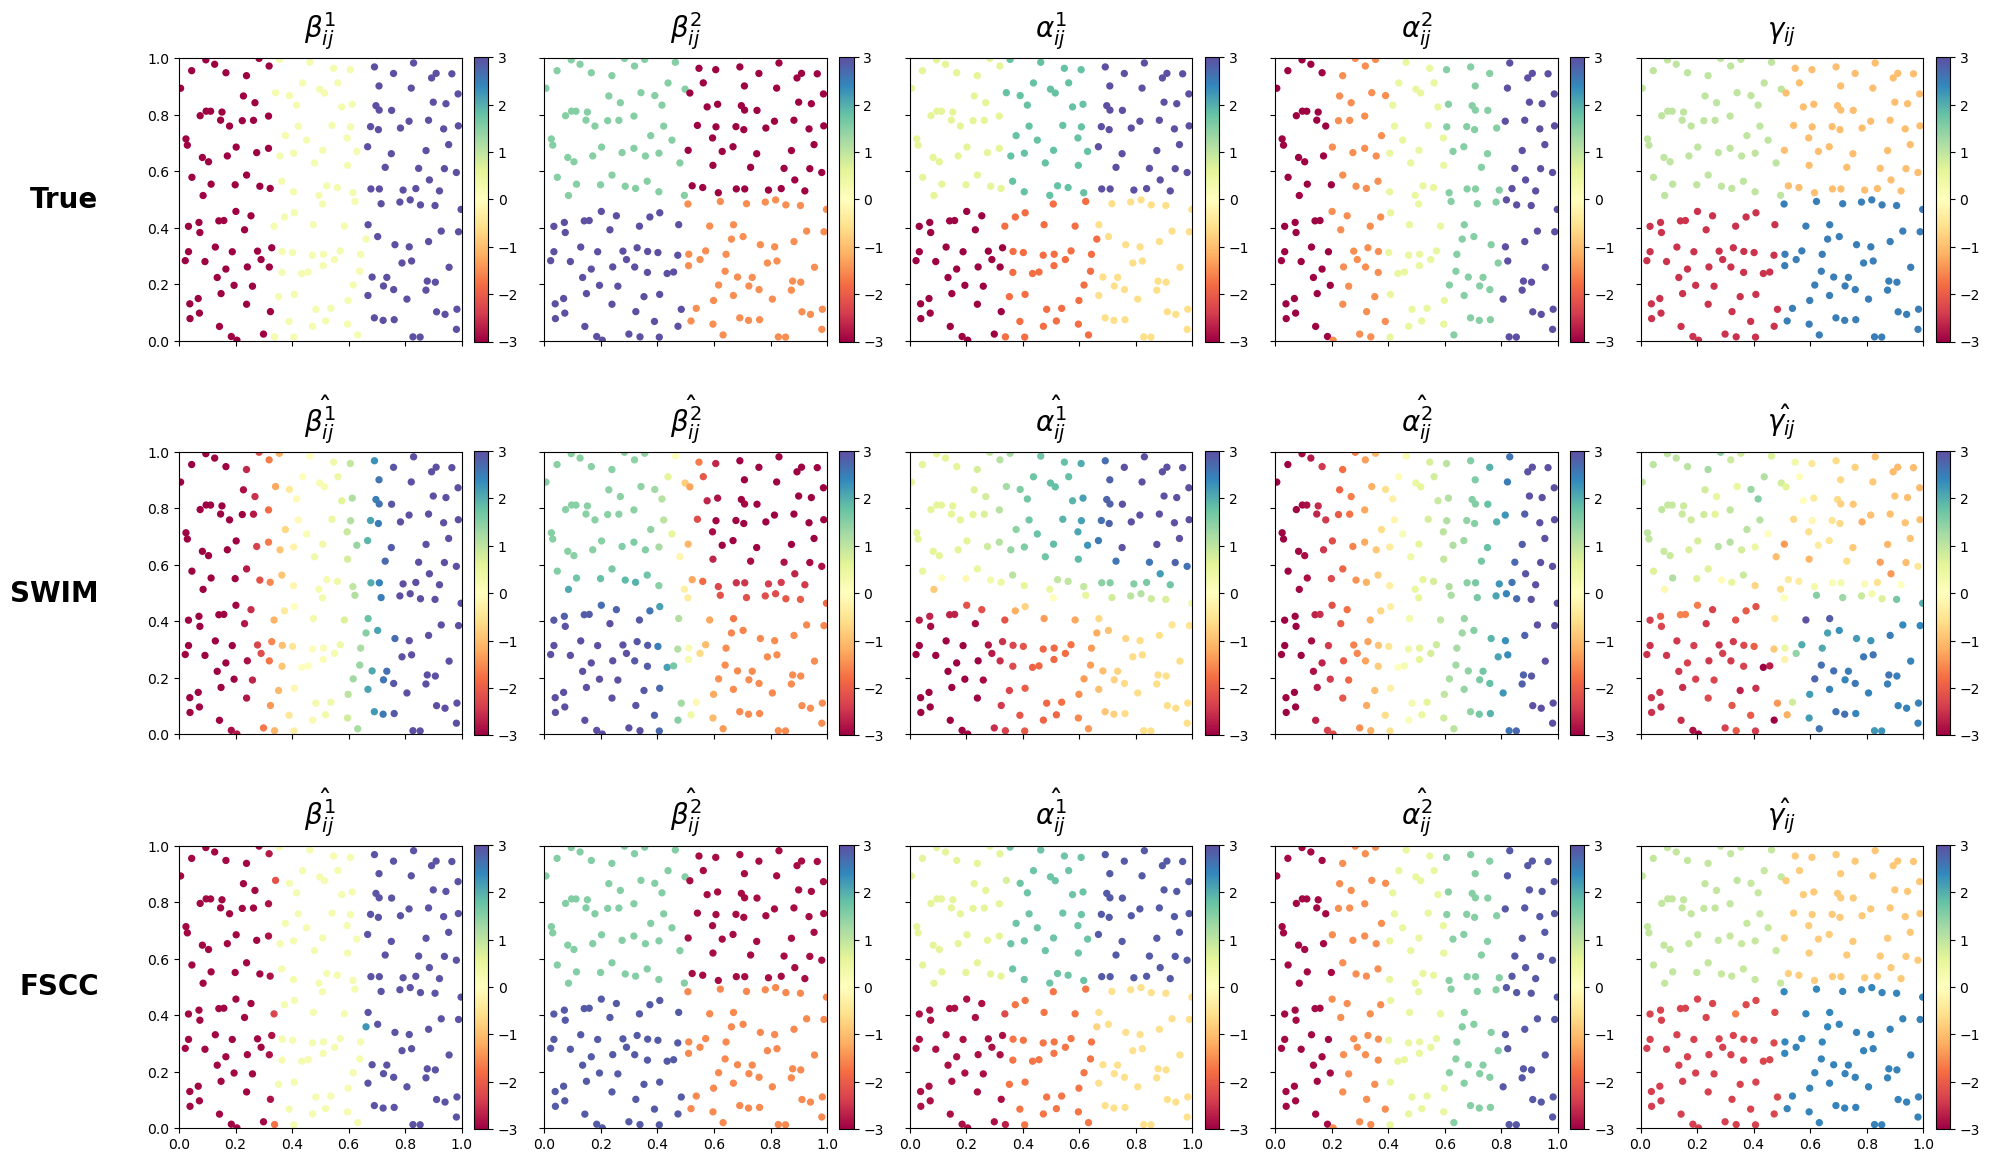


1. MODEL FIT: R2 AND MSE
Method                  R2                 MSE
  SWIM 0.951808 ± 0.000691 1.049914 ± 0.013677
  FSCC 0.998223 ± 0.000021 0.038705 ± 0.000278

2. SPATIAL PARTITION RECOVERY: RI (SWIM POST-HOC / FSCC FUSION)
Method            RI_BETA1            RI_BETA2           RI_ALPHA1           RI_ALPHA2            RI_GAMMA
  SWIM 0.349200 ± 0.001165 0.751296 ± 0.015817 0.677470 ± 0.002047 0.212349 ± 0.001408 0.782246 ± 0.001209
  FSCC 0.955000 ± 0.014983 0.999232 ± 0.000113 0.982510 ± 0.006017 0.956527 ± 0.011363 0.818652 ± 0.024828

3. TRUE VS ESTIMATED GROUP COUNTS
Method   TRUE_GROUPS_BETA1   TRUE_GROUPS_BETA2  TRUE_GROUPS_ALPHA1  TRUE_GROUPS_ALPHA2   TRUE_GROUPS_GAMMA       EST_GROUPS_BETA1        EST_GROUPS_BETA2       EST_GROUPS_ALPHA1      EST_GROUPS_ALPHA2          EST_GROUPS_GAMMA
  SWIM 3.000000 ± 0.000000 4.000000 ± 0.000000 6.000000 ± 0.000000 5.000000 ± 0.000000 4.000000 ± 0.000000 476.800000 ± 22.935291 1187.233333 ± 45.810467 1334.866667 ± 50.836271 290.366

In [7]:
import warnings
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree
import warnings
warnings.filterwarnings("ignore")
n, p, q = (200, 2, 2)
noise_std = 0.1
intercept_true = 1.0
GRID_NEIGHBORHOOD = 'rook'
B = 30
lambda_grid = [0.075, 0.1, 0.125]
max_outer = 60
max_inner = 1000
outer_tol = 0.002
admm_abs_tol = 1e-05
admm_rel_tol = 0.0005
cg_rtol = 1e-08
cg_maxiter = 1500
admm_adapt_interval = 10
admm_balance_mu = 10.0
admm_rho_factor = 2.0
admm_rho_min = 1e-05
admm_rho_max = 100000.0
admm_over_relax = 1.5
df_rel_tol = 0.001
K_SWIM = 100
SWIM_BW_FIXED = 0.105
SWIM_BATCH_SIZE = 1024  # Bound SWIM temporary memory for large n
SWIM_GROUP_REL_TOL = 0.05  # Post-hoc SWIM grouping: 5% of each coefficient surface SD
# A near-square rectangular Rook grid supports n=200 (10x20) and n=300 (15x20).
def choose_grid_shape(num_regions):
    factors = [(r, num_regions // r) for r in range(1, math.isqrt(num_regions) + 1)
               if num_regions % r == 0]
    if not factors:
        raise ValueError('n must be positive')
    return min(factors, key=lambda rc: rc[1] - rc[0])

grid_nrows, grid_ncols = choose_grid_shape(n)
grid_rows = np.repeat(np.arange(grid_nrows, dtype=np.int32), grid_ncols)
grid_cols = np.tile(np.arange(grid_ncols, dtype=np.int32), grid_nrows)
print(f'Region Rook grid: {grid_nrows} x {grid_ncols} = {n} regions')
coord_rng = np.random.default_rng(42)
coords = np.column_stack([(grid_cols + coord_rng.random(n)) / grid_ncols, (grid_rows + coord_rng.random(n)) / grid_nrows]).astype(np.float64)
D_full = cdist(coords, coords).astype(np.float64)
D_PREDICTOR_SCALE = float(np.std(D_full))
if D_PREDICTOR_SCALE <= 1e-12:
    raise ValueError('Distance predictor has zero variance.')
D_model = D_full / D_PREDICTOR_SCALE
beta_piece_sets = [[-3, 0.25, 3], [3, -1.5, 1.5, -3]]
alpha_piece_sets = [[-3, -1.8, -0.6, 0.6, 1.8, 3], [-3, -1.5, 0.5, 1.5, 3]]
gamma_piece_set = [-2.5, 2.5, 1.0, -1.0]

def grid_shape_for_count(count):
    return {3: (1, 3), 4: (2, 2), 5: (1, 5), 6: (2, 3)}[count]

def fill_piecewise_origin(arr3d, coords_, values, feat_idx):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr3d[mask, :, feat_idx] = value

def fill_piecewise_2d(arr2d, coords_, values):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr2d[mask, :] = value
beta0 = np.zeros((n, n, p), dtype=np.float64)
alpha0 = np.zeros((n, n, q), dtype=np.float64)
gamma0 = np.zeros((n, n), dtype=np.float64)
for k in range(p):
    fill_piecewise_origin(beta0, coords, beta_piece_sets[k], k)
for m in range(q):
    fill_piecewise_origin(alpha0, coords, alpha_piece_sets[m], m)
fill_piecewise_2d(gamma0, coords, gamma_piece_set)
edge_u_list = []
edge_v_list = []
for r in range(grid_nrows):
    for c in range(grid_ncols):
        u = r * grid_ncols + c
        if c + 1 < grid_ncols:
            edge_u_list.append(u)
            edge_v_list.append(u + 1)
        if r + 1 < grid_nrows:
            edge_u_list.append(u)
            edge_v_list.append(u + grid_ncols)
edge_u = np.asarray(edge_u_list, dtype=np.int32)
edge_v = np.asarray(edge_v_list, dtype=np.int32)
edge_w = np.ones(len(edge_u), dtype=np.float64)
E = len(edge_u)
N = n * n  # Full-grid indexing for efficient matrix-free ADMM
OD_MASK = ~np.eye(n, dtype=bool)
OD_VALID = OD_MASK.ravel()
N_OBS = int(OD_VALID.sum())  # n*(n-1); exclude i == j everywhere
DIAG_IDX = np.arange(n) * (n + 1)
if E == 0:
    raise RuntimeError('No grid-neighbor edges were constructed.')
A_grid = sp.coo_matrix((np.ones(2 * E, dtype=np.float64), (np.concatenate([edge_u, edge_v]), np.concatenate([edge_v, edge_u]))), shape=(n, n)).tocsr()
A_grid.setdiag(0.0)
A_grid.eliminate_zeros()
if A_grid.nnz and (not np.all(A_grid.data == 1.0)):
    raise RuntimeError('Grid adjacency must be binary: every nonzero entry must equal 1.')
try:
    OUTPUT_DIR = Path(__file__).resolve().parent
except NameError:
    OUTPUT_DIR = Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fixed_origin = np.tile(np.arange(n, dtype=np.int32), E)
u1 = fixed_origin * n + np.repeat(edge_u, n)
v1 = fixed_origin * n + np.repeat(edge_v, n)
w1 = np.repeat(edge_w, n)
fixed_dest = np.tile(np.arange(n, dtype=np.int32), E)
u2 = np.repeat(edge_u, n) * n + fixed_dest
v2 = np.repeat(edge_v, n) * n + fixed_dest
w2 = np.repeat(edge_w, n)
M3 = 2 * E * E
u3 = np.empty(M3, dtype=np.int32)
v3 = np.empty(M3, dtype=np.int32)
mean_region_w = float(np.mean(edge_w))
w3_legacy = np.empty(M3, dtype=np.float64)
write = 0
for e in range(E):
    i1, i2 = (int(edge_u[e]), int(edge_v[e]))
    joint_w = edge_w[e] * edge_w / max(mean_region_w, 1e-12)
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_u
    v3[sl] = i2 * n + edge_v
    w3_legacy[sl] = joint_w
    write += E
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_v
    v3[sl] = i2 * n + edge_u
    w3_legacy[sl] = joint_w
    write += E
assert write == M3
assert np.all(u3 != v3)
# Remove all edges touching any within-region (i == j) OD node.
# Retain full-grid node indexing internally, but diagonal nodes are isolated
# and carry zero data weight, so they cannot influence fitted off-diagonal OD flows.
def remove_diagonal_edges(u, v, w):
    keep = OD_VALID[u] & OD_VALID[v]
    return u[keep], v[keep], w[keep]

u1, v1, w1 = remove_diagonal_edges(u1, v1, w1)
u2, v2, w2 = remove_diagonal_edges(u2, v2, w2)
u3, v3, w3_legacy = remove_diagonal_edges(u3, v3, w3_legacy)
assert all(np.all(OD_VALID[u] & OD_VALID[v]) for u, v in ((u1, v1), (u2, v2), (u3, v3)))
class3_balance = float(np.sum(w1) / max(np.sum(w3_legacy), 1e-12))
SCENARIOS = {'three_classes_binary_unit_weight': {'u': np.concatenate([u1, u2, u3]), 'v': np.concatenate([v1, v2, v3]), 'w': np.concatenate([w1, w2, w3_legacy]), 'include_class3': True, 'class3_scale': 1.0, 'class_edge_counts': (len(u1), len(u2), len(u3))}}
# Exact masked OD Laplacian: the former Kronecker shortcut assumes a complete
# n*n OD grid and would silently reintroduce diagonal-node connections.
ALL_U = SCENARIOS['three_classes_binary_unit_weight']['u']
ALL_V = SCENARIOS['three_classes_binary_unit_weight']['v']
ALL_W2 = SCENARIOS['three_classes_binary_unit_weight']['w'] ** 2
MASKED_DEGREE = (np.bincount(ALL_U, weights=ALL_W2, minlength=N) +
                 np.bincount(ALL_V, weights=ALL_W2, minlength=N))

def graph_degree_vector(include_class3, class3_scale):
    if not include_class3 or class3_scale != 1.0:
        raise ValueError('Only the configured three-class unit-scale graph is supported.')
    return MASKED_DEGREE

def graph_laplacian_matvec(x_vec, include_class3, class3_scale):
    if not include_class3 or class3_scale != 1.0:
        raise ValueError('Only the configured three-class unit-scale graph is supported.')
    differences = ALL_W2 * (x_vec[ALL_U] - x_vec[ALL_V])
    return (np.bincount(ALL_U, weights=differences, minlength=N) -
            np.bincount(ALL_V, weights=differences, minlength=N))

def admm_fuse(v_vec, X2_vec, rho, edges_u, edges_v, edges_w, penalty_per_edge, include_class3, class3_scale, x_init=None, dual_init=None, maxiter=max_inner):
    if len(edges_u) == 0:
        return (np.asarray(v_vec, dtype=np.float64).copy(), {'iterations': 0, 'primal': 0.0, 'dual': 0.0, 'eps_primal': 0.0, 'eps_dual': 0.0, 'primal_ratio': 0.0, 'dual_ratio': 0.0, 'converged': True, 'cg_nonconverged': 0, 'rho_final': float(rho)})
    v64 = np.asarray(v_vec, dtype=np.float64)
    X2 = np.maximum(np.asarray(X2_vec, dtype=np.float64), 1e-12)
    ew = np.asarray(edges_w, dtype=np.float64)
    pen = np.asarray(penalty_per_edge, dtype=np.float64)
    n_edges = len(edges_u)
    rho = float(rho)
    x = np.asarray(x_init, dtype=np.float64).copy() if x_init is not None else v64.copy()
    dx0 = ew * (x[edges_u] - x[edges_v])
    z = dx0.copy()
    if dual_init is None:
        dual_scaled = np.zeros(n_edges, dtype=np.float64)
    else:
        dual_scaled = np.asarray(dual_init, dtype=np.float64).copy() / max(rho, 1e-15)
    cg_nonconverged = 0
    primal_norm = dual_norm = np.inf
    eps_primal = eps_dual = np.inf
    converged = False
    alpha_relax = float(admm_over_relax)

    cached_degree = graph_degree_vector(include_class3, class3_scale)

    def make_linear_operators(rho_now):

        def matvec_A(x_vec):
            return X2 * x_vec + rho_now * graph_laplacian_matvec(x_vec, include_class3, class3_scale)
        A_op = spla.LinearOperator((N, N), matvec=matvec_A, dtype=np.float64)
        precond_diag = np.maximum(X2 + rho_now * cached_degree, 1e-10)
        M_op = spla.LinearOperator((N, N), matvec=lambda r: r / precond_diag, dtype=np.float64)
        return (A_op, M_op)
    A_op, M_op = make_linear_operators(rho)
    rho_updates = 0
    for it in range(1, maxiter + 1):
        diff_zu = (z - dual_scaled) * ew
        Kt_zu = np.bincount(edges_u, weights=diff_zu, minlength=N) - np.bincount(edges_v, weights=diff_zu, minlength=N)
        rhs = X2 * v64 + rho * Kt_zu
        x_new, cg_info = spla.cg(A_op, rhs, x0=x, M=M_op, rtol=cg_rtol, atol=0.0, maxiter=cg_maxiter)
        if cg_info != 0:
            cg_nonconverged += 1
            if cg_info < 0:
                raise RuntimeError(f'CG breakdown (info={cg_info}).')
        Kx = ew * (x_new[edges_u] - x_new[edges_v])
        z_old = z
        Kx_hat = alpha_relax * Kx + (1.0 - alpha_relax) * z_old
        threshold = pen / max(rho, 1e-15)
        z = np.sign(Kx_hat + dual_scaled) * np.maximum(np.abs(Kx_hat + dual_scaled) - threshold, 0.0)
        dual_scaled += Kx_hat - z
        primal_vec = Kx - z
        primal_norm = float(np.linalg.norm(primal_vec))
        z_change = z - z_old
        Kt_dz = np.bincount(edges_u, weights=ew * z_change, minlength=N) - np.bincount(edges_v, weights=ew * z_change, minlength=N)
        dual_vec = rho * Kt_dz
        dual_norm = float(np.linalg.norm(dual_vec))
        eps_primal = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx), np.linalg.norm(z)))
        Kt_u = np.bincount(edges_u, weights=ew * dual_scaled, minlength=N) - np.bincount(edges_v, weights=ew * dual_scaled, minlength=N)
        eps_dual = float(np.sqrt(N) * admm_abs_tol + admm_rel_tol * rho * np.linalg.norm(Kt_u))
        x = x_new
        if primal_norm <= eps_primal and dual_norm <= eps_dual:
            converged = True
            break
        if it % admm_adapt_interval == 0:
            primal_ratio_now = primal_norm / max(eps_primal, 1e-12)
            dual_ratio_now = dual_norm / max(eps_dual, 1e-12)
            rho_new = rho
            if primal_ratio_now > admm_balance_mu * dual_ratio_now:
                rho_new = min(rho * admm_rho_factor, admm_rho_max)
            elif dual_ratio_now > admm_balance_mu * primal_ratio_now:
                rho_new = max(rho / admm_rho_factor, admm_rho_min)
            if not np.isclose(rho_new, rho):
                dual_scaled *= rho / rho_new
                rho = rho_new
                A_op, M_op = make_linear_operators(rho)
                rho_updates += 1
    Kx_final = ew * (x[edges_u] - x[edges_v])
    final_primal_norm = float(np.linalg.norm(Kx_final - z))
    final_primal_eps = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx_final), np.linalg.norm(z)))
    final_primal_ratio = final_primal_norm / max(final_primal_eps, 1e-12)
    final_dual_ratio = dual_norm / max(eps_dual, 1e-12)
    converged = bool(converged and final_primal_ratio <= 1.0 and (final_dual_ratio <= 1.0))
    info = {'iterations': it, 'primal': final_primal_norm, 'dual': dual_norm, 'eps_primal': final_primal_eps, 'eps_dual': eps_dual, 'primal_ratio': final_primal_ratio, 'dual_ratio': final_dual_ratio, 'converged': converged, 'cg_nonconverged': cg_nonconverged, 'rho_final': rho, 'rho_updates': rho_updates, 'dual_unscaled': rho * dual_scaled}
    return (x.astype(np.float64), info)

def swim_fit_fixed_bw(bw, design, y_flat, idx, dist, ridge=1e-08, batch_size=SWIM_BATCH_SIZE):
    """Batched SWIM local weighted least-squares solves, avoiding a full (n*n, K, features) tensor."""
    n_flows, n_features = design.shape
    coefs = np.empty((n_flows, n_features), dtype=np.float64)
    eye = np.eye(n_features, dtype=np.float64)
    for start in range(0, n_flows, batch_size):
        stop = min(start + batch_size, n_flows)
        neighbors = idx[start:stop]
        weights = np.exp(-0.5 * (dist[start:stop] / max(bw, 1e-12)) ** 2)
        xlocal = design[neighbors]
        ylocal = y_flat[neighbors]
        xtx = np.einsum('bki,bkj,bk->bij', xlocal, xlocal, weights, optimize=True)
        xtx += ridge * eye[None, :, :]
        xty = np.einsum('bki,bk,bk->bi', xlocal, ylocal, weights, optimize=True)
        coefs[start:stop] = np.linalg.solve(xtx, xty[..., None])[..., 0]
    pred = np.einsum('bi,bi->b', design, coefs)
    rss = float(np.sum((y_flat - pred) ** 2))
    return (coefs, pred, rss)

def fscc_fit(lam, beta_init, alpha_init, gamma_init, intercept_init, rho_beta, rho_alpha, rho_gamma, X, Z, D, Y, TSS, scenario):
    beta = beta_init.copy()
    alpha = alpha_init.copy()
    gamma = gamma_init.copy()
    intercept = float(intercept_init)
    eu = scenario['u']
    ev = scenario['v']
    ew = scenario['w']
    include_class3 = scenario['include_class3']
    class3_scale = scenario['class3_scale']
    pen_ba = np.full(len(eu), lam, dtype=np.float64)
    # Gamma uses the same ordinary fusion penalty as beta and alpha.
    pen_g = pen_ba
    max_primal_ratio = 0.0
    max_dual_ratio = 0.0
    max_admm_iterations = 0
    total_admm_not_converged = 0
    total_cg_nonconverged = 0
    max_rho_updates = 0
    min_rho_final = np.inf
    max_rho_final = 0.0
    outer_iterations = 0
    outer_converged = False
    final_outer_change = np.inf
    dual_states = {}
    # Maintain Y - fitted values incrementally rather than rebuilding predictions
    # for every coordinate update. This is algebraically identical to the old loop.
    residual = Y - intercept - np.sum(X * beta, axis=2) - np.sum(Z * alpha, axis=2) - D * gamma
    X2_cache = [np.where(OD_VALID, X[:, :, k].ravel() ** 2, 1.0) for k in range(p)]
    Z2_cache = [np.where(OD_VALID, Z[:, :, m].ravel() ** 2, 1.0) for m in range(q)]
    D2 = np.where(OD_VALID, D.ravel() ** 2 + 1e-12, 1.0)

    def record_diag(diag):
        nonlocal max_primal_ratio, max_dual_ratio, max_admm_iterations
        nonlocal total_admm_not_converged, total_cg_nonconverged
        nonlocal max_rho_updates, min_rho_final, max_rho_final
        max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
        max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
        max_admm_iterations = max(max_admm_iterations, diag['iterations'])
        total_admm_not_converged += int(not diag['converged'])
        total_cg_nonconverged += diag['cg_nonconverged']
        max_rho_updates = max(max_rho_updates, diag['rho_updates'])
        min_rho_final = min(min_rho_final, diag['rho_final'])
        max_rho_final = max(max_rho_final, diag['rho_final'])

    for outer in range(1, max_outer + 1):
        beta_prev = beta.copy()
        alpha_prev = alpha.copy()
        gamma_prev = gamma.copy()
        intercept_prev = intercept
        for k in range(p):
            xk = X[:, :, k]
            old = beta[:, :, k].copy()
            partial_residual = residual + xk * old
            x2 = X2_cache[k]
            v = (xk * partial_residual).ravel() / (x2 + 1e-12)
            new_flat, diag = admm_fuse(v, x2, rho_beta, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('beta', k)))
            dual_states['beta', k] = diag['dual_unscaled']
            beta[:, :, k] = new_flat.reshape(n, n)
            residual += xk * (old - beta[:, :, k])
            record_diag(diag)
        for m in range(q):
            zm = Z[:, :, m]
            old = alpha[:, :, m].copy()
            partial_residual = residual + zm * old
            z2 = Z2_cache[m]
            v = (zm * partial_residual).ravel() / (z2 + 1e-12)
            new_flat, diag = admm_fuse(v, z2, rho_alpha, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('alpha', m)))
            dual_states['alpha', m] = diag['dual_unscaled']
            alpha[:, :, m] = new_flat.reshape(n, n)
            residual += zm * (old - alpha[:, :, m])
            record_diag(diag)
        old = gamma.copy()
        partial_residual = residual + D * old
        v_gamma = (D * partial_residual).ravel() / D2
        new_gamma_flat, diag = admm_fuse(v_gamma, D2, rho_gamma, eu, ev, ew, pen_g,
                                         include_class3, class3_scale,
                                         x_init=old.ravel(), dual_init=dual_states.get(('gamma', 0)))
        dual_states['gamma', 0] = diag['dual_unscaled']
        gamma = new_gamma_flat.reshape(n, n)
        residual += D * (old - gamma)
        record_diag(diag)
        # Residual is Y - (intercept + all local contributions).
        delta_intercept = float(np.mean(residual[OD_MASK]))
        intercept += delta_intercept
        residual -= delta_intercept
        db = np.linalg.norm(beta - beta_prev) / max(np.linalg.norm(beta_prev), 1.0)
        da = np.linalg.norm(alpha - alpha_prev) / max(np.linalg.norm(alpha_prev), 1.0)
        dg = np.linalg.norm(gamma - gamma_prev) / max(np.linalg.norm(gamma_prev), 1.0)
        di = abs(intercept - intercept_prev) / max(abs(intercept_prev), 1.0)
        outer_iterations = outer
        final_outer_change = float(max(db, da, dg, di))
        if final_outer_change < outer_tol:
            outer_converged = True
            break
    prediction = np.full((n, n), intercept, dtype=np.float64)
    for k in range(p):
        prediction += X[:, :, k] * beta[:, :, k]
    for m in range(q):
        prediction += Z[:, :, m] * alpha[:, :, m]
    prediction += D * gamma
    residual = Y - prediction
    rss = float(np.sum(residual[OD_MASK] ** 2))
    r2 = float(1.0 - rss / max(TSS, 1e-12))
    diag_all = {'outer_iterations': outer_iterations, 'outer_converged': outer_converged, 'final_outer_change': final_outer_change, 'max_admm_iterations': max_admm_iterations, 'max_primal_ratio': max_primal_ratio, 'max_dual_ratio': max_dual_ratio, 'admm_subproblems_not_converged': total_admm_not_converged, 'cg_nonconverged_total': total_cg_nonconverged, 'max_rho_updates_per_subproblem': max_rho_updates, 'min_rho_final': 0.0 if not np.isfinite(min_rho_final) else min_rho_final, 'max_rho_final': max_rho_final}
    return (beta, alpha, gamma, intercept, prediction, rss, r2, diag_all)

def fused_component_count(values, eu, ev, tol):
    vals = np.asarray(values, dtype=np.float64).ravel()
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    if not np.any(fused):
        return N_OBS
    rows = np.concatenate([eu[fused], ev[fused]])
    cols = np.concatenate([ev[fused], eu[fused]])
    data = np.ones(len(rows), dtype=np.int8)
    graph = sp.coo_matrix((data, (rows, cols)), shape=(len(vals), len(vals))).tocsr()
    n_comp = connected_components(graph, directed=False, return_labels=False)
    return int(n_comp - n)  # isolated diagonal placeholders are not groups

def compute_effective_df(beta, alpha, gamma, intercept, eu, ev):
    dfs = {}
    for k in range(p):
        tol = max(1e-05, df_rel_tol * float(np.std(beta[:, :, k])))
        dfs[f'df_beta{k + 1}'] = fused_component_count(beta[:, :, k], eu, ev, tol)
    for m in range(q):
        tol = max(1e-05, df_rel_tol * float(np.std(alpha[:, :, m])))
        dfs[f'df_alpha{m + 1}'] = fused_component_count(alpha[:, :, m], eu, ev, tol)
    tol_g = max(1e-05, df_rel_tol * float(np.std(gamma)))
    dfs['df_gamma'] = fused_component_count(gamma, eu, ev, tol_g)
    dfs['df_intercept'] = 1
    dfs['df_total'] = int(sum(dfs.values()))
    return dfs

def fscc_fusion_labels(estimate, eu, ev):
    """Connected components of adjacent OD coefficients fused to numerical tolerance.

    No KMeans and no true group count is used to construct estimated groups.
    """
    vals = np.asarray(estimate, dtype=np.float64).ravel()
    tol = max(1e-5, df_rel_tol * float(np.std(vals)))
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    uu, vv = eu[fused], ev[fused]
    graph = sp.coo_matrix(
        (np.ones(2 * len(uu), dtype=np.int8),
         (np.concatenate([uu, vv]), np.concatenate([vv, uu]))),
        shape=(N, N),
    ).tocsr()
    n_groups, labels = connected_components(graph, directed=False, return_labels=True)
    return labels[OD_VALID], int(n_groups - n)



def swim_spatial_group_labels(estimate, eu, ev):
    """Post-hoc SWIM grouping on the same OD graph, without KMeans or true K.

    Adjacent OD flows join when their estimated coefficients differ by at most
    SWIM_GROUP_REL_TOL times the coefficient SD; connected components form groups.
    This is an evaluation-only partition, not a SWIM-native fusion result.
    """
    vals = np.asarray(estimate, dtype=np.float64).ravel()
    valid_vals = vals[OD_VALID]
    if not np.all(np.isfinite(valid_vals)):
        raise ValueError('SWIM contains nonfinite coefficients on valid OD flows.')
    tol = max(1e-5, SWIM_GROUP_REL_TOL * float(np.std(valid_vals)))
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    uu, vv = eu[fused], ev[fused]
    graph = sp.coo_matrix((np.ones(2 * len(uu), dtype=np.int8),
        (np.concatenate([uu, vv]), np.concatenate([vv, uu]))), shape=(N, N)).tocsr()
    n_groups, labels = connected_components(graph, directed=False, return_labels=True)
    return labels[OD_VALID], int(n_groups - n)

def coefficient_metrics(beta, alpha, gamma, fusion_edges=None, swim_edges=None):
    """Evaluate coefficients; FSCC groups come solely from its fusion graph.

    SWIM RI uses post-hoc graph threshold grouping; FSCC is unchanged.
    """
    from sklearn.metrics import rand_score
    surfaces = {
        'beta1': (beta[:, :, 0], beta0[:, :, 0]),
        'beta2': (beta[:, :, 1], beta0[:, :, 1]),
        'alpha1': (alpha[:, :, 0], alpha0[:, :, 0]),
        'alpha2': (alpha[:, :, 1], alpha0[:, :, 1]),
        'gamma': (gamma, gamma0),
    }
    out = {}
    for name, (estimate, true_surface) in surfaces.items():
        out[f'rmse_{name}'] = float(np.sqrt(np.mean((estimate[OD_MASK] - true_surface[OD_MASK]) ** 2)))
        if name == 'gamma':
            out['gamma_origin_average_rmse'] = float(np.sqrt(np.mean((np.nanmean(np.where(OD_MASK, estimate, np.nan), axis=1) - np.nanmean(np.where(OD_MASK, true_surface, np.nan), axis=1)) ** 2)))
            out['gamma_within_origin_sd'] = float(np.mean(np.nanstd(np.where(OD_MASK, estimate, np.nan), axis=1)))
        true_values, true_labels = np.unique(true_surface[OD_MASK], return_inverse=True)
        out[f'true_groups_{name}'] = len(true_values)
        if fusion_edges is not None:
            eu, ev = fusion_edges
            estimated_labels, estimated_groups = fscc_fusion_labels(estimate, eu, ev)
        elif swim_edges is not None:
            eu, ev = swim_edges
            estimated_labels, estimated_groups = swim_spatial_group_labels(estimate, eu, ev)
        else:
            raise ValueError('Provide fusion_edges for FSCC or swim_edges for SWIM.')
        out[f'ri_{name}'] = float(rand_score(true_labels, estimated_labels))
        out[f'est_groups_{name}'] = estimated_groups
    return out
method_metric_rows = []
for rep in range(B):
    seed = 1000 + rep
    np.random.seed(seed)
    X = np.random.randn(n, n, p)
    Z = np.random.randn(n, n, q)
    Y = np.full((n, n), intercept_true, dtype=np.float64)
    for k in range(p):
        Y += X[:, :, k] * beta0[:, :, k]
    for m in range(q):
        Y += Z[:, :, m] * alpha0[:, :, m]
    Y += D_full * gamma0 + noise_std * np.random.randn(n, n)
    X[np.arange(n), np.arange(n), :] = 0.0
    Z[np.arange(n), np.arange(n), :] = 0.0
    Y_mean = float(np.mean(Y[OD_MASK]))
    TSS = float(np.sum((Y[OD_MASK] - Y_mean) ** 2))
    print(f'Replication {rep + 1}/{B}: {N_OBS} inter-region OD flows (diagonal excluded)')
    flow_features = np.column_stack([np.repeat(coords, n, axis=0), np.tile(coords, (n, 1))])[OD_VALID]
    tree = cKDTree(flow_features)
    # Query in batches to avoid large peak memory and improve robustness.
    idx_swim = np.empty((N_OBS, min(K_SWIM, N_OBS)), dtype=np.int32)
    dist_swim = np.empty((N_OBS, min(K_SWIM, N_OBS)), dtype=np.float64)
    for start in range(0, N_OBS, SWIM_BATCH_SIZE):
        stop = min(start + SWIM_BATCH_SIZE, N_OBS)
        dd, ii = tree.query(flow_features[start:stop], k=min(K_SWIM, N_OBS), workers=-1)
        dist_swim[start:stop] = dd
        idx_swim[start:stop] = ii
    design = np.column_stack([X.reshape(N, p), Z.reshape(N, q), D_model.ravel(), np.ones(N)])[OD_VALID]
    y_obs = Y[OD_MASK]
    swim_coef_map, swim_pred, swim_rss = swim_fit_fixed_bw(SWIM_BW_FIXED, design, y_obs, idx_swim, dist_swim)
    swim_map = np.full((n, n, p + q + 2), np.nan, dtype=np.float64)
    swim_map[OD_MASK] = swim_coef_map
    swim_beta = swim_map[:, :, :p]
    swim_alpha = swim_map[:, :, p:p + q]
    swim_gamma = swim_map[:, :, p + q]
    swim_gamma_raw = swim_gamma / D_PREDICTOR_SCALE
    swim_metrics = coefficient_metrics(swim_beta, swim_alpha, swim_gamma_raw, swim_edges=(SCENARIOS['three_classes_binary_unit_weight']['u'], SCENARIOS['three_classes_binary_unit_weight']['v']))
    swim_mse = swim_rss / N_OBS
    swim_r2 = 1.0 - swim_rss / max(TSS, 1e-12)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'SWIM', 'mse': swim_mse, 'r2': swim_r2, 'intercept_estimate': float(np.nanmean(swim_map[:, :, p + q + 1])), **swim_metrics})
    # Global unweighted OLS initialization for ordinary FSCC (no SWIM pilot).
    # The design uses D_model, matching the scale used by fscc_fit.
    ols_coef, *_ = np.linalg.lstsq(design, y_obs, rcond=None)
    fscc_beta_init = np.broadcast_to(ols_coef[:p], (n, n, p)).copy()
    fscc_alpha_init = np.broadcast_to(ols_coef[p:p + q], (n, n, q)).copy()
    fscc_gamma_init = np.full((n, n), ols_coef[p + q], dtype=np.float64)
    fscc_intercept_init = float(ols_coef[p + q + 1])
    fscc_beta_init[np.arange(n), np.arange(n), :] = 0.0
    fscc_alpha_init[np.arange(n), np.arange(n), :] = 0.0
    fscc_gamma_init[np.arange(n), np.arange(n)] = 0.0
    rho_beta = 1.0
    rho_alpha = 1.0
    rho_gamma = 1.0
    for scenario_name, scenario in SCENARIOS.items():
        scenario_results = []
        eu = scenario['u']
        ev = scenario['v']
        edge_count_scenario = len(eu)
        # Increasing-lambda continuation: first fit starts at OLS; later fits
        # start at the previous solution. Each candidate is still optimized
        # for its own lambda and checked for convergence independently.
        warm_beta, warm_alpha, warm_gamma = fscc_beta_init, fscc_alpha_init, fscc_gamma_init
        warm_intercept = fscc_intercept_init
        for lam in sorted(lambda_grid):
            fit = fscc_fit(lam, warm_beta, warm_alpha, warm_gamma,
                           warm_intercept, rho_beta, rho_alpha, rho_gamma,
                           X, Z, D_model, Y, TSS, scenario)
            beta_hat, alpha_hat, gamma_hat, intercept_hat, pred_hat, rss, r2, admm_diag = fit
            warm_beta, warm_alpha, warm_gamma = beta_hat, alpha_hat, gamma_hat
            warm_intercept = intercept_hat
            df_info = compute_effective_df(beta_hat, alpha_hat, gamma_hat, intercept_hat, eu, ev)
            df = df_info['df_total']
            bic = N_OBS * np.log(rss / N_OBS + 1e-12) + np.log(N_OBS) * df
            if admm_diag['admm_subproblems_not_converged'] == 0 and admm_diag['cg_nonconverged_total'] == 0 and admm_diag['outer_converged']:
                scenario_results.append((bic, lam, fit, df_info, admm_diag))
        if not scenario_results:
            raise RuntimeError(f'No fully converged lambda candidate for scenario {scenario_name}. Do not select BIC from unconverged fits. Increase iteration limits or inspect the primal/dual, CG, and outer-change diagnostics.')
        best = min(scenario_results, key=lambda item: item[0])
        best_bic, best_lam, best_fit, best_df, best_admm = best
        b, a, g, intercept, pred, rss, r2, _ = best_fit
        g_raw = g / D_PREDICTOR_SCALE
        fscc_metrics = coefficient_metrics(b, a, g_raw, fusion_edges=(eu, ev))
        method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'FSCC', 'mse': rss / N_OBS, 'r2': r2, 'intercept_estimate': intercept, 'selected_lambda': best_lam, 'bic': best_bic, **fscc_metrics})
        if rep == B - 1:
            last_swim_beta = swim_beta.copy()
            last_swim_alpha = swim_alpha.copy()
            last_swim_gamma = swim_gamma_raw.copy()
            last_fscc_beta = b.copy()
            last_fscc_alpha = a.copy()
            last_fscc_gamma = g_raw.copy()
method_metrics_df = pd.DataFrame(method_metric_rows)
r2_mse_metrics = ['r2', 'mse']
rand_metrics = ['ri_beta1', 'ri_beta2', 'ri_alpha1', 'ri_alpha2', 'ri_gamma']
group_metrics = [f'{prefix}_{name}' for prefix in ('true_groups', 'est_groups') for name in ('beta1', 'beta2', 'alpha1', 'alpha2', 'gamma')]
rmse_metrics = ['rmse_beta1', 'rmse_beta2', 'rmse_alpha1', 'rmse_alpha2', 'rmse_gamma']
all_metric_names = r2_mse_metrics + rand_metrics + group_metrics + rmse_metrics
summary_records = []
for method_name in ['SWIM', 'FSCC']:
    sub = method_metrics_df[method_metrics_df['method'] == method_name]
    rec = {'method': method_name, 'n_replications': int(len(sub))}
    for metric_name in all_metric_names:
        vals = pd.to_numeric(sub[metric_name], errors='coerce').dropna()
        rec[f'{metric_name}_mean'] = float(vals.mean()) if len(vals) else np.nan
        rec[f'{metric_name}_sd'] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
    summary_records.append(rec)
method_summary_df = pd.DataFrame(summary_records)
ordered_columns = ['method', 'n_replications']
for metric_name in all_metric_names:
    ordered_columns.extend([f'{metric_name}_mean', f'{metric_name}_sd'])
method_summary_df = method_summary_df[ordered_columns]
summary_path = OUTPUT_DIR / f'FSCC_performance_{n}.csv'
method_summary_df.to_csv(summary_path, index=False, encoding='utf-8-sig')
def origin_mean_offdiag(arr):
    return np.nanmean(np.where(OD_MASK, arr, np.nan), axis=1)

true_vals = [origin_mean_offdiag(beta0[:, :, k]) for k in range(p)] + [origin_mean_offdiag(alpha0[:, :, m]) for m in range(q)] + [origin_mean_offdiag(gamma0)]
swim_vals = [origin_mean_offdiag(last_swim_beta[:, :, k]) for k in range(p)] + [origin_mean_offdiag(last_swim_alpha[:, :, m]) for m in range(q)] + [origin_mean_offdiag(last_swim_gamma)]
fscc_vals = [origin_mean_offdiag(last_fscc_beta[:, :, k]) for k in range(p)] + [origin_mean_offdiag(last_fscc_alpha[:, :, m]) for m in range(q)] + [origin_mean_offdiag(last_fscc_gamma)]
col_titles = ['$\\beta_{ij}^1$', '$\\beta_{ij}^2$', '$\\alpha_{ij}^1$', '$\\alpha_{ij}^2$', '$\\gamma_{ij}$']
est_titles = ['$\\hat{\\beta_{ij}^1}$', '$\\hat{\\beta_{ij}^2}$', '$\\hat{\\alpha_{ij}^1}$', '$\\hat{\\alpha_{ij}^2}$', '$\\hat{\\gamma_{ij}}$']
row_labels = ['True', 'SWIM', 'FSCC']
vals_list = [true_vals, swim_vals, fscc_vals]
ncols = p + q + 1
fig, axes = plt.subplots(3, ncols, figsize=(4 * ncols, 12), sharex=True, sharey=True)
vmin, vmax = (-3, 3)
for ci, title in enumerate(col_titles):
    for ri, vals in enumerate(vals_list):
        ax = axes[ri, ci]
        sc = ax.scatter(coords[:, 0], coords[:, 1], c=vals[ci], s=18, cmap='Spectral', vmin=vmin, vmax=vmax)
        ax.set_title(title if ri == 0 else est_titles[ci], fontsize=20, pad=15)
        if ri == 0:
            ax.set_title(title, fontsize=20, pad=15)
        if ci == 0:
            ax.set_ylabel(row_labels[ri], fontsize=20, rotation=0, labelpad=35, fontweight='bold', va='center', ha='right')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
final_plot_path = OUTPUT_DIR / f'FSCC_{n}_sim.png'
plt.savefig(final_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

def print_metric_section(title, metrics):
    print('\n' + '=' * 76)
    print(title)
    print('=' * 76)
    rows = []
    for _, rec in method_summary_df.iterrows():
        row = {'Method': rec['method']}
        for metric in metrics:
            mean_val = rec[f'{metric}_mean']
            sd_val = rec[f'{metric}_sd']
            row[metric.upper()] = f'{mean_val:.6f} ± {sd_val:.6f}' if pd.notna(sd_val) else f'{mean_val:.6f}'
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))
print_metric_section('1. MODEL FIT: R2 AND MSE', r2_mse_metrics)
print_metric_section('2. SPATIAL PARTITION RECOVERY: RI (SWIM POST-HOC / FSCC FUSION)', rand_metrics)
print_metric_section('3. TRUE VS ESTIMATED GROUP COUNTS', group_metrics)
print_metric_section('4. COEFFICIENT ESTIMATION ERROR: RMSE', rmse_metrics)
print('Saved:', summary_path, final_plot_path)

Region Rook grid: 15 x 20 = 300 regions
Replication 1/30: 89700 inter-region OD flows (diagonal excluded)
Replication 2/30: 89700 inter-region OD flows (diagonal excluded)
Replication 3/30: 89700 inter-region OD flows (diagonal excluded)
Replication 4/30: 89700 inter-region OD flows (diagonal excluded)
Replication 5/30: 89700 inter-region OD flows (diagonal excluded)
Replication 6/30: 89700 inter-region OD flows (diagonal excluded)
Replication 7/30: 89700 inter-region OD flows (diagonal excluded)
Replication 8/30: 89700 inter-region OD flows (diagonal excluded)
Replication 9/30: 89700 inter-region OD flows (diagonal excluded)
Replication 10/30: 89700 inter-region OD flows (diagonal excluded)
Replication 12/30: 89700 inter-region OD flows (diagonal excluded)
Replication 13/30: 89700 inter-region OD flows (diagonal excluded)
Replication 14/30: 89700 inter-region OD flows (diagonal excluded)
Replication 15/30: 89700 inter-region OD flows (diagonal excluded)
Replication 16/30: 89700 inter-

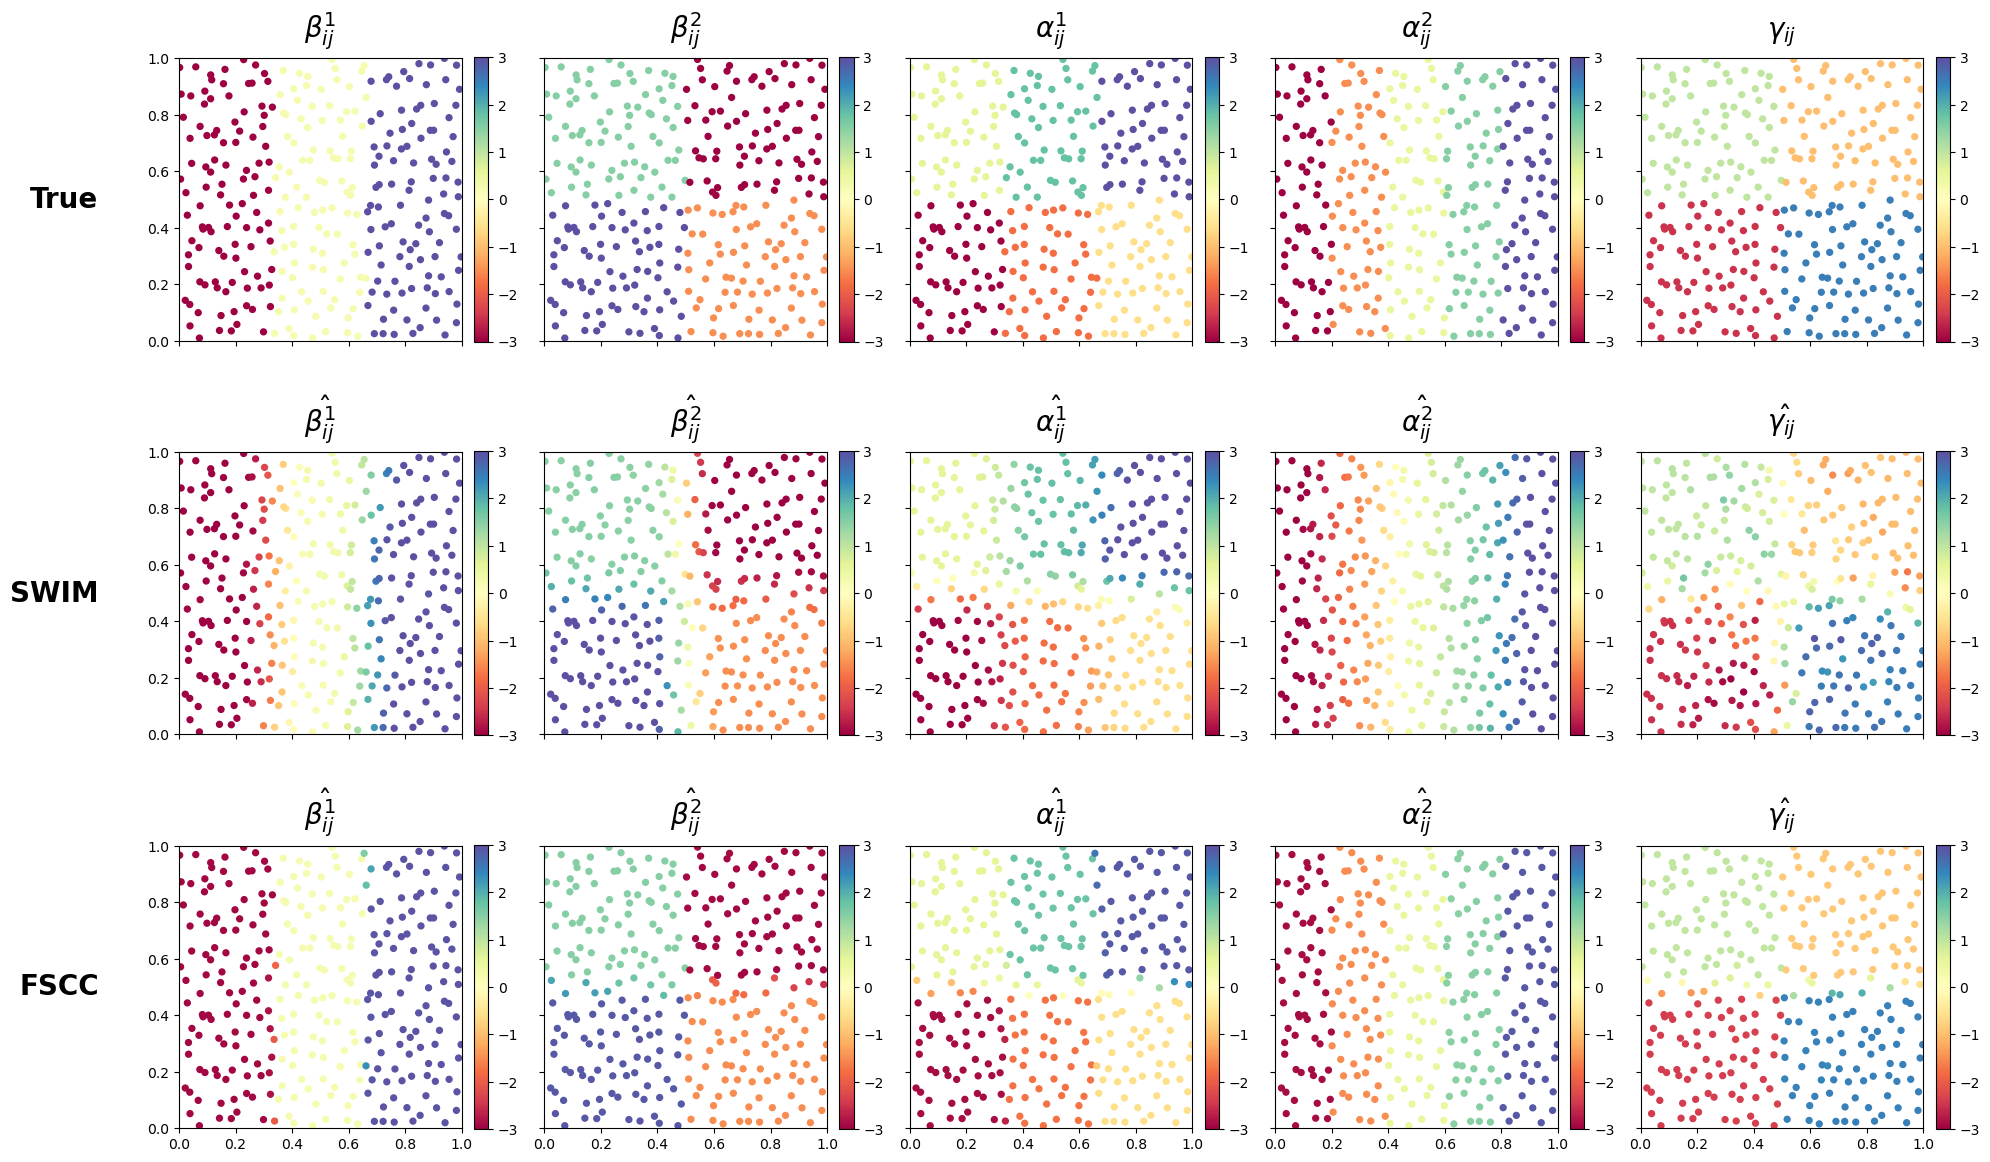


1. MODEL FIT: R2 AND MSE
Method                  R2                 MSE
  SWIM 0.961706 ± 0.000316 0.829290 ± 0.007934
  FSCC 0.997885 ± 0.000020 0.045807 ± 0.000255

2. SPATIAL PARTITION RECOVERY: RI (SWIM POST-HOC / FSCC FUSION)
Method            RI_BETA1            RI_BETA2           RI_ALPHA1           RI_ALPHA2            RI_GAMMA
  SWIM 0.351633 ± 0.001001 0.725072 ± 0.079761 0.477577 ± 0.215934 0.209984 ± 0.000606 0.789111 ± 0.003839
  FSCC 0.943713 ± 0.013099 0.969513 ± 0.000131 0.961483 ± 0.002572 0.952873 ± 0.011080 0.862478 ± 0.022600

3. TRUE VS ESTIMATED GROUP COUNTS
Method   TRUE_GROUPS_BETA1   TRUE_GROUPS_BETA2  TRUE_GROUPS_ALPHA1  TRUE_GROUPS_ALPHA2   TRUE_GROUPS_GAMMA        EST_GROUPS_BETA1        EST_GROUPS_BETA2       EST_GROUPS_ALPHA1      EST_GROUPS_ALPHA2          EST_GROUPS_GAMMA
  SWIM 3.000000 ± 0.000000 4.000000 ± 0.000000 6.000000 ± 0.000000 5.000000 ± 0.000000 4.000000 ± 0.000000 1099.066667 ± 35.952971 2225.533333 ± 61.754650 2583.300000 ± 79.809320 526.6

In [8]:
import warnings
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree
import warnings
warnings.filterwarnings("ignore")
n, p, q = (300, 2, 2)
noise_std = 0.1
intercept_true = 1.0
GRID_NEIGHBORHOOD = 'rook'
B = 30
lambda_grid = [0.075, 0.1, 0.125]
max_outer = 60
max_inner = 1000
outer_tol = 0.002
admm_abs_tol = 1e-05
admm_rel_tol = 0.0005
cg_rtol = 1e-08
cg_maxiter = 1500
admm_adapt_interval = 10
admm_balance_mu = 10.0
admm_rho_factor = 2.0
admm_rho_min = 1e-05
admm_rho_max = 100000.0
admm_over_relax = 1.5
df_rel_tol = 0.001
K_SWIM = 100
SWIM_BW_FIXED = 0.105
SWIM_BATCH_SIZE = 1024  # Bound SWIM temporary memory for large n
SWIM_GROUP_REL_TOL = 0.05  # Post-hoc SWIM grouping: 5% of each coefficient surface SD
# A near-square rectangular Rook grid supports n=200 (10x20) and n=300 (15x20).
def choose_grid_shape(num_regions):
    factors = [(r, num_regions // r) for r in range(1, math.isqrt(num_regions) + 1)
               if num_regions % r == 0]
    if not factors:
        raise ValueError('n must be positive')
    return min(factors, key=lambda rc: rc[1] - rc[0])

grid_nrows, grid_ncols = choose_grid_shape(n)
grid_rows = np.repeat(np.arange(grid_nrows, dtype=np.int32), grid_ncols)
grid_cols = np.tile(np.arange(grid_ncols, dtype=np.int32), grid_nrows)
print(f'Region Rook grid: {grid_nrows} x {grid_ncols} = {n} regions')
coord_rng = np.random.default_rng(42)
coords = np.column_stack([(grid_cols + coord_rng.random(n)) / grid_ncols, (grid_rows + coord_rng.random(n)) / grid_nrows]).astype(np.float64)
D_full = cdist(coords, coords).astype(np.float64)
D_PREDICTOR_SCALE = float(np.std(D_full))
if D_PREDICTOR_SCALE <= 1e-12:
    raise ValueError('Distance predictor has zero variance.')
D_model = D_full / D_PREDICTOR_SCALE
beta_piece_sets = [[-3, 0.25, 3], [3, -1.5, 1.5, -3]]
alpha_piece_sets = [[-3, -1.8, -0.6, 0.6, 1.8, 3], [-3, -1.5, 0.5, 1.5, 3]]
gamma_piece_set = [-2.5, 2.5, 1.0, -1.0]

def grid_shape_for_count(count):
    return {3: (1, 3), 4: (2, 2), 5: (1, 5), 6: (2, 3)}[count]

def fill_piecewise_origin(arr3d, coords_, values, feat_idx):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr3d[mask, :, feat_idx] = value

def fill_piecewise_2d(arr2d, coords_, values):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr2d[mask, :] = value
beta0 = np.zeros((n, n, p), dtype=np.float64)
alpha0 = np.zeros((n, n, q), dtype=np.float64)
gamma0 = np.zeros((n, n), dtype=np.float64)
for k in range(p):
    fill_piecewise_origin(beta0, coords, beta_piece_sets[k], k)
for m in range(q):
    fill_piecewise_origin(alpha0, coords, alpha_piece_sets[m], m)
fill_piecewise_2d(gamma0, coords, gamma_piece_set)
edge_u_list = []
edge_v_list = []
for r in range(grid_nrows):
    for c in range(grid_ncols):
        u = r * grid_ncols + c
        if c + 1 < grid_ncols:
            edge_u_list.append(u)
            edge_v_list.append(u + 1)
        if r + 1 < grid_nrows:
            edge_u_list.append(u)
            edge_v_list.append(u + grid_ncols)
edge_u = np.asarray(edge_u_list, dtype=np.int32)
edge_v = np.asarray(edge_v_list, dtype=np.int32)
edge_w = np.ones(len(edge_u), dtype=np.float64)
E = len(edge_u)
N = n * n  # Full-grid indexing for efficient matrix-free ADMM
OD_MASK = ~np.eye(n, dtype=bool)
OD_VALID = OD_MASK.ravel()
N_OBS = int(OD_VALID.sum())  # n*(n-1); exclude i == j everywhere
DIAG_IDX = np.arange(n) * (n + 1)
if E == 0:
    raise RuntimeError('No grid-neighbor edges were constructed.')
A_grid = sp.coo_matrix((np.ones(2 * E, dtype=np.float64), (np.concatenate([edge_u, edge_v]), np.concatenate([edge_v, edge_u]))), shape=(n, n)).tocsr()
A_grid.setdiag(0.0)
A_grid.eliminate_zeros()
if A_grid.nnz and (not np.all(A_grid.data == 1.0)):
    raise RuntimeError('Grid adjacency must be binary: every nonzero entry must equal 1.')
try:
    OUTPUT_DIR = Path(__file__).resolve().parent
except NameError:
    OUTPUT_DIR = Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fixed_origin = np.tile(np.arange(n, dtype=np.int32), E)
u1 = fixed_origin * n + np.repeat(edge_u, n)
v1 = fixed_origin * n + np.repeat(edge_v, n)
w1 = np.repeat(edge_w, n)
fixed_dest = np.tile(np.arange(n, dtype=np.int32), E)
u2 = np.repeat(edge_u, n) * n + fixed_dest
v2 = np.repeat(edge_v, n) * n + fixed_dest
w2 = np.repeat(edge_w, n)
M3 = 2 * E * E
u3 = np.empty(M3, dtype=np.int32)
v3 = np.empty(M3, dtype=np.int32)
mean_region_w = float(np.mean(edge_w))
w3_legacy = np.empty(M3, dtype=np.float64)
write = 0
for e in range(E):
    i1, i2 = (int(edge_u[e]), int(edge_v[e]))
    joint_w = edge_w[e] * edge_w / max(mean_region_w, 1e-12)
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_u
    v3[sl] = i2 * n + edge_v
    w3_legacy[sl] = joint_w
    write += E
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_v
    v3[sl] = i2 * n + edge_u
    w3_legacy[sl] = joint_w
    write += E
assert write == M3
assert np.all(u3 != v3)
# Remove all edges touching any within-region (i == j) OD node.
# Retain full-grid node indexing internally, but diagonal nodes are isolated
# and carry zero data weight, so they cannot influence fitted off-diagonal OD flows.
def remove_diagonal_edges(u, v, w):
    keep = OD_VALID[u] & OD_VALID[v]
    return u[keep], v[keep], w[keep]

u1, v1, w1 = remove_diagonal_edges(u1, v1, w1)
u2, v2, w2 = remove_diagonal_edges(u2, v2, w2)
u3, v3, w3_legacy = remove_diagonal_edges(u3, v3, w3_legacy)
assert all(np.all(OD_VALID[u] & OD_VALID[v]) for u, v in ((u1, v1), (u2, v2), (u3, v3)))
class3_balance = float(np.sum(w1) / max(np.sum(w3_legacy), 1e-12))
SCENARIOS = {'three_classes_binary_unit_weight': {'u': np.concatenate([u1, u2, u3]), 'v': np.concatenate([v1, v2, v3]), 'w': np.concatenate([w1, w2, w3_legacy]), 'include_class3': True, 'class3_scale': 1.0, 'class_edge_counts': (len(u1), len(u2), len(u3))}}
# Exact masked OD Laplacian: the former Kronecker shortcut assumes a complete
# n*n OD grid and would silently reintroduce diagonal-node connections.
ALL_U = SCENARIOS['three_classes_binary_unit_weight']['u']
ALL_V = SCENARIOS['three_classes_binary_unit_weight']['v']
ALL_W2 = SCENARIOS['three_classes_binary_unit_weight']['w'] ** 2
MASKED_DEGREE = (np.bincount(ALL_U, weights=ALL_W2, minlength=N) +
                 np.bincount(ALL_V, weights=ALL_W2, minlength=N))

def graph_degree_vector(include_class3, class3_scale):
    if not include_class3 or class3_scale != 1.0:
        raise ValueError('Only the configured three-class unit-scale graph is supported.')
    return MASKED_DEGREE

def graph_laplacian_matvec(x_vec, include_class3, class3_scale):
    if not include_class3 or class3_scale != 1.0:
        raise ValueError('Only the configured three-class unit-scale graph is supported.')
    differences = ALL_W2 * (x_vec[ALL_U] - x_vec[ALL_V])
    return (np.bincount(ALL_U, weights=differences, minlength=N) -
            np.bincount(ALL_V, weights=differences, minlength=N))

def admm_fuse(v_vec, X2_vec, rho, edges_u, edges_v, edges_w, penalty_per_edge, include_class3, class3_scale, x_init=None, dual_init=None, maxiter=max_inner):
    if len(edges_u) == 0:
        return (np.asarray(v_vec, dtype=np.float64).copy(), {'iterations': 0, 'primal': 0.0, 'dual': 0.0, 'eps_primal': 0.0, 'eps_dual': 0.0, 'primal_ratio': 0.0, 'dual_ratio': 0.0, 'converged': True, 'cg_nonconverged': 0, 'rho_final': float(rho)})
    v64 = np.asarray(v_vec, dtype=np.float64)
    X2 = np.maximum(np.asarray(X2_vec, dtype=np.float64), 1e-12)
    ew = np.asarray(edges_w, dtype=np.float64)
    pen = np.asarray(penalty_per_edge, dtype=np.float64)
    n_edges = len(edges_u)
    rho = float(rho)
    x = np.asarray(x_init, dtype=np.float64).copy() if x_init is not None else v64.copy()
    dx0 = ew * (x[edges_u] - x[edges_v])
    z = dx0.copy()
    if dual_init is None:
        dual_scaled = np.zeros(n_edges, dtype=np.float64)
    else:
        dual_scaled = np.asarray(dual_init, dtype=np.float64).copy() / max(rho, 1e-15)
    cg_nonconverged = 0
    primal_norm = dual_norm = np.inf
    eps_primal = eps_dual = np.inf
    converged = False
    alpha_relax = float(admm_over_relax)

    cached_degree = graph_degree_vector(include_class3, class3_scale)

    def make_linear_operators(rho_now):

        def matvec_A(x_vec):
            return X2 * x_vec + rho_now * graph_laplacian_matvec(x_vec, include_class3, class3_scale)
        A_op = spla.LinearOperator((N, N), matvec=matvec_A, dtype=np.float64)
        precond_diag = np.maximum(X2 + rho_now * cached_degree, 1e-10)
        M_op = spla.LinearOperator((N, N), matvec=lambda r: r / precond_diag, dtype=np.float64)
        return (A_op, M_op)
    A_op, M_op = make_linear_operators(rho)
    rho_updates = 0
    for it in range(1, maxiter + 1):
        diff_zu = (z - dual_scaled) * ew
        Kt_zu = np.bincount(edges_u, weights=diff_zu, minlength=N) - np.bincount(edges_v, weights=diff_zu, minlength=N)
        rhs = X2 * v64 + rho * Kt_zu
        x_new, cg_info = spla.cg(A_op, rhs, x0=x, M=M_op, rtol=cg_rtol, atol=0.0, maxiter=cg_maxiter)
        if cg_info != 0:
            cg_nonconverged += 1
            if cg_info < 0:
                raise RuntimeError(f'CG breakdown (info={cg_info}).')
        Kx = ew * (x_new[edges_u] - x_new[edges_v])
        z_old = z
        Kx_hat = alpha_relax * Kx + (1.0 - alpha_relax) * z_old
        threshold = pen / max(rho, 1e-15)
        z = np.sign(Kx_hat + dual_scaled) * np.maximum(np.abs(Kx_hat + dual_scaled) - threshold, 0.0)
        dual_scaled += Kx_hat - z
        primal_vec = Kx - z
        primal_norm = float(np.linalg.norm(primal_vec))
        z_change = z - z_old
        Kt_dz = np.bincount(edges_u, weights=ew * z_change, minlength=N) - np.bincount(edges_v, weights=ew * z_change, minlength=N)
        dual_vec = rho * Kt_dz
        dual_norm = float(np.linalg.norm(dual_vec))
        eps_primal = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx), np.linalg.norm(z)))
        Kt_u = np.bincount(edges_u, weights=ew * dual_scaled, minlength=N) - np.bincount(edges_v, weights=ew * dual_scaled, minlength=N)
        eps_dual = float(np.sqrt(N) * admm_abs_tol + admm_rel_tol * rho * np.linalg.norm(Kt_u))
        x = x_new
        if primal_norm <= eps_primal and dual_norm <= eps_dual:
            converged = True
            break
        if it % admm_adapt_interval == 0:
            primal_ratio_now = primal_norm / max(eps_primal, 1e-12)
            dual_ratio_now = dual_norm / max(eps_dual, 1e-12)
            rho_new = rho
            if primal_ratio_now > admm_balance_mu * dual_ratio_now:
                rho_new = min(rho * admm_rho_factor, admm_rho_max)
            elif dual_ratio_now > admm_balance_mu * primal_ratio_now:
                rho_new = max(rho / admm_rho_factor, admm_rho_min)
            if not np.isclose(rho_new, rho):
                dual_scaled *= rho / rho_new
                rho = rho_new
                A_op, M_op = make_linear_operators(rho)
                rho_updates += 1
    Kx_final = ew * (x[edges_u] - x[edges_v])
    final_primal_norm = float(np.linalg.norm(Kx_final - z))
    final_primal_eps = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx_final), np.linalg.norm(z)))
    final_primal_ratio = final_primal_norm / max(final_primal_eps, 1e-12)
    final_dual_ratio = dual_norm / max(eps_dual, 1e-12)
    converged = bool(converged and final_primal_ratio <= 1.0 and (final_dual_ratio <= 1.0))
    info = {'iterations': it, 'primal': final_primal_norm, 'dual': dual_norm, 'eps_primal': final_primal_eps, 'eps_dual': eps_dual, 'primal_ratio': final_primal_ratio, 'dual_ratio': final_dual_ratio, 'converged': converged, 'cg_nonconverged': cg_nonconverged, 'rho_final': rho, 'rho_updates': rho_updates, 'dual_unscaled': rho * dual_scaled}
    return (x.astype(np.float64), info)

def swim_fit_fixed_bw(bw, design, y_flat, idx, dist, ridge=1e-08, batch_size=SWIM_BATCH_SIZE):
    """Batched SWIM local weighted least-squares solves, avoiding a full (n*n, K, features) tensor."""
    n_flows, n_features = design.shape
    coefs = np.empty((n_flows, n_features), dtype=np.float64)
    eye = np.eye(n_features, dtype=np.float64)
    for start in range(0, n_flows, batch_size):
        stop = min(start + batch_size, n_flows)
        neighbors = idx[start:stop]
        weights = np.exp(-0.5 * (dist[start:stop] / max(bw, 1e-12)) ** 2)
        xlocal = design[neighbors]
        ylocal = y_flat[neighbors]
        xtx = np.einsum('bki,bkj,bk->bij', xlocal, xlocal, weights, optimize=True)
        xtx += ridge * eye[None, :, :]
        xty = np.einsum('bki,bk,bk->bi', xlocal, ylocal, weights, optimize=True)
        coefs[start:stop] = np.linalg.solve(xtx, xty[..., None])[..., 0]
    pred = np.einsum('bi,bi->b', design, coefs)
    rss = float(np.sum((y_flat - pred) ** 2))
    return (coefs, pred, rss)

def fscc_fit(lam, beta_init, alpha_init, gamma_init, intercept_init, rho_beta, rho_alpha, rho_gamma, X, Z, D, Y, TSS, scenario):
    beta = beta_init.copy()
    alpha = alpha_init.copy()
    gamma = gamma_init.copy()
    intercept = float(intercept_init)
    eu = scenario['u']
    ev = scenario['v']
    ew = scenario['w']
    include_class3 = scenario['include_class3']
    class3_scale = scenario['class3_scale']
    pen_ba = np.full(len(eu), lam, dtype=np.float64)
    # Gamma uses the same ordinary fusion penalty as beta and alpha.
    pen_g = pen_ba
    max_primal_ratio = 0.0
    max_dual_ratio = 0.0
    max_admm_iterations = 0
    total_admm_not_converged = 0
    total_cg_nonconverged = 0
    max_rho_updates = 0
    min_rho_final = np.inf
    max_rho_final = 0.0
    outer_iterations = 0
    outer_converged = False
    final_outer_change = np.inf
    dual_states = {}
    # Maintain Y - fitted values incrementally rather than rebuilding predictions
    # for every coordinate update. This is algebraically identical to the old loop.
    residual = Y - intercept - np.sum(X * beta, axis=2) - np.sum(Z * alpha, axis=2) - D * gamma
    X2_cache = [np.where(OD_VALID, X[:, :, k].ravel() ** 2, 1.0) for k in range(p)]
    Z2_cache = [np.where(OD_VALID, Z[:, :, m].ravel() ** 2, 1.0) for m in range(q)]
    D2 = np.where(OD_VALID, D.ravel() ** 2 + 1e-12, 1.0)

    def record_diag(diag):
        nonlocal max_primal_ratio, max_dual_ratio, max_admm_iterations
        nonlocal total_admm_not_converged, total_cg_nonconverged
        nonlocal max_rho_updates, min_rho_final, max_rho_final
        max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
        max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
        max_admm_iterations = max(max_admm_iterations, diag['iterations'])
        total_admm_not_converged += int(not diag['converged'])
        total_cg_nonconverged += diag['cg_nonconverged']
        max_rho_updates = max(max_rho_updates, diag['rho_updates'])
        min_rho_final = min(min_rho_final, diag['rho_final'])
        max_rho_final = max(max_rho_final, diag['rho_final'])

    for outer in range(1, max_outer + 1):
        beta_prev = beta.copy()
        alpha_prev = alpha.copy()
        gamma_prev = gamma.copy()
        intercept_prev = intercept
        for k in range(p):
            xk = X[:, :, k]
            old = beta[:, :, k].copy()
            partial_residual = residual + xk * old
            x2 = X2_cache[k]
            v = (xk * partial_residual).ravel() / (x2 + 1e-12)
            new_flat, diag = admm_fuse(v, x2, rho_beta, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('beta', k)))
            dual_states['beta', k] = diag['dual_unscaled']
            beta[:, :, k] = new_flat.reshape(n, n)
            residual += xk * (old - beta[:, :, k])
            record_diag(diag)
        for m in range(q):
            zm = Z[:, :, m]
            old = alpha[:, :, m].copy()
            partial_residual = residual + zm * old
            z2 = Z2_cache[m]
            v = (zm * partial_residual).ravel() / (z2 + 1e-12)
            new_flat, diag = admm_fuse(v, z2, rho_alpha, eu, ev, ew, pen_ba,
                                       include_class3, class3_scale,
                                       x_init=old.ravel(), dual_init=dual_states.get(('alpha', m)))
            dual_states['alpha', m] = diag['dual_unscaled']
            alpha[:, :, m] = new_flat.reshape(n, n)
            residual += zm * (old - alpha[:, :, m])
            record_diag(diag)
        old = gamma.copy()
        partial_residual = residual + D * old
        v_gamma = (D * partial_residual).ravel() / D2
        new_gamma_flat, diag = admm_fuse(v_gamma, D2, rho_gamma, eu, ev, ew, pen_g,
                                         include_class3, class3_scale,
                                         x_init=old.ravel(), dual_init=dual_states.get(('gamma', 0)))
        dual_states['gamma', 0] = diag['dual_unscaled']
        gamma = new_gamma_flat.reshape(n, n)
        residual += D * (old - gamma)
        record_diag(diag)
        # Residual is Y - (intercept + all local contributions).
        delta_intercept = float(np.mean(residual[OD_MASK]))
        intercept += delta_intercept
        residual -= delta_intercept
        db = np.linalg.norm(beta - beta_prev) / max(np.linalg.norm(beta_prev), 1.0)
        da = np.linalg.norm(alpha - alpha_prev) / max(np.linalg.norm(alpha_prev), 1.0)
        dg = np.linalg.norm(gamma - gamma_prev) / max(np.linalg.norm(gamma_prev), 1.0)
        di = abs(intercept - intercept_prev) / max(abs(intercept_prev), 1.0)
        outer_iterations = outer
        final_outer_change = float(max(db, da, dg, di))
        if final_outer_change < outer_tol:
            outer_converged = True
            break
    prediction = np.full((n, n), intercept, dtype=np.float64)
    for k in range(p):
        prediction += X[:, :, k] * beta[:, :, k]
    for m in range(q):
        prediction += Z[:, :, m] * alpha[:, :, m]
    prediction += D * gamma
    residual = Y - prediction
    rss = float(np.sum(residual[OD_MASK] ** 2))
    r2 = float(1.0 - rss / max(TSS, 1e-12))
    diag_all = {'outer_iterations': outer_iterations, 'outer_converged': outer_converged, 'final_outer_change': final_outer_change, 'max_admm_iterations': max_admm_iterations, 'max_primal_ratio': max_primal_ratio, 'max_dual_ratio': max_dual_ratio, 'admm_subproblems_not_converged': total_admm_not_converged, 'cg_nonconverged_total': total_cg_nonconverged, 'max_rho_updates_per_subproblem': max_rho_updates, 'min_rho_final': 0.0 if not np.isfinite(min_rho_final) else min_rho_final, 'max_rho_final': max_rho_final}
    return (beta, alpha, gamma, intercept, prediction, rss, r2, diag_all)

def fused_component_count(values, eu, ev, tol):
    vals = np.asarray(values, dtype=np.float64).ravel()
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    if not np.any(fused):
        return N_OBS
    rows = np.concatenate([eu[fused], ev[fused]])
    cols = np.concatenate([ev[fused], eu[fused]])
    data = np.ones(len(rows), dtype=np.int8)
    graph = sp.coo_matrix((data, (rows, cols)), shape=(len(vals), len(vals))).tocsr()
    n_comp = connected_components(graph, directed=False, return_labels=False)
    return int(n_comp - n)  # isolated diagonal placeholders are not groups

def compute_effective_df(beta, alpha, gamma, intercept, eu, ev):
    dfs = {}
    for k in range(p):
        tol = max(1e-05, df_rel_tol * float(np.std(beta[:, :, k])))
        dfs[f'df_beta{k + 1}'] = fused_component_count(beta[:, :, k], eu, ev, tol)
    for m in range(q):
        tol = max(1e-05, df_rel_tol * float(np.std(alpha[:, :, m])))
        dfs[f'df_alpha{m + 1}'] = fused_component_count(alpha[:, :, m], eu, ev, tol)
    tol_g = max(1e-05, df_rel_tol * float(np.std(gamma)))
    dfs['df_gamma'] = fused_component_count(gamma, eu, ev, tol_g)
    dfs['df_intercept'] = 1
    dfs['df_total'] = int(sum(dfs.values()))
    return dfs

def fscc_fusion_labels(estimate, eu, ev):
    """Connected components of adjacent OD coefficients fused to numerical tolerance.

    No KMeans and no true group count is used to construct estimated groups.
    """
    vals = np.asarray(estimate, dtype=np.float64).ravel()
    tol = max(1e-5, df_rel_tol * float(np.std(vals)))
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    uu, vv = eu[fused], ev[fused]
    graph = sp.coo_matrix(
        (np.ones(2 * len(uu), dtype=np.int8),
         (np.concatenate([uu, vv]), np.concatenate([vv, uu]))),
        shape=(N, N),
    ).tocsr()
    n_groups, labels = connected_components(graph, directed=False, return_labels=True)
    return labels[OD_VALID], int(n_groups - n)



def swim_spatial_group_labels(estimate, eu, ev):
    """Post-hoc SWIM grouping on the same OD graph, without KMeans or true K.

    Adjacent OD flows join when their estimated coefficients differ by at most
    SWIM_GROUP_REL_TOL times the coefficient SD; connected components form groups.
    This is an evaluation-only partition, not a SWIM-native fusion result.
    """
    vals = np.asarray(estimate, dtype=np.float64).ravel()
    valid_vals = vals[OD_VALID]
    if not np.all(np.isfinite(valid_vals)):
        raise ValueError('SWIM contains nonfinite coefficients on valid OD flows.')
    tol = max(1e-5, SWIM_GROUP_REL_TOL * float(np.std(valid_vals)))
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    uu, vv = eu[fused], ev[fused]
    graph = sp.coo_matrix((np.ones(2 * len(uu), dtype=np.int8),
        (np.concatenate([uu, vv]), np.concatenate([vv, uu]))), shape=(N, N)).tocsr()
    n_groups, labels = connected_components(graph, directed=False, return_labels=True)
    return labels[OD_VALID], int(n_groups - n)

def coefficient_metrics(beta, alpha, gamma, fusion_edges=None, swim_edges=None):
    """Evaluate coefficients; FSCC groups come solely from its fusion graph.

    SWIM RI uses post-hoc graph threshold grouping; FSCC is unchanged.
    """
    from sklearn.metrics import rand_score
    surfaces = {
        'beta1': (beta[:, :, 0], beta0[:, :, 0]),
        'beta2': (beta[:, :, 1], beta0[:, :, 1]),
        'alpha1': (alpha[:, :, 0], alpha0[:, :, 0]),
        'alpha2': (alpha[:, :, 1], alpha0[:, :, 1]),
        'gamma': (gamma, gamma0),
    }
    out = {}
    for name, (estimate, true_surface) in surfaces.items():
        out[f'rmse_{name}'] = float(np.sqrt(np.mean((estimate[OD_MASK] - true_surface[OD_MASK]) ** 2)))
        if name == 'gamma':
            out['gamma_origin_average_rmse'] = float(np.sqrt(np.mean((np.nanmean(np.where(OD_MASK, estimate, np.nan), axis=1) - np.nanmean(np.where(OD_MASK, true_surface, np.nan), axis=1)) ** 2)))
            out['gamma_within_origin_sd'] = float(np.mean(np.nanstd(np.where(OD_MASK, estimate, np.nan), axis=1)))
        true_values, true_labels = np.unique(true_surface[OD_MASK], return_inverse=True)
        out[f'true_groups_{name}'] = len(true_values)
        if fusion_edges is not None:
            eu, ev = fusion_edges
            estimated_labels, estimated_groups = fscc_fusion_labels(estimate, eu, ev)
        elif swim_edges is not None:
            eu, ev = swim_edges
            estimated_labels, estimated_groups = swim_spatial_group_labels(estimate, eu, ev)
        else:
            raise ValueError('Provide fusion_edges for FSCC or swim_edges for SWIM.')
        out[f'ri_{name}'] = float(rand_score(true_labels, estimated_labels))
        out[f'est_groups_{name}'] = estimated_groups
    return out
method_metric_rows = []
for rep in range(B):
    seed = 1000 + rep
    np.random.seed(seed)
    X = np.random.randn(n, n, p)
    Z = np.random.randn(n, n, q)
    Y = np.full((n, n), intercept_true, dtype=np.float64)
    for k in range(p):
        Y += X[:, :, k] * beta0[:, :, k]
    for m in range(q):
        Y += Z[:, :, m] * alpha0[:, :, m]
    Y += D_full * gamma0 + noise_std * np.random.randn(n, n)
    X[np.arange(n), np.arange(n), :] = 0.0
    Z[np.arange(n), np.arange(n), :] = 0.0
    Y_mean = float(np.mean(Y[OD_MASK]))
    TSS = float(np.sum((Y[OD_MASK] - Y_mean) ** 2))
    print(f'Replication {rep + 1}/{B}: {N_OBS} inter-region OD flows (diagonal excluded)')
    flow_features = np.column_stack([np.repeat(coords, n, axis=0), np.tile(coords, (n, 1))])[OD_VALID]
    tree = cKDTree(flow_features)
    # Query in batches to avoid large peak memory and improve robustness.
    idx_swim = np.empty((N_OBS, min(K_SWIM, N_OBS)), dtype=np.int32)
    dist_swim = np.empty((N_OBS, min(K_SWIM, N_OBS)), dtype=np.float64)
    for start in range(0, N_OBS, SWIM_BATCH_SIZE):
        stop = min(start + SWIM_BATCH_SIZE, N_OBS)
        dd, ii = tree.query(flow_features[start:stop], k=min(K_SWIM, N_OBS), workers=-1)
        dist_swim[start:stop] = dd
        idx_swim[start:stop] = ii
    design = np.column_stack([X.reshape(N, p), Z.reshape(N, q), D_model.ravel(), np.ones(N)])[OD_VALID]
    y_obs = Y[OD_MASK]
    swim_coef_map, swim_pred, swim_rss = swim_fit_fixed_bw(SWIM_BW_FIXED, design, y_obs, idx_swim, dist_swim)
    swim_map = np.full((n, n, p + q + 2), np.nan, dtype=np.float64)
    swim_map[OD_MASK] = swim_coef_map
    swim_beta = swim_map[:, :, :p]
    swim_alpha = swim_map[:, :, p:p + q]
    swim_gamma = swim_map[:, :, p + q]
    swim_gamma_raw = swim_gamma / D_PREDICTOR_SCALE
    swim_metrics = coefficient_metrics(swim_beta, swim_alpha, swim_gamma_raw, swim_edges=(SCENARIOS['three_classes_binary_unit_weight']['u'], SCENARIOS['three_classes_binary_unit_weight']['v']))
    swim_mse = swim_rss / N_OBS
    swim_r2 = 1.0 - swim_rss / max(TSS, 1e-12)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'SWIM', 'mse': swim_mse, 'r2': swim_r2, 'intercept_estimate': float(np.nanmean(swim_map[:, :, p + q + 1])), **swim_metrics})
    # Global unweighted OLS initialization for ordinary FSCC (no SWIM pilot).
    # The design uses D_model, matching the scale used by fscc_fit.
    ols_coef, *_ = np.linalg.lstsq(design, y_obs, rcond=None)
    fscc_beta_init = np.broadcast_to(ols_coef[:p], (n, n, p)).copy()
    fscc_alpha_init = np.broadcast_to(ols_coef[p:p + q], (n, n, q)).copy()
    fscc_gamma_init = np.full((n, n), ols_coef[p + q], dtype=np.float64)
    fscc_intercept_init = float(ols_coef[p + q + 1])
    fscc_beta_init[np.arange(n), np.arange(n), :] = 0.0
    fscc_alpha_init[np.arange(n), np.arange(n), :] = 0.0
    fscc_gamma_init[np.arange(n), np.arange(n)] = 0.0
    rho_beta = 1.0
    rho_alpha = 1.0
    rho_gamma = 1.0
    for scenario_name, scenario in SCENARIOS.items():
        scenario_results = []
        eu = scenario['u']
        ev = scenario['v']
        edge_count_scenario = len(eu)
        # Increasing-lambda continuation: first fit starts at OLS; later fits
        # start at the previous solution. Each candidate is still optimized
        # for its own lambda and checked for convergence independently.
        warm_beta, warm_alpha, warm_gamma = fscc_beta_init, fscc_alpha_init, fscc_gamma_init
        warm_intercept = fscc_intercept_init
        for lam in sorted(lambda_grid):
            fit = fscc_fit(lam, warm_beta, warm_alpha, warm_gamma,
                           warm_intercept, rho_beta, rho_alpha, rho_gamma,
                           X, Z, D_model, Y, TSS, scenario)
            beta_hat, alpha_hat, gamma_hat, intercept_hat, pred_hat, rss, r2, admm_diag = fit
            warm_beta, warm_alpha, warm_gamma = beta_hat, alpha_hat, gamma_hat
            warm_intercept = intercept_hat
            df_info = compute_effective_df(beta_hat, alpha_hat, gamma_hat, intercept_hat, eu, ev)
            df = df_info['df_total']
            bic = N_OBS * np.log(rss / N_OBS + 1e-12) + np.log(N_OBS) * df
            if admm_diag['admm_subproblems_not_converged'] == 0 and admm_diag['cg_nonconverged_total'] == 0 and admm_diag['outer_converged']:
                scenario_results.append((bic, lam, fit, df_info, admm_diag))
        if not scenario_results:
            raise RuntimeError(f'No fully converged lambda candidate for scenario {scenario_name}. Do not select BIC from unconverged fits. Increase iteration limits or inspect the primal/dual, CG, and outer-change diagnostics.')
        best = min(scenario_results, key=lambda item: item[0])
        best_bic, best_lam, best_fit, best_df, best_admm = best
        b, a, g, intercept, pred, rss, r2, _ = best_fit
        g_raw = g / D_PREDICTOR_SCALE
        fscc_metrics = coefficient_metrics(b, a, g_raw, fusion_edges=(eu, ev))
        method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'FSCC', 'mse': rss / N_OBS, 'r2': r2, 'intercept_estimate': intercept, 'selected_lambda': best_lam, 'bic': best_bic, **fscc_metrics})
        if rep == B - 1:
            last_swim_beta = swim_beta.copy()
            last_swim_alpha = swim_alpha.copy()
            last_swim_gamma = swim_gamma_raw.copy()
            last_fscc_beta = b.copy()
            last_fscc_alpha = a.copy()
            last_fscc_gamma = g_raw.copy()
method_metrics_df = pd.DataFrame(method_metric_rows)
r2_mse_metrics = ['r2', 'mse']
rand_metrics = ['ri_beta1', 'ri_beta2', 'ri_alpha1', 'ri_alpha2', 'ri_gamma']
group_metrics = [f'{prefix}_{name}' for prefix in ('true_groups', 'est_groups') for name in ('beta1', 'beta2', 'alpha1', 'alpha2', 'gamma')]
rmse_metrics = ['rmse_beta1', 'rmse_beta2', 'rmse_alpha1', 'rmse_alpha2', 'rmse_gamma']
all_metric_names = r2_mse_metrics + rand_metrics + group_metrics + rmse_metrics
summary_records = []
for method_name in ['SWIM', 'FSCC']:
    sub = method_metrics_df[method_metrics_df['method'] == method_name]
    rec = {'method': method_name, 'n_replications': int(len(sub))}
    for metric_name in all_metric_names:
        vals = pd.to_numeric(sub[metric_name], errors='coerce').dropna()
        rec[f'{metric_name}_mean'] = float(vals.mean()) if len(vals) else np.nan
        rec[f'{metric_name}_sd'] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
    summary_records.append(rec)
method_summary_df = pd.DataFrame(summary_records)
ordered_columns = ['method', 'n_replications']
for metric_name in all_metric_names:
    ordered_columns.extend([f'{metric_name}_mean', f'{metric_name}_sd'])
method_summary_df = method_summary_df[ordered_columns]
summary_path = OUTPUT_DIR / f'FSCC_performance_{n}.csv'
method_summary_df.to_csv(summary_path, index=False, encoding='utf-8-sig')
def origin_mean_offdiag(arr):
    return np.nanmean(np.where(OD_MASK, arr, np.nan), axis=1)

true_vals = [origin_mean_offdiag(beta0[:, :, k]) for k in range(p)] + [origin_mean_offdiag(alpha0[:, :, m]) for m in range(q)] + [origin_mean_offdiag(gamma0)]
swim_vals = [origin_mean_offdiag(last_swim_beta[:, :, k]) for k in range(p)] + [origin_mean_offdiag(last_swim_alpha[:, :, m]) for m in range(q)] + [origin_mean_offdiag(last_swim_gamma)]
fscc_vals = [origin_mean_offdiag(last_fscc_beta[:, :, k]) for k in range(p)] + [origin_mean_offdiag(last_fscc_alpha[:, :, m]) for m in range(q)] + [origin_mean_offdiag(last_fscc_gamma)]
col_titles = ['$\\beta_{ij}^1$', '$\\beta_{ij}^2$', '$\\alpha_{ij}^1$', '$\\alpha_{ij}^2$', '$\\gamma_{ij}$']
est_titles = ['$\\hat{\\beta_{ij}^1}$', '$\\hat{\\beta_{ij}^2}$', '$\\hat{\\alpha_{ij}^1}$', '$\\hat{\\alpha_{ij}^2}$', '$\\hat{\\gamma_{ij}}$']
row_labels = ['True', 'SWIM', 'FSCC']
vals_list = [true_vals, swim_vals, fscc_vals]
ncols = p + q + 1
fig, axes = plt.subplots(3, ncols, figsize=(4 * ncols, 12), sharex=True, sharey=True)
vmin, vmax = (-3, 3)
for ci, title in enumerate(col_titles):
    for ri, vals in enumerate(vals_list):
        ax = axes[ri, ci]
        sc = ax.scatter(coords[:, 0], coords[:, 1], c=vals[ci], s=18, cmap='Spectral', vmin=vmin, vmax=vmax)
        ax.set_title(title if ri == 0 else est_titles[ci], fontsize=20, pad=15)
        if ri == 0:
            ax.set_title(title, fontsize=20, pad=15)
        if ci == 0:
            ax.set_ylabel(row_labels[ri], fontsize=20, rotation=0, labelpad=35, fontweight='bold', va='center', ha='right')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
final_plot_path = OUTPUT_DIR / f'FSCC_{n}_sim.png'
plt.savefig(final_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

def print_metric_section(title, metrics):
    print('\n' + '=' * 76)
    print(title)
    print('=' * 76)
    rows = []
    for _, rec in method_summary_df.iterrows():
        row = {'Method': rec['method']}
        for metric in metrics:
            mean_val = rec[f'{metric}_mean']
            sd_val = rec[f'{metric}_sd']
            row[metric.upper()] = f'{mean_val:.6f} ± {sd_val:.6f}' if pd.notna(sd_val) else f'{mean_val:.6f}'
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))
print_metric_section('1. MODEL FIT: R2 AND MSE', r2_mse_metrics)
print_metric_section('2. SPATIAL PARTITION RECOVERY: RI (SWIM POST-HOC / FSCC FUSION)', rand_metrics)
print_metric_section('3. TRUE VS ESTIMATED GROUP COUNTS', group_metrics)
print_metric_section('4. COEFFICIENT ESTIMATION ERROR: RMSE', rmse_metrics)
print('Saved:', summary_path, final_plot_path)

Replication 1/1; seed=1000
Adaptive fused Lasso: power=1.0, epsilon_fraction=0.1, weight_range=[0.1, 10.0]
  Starting lambda=0.075
  outer=1/60 change=152 ADMMmax=643 elapsed=285.9s
  outer=5/60 change=0.111 ADMMmax=643 elapsed=660.2s
  outer=10/60 change=0.0149 ADMMmax=643 elapsed=915.2s
  outer=15/60 change=0.00528 ADMMmax=643 elapsed=1028.2s
  outer=20/60 change=0.00207 ADMMmax=643 elapsed=1086.9s
  outer=21/60 change=0.00172 ADMMmax=643 elapsed=1094.9s
  lambda=0.075 finished in 1095.4s; outer=21; converged=True
    ADMM failures=0, CG failures=0, outer change=0.00172
  Starting lambda=0.1
  outer=1/60 change=0.0221 ADMMmax=328 elapsed=93.9s
  outer=4/60 change=0.00153 ADMMmax=328 elapsed=146.7s
  lambda=0.1 finished in 147.1s; outer=4; converged=True
    ADMM failures=0, CG failures=0, outer change=0.00153
  Starting lambda=0.125
  outer=1/60 change=0.0213 ADMMmax=368 elapsed=103.7s
  outer=4/60 change=0.00124 ADMMmax=368 elapsed=151.3s
  lambda=0.125 finished in 151.7s; outer=4; 

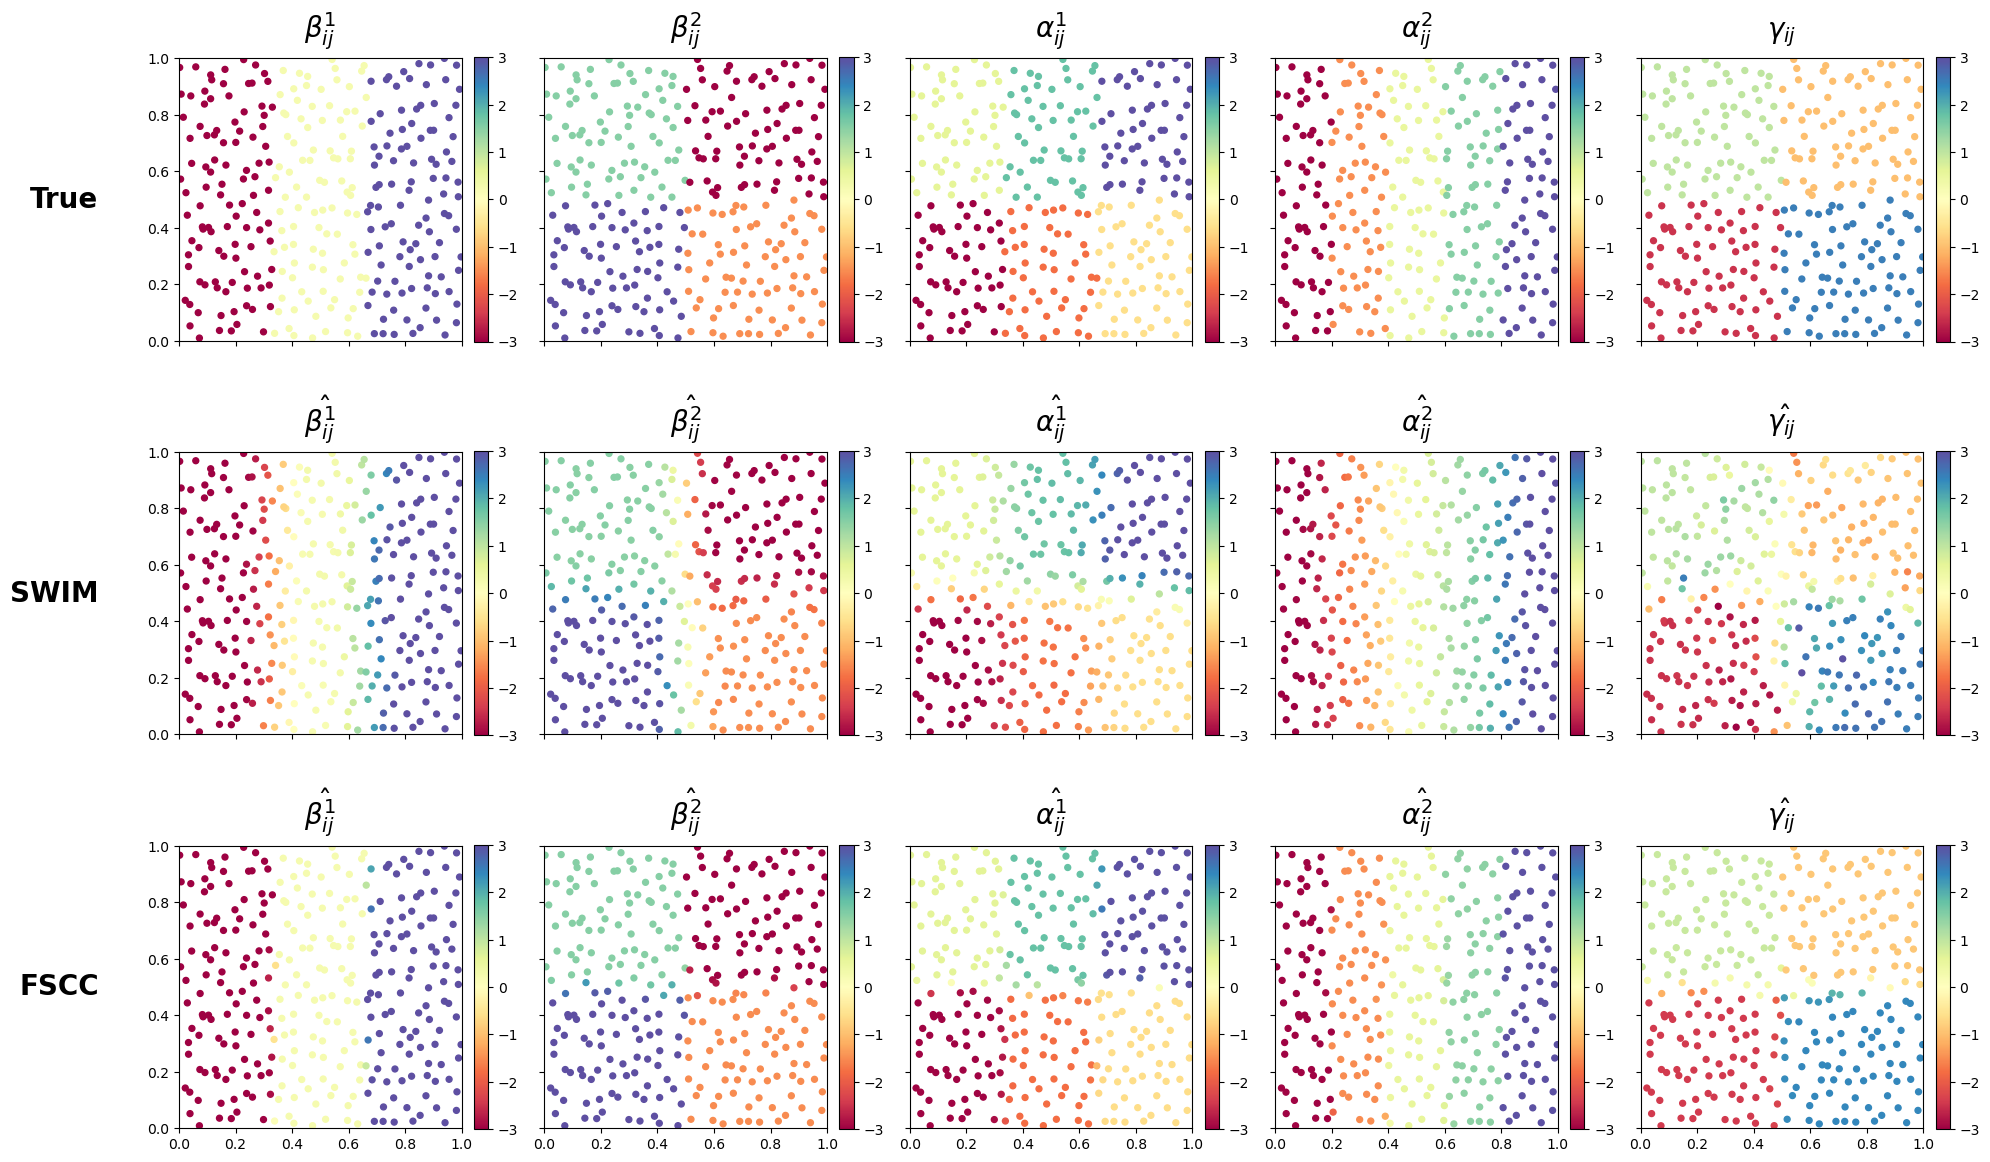


MODEL FIT: R2 AND MSE
Method        R2       MSE
   WLS -0.066437 23.111876
  SWIM  0.961509  0.834171
  FSCC  0.998640  0.029473

SPATIAL PARTITION RECOVERY: RAND INDEX
Method RI_BETA1 RI_BETA2 RI_ALPHA1 RI_ALPHA2 RI_GAMMA
   WLS 0.331371 0.247514  0.164080  0.197324 0.247514
  SWIM 0.995608 0.932709  0.935050  0.967113 0.896499
  FSCC 1.000000 0.993356  0.986912  1.000000 0.970390

COEFFICIENT ESTIMATION ERROR: RMSE
Method RMSE_BETA1 RMSE_BETA2 RMSE_ALPHA1 RMSE_ALPHA2 RMSE_GAMMA
   WLS   2.477202   2.367000    2.039979    2.130825   3.001210
  SWIM   0.506656   0.536825    0.442814    0.382635   3.028979
  FSCC   0.177951   0.153360    0.233905    0.102334   0.361328
Saved: D:\master\taskIV\FSCC_performance_300.csv D:\master\taskIV\FSCC_300_sim.png


In [4]:
# -*- coding: utf-8 -*-自适应版本
import time
import warnings
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist
from scipy.spatial import cKDTree
n, p, q = (300, 2, 2)
noise_std = 0.1
intercept_true = 1.0
GRID_NEIGHBORHOOD = 'rook'
sigma = 0.05
max_dist = 0.2
B = 1
lambda_grid = [0.075, 0.1, 0.125]
max_outer = 60
max_inner = 1000
outer_tol = 0.002
admm_abs_tol = 1e-05
admm_rel_tol = 0.0005
cg_rtol = 1e-08
cg_maxiter = 1500
admm_adapt_interval = 10
admm_balance_mu = 10.0
admm_rho_factor = 2.0
admm_rho_min = 1e-05
admm_rho_max = 100000.0
admm_over_relax = 1.5
df_rel_tol = 0.001
GAMMA_CLASS_RATIOS = (40.0, 4.0, 4.0 / 3.6)
GAMMA_BASE_SCALE = 1.0
# Adaptive fused Lasso: pilot estimates come from SWIM, never from true coefficients.
ADAPTIVE_POWER = 1.0
ADAPTIVE_EPS_FRACTION = 0.10
ADAPTIVE_WEIGHT_MIN = 0.10
ADAPTIVE_WEIGHT_MAX = 10.0
K_SWIM = 100
SWIM_BW_FIXED = 0.105

def rectangular_grid_shape(n_points):
    if n_points < 2:
        return (1, n_points)
    rows = math.isqrt(n_points)
    while rows > 1 and n_points % rows != 0:
        rows -= 1
    if rows == 1 and n_points > 4:
        cols = int(math.ceil(math.sqrt(n_points)))
        rows = int(math.ceil(n_points / cols))
    else:
        cols = n_points // rows
    return (int(rows), int(cols))
grid_n_rows, grid_n_cols = rectangular_grid_shape(n)
cell_ids = np.arange(n, dtype=np.int32)
grid_rows = (cell_ids // grid_n_cols).astype(np.int32)
grid_cols = (cell_ids % grid_n_cols).astype(np.int32)
coord_rng = np.random.default_rng(42)
coords = np.column_stack([(grid_cols + coord_rng.random(n)) / grid_n_cols, (grid_rows + coord_rng.random(n)) / grid_n_rows]).astype(np.float64)
if np.any(coords < 0.0) or np.any(coords >= 1.0):
    raise RuntimeError('Generated grid coordinates fall outside [0,1).')
D_full = cdist(coords, coords).astype(np.float64)
D_PREDICTOR_SCALE = float(np.std(D_full))
if D_PREDICTOR_SCALE <= 1e-12:
    raise ValueError('Distance predictor has zero variance.')
D_model = D_full / D_PREDICTOR_SCALE
gamma_predictor_scale = 1.0
D_gamma = D_full
beta_piece_sets = [[-3, 0.25, 3], [3, -1.5, 1.5, -3]]
alpha_piece_sets = [[-3, -1.8, -0.6, 0.6, 1.8, 3], [-3, -1.5, 0.5, 1.5, 3]]
gamma_piece_set = [-2.5, 2.5, 1.0, -1.0]

def grid_shape_for_count(count):
    return {3: (1, 3), 4: (2, 2), 5: (1, 5), 6: (2, 3)}[count]

def fill_piecewise_origin(arr3d, coords_, values, feat_idx):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr3d[mask, :, feat_idx] = value

def fill_piecewise_2d(arr2d, coords_, values):
    rows_g, cols_g = grid_shape_for_count(len(values))
    xe = np.linspace(0.0, 1.0, cols_g + 1)
    ye = np.linspace(0.0, 1.0, rows_g + 1)
    for r in range(rows_g):
        for c in range(cols_g):
            value = values[r * cols_g + c]
            x_in = (coords_[:, 0] >= xe[c]) & ((coords_[:, 0] < xe[c + 1]) | (c == cols_g - 1) & (coords_[:, 0] <= xe[c + 1]))
            y_in = (coords_[:, 1] >= ye[r]) & ((coords_[:, 1] < ye[r + 1]) | (r == rows_g - 1) & (coords_[:, 1] <= ye[r + 1]))
            mask = x_in & y_in
            arr2d[mask, :] = value
beta0 = np.zeros((n, n, p), dtype=np.float64)
alpha0 = np.zeros((n, n, q), dtype=np.float64)
gamma0 = np.zeros((n, n), dtype=np.float64)
for k in range(p):
    fill_piecewise_origin(beta0, coords, beta_piece_sets[k], k)
for m in range(q):
    fill_piecewise_origin(alpha0, coords, alpha_piece_sets[m], m)
fill_piecewise_2d(gamma0, coords, gamma_piece_set)
edge_u_list = []
edge_v_list = []
for r in range(grid_n_rows):
    for c in range(grid_n_cols):
        u = r * grid_n_cols + c
        if u >= n:
            continue
        if c + 1 < grid_n_cols and u + 1 < n:
            edge_u_list.append(u)
            edge_v_list.append(u + 1)
        if r + 1 < grid_n_rows and u + grid_n_cols < n:
            edge_u_list.append(u)
            edge_v_list.append(u + grid_n_cols)
edge_u = np.asarray(edge_u_list, dtype=np.int32)
edge_v = np.asarray(edge_v_list, dtype=np.int32)
edge_w = np.ones(len(edge_u), dtype=np.float64)
E = len(edge_u)
N = n * n
if E == 0:
    raise RuntimeError('No grid-neighbor edges were constructed.')
A_grid = sp.coo_matrix((np.ones(2 * E, dtype=np.float64), (np.concatenate([edge_u, edge_v]), np.concatenate([edge_v, edge_u]))), shape=(n, n)).tocsr()
A_grid.setdiag(0.0)
A_grid.eliminate_zeros()
if A_grid.nnz and (not np.all(A_grid.data == 1.0)):
    raise RuntimeError('Grid adjacency must be binary: every nonzero entry must equal 1.')
try:
    OUTPUT_DIR = Path(__file__).resolve().parent
except NameError:
    OUTPUT_DIR = Path.cwd()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
W_wls = np.exp(-0.5 * (D_full / sigma) ** 2)
np.fill_diagonal(W_wls, 0.0)
W_wls[D_full > max_dist] = 0.0
W_wls = W_wls / (W_wls.sum() / n + 1e-12)
fixed_origin = np.tile(np.arange(n, dtype=np.int32), E)
u1 = fixed_origin * n + np.repeat(edge_u, n)
v1 = fixed_origin * n + np.repeat(edge_v, n)
w1 = np.repeat(edge_w, n)
fixed_dest = np.tile(np.arange(n, dtype=np.int32), E)
u2 = np.repeat(edge_u, n) * n + fixed_dest
v2 = np.repeat(edge_v, n) * n + fixed_dest
w2 = np.repeat(edge_w, n)
M3 = 2 * E * E
u3 = np.empty(M3, dtype=np.int32)
v3 = np.empty(M3, dtype=np.int32)
mean_region_w = float(np.mean(edge_w))
w3_legacy = np.empty(M3, dtype=np.float64)
write = 0
for e in range(E):
    i1, i2 = (int(edge_u[e]), int(edge_v[e]))
    joint_w = edge_w[e] * edge_w / max(mean_region_w, 1e-12)
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_u
    v3[sl] = i2 * n + edge_v
    w3_legacy[sl] = joint_w
    write += E
    sl = slice(write, write + E)
    u3[sl] = i1 * n + edge_v
    v3[sl] = i2 * n + edge_u
    w3_legacy[sl] = joint_w
    write += E
assert write == M3
assert np.all(u3 != v3)
class3_balance = float(np.sum(w1) / max(np.sum(w3_legacy), 1e-12))
w3_balanced = w3_legacy * class3_balance
SCENARIOS = {'three_classes_binary_unit_weight': {'u': np.concatenate([u1, u2, u3]), 'v': np.concatenate([v1, v2, v3]), 'w': np.concatenate([w1, w2, w3_legacy]), 'include_class3': True, 'class3_scale': 1.0, 'class_edge_counts': (len(u1), len(u2), len(u3))}}
row_q = np.concatenate([edge_u, edge_v])
col_q = np.concatenate([edge_v, edge_u])
data_q = np.concatenate([edge_w ** 2, edge_w ** 2])
Q_region = sp.coo_matrix((data_q, (row_q, col_q)), shape=(n, n)).tocsr()
region_degree = np.asarray(Q_region.sum(axis=1)).ravel()
L_region = (sp.diags(region_degree, format='csr') - Q_region).tocsr()
_CLASS3_OPERATOR_CACHE = {}

def make_class3_operator(class3_scale):
    key = float(class3_scale)
    if key not in _CLASS3_OPERATOR_CACHE:
        joint_operator_scale = key / max(mean_region_w, 1e-12)
        q_joint = (joint_operator_scale * Q_region).tocsr()
        joint_degree = np.asarray(q_joint.sum(axis=1)).ravel()
        _CLASS3_OPERATOR_CACHE[key] = (q_joint, joint_degree)
    return _CLASS3_OPERATOR_CACHE[key]
Q_joint_legacy, joint_degree_legacy = make_class3_operator(1.0)
Q_joint_balanced, joint_degree_balanced = make_class3_operator(class3_balance)

from functools import lru_cache

@lru_cache(maxsize=12)
def graph_degree_vector(include_class3, class3_scale):
    deg = region_degree[:, None] + region_degree[None, :]
    if include_class3:
        _, joint_degree = make_class3_operator(class3_scale)
        deg = deg + joint_degree[:, None] * joint_degree[None, :]
    return deg.ravel()

def graph_laplacian_matvec(x_vec, include_class3, class3_scale):
    Bmat = np.asarray(x_vec, dtype=np.float64).reshape(n, n)
    lap = L_region.dot(Bmat) + L_region.dot(Bmat.T).T
    if include_class3:
        q_joint, joint_degree = make_class3_operator(class3_scale)
        QB = q_joint.dot(Bmat)
        QBQ = q_joint.dot(QB.T).T
        lap += joint_degree[:, None] * joint_degree[None, :] * Bmat - QBQ
    return lap.ravel()

def admm_fuse(v_vec, X2_vec, rho, edges_u, edges_v, edges_w, penalty_per_edge, include_class3, class3_scale, x_init=None, dual_init=None, state_init=None, maxiter=max_inner):
    if len(edges_u) == 0:
        return (np.asarray(v_vec, dtype=np.float64).copy(), {'iterations': 0, 'primal': 0.0, 'dual': 0.0, 'eps_primal': 0.0, 'eps_dual': 0.0, 'primal_ratio': 0.0, 'dual_ratio': 0.0, 'converged': True, 'cg_nonconverged': 0, 'rho_final': float(rho)})
    v64 = np.asarray(v_vec, dtype=np.float64)
    X2 = np.maximum(np.asarray(X2_vec, dtype=np.float64), 1e-12)
    ew = np.asarray(edges_w, dtype=np.float64)
    pen = np.asarray(penalty_per_edge, dtype=np.float64)
    n_edges = len(edges_u)
    rho = float(rho)
    x = np.asarray(x_init, dtype=np.float64).copy() if x_init is not None else v64.copy()
    dx0 = ew * (x[edges_u] - x[edges_v])
    z = dx0.copy()
    if state_init is not None and len(state_init.get('z', ())) == n_edges:
        z = state_init['z'].copy()
        dual_init = state_init['dual_unscaled']
        rho = float(state_init['rho_final'])
    if dual_init is None:
        dual_scaled = np.zeros(n_edges, dtype=np.float64)
    else:
        dual_scaled = np.asarray(dual_init, dtype=np.float64).copy() / max(rho, 1e-15)
    cg_nonconverged = 0
    primal_norm = dual_norm = np.inf
    eps_primal = eps_dual = np.inf
    converged = False
    alpha_relax = float(admm_over_relax)

    def make_linear_operators(rho_now):

        def matvec_A(x_vec):
            return X2 * x_vec + rho_now * graph_laplacian_matvec(x_vec, include_class3, class3_scale)
        A_op = spla.LinearOperator((N, N), matvec=matvec_A, dtype=np.float64)
        degree = graph_degree_vector(include_class3, class3_scale)
        precond_diag = np.maximum(X2 + rho_now * degree, 1e-10)
        M_op = spla.LinearOperator((N, N), matvec=lambda r: r / precond_diag, dtype=np.float64)
        return (A_op, M_op)
    A_op, M_op = make_linear_operators(rho)
    # The edge thresholds depend on rho, not on the ADMM iteration.
    threshold = pen / max(rho, 1e-15)
    rho_updates = 0
    rhs_base = X2 * v64
    for it in range(1, maxiter + 1):
        diff_zu = (z - dual_scaled) * ew
        Kt_zu = np.bincount(edges_u, weights=diff_zu, minlength=N) - np.bincount(edges_v, weights=diff_zu, minlength=N)
        rhs = rhs_base + rho * Kt_zu
        x_new, cg_info = spla.cg(A_op, rhs, x0=x, M=M_op, rtol=cg_rtol, atol=0.0, maxiter=cg_maxiter)
        if cg_info != 0:
            cg_nonconverged += 1
            if cg_info < 0:
                raise RuntimeError(f'CG breakdown (info={cg_info}).')
        Kx = ew * (x_new[edges_u] - x_new[edges_v])
        z_old = z
        Kx_hat = alpha_relax * Kx + (1.0 - alpha_relax) * z_old
        z = np.sign(Kx_hat + dual_scaled) * np.maximum(np.abs(Kx_hat + dual_scaled) - threshold, 0.0)
        dual_scaled += Kx_hat - z
        primal_vec = Kx - z
        primal_norm = float(np.linalg.norm(primal_vec))
        z_change = z - z_old
        Kt_dz = np.bincount(edges_u, weights=ew * z_change, minlength=N) - np.bincount(edges_v, weights=ew * z_change, minlength=N)
        dual_vec = rho * Kt_dz
        dual_norm = float(np.linalg.norm(dual_vec))
        eps_primal = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx), np.linalg.norm(z)))
        Kt_u = np.bincount(edges_u, weights=ew * dual_scaled, minlength=N) - np.bincount(edges_v, weights=ew * dual_scaled, minlength=N)
        eps_dual = float(np.sqrt(N) * admm_abs_tol + admm_rel_tol * rho * np.linalg.norm(Kt_u))
        x = x_new
        if primal_norm <= eps_primal and dual_norm <= eps_dual:
            converged = True
            break
        if it % admm_adapt_interval == 0:
            primal_ratio_now = primal_norm / max(eps_primal, 1e-12)
            dual_ratio_now = dual_norm / max(eps_dual, 1e-12)
            rho_new = rho
            if primal_ratio_now > admm_balance_mu * dual_ratio_now:
                rho_new = min(rho * admm_rho_factor, admm_rho_max)
            elif dual_ratio_now > admm_balance_mu * primal_ratio_now:
                rho_new = max(rho / admm_rho_factor, admm_rho_min)
            if not np.isclose(rho_new, rho):
                dual_scaled *= rho / rho_new
                rho = rho_new
                A_op, M_op = make_linear_operators(rho)
                threshold = pen / max(rho, 1e-15)
                rho_updates += 1
    Kx_final = ew * (x[edges_u] - x[edges_v])
    final_primal_norm = float(np.linalg.norm(Kx_final - z))
    final_primal_eps = float(np.sqrt(n_edges) * admm_abs_tol + admm_rel_tol * max(np.linalg.norm(Kx_final), np.linalg.norm(z)))
    final_primal_ratio = final_primal_norm / max(final_primal_eps, 1e-12)
    final_dual_ratio = dual_norm / max(eps_dual, 1e-12)
    converged = bool(converged and final_primal_ratio <= 1.0 and (final_dual_ratio <= 1.0))
    info = {'iterations': it, 'primal': final_primal_norm, 'dual': dual_norm, 'eps_primal': final_primal_eps, 'eps_dual': eps_dual, 'primal_ratio': final_primal_ratio, 'dual_ratio': final_dual_ratio, 'converged': converged, 'cg_nonconverged': cg_nonconverged, 'rho_final': rho, 'rho_updates': rho_updates, 'dual_unscaled': rho * dual_scaled, 'z': z.copy()}
    return (x.astype(np.float64), info)

def weighted_ls_baseline(X, Z, D, Y, W_flow):
    X_flat = X.reshape(N, p)
    Z_flat = Z.reshape(N, q)
    D_flat = D.ravel()
    Y_flat = Y.ravel()
    design = np.column_stack([X_flat, Z_flat, D_flat[:, None], np.ones((N, 1))])
    w_flat = W_flow.ravel()
    sw = np.sqrt(w_flat + 1e-12)
    Xw = design * sw[:, None]
    yw = Y_flat * sw
    ridge = 1e-06 * np.eye(p + q + 2)
    ridge[-1, -1] = 0.0
    coef = np.linalg.solve(Xw.T @ Xw + ridge, Xw.T @ yw)
    prediction = design @ coef
    raw_rss = float(np.sum((Y_flat - prediction) ** 2))
    weighted_rss = float(np.sum(w_flat * (Y_flat - prediction) ** 2))
    return (coef, prediction, raw_rss, weighted_rss)

def swim_fit_fixed_bw(bw, design, y_flat, idx, dist, ridge=1e-08, batch_size=1024):
    n_targets = len(y_flat)
    n_features = design.shape[1]
    coefs = np.empty((n_targets, n_features), dtype=np.float64)
    eye = ridge * np.eye(n_features, dtype=np.float64)
    bw = max(float(bw), 1e-12)
    for start in range(0, n_targets, batch_size):
        stop = min(start + batch_size, n_targets)
        idx_b = idx[start:stop]
        dist_b = dist[start:stop]
        weights = np.exp(-0.5 * (dist_b / bw) ** 2)
        sw = np.sqrt(weights)
        Xg = design[idx_b] * sw[:, :, None]
        yg = y_flat[idx_b] * sw
        XtX = np.einsum('tki,tkj->tij', Xg, Xg)
        XtX += eye[None, :, :]
        XtY = np.einsum('tki,tk->ti', Xg, yg)
        coefs[start:stop] = np.linalg.solve(XtX, XtY[..., None])[..., 0]
    pred = np.einsum('ij,ij->i', design, coefs)
    rss = float(np.sum((y_flat - pred) ** 2))
    return (coefs, pred, rss)

def adaptive_edge_weights(pilot_surface, edges_u, edges_v):
    """Data-driven edge weights based on an independent pilot coefficient surface.

    The weights are frozen across all lambda candidates, normalized to median 1,
    and bounded to prevent instability when pilot differences approach zero.
    """
    pilot = np.asarray(pilot_surface, dtype=np.float64).ravel()
    differences = np.abs(pilot[edges_u] - pilot[edges_v])
    positive = differences[differences > 1e-12]
    if positive.size == 0:
        warnings.warn("Pilot coefficients are constant on all edges; using unit weights.")
        return np.ones(len(edges_u), dtype=np.float64)
    scale = float(np.median(positive))
    eps = max(ADAPTIVE_EPS_FRACTION * scale, 1e-10)
    weights = np.power(differences + eps, -ADAPTIVE_POWER)
    weights /= max(float(np.median(weights)), 1e-12)
    return np.clip(weights, ADAPTIVE_WEIGHT_MIN, ADAPTIVE_WEIGHT_MAX)


def build_adaptive_penalties(scenario, pilot_beta, pilot_alpha, pilot_gamma):
    """Build once per replication/scenario, before searching lambda."""
    eu, ev = scenario['u'], scenario['v']
    n1, n2, n3 = scenario['class_edge_counts']
    g1, g2, g3 = GAMMA_CLASS_RATIOS
    gamma_class_scale = np.concatenate([
        np.full(n1, GAMMA_BASE_SCALE * g1),
        np.full(n2, GAMMA_BASE_SCALE * g2),
        np.full(n3, GAMMA_BASE_SCALE * g3)
    ])
    return {
        'beta': [adaptive_edge_weights(pilot_beta[:, :, k], eu, ev) for k in range(p)],
        'alpha': [adaptive_edge_weights(pilot_alpha[:, :, m], eu, ev) for m in range(q)],
        'gamma': adaptive_edge_weights(pilot_gamma, eu, ev) * gamma_class_scale
    }


def fscc_fit(lam, beta_init, alpha_init, gamma_init, intercept_init, rho_beta, rho_alpha, rho_gamma, X, Z, D, Y, TSS, scenario, adaptive_penalties):
    beta = beta_init.copy()
    alpha = alpha_init.copy()
    gamma = gamma_init.copy()
    intercept = float(intercept_init)
    eu = scenario['u']
    ev = scenario['v']
    ew = scenario['w']
    include_class3 = scenario['include_class3']
    class3_scale = scenario['class3_scale']
    pen_beta = [lam * w for w in adaptive_penalties['beta']]
    pen_alpha = [lam * w for w in adaptive_penalties['alpha']]
    pen_g = lam * adaptive_penalties['gamma']
    max_primal_ratio = 0.0
    max_dual_ratio = 0.0
    max_admm_iterations = 0
    total_admm_not_converged = 0
    total_cg_nonconverged = 0
    max_rho_updates = 0
    min_rho_final = np.inf
    max_rho_final = 0.0
    outer_iterations = 0
    outer_converged = False
    final_outer_change = np.inf
    dual_states = {}
    X2_cache = [X[:, :, k].ravel() ** 2 for k in range(p)]
    Z2_cache = [Z[:, :, m].ravel() ** 2 for m in range(q)]
    D2_cache = (D * D + 1e-12).ravel()
    residual = Y - intercept - np.sum(X * beta, axis=2) - np.sum(Z * alpha, axis=2) - D * gamma
    fit_start = time.perf_counter()
    for outer in range(1, max_outer + 1):
        beta_prev = beta.copy()
        alpha_prev = alpha.copy()
        gamma_prev = gamma.copy()
        intercept_prev = intercept
        for k in range(p):
            Xk = X[:, :, k]
            xk = Xk.ravel()
            x2 = X2_cache[k]
            v = beta[:, :, k].ravel() + xk * residual.ravel() / (x2 + 1e-12)
            new_flat, diag = admm_fuse(v, x2, rho_beta, eu, ev, ew, pen_beta[k], include_class3, class3_scale, x_init=beta[:, :, k].ravel(), state_init=dual_states.get(('beta', k)))
            dual_states['beta', k] = diag
            beta_new = new_flat.reshape(n, n)
            residual -= Xk * (beta_new - beta[:, :, k])
            beta[:, :, k] = beta_new
            max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
            max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
            max_admm_iterations = max(max_admm_iterations, diag['iterations'])
            total_admm_not_converged += int(not diag['converged'])
            total_cg_nonconverged += diag['cg_nonconverged']
            max_rho_updates = max(max_rho_updates, diag['rho_updates'])
            min_rho_final = min(min_rho_final, diag['rho_final'])
            max_rho_final = max(max_rho_final, diag['rho_final'])
        for m in range(q):
            Zm = Z[:, :, m]
            zm = Zm.ravel()
            z2 = Z2_cache[m]
            v = alpha[:, :, m].ravel() + zm * residual.ravel() / (z2 + 1e-12)
            new_flat, diag = admm_fuse(v, z2, rho_alpha, eu, ev, ew, pen_alpha[m], include_class3, class3_scale, x_init=alpha[:, :, m].ravel(), state_init=dual_states.get(('alpha', m)))
            dual_states['alpha', m] = diag
            alpha_new = new_flat.reshape(n, n)
            residual -= Zm * (alpha_new - alpha[:, :, m])
            alpha[:, :, m] = alpha_new
            max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
            max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
            max_admm_iterations = max(max_admm_iterations, diag['iterations'])
            total_admm_not_converged += int(not diag['converged'])
            total_cg_nonconverged += diag['cg_nonconverged']
            max_rho_updates = max(max_rho_updates, diag['rho_updates'])
            min_rho_final = min(min_rho_final, diag['rho_final'])
            max_rho_final = max(max_rho_final, diag['rho_final'])
        D2 = D2_cache.reshape(n, n)
        v_gamma = (gamma + D * residual / D2).ravel()
        new_gamma_flat, diag = admm_fuse(v_gamma, D2.ravel(), rho_gamma, eu, ev, ew, pen_g, include_class3, class3_scale, x_init=gamma.ravel(), state_init=dual_states.get(('gamma', 0)))
        dual_states['gamma', 0] = diag
        gamma_new = new_gamma_flat.reshape(n, n)
        residual -= D * (gamma_new - gamma)
        gamma = gamma_new
        max_primal_ratio = max(max_primal_ratio, diag['primal_ratio'])
        max_dual_ratio = max(max_dual_ratio, diag['dual_ratio'])
        max_admm_iterations = max(max_admm_iterations, diag['iterations'])
        total_admm_not_converged += int(not diag['converged'])
        total_cg_nonconverged += diag['cg_nonconverged']
        max_rho_updates = max(max_rho_updates, diag['rho_updates'])
        min_rho_final = min(min_rho_final, diag['rho_final'])
        max_rho_final = max(max_rho_final, diag['rho_final'])
        intercept_change = float(np.mean(residual))
        intercept += intercept_change
        residual -= intercept_change
        db = np.linalg.norm(beta - beta_prev) / (np.linalg.norm(beta_prev) + 1e-12)
        da = np.linalg.norm(alpha - alpha_prev) / (np.linalg.norm(alpha_prev) + 1e-12)
        dg = np.linalg.norm(gamma - gamma_prev) / (np.linalg.norm(gamma_prev) + 1e-12)
        di = abs(intercept - intercept_prev) / (abs(intercept_prev) + 1e-12)
        outer_iterations = outer
        final_outer_change = float(max(db, da, dg, di))
        if outer == 1 or outer % 5 == 0 or final_outer_change < outer_tol:
            print(f'  outer={outer}/{max_outer} change={final_outer_change:.3g} '
                  f'ADMMmax={max_admm_iterations} elapsed={time.perf_counter()-fit_start:.1f}s', flush=True)
        if final_outer_change < outer_tol:
            outer_converged = True
            break
    prediction = np.full((n, n), intercept, dtype=np.float64)
    for k in range(p):
        prediction += X[:, :, k] * beta[:, :, k]
    for m in range(q):
        prediction += Z[:, :, m] * alpha[:, :, m]
    prediction += D * gamma
    residual = Y - prediction
    rss = float(np.sum(residual ** 2))
    r2 = float(1.0 - rss / max(TSS, 1e-12))
    diag_all = {'outer_iterations': outer_iterations, 'outer_converged': outer_converged, 'final_outer_change': final_outer_change, 'max_admm_iterations': max_admm_iterations, 'max_primal_ratio': max_primal_ratio, 'max_dual_ratio': max_dual_ratio, 'admm_subproblems_not_converged': total_admm_not_converged, 'cg_nonconverged_total': total_cg_nonconverged, 'max_rho_updates_per_subproblem': max_rho_updates, 'min_rho_final': 0.0 if not np.isfinite(min_rho_final) else min_rho_final, 'max_rho_final': max_rho_final}
    return (beta, alpha, gamma, intercept, prediction, rss, r2, diag_all)

def fused_component_count(values, eu, ev, tol):
    vals = np.asarray(values, dtype=np.float64).ravel()
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    if not np.any(fused):
        return len(vals)
    rows = np.concatenate([eu[fused], ev[fused]])
    cols = np.concatenate([ev[fused], eu[fused]])
    data = np.ones(len(rows), dtype=np.int8)
    graph = sp.coo_matrix((data, (rows, cols)), shape=(len(vals), len(vals))).tocsr()
    n_comp = connected_components(graph, directed=False, return_labels=False)
    return int(n_comp)

def fused_component_labels(values, eu, ev, tol):
    vals = np.asarray(values, dtype=np.float64).ravel()
    fused = np.abs(vals[eu] - vals[ev]) <= tol
    if not np.any(fused):
        return (len(vals), np.arange(len(vals), dtype=np.int32))
    rows = np.concatenate([eu[fused], ev[fused]])
    cols = np.concatenate([ev[fused], eu[fused]])
    data = np.ones(len(rows), dtype=np.int8)
    graph = sp.coo_matrix((data, (rows, cols)), shape=(len(vals), len(vals))).tocsr()
    n_comp, labels = connected_components(graph, directed=False, return_labels=True)
    return (int(n_comp), labels.astype(np.int32))

def compute_effective_df(beta, alpha, gamma, intercept, eu, ev):
    dfs = {}
    for k in range(p):
        tol = max(1e-05, df_rel_tol * float(np.std(beta[:, :, k])))
        dfs[f'df_beta{k + 1}'] = fused_component_count(beta[:, :, k], eu, ev, tol)
    for m in range(q):
        tol = max(1e-05, df_rel_tol * float(np.std(alpha[:, :, m])))
        dfs[f'df_alpha{m + 1}'] = fused_component_count(alpha[:, :, m], eu, ev, tol)
    tol_g = max(1e-05, df_rel_tol * float(np.std(gamma)))
    dfs['df_gamma'] = fused_component_count(gamma, eu, ev, tol_g)
    dfs['df_intercept'] = 1
    dfs['df_total'] = int(sum(dfs.values()))
    return dfs

def rand_index(labels_true, labels_pred):
    labels_true = np.asarray(labels_true)
    labels_pred = np.asarray(labels_pred)
    n_pts = len(labels_true)
    iu = np.triu_indices(n_pts, k=1)
    same_true = labels_true[:, None] == labels_true[None, :]
    same_pred = labels_pred[:, None] == labels_pred[None, :]
    return float(np.mean(same_true[iu] == same_pred[iu]))

def get_true_labels(coords_, values_list):
    rows, cols = grid_shape_for_count(len(values_list))
    xe = np.linspace(0.0, 1.0, cols + 1)
    ye = np.linspace(0.0, 1.0, rows + 1)
    x_idx = np.clip(np.digitize(coords_[:, 0], xe, right=False) - 1, 0, cols - 1)
    y_idx = np.clip(np.digitize(coords_[:, 1], ye, right=False) - 1, 0, rows - 1)
    return y_idx * cols + x_idx

def cluster_rand(values, labels_true, k, seed=123):
    try:
        from sklearn.cluster import KMeans
        pred = KMeans(n_clusters=k, n_init=20, random_state=seed).fit_predict(np.asarray(values).reshape(-1, 1))
        return rand_index(labels_true, pred)
    except Exception as exc:
        warnings.warn(f'Skipping k-means Rand index ({exc}).')
        return np.nan

def coefficient_metrics(beta, alpha, gamma):
    surfaces = {'beta1': (beta[:, :, 0], beta_piece_sets[0]), 'beta2': (beta[:, :, 1], beta_piece_sets[1]), 'alpha1': (alpha[:, :, 0], alpha_piece_sets[0]), 'alpha2': (alpha[:, :, 1], alpha_piece_sets[1]), 'gamma': (gamma, gamma_piece_set)}
    out = {}
    for name, (estimate, groups) in surfaces.items():
        true_surface = beta0[:, :, 0] if name == 'beta1' else beta0[:, :, 1] if name == 'beta2' else alpha0[:, :, 0] if name == 'alpha1' else alpha0[:, :, 1] if name == 'alpha2' else gamma0
        out[f'rmse_{name}'] = float(np.sqrt(np.mean((estimate - true_surface) ** 2)))
        if name == 'gamma':
            out['gamma_origin_average_rmse'] = float(np.sqrt(np.mean((estimate.mean(axis=1) - true_surface.mean(axis=1)) ** 2)))
            out['gamma_within_origin_sd'] = float(np.mean(np.std(estimate, axis=1)))
        labels_true = get_true_labels(coords, groups)
        origin_values = np.asarray(estimate).mean(axis=1)
        out[f'ri_{name}'] = cluster_rand(origin_values, labels_true, len(groups), seed=123)
    return out
flow_i, flow_j = np.meshgrid(np.arange(n), np.arange(n), indexing='ij')
flow_features = np.column_stack([coords[flow_i.ravel()], coords[flow_j.ravel()]])
swim_tree = cKDTree(flow_features)
dist_swim, idx_swim = swim_tree.query(flow_features, k=min(K_SWIM, N), workers=-1)
method_metric_rows = []
for rep in range(B):
    seed = 1000 + rep
    np.random.seed(seed)
    X = np.random.randn(n, n, p)
    Z = np.random.randn(n, n, q)
    Y = np.full((n, n), intercept_true, dtype=np.float64)
    for k in range(p):
        Y += X[:, :, k] * beta0[:, :, k]
    for m in range(q):
        Y += Z[:, :, m] * alpha0[:, :, m]
    Y += D_full * gamma0 + noise_std * np.random.randn(n, n)
    Y_mean = float(np.mean(Y))
    TSS = float(np.sum((Y - Y_mean) ** 2))
    wls_coef, wls_pred, wls_raw_rss, wls_weighted_rss = weighted_ls_baseline(X, Z, D_model, Y, W_wls)
    wls_beta = np.tile(wls_coef[:p], (n, n, 1))
    wls_alpha = np.tile(wls_coef[p:p + q], (n, n, 1))
    wls_gamma_std = np.full((n, n), wls_coef[p + q], dtype=np.float64)
    wls_gamma = wls_gamma_std.copy()
    wls_intercept = float(wls_coef[p + q + 1])
    print(f'Replication {rep + 1}/{B}; seed={seed}')
    wls_mse = wls_raw_rss / N
    wls_r2 = 1.0 - wls_raw_rss / max(TSS, 1e-12)
    design = np.column_stack([X.reshape(N, p), Z.reshape(N, q), D_model.ravel(), np.ones(N)])
    swim_coef_map, swim_pred, swim_rss = swim_fit_fixed_bw(SWIM_BW_FIXED, design, Y.ravel(), idx_swim, dist_swim)
    swim_map = swim_coef_map.reshape(n, n, p + q + 2)
    swim_beta = swim_map[:, :, :p]
    swim_alpha = swim_map[:, :, p:p + q]
    swim_gamma = swim_map[:, :, p + q]
    wls_gamma_raw = wls_gamma / D_PREDICTOR_SCALE
    swim_gamma_raw = swim_gamma / D_PREDICTOR_SCALE
    wls_metrics = coefficient_metrics(wls_beta, wls_alpha, wls_gamma_raw)
    swim_metrics = coefficient_metrics(swim_beta, swim_alpha, swim_gamma_raw)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'WLS', 'mse': wls_mse, 'r2': wls_r2, 'intercept_estimate': wls_intercept, **wls_metrics})
    swim_mse = swim_rss / N
    swim_r2 = 1.0 - swim_rss / max(TSS, 1e-12)
    method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'SWIM', 'mse': swim_mse, 'r2': swim_r2, 'intercept_estimate': float(np.mean(swim_map[:, :, p + q + 1])), **swim_metrics})
    rho_beta = 1.0
    rho_alpha = 1.0
    rho_gamma = 1.0
    for scenario_name, scenario in SCENARIOS.items():
        scenario_results = []
        eu = scenario['u']
        ev = scenario['v']
        edge_count_scenario = len(eu)
        # SWIM pilot is estimated from the observed sample; do not use beta0/alpha0/gamma0.
        # gamma uses the D_model coefficient scale, matching the fitted FSCC parameter.
        adaptive_penalties = build_adaptive_penalties(
            scenario, swim_beta, swim_alpha, swim_gamma
        )
        print(f'Adaptive fused Lasso: power={ADAPTIVE_POWER}, '
              f'epsilon_fraction={ADAPTIVE_EPS_FRACTION}, '
              f'weight_range=[{ADAPTIVE_WEIGHT_MIN}, {ADAPTIVE_WEIGHT_MAX}]')
        # Ascending lambda path; coefficient-only warm start, duals reset per lambda.
        warm_beta, warm_alpha, warm_gamma = wls_beta, wls_alpha, wls_gamma
        warm_intercept = wls_intercept
        for lam in sorted(lambda_grid):
            t0 = time.time()
            print(f'  Starting lambda={lam:g}', flush=True)
            fit = fscc_fit(lam, warm_beta, warm_alpha, warm_gamma, warm_intercept, rho_beta, rho_alpha, rho_gamma, X, Z, D_model, Y, TSS, scenario, adaptive_penalties)
            beta_hat, alpha_hat, gamma_hat, intercept_hat, pred_hat, rss, r2, admm_diag = fit
            df_info = compute_effective_df(beta_hat, alpha_hat, gamma_hat, intercept_hat, eu, ev)
            df = df_info['df_total']
            aic = N * np.log(rss / N + 1e-12) + 2.0 * df
            bic = N * np.log(rss / N + 1e-12) + np.log(N) * df
            gamma_hat_raw = gamma_hat / D_PREDICTOR_SCALE
            # Metrics are calculated only for the selected lambda below.
            elapsed_seconds = time.time() - t0
            print(f'  lambda={lam:g} finished in {elapsed_seconds:.1f}s; outer={admm_diag["outer_iterations"]}; converged={admm_diag["outer_converged"]}', flush=True)
            fully_converged = (admm_diag['admm_subproblems_not_converged'] == 0
                               and admm_diag['cg_nonconverged_total'] == 0
                               and admm_diag['outer_converged'])
            print(f'    ADMM failures={admm_diag["admm_subproblems_not_converged"]}, '
                  f'CG failures={admm_diag["cg_nonconverged_total"]}, '
                  f'outer change={admm_diag["final_outer_change"]:.3g}', flush=True)
            if fully_converged:
                scenario_results.append((bic, lam, fit, df_info, None, admm_diag))
                warm_beta, warm_alpha, warm_gamma = beta_hat, alpha_hat, gamma_hat
                warm_intercept = intercept_hat
            else:
                # Do not propagate an unconverged candidate into the next fit.
                warm_beta, warm_alpha, warm_gamma = wls_beta, wls_alpha, wls_gamma
                warm_intercept = wls_intercept
        if not scenario_results:
            raise RuntimeError(f'No fully converged lambda candidate for scenario {scenario_name}. Do not select BIC from unconverged fits. Increase iteration limits or inspect the primal/dual, CG, and outer-change diagnostics.')
        best = min(scenario_results, key=lambda item: item[0])
        best_bic, best_lam, best_fit, best_df, best_metrics, best_admm = best
        b, a, g, intercept, pred, rss, r2, _ = best_fit
        g_raw = g / D_PREDICTOR_SCALE
        fscc_metrics = coefficient_metrics(b, a, g_raw)
        method_metric_rows.append({'rep': rep + 1, 'seed': seed, 'method': 'FSCC', 'mse': rss / N, 'r2': r2, 'intercept_estimate': intercept, 'selected_lambda': best_lam, 'bic': best_bic, **fscc_metrics})
        if rep == B - 1:
            last_swim_beta = swim_beta.copy()
            last_swim_alpha = swim_alpha.copy()
            last_swim_gamma = swim_gamma_raw.copy()
            last_fscc_beta = b.copy()
            last_fscc_alpha = a.copy()
            last_fscc_gamma = g_raw.copy()
        gamma_tol = max(1e-05, df_rel_tol * float(np.std(g)))
        gamma_n_groups, _ = fused_component_labels(g, eu, ev, gamma_tol)
method_metrics_df = pd.DataFrame(method_metric_rows)
metric_names = ['mse', 'r2', 'ri_beta1', 'ri_beta2', 'ri_alpha1', 'ri_alpha2', 'ri_gamma', 'rmse_beta1', 'rmse_beta2', 'rmse_alpha1', 'rmse_alpha2', 'rmse_gamma', 'intercept_estimate']
summary_records = []
for method_name in ['WLS', 'SWIM', 'FSCC']:
    sub = method_metrics_df[method_metrics_df['method'] == method_name]
    rec = {'method': method_name, 'n_replications': int(len(sub))}
    for metric_name in metric_names:
        vals = pd.to_numeric(sub[metric_name], errors='coerce').dropna()
        rec[f'{metric_name}_mean'] = float(vals.mean()) if len(vals) else np.nan
        rec[f'{metric_name}_sd'] = float(vals.std(ddof=1)) if len(vals) > 1 else np.nan
    summary_records.append(rec)
method_summary_df = pd.DataFrame(summary_records)
summary_path = OUTPUT_DIR / 'FSCC_performance_300.csv'
method_summary_df.to_csv(summary_path, index=False, encoding='utf-8-sig')
true_vals = [beta0[:, :, k].mean(axis=1) for k in range(p)] + [alpha0[:, :, m].mean(axis=1) for m in range(q)] + [gamma0.mean(axis=1)]
swim_vals = [last_swim_beta[:, :, k].mean(axis=1) for k in range(p)] + [last_swim_alpha[:, :, m].mean(axis=1) for m in range(q)] + [last_swim_gamma.mean(axis=1)]
fscc_vals = [last_fscc_beta[:, :, k].mean(axis=1) for k in range(p)] + [last_fscc_alpha[:, :, m].mean(axis=1) for m in range(q)] + [last_fscc_gamma.mean(axis=1)]
col_titles = ['$\\beta_{ij}^1$', '$\\beta_{ij}^2$', '$\\alpha_{ij}^1$', '$\\alpha_{ij}^2$', '$\\gamma_{ij}$']
est_titles = ['$\\hat{\\beta_{ij}^1}$', '$\\hat{\\beta_{ij}^2}$', '$\\hat{\\alpha_{ij}^1}$', '$\\hat{\\alpha_{ij}^2}$', '$\\hat{\\gamma_{ij}}$']
row_labels = ['True', 'SWIM', 'FSCC']
vals_list = [true_vals, swim_vals, fscc_vals]
ncols = p + q + 1
fig, axes = plt.subplots(3, ncols, figsize=(4 * ncols, 12), sharex=True, sharey=True)
vmin, vmax = (-3, 3)
for ci, title in enumerate(col_titles):
    for ri, vals in enumerate(vals_list):
        ax = axes[ri, ci]
        sc = ax.scatter(coords[:, 0], coords[:, 1], c=vals[ci], s=18, cmap='Spectral', vmin=vmin, vmax=vmax)
        ax.set_title(title if ri == 0 else est_titles[ci], fontsize=20, pad=15)
        if ri == 0:
            ax.set_title(title, fontsize=20, pad=15)
        if ci == 0:
            ax.set_ylabel(row_labels[ri], fontsize=20, rotation=0, labelpad=35, fontweight='bold', va='center', ha='right')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
final_plot_path = OUTPUT_DIR / 'FSCC_300_sim.png'
plt.savefig(final_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

def print_metric_section(title, metrics):
    print('\n' + '=' * 76)
    print(title)
    print('=' * 76)
    rows = []
    for _, rec in method_summary_df.iterrows():
        row = {'Method': rec['method']}
        for metric in metrics:
            mean_val = rec[f'{metric}_mean']
            sd_val = rec[f'{metric}_sd']
            row[metric.upper()] = f'{mean_val:.6f} ± {sd_val:.6f}' if pd.notna(sd_val) else f'{mean_val:.6f}'
        rows.append(row)
    print(pd.DataFrame(rows).to_string(index=False))
r2_mse_metrics = ['r2', 'mse']
rand_metrics = ['ri_beta1', 'ri_beta2', 'ri_alpha1', 'ri_alpha2', 'ri_gamma']
rmse_metrics = ['rmse_beta1', 'rmse_beta2', 'rmse_alpha1', 'rmse_alpha2', 'rmse_gamma']
print_metric_section('MODEL FIT: R2 AND MSE', r2_mse_metrics)
print_metric_section('SPATIAL PARTITION RECOVERY: RAND INDEX', rand_metrics)
print_metric_section('COEFFICIENT ESTIMATION ERROR: RMSE', rmse_metrics)
print('Saved:', summary_path, final_plot_path)